Parameters

In [3]:
import os
import json
from pathlib import Path

parameters_filename = 'balanced_config_10.json'
PROJECT_ROOT = Path("/home/krosen5/Court Case Sequence Transformer Model/court_case_transformer_project")
parameters_path = PROJECT_ROOT / "parameters_jsons" / parameters_filename
with open(parameters_path, "r", encoding="utf-8") as file:
    parameters_dict = json.load(file)

In [4]:
try:
    cuda_index = 0
    if cuda_index is None:
        raise NameError
except NameError:
    cuda_index = 0

# Imports

In [5]:
from collections import Counter
from collections import defaultdict
from datetime import datetime
from concurrent.futures import ThreadPoolExecutor, as_completed
from openpyxl.utils.dataframe import dataframe_to_rows
from operator import sub
from sklearn.preprocessing import LabelEncoder
from pathlib import Path
import types
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import contextlib
import torch
import torch.nn as nn
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import classification_report, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from tqdm.notebook import tqdm
from transformers import AutoModel, AutoTokenizer
import gc
import h5py  # For efficient storage of large arrays
import hashlib
import json
import matplotlib.pyplot as plt
import numpy as np
import time
from multiprocessing import Pool, cpu_count
from tqdm import tqdm
import openpyxl
import os
import pandas as pd
import pickle
import random
import re
import seaborn as sns
import string
import torch
import torch.nn as nn
import torch.nn.functional as F
import time
import shutil
import xlsxwriter
from scipy.sparse import csr_matrix
from captum.attr import IntegratedGradients, LayerConductance, LayerActivation
from captum.attr import visualization as viz

In [6]:
# Set device globally
device = torch.device(f"cuda:{cuda_index}" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

if device.type == "cuda":
    print(f"CUDA device #: {cuda_index}")
    print(f"GPU: {torch.cuda.get_device_name(cuda_index)}")
    print(f"CUDA Version: {torch.version.cuda}")

    torch.backends.cuda.enable_flash_sdp(True)
    torch.backends.cuda.enable_mem_efficient_sdp(True)
    torch.backends.cuda.enable_math_sdp(False)


Using device: cuda:0
CUDA device #: 0
GPU: NVIDIA RTX A5000
CUDA Version: 12.8


In [7]:
def set_global_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

In [8]:
set_global_seed(parameters_dict['random_seed'])

In [9]:
from config import get_model_config, COMPLETION_LABELS
from data.load_data import mount_drive, load_data
from data.process_data import append_prefix_to_proceeding_ids, filter_proceedings, remove_multi_defendant_cases, create_combined_dockets, filter_to_magistrate_started_cases, remove_extradition_cases
from data.sequence_builder import create_enhanced_training_sequences_cached, SequenceCacheBuilder
from regex_labels.label_generator_and_cache_manager import generate_and_cache_regex_labels
from models.transformer_creation import create_model_from_data
from training.trainer import train_case_transformer_with_mlb
from training.label_processor import EnhancedLabelProcessor
from training.evaluation import evaluate_with_teacher_forcing
from analysis.cooccurrence import export_cooccurrence_from_valid_completed_cases, create_cooccurrence_matrix_excel
from analysis.frequency_analysis import print_label_distribution_by_court
from analysis.diagnostic import comprehensive_training_diagnostic
from models.baseline_model import run_baseline, convert_baseline_results_to_table_format
from utils.cache_directory_utils import CacheDirectoryManager
from utils.model_memory_utils import analyze_model_memory, debug_oom_sample
from models.embeddings import extract_and_cache_bert_embeddings_streaming
from analysis.byclerk import analyze_clerk_data
from models.interpretability import CaseTransformerInterpretability, CaptumWrapper
from models.most_confident_wrong_answer_analyzer import run_confident_misclassification_analysis
from data.k_fold_methods import KFoldCVRunner
from data.dataset_creation import sample_from_the_longest_cases, export_long_cases_to_xlsx, sample_uniformly, export_uniform_cases_to_xlsx
from analysis.tablegenerator import TableGenerator
from data.balanced_dataset_creation import create_balanced_dataset, export_balanced_cases_to_xlsx
from models.export_model import export_model_complete
from utils.case_identifier_utils import extract_case_identifier_from_sequences, save_case_identifiers, load_case_identifiers, compare_case_identifiers, load_and_compare_case_identifiers
from models.baseline_model_2 import run_random_baseline_comparison, convert_random_baseline_results_to_table_format
from analysis.compare_transformer_to_baseline_1 import compare_transformer_vs_baseline1_on_completion_labels, convert_baseline1_comparison_to_table_generator_format
# ═══════════════════════════════════════════════════════════════
# Embedding Clustering Analysis (PCA + KMeans on pre-classifier vectors)
# ═══════════════════════════════════════════════════════════════

from analysis.pca_vectors import (run_embedding_clusters_pipeline, run_embedding_clusters_kfolds_pipeline)


In [10]:
%load_ext autoreload
%autoreload 2
from notebook_helpers import (
    # Data filtering helpers
    filter_to_completed_cases,
    build_case_counts_df,
    filter_zero_label_proceedings,
    generate_cooccurrence_matrix_excel,
    filter_proceedings_to_end_of_case,
    apply_skipped_duplicates_on_imported_sequences,
    
    # Data transformation helpers
    transform_labels_to_binary,
    convert_data_to_format,
    
    # Sequence processing helpers
    filter_sequences_with_meaningful_labels,
    split_train_validation,
    prepare_sequences_and_labels,
    
    # Case info extraction
    extract_case_info_from_sequence,
    
    # Prediction helpers
    predict_case_labels,
    predict_step,
    
    # Metrics calculation helpers
    calculate_metrics,
    calculate_case_metrics,
    collect_labels_from_binary,
    count_processed_steps,
    
    # Analysis helpers
    perform_frequency_analysis,
    debug_model_sample,
    
    # Training helpers
    train_model,
    
    # Evaluation helpers
    prepare_validation_data_for_eval,
    evaluate_model,
    print_micro_averaged_metrics,
    print_top_performing_labels,
    
    # Case-level evaluation helpers
    evaluate_case_level,
    print_case_level_metrics,
    save_case_level_results,
    print_best_worst_cases,
    print_f1_distribution,
    calculate_label_metrics_from_cases,
    save_label_metrics_to_excel,
    
    # Advanced analysis helpers
    run_diagnostic_analysis,
    run_baseline_comparison,
    run_confident_misclassification,
    
    # Interpretability helpers
    initialize_interpretability_analyzer,
    select_samples_for_analysis,
    get_model_prediction,
    compute_attributions,
    visualize_attributions,
    get_and_save_feature_summary,
    analyze_single_sample,
    run_attribution_analysis,
    aggregate_component_importance,
    save_and_visualize_aggregate_importance,
    find_sample_with_label,
    analyze_label_specific_features,
    create_label_feature_comparison,
    run_interpretability_analysis,
    analyze_confident_misclass_for_label,
    compute_global_attributions_table,
    
    # Sample prediction helpers
    print_step_prediction_analysis,
    analyze_sample_predictions,

    # ablation study helpers
    create_standard_ablation_configurations,
    run_ablation_study,
    compare_ablation_table
)

In [11]:
folder = rf'/data/krosen5/cache/transformers/{parameters_dict["folder_name_directory"]}/'
if not os.path.exists(folder):
    os.makedirs(folder)
model_cache_manager = CacheDirectoryManager(base_path=folder)

In [12]:
if parameters_dict['sequence_data_mode'] == 'import' and parameters_dict.get('sequence_data_base_directory'):
    base_folder = rf'/data/krosen5/cache/transformers/{parameters_dict["sequence_data_base_directory"]}/'
    import_cache_manager = CacheDirectoryManager(base_path=base_folder)
elif parameters_dict['sequence_data_mode'] == 'import':
    import_cache_manager = model_cache_manager

In [13]:
if parameters_dict['regex_labels_mode'] == 'load_in' and parameters_dict.get('regex_labels_load_in_folder'):
    regex_folder = rf'/data/krosen5/cache/transformers/{parameters_dict["regex_labels_load_in_folder"]}/'
    #make it into a path
    regex_folder = Path(regex_folder)

In [14]:
table_generator = TableGenerator(
    output_dir=model_cache_manager.get_cache_dir('models')
)

In [15]:
from transformers import AutoModel, AutoTokenizer
bert_model_name = parameters_dict.get("bert_model_to_use", "bert-base-uncased")
bert_out_dim = AutoModel.from_pretrained(bert_model_name).config.hidden_size

# Main Method

## 1. Mount and load data

In [16]:
drive_root_folder = mount_drive('tulane-courts-shared/v2')
court_data = load_data(drive_root_folder)

✓ Found Google Drive mount at /data/krosen5/gdrive-all
✓ Google Drive mount is accessible
✓ Data directory found: /data/krosen5/gdrive-all/tulane-courts-shared/v2


In [17]:
model_configuration = get_model_config()

In [18]:
court_data = append_prefix_to_proceeding_ids(court_data)
court_data = filter_proceedings(court_data)
crawled_original_data_folder_path = Path("/data/krosen5/gdrive-all/tulane-courts-shared/crawled")
court_data, multi_defendant_cases  = remove_multi_defendant_cases(court_data, crawled_original_data_folder_path)

Removed 2072 CDC and 1559 mag cases (including corresponding matches)


In [19]:
print("   Creating combined dockets...")
court_data['combined_dockets'] = create_combined_dockets(court_data)

   Creating combined dockets...


In [20]:
print("Removing cases that start in CDC and have no MAG proceedings...")
court_data = filter_to_magistrate_started_cases(court_data)

Removing cases that start in CDC and have no MAG proceedings...
Starting with 44697 total cases in combined_dockets
Found 43950 magistrate-started cases
  Filtered mag proceedings: 158081 -> 157875
  Filtered mag_dockets: 44028 -> 43950
  Filtered mag_charges: 285387 -> 98065
  Filtered cdc proceedings: 176698 -> 165571
  Filtered cdc_dockets: 13131 -> 12407
  Filtered cdc_charges: 61649 -> 29429
  Filtered defendants: 75526 -> 31612
Filtering complete. Dataset now contains only magistrate-started cases.


In [21]:
print("Removing cases that involve some sort of extradition")
court_data = remove_extradition_cases(court_data)
court_data['combined_dockets'] = create_combined_dockets(court_data)


Removing cases that involve some sort of extradition
Starting extradition case removal...
  Found 2065 magistrate cases with extradition indicators
  Found 672 CDC cases with extradition indicators
  Filtered mag proceedings: 157875 -> 147097
  Filtered cdc proceedings: 165571 -> 154648
  Filtered mag_dockets: 43950 -> 41328
  Filtered cdc_dockets: 12407 -> 11641
  Filtered mag_charges: 98065 -> 94101
  Filtered cdc_charges: 29429 -> 27670
  Filtered defendants: 31612 -> 29807
  Filtered combined_dockets: 43950 -> 41290
Extradition case removal complete.
  Removed 2622 magistrate cases
  Removed 783 CDC cases


In [22]:
def clean_the_dictionary(dictionary):
    elements_to_remove = model_configuration.EXCLUDED_LABELS
    cleaned_dict = {}
    
    for key, value in dictionary.items():
        if isinstance(value, list):
            # Remove unwanted elements while preserving order
            cleaned_list = [item for item in value if item not in elements_to_remove]
            # Only keep the key if the list is not empty
            if cleaned_list:
                cleaned_dict[key] = cleaned_list
        else:
            # Keep non-list values as they are
            cleaned_dict[key] = value
    
    return cleaned_dict

In [23]:
print("2. Processing regex labels...")
labels_cache = model_cache_manager.get_cache_dir('labels')
if parameters_dict['regex_labels_mode'] == 'load_in' and parameters_dict.get('regex_labels_load_in_folder'):
    #copy from regex_folder to labels_cache the labels_cache.pkl file
    source_file = regex_folder / 'labels_cache.pkl'
    destination_file = Path(labels_cache) / 'labels_cache.pkl'
    shutil.copy2(source_file, destination_file)

cached_outcome_labels = generate_and_cache_regex_labels(court_data, labels_cache, parameters_dict['regex_labels_mode'], cache_manager=model_cache_manager)
cached_outcome_labels_v2 = clean_the_dictionary(cached_outcome_labels)    
print(f"   Original labels count: {len(cached_outcome_labels)}")
print(f"   Cleaned labels count: {len(cached_outcome_labels_v2)}")

2. Processing regex labels...


100%|██████████| 301745/301745 [01:25<00:00, 3530.80it/s]


   Original labels count: 301745
   Cleaned labels count: 169383


In [24]:
print("2b. Filtering out proceedings with zero labels...")
court_data, cached_outcome_labels_v2 = filter_zero_label_proceedings(
    court_data, 
    cached_outcome_labels_v2
)
print(f"   Final labels count after filtering: {len(cached_outcome_labels_v2)}")
court_data['combined_dockets'] = create_combined_dockets(court_data)

2b. Filtering out proceedings with zero labels...
Total proceedings in cache: 169383
Proceedings with labels: 169383
Proceedings with 0 labels: 0
Removed 61018 MAG proceedings with 0 labels
Removed 71344 CDC proceedings with 0 labels
   Final labels count after filtering: 169383


In [25]:
print("Initializing Sequence Cache (building indexes)...")
# Build the cache once using the fully cleaned 'court_data'
seq_cache = SequenceCacheBuilder(court_data)
print("Cache initialization complete.")

Initializing Sequence Cache (building indexes)...
Indexes built:
Indexed 86079 MAG proceedings
Indexed 83304 CDC proceedings
Indexed 41328 MAG docket groups
Indexed 11641 CDC docket groups
Indexed 29807 defendants
Charge lookups built:
Indexed 2410 charge names
Indexed 34477 MAG charge groups
Indexed 11993 CDC charge groups
Defendant lookups built:
Indexed 29807 defendants
Proceeding lookups built:
Indexed 41318 MAG proceeding groups
Indexed 11547 CDC proceeding groups


Precomputing defendant case timelines: 100%|██████████| 29807/29807 [00:11<00:00, 2517.73it/s]

Cache initialization complete.


In [26]:
print("3. Setting up model...")
computation_device = torch.device(f"cuda:{cuda_index}" if torch.cuda.is_available() else "cpu")
print(f"   Using device: {computation_device}") 
case_outcome_model = create_model_from_data(court_data, model_cache_manager.get_cache_dir('bert'), device = computation_device, cache_manager=model_cache_manager, parameters_dict=parameters_dict, bert_out_dim=bert_out_dim)
analyze_model_memory(case_outcome_model)

3. Setting up model...
   Using device: cuda:0
Analyzing date range in data...
MAG data - Date range: 2008-11-28 00:00:00 to 2025-12-04 00:00:00, Count: 86075
CDC data - Date range: 2018-03-07 00:00:00 to 2025-12-30 00:00:00, Count: 83304
Overall date range in data: 2008 - 2025
Date range updated: 2008 to 2025
Date range in data: 2008 to 2025
Using MIN_YEAR=2008, NUM_YEARS=18
Updated temporal dimensions: 216 features (12 months × 18 years)
Creating charge vocabulary from charges DataFrame with 2139 unique charges
Found 5 unique magistrate sections in mag data.
Creating magistrate vocabulary of size 5
Checking BERT embeddings cache...
BERT embeddings cache found.

MODEL MEMORY ANALYSIS

Total parameters:           29,570,766
  Trainable params:         29,570,766
  Non-trainable params:     0
Parameter memory footprint: 112.80 MB
Buffer memory footprint:    0.00 MB
Total model memory:         112.80 MB

Layer-wise parameter counts:
  text_emb                                  0 params (0

In [27]:
print_label_distribution_by_court(
    court_data,
    cached_outcome_labels_v2,
    model_configuration.LABEL_NAMES,
    mag_key="mag",
    cdc_key="cdc",
    proceeding_col="proceeding_id")

LABEL DISTRIBUTION BY COURT TYPE
Label                                              MAG      CDC      Total    MAG %    CDC %   
--------------------------------------------------------------------------------
FIRST_APPEARANCE_HEARING_OCCURRED                  41,894   0        41,894   100.0    0.0     
BOND_SET                                           40,568   8,878    49,446   82.0     18.0    
BOND_NOT_SET                                       778      6,261    7,039    11.1     88.9    
DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE             9,704    2,616    12,320   78.8     21.2    
THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER    30,652   7,201    37,853   81.0     19.0    
ANKLE_MONITORING_IMPOSED                           650      243      893      72.8     27.2    
DOMESTIC_STAY_AWAY_ORDER_IMPOSED                   6,718    2        6,720    100.0    0.0     
CHARGES_ACCEPTED                                   2,274    4        2,278    99.8     0.2     
CHARGES_REFUSED       

defaultdict(<function analysis.frequency_analysis.print_label_distribution_by_court.<locals>.<lambda>()>,
            {'FIRST_APPEARANCE_HEARING_OCCURRED': {'mag': 41894, 'cdc': 0},
             'BOND_SET': {'mag': 40568, 'cdc': 8878},
             'CHARGES_REFUSED': {'mag': 22612, 'cdc': 3920},
             'CONTINUANCE_OCCURRED': {'mag': 13459, 'cdc': 31481},
             'PROBABLE_CAUSE_NOT_FOUND': {'mag': 1797, 'cdc': 135},
             'CHARGES_ACCEPTED': {'mag': 2274, 'cdc': 4},
             'PROBABLE_CAUSE_FOUND': {'mag': 16805, 'cdc': 2519},
             'DOMESTIC_STAY_AWAY_ORDER_IMPOSED': {'mag': 6718, 'cdc': 2},
             'DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE': {'mag': 9704,
              'cdc': 2616},
             'BOND_NOT_SET': {'mag': 778, 'cdc': 6261},
             'THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER': {'mag': 30652,
              'cdc': 7201},
             'DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT': {'mag': 679,
              'cdc': 9616},
             'T

## 2. Instantiate model

In [28]:
computation_device = torch.device(f"cuda:{cuda_index}" if torch.cuda.is_available() else "cpu")
bert_cache_directory = model_cache_manager.get_cache_dir('bert')
proceeding_index_file = bert_cache_directory / "proceeding_index.pkl"
# only build the index (and embeddings.h5) if it doesn't exist
print(f"Checking for cached BERT embeddings in {bert_cache_directory}")
if not proceeding_index_file.exists():
    model_name = parameters_dict['bert_model_to_use'] if 'bert_model_to_use' in parameters_dict else "bert-base-uncased"
    extract_and_cache_bert_embeddings_streaming(
        court_data,
        cache_dir=bert_cache_directory,
        model_name=parameters_dict['bert_model_to_use'] if 'bert_model_to_use' in parameters_dict else "bert-base-uncased",
        out_dim=bert_out_dim,
        batch_size=parameters_dict['bert_batch_size'] if 'bert_batch_size' in parameters_dict else 32,
        device=computation_device,
        force_recompute=False,
        cache_manager=model_cache_manager
    )

Checking for cached BERT embeddings in /data/krosen5/cache/transformers/balanced_10/bert_streaming


In [29]:
print("Creating model from data")
case_outcome_model = create_model_from_data(court_data, bert_cache_directory, device=computation_device, cache_manager=model_cache_manager, parameters_dict=parameters_dict, bert_out_dim=bert_out_dim)

Creating model from data
Analyzing date range in data...
MAG data - Date range: 2008-11-28 00:00:00 to 2025-12-04 00:00:00, Count: 86075
CDC data - Date range: 2018-03-07 00:00:00 to 2025-12-30 00:00:00, Count: 83304
Overall date range in data: 2008 - 2025
Date range updated: 2008 to 2025
Date range in data: 2008 to 2025
Using MIN_YEAR=2008, NUM_YEARS=18
Updated temporal dimensions: 216 features (12 months × 18 years)
Creating charge vocabulary from charges DataFrame with 2139 unique charges
Found 5 unique magistrate sections in mag data.
Creating magistrate vocabulary of size 5
Checking BERT embeddings cache...
BERT embeddings cache found.


## 3. Build list of (mag_num, case_id, defendant_id) tuples

In [30]:
print("Building list of defendant cases for training")
combined_dockets_df = court_data['combined_dockets']
defendant_case_identifiers = []
for _, row in combined_dockets_df.iterrows():
    case_identifier = (row.get('mag_num'), row.get('case_id'), row.get('defendant_id'))
    defendant_case_identifiers.append(case_identifier)
valid_defendant_case_ids = [
    case_id for case_id in defendant_case_identifiers 
    if pd.notna(case_id[2]) and pd.notna(case_id[0])
]

Building list of defendant cases for training


## 4. Sample a subset and create sequences with prior-case features


In [31]:
print("Filtering to completed cases only for training")
completed_defendant_cases = filter_to_completed_cases(
    court_data, 
    valid_defendant_case_ids, 
    cached_outcome_labels_v2
)
print(f"Found {len(completed_defendant_cases)} completed cases for training")

Filtering to completed cases only for training


Filtering to completed cases: 100%|██████████| 41328/41328 [00:33<00:00, 1247.05it/s]

Found 25027 completed cases for training


In [32]:
# Pre-filter valid cases first
print("Pre-filtering valid cases...")
_counts = build_case_counts_df(court_data, cached_outcome_labels_v2)

_df_cases = pd.DataFrame(completed_defendant_cases,
                         columns=['mag_num','case_id','defendant_id'])

_tagged = (_df_cases.merge(_counts, on=['mag_num','case_id','defendant_id'], how='left')
                    .assign(valid=lambda d: d['valid'].fillna(False)))

valid_completed_defendant_cases = [tuple(x) for x in
    _tagged.loc[_tagged['valid'], ['mag_num','case_id','defendant_id']].to_numpy()]

Pre-filtering valid cases...


In [33]:
if not parameters_dict['new_dataset_creation'] and parameters_dict['sampling_strategy'] is None:
    print(f"Sampling {min(parameters_dict['number_of_cases_in_sample'], len(valid_completed_defendant_cases))} out of {len(valid_completed_defendant_cases)} valid cases")
    set_global_seed(parameters_dict['random_seed'])  # Set global random state
    training_case_sample = random.sample(valid_completed_defendant_cases, min(parameters_dict['number_of_cases_in_sample'], len(valid_completed_defendant_cases)))
elif parameters_dict['sequence_data_mode'] == 'import':
    training_case_sample = None
else: 
    training_case_sample = valid_completed_defendant_cases

In [34]:
models_directory_cooccurences_path = model_cache_manager.get_cache_dir('models')
models_directory_cooccurences_path.mkdir(parents=True, exist_ok=True)
cooccurrences_output_file = models_directory_cooccurences_path / "cooccurrence_matrix_valid_completed_cases.xlsx"

In [35]:
export_cooccurrence_from_valid_completed_cases(
    valid_completed_defendant_cases=valid_completed_defendant_cases,
    court_data=court_data,
    cached_outcome_labels_v2=cached_outcome_labels_v2,
    label_names=model_configuration.LABEL_NAMES,
    output_path=cooccurrences_output_file
)

Including 121688 proceedings from valid+completed cases.
Saved per-label counts & percentages (excluding self) to /data/krosen5/cache/transformers/balanced_10/saved_models/cooccurrence_matrix_valid_completed_cases.xlsx


In [36]:
clerk_cache_dir = model_cache_manager.get_cache_dir('clerk_analysis')
analyze_clerk_data(
    court_data,
    cached_outcome_labels_v2,
    valid_completed_defendant_cases, 
    output_dir = clerk_cache_dir
)

Filtered magistrate: 86079 -> 59210 records
Filtered CDC: 83304 -> 62478 records


In [37]:
if not parameters_dict['sequence_data_mode'] == 'import':
    print("Creating Enhanced Label Processor with predefined labels")
    # Initialize the label processor with your 22 predefined labels
    label_processor = EnhancedLabelProcessor(predefined_label_names=model_configuration.LABEL_NAMES)

    print("Creating training sequences with MultiLabelBinarizer support")
    # Use the new sequence creation function that returns raw string labels
    sequences, label_sequences_raw = create_enhanced_training_sequences_cached(
        training_case_sample, 
        court_data, 
        cached_outcome_labels_v2,
        skip_duplicate_labels=parameters_dict['skip_duplicate_labels'],
        cache = seq_cache,
    )

    print(f"Created {len(sequences)} sequences")
    print(f"Sample sequence length: {len(sequences[0]) if sequences else 0}")
    print(f"Sample labels: {label_sequences_raw[0][0] if label_sequences_raw else []}")

    # Fit the MultiLabelBinarizer on all your label data
    print("Fitting MultiLabelBinarizer on training data...")
    label_processor.fit(label_sequences_raw)

    # Verify the fitted labels match your expectations
    print(f"Label processor fitted with {len(label_processor.label_names)} labels:")
    print(f"Expected: {len(model_configuration.LABEL_NAMES)} labels")
    print(f"Match: {set(label_processor.label_names) == set(model_configuration.LABEL_NAMES)}")

In [38]:
if not parameters_dict['sequence_data_mode'] == 'import':
    print("\n" + "="*80)
    print("TRUNCATING SEQUENCES AT CASE CONCLUSION")
    print("="*80)

    sequences, label_sequences_raw = filter_proceedings_to_end_of_case(
        sequences,
        label_sequences_raw
    )

    print(f"\nFinal sequences after truncation: {len(sequences)}")
    print("="*80)

In [39]:
data_mode = parameters_dict.get('sequence_data_mode', 'current')
if data_mode == 'current':
    print("Using current sequences and labels.")
elif data_mode == 'export':
    if parameters_dict['new_dataset_creation']:
        print("Applying new_dataset_creation sampling...")
        set_global_seed(parameters_dict['random_seed'])  # Set global random state
        cases = list(zip(sequences, label_sequences_raw))
        if parameters_dict['sampling_strategy'] == 'oversample_long_sequences':
            print("Sampling strategy: oversample_long_sequences")
            sampled_cases, sampled_lengths, sampled_indices = sample_from_the_longest_cases(
                cases,
                number_of_longest_cases=5000,
                sample_size=parameters_dict['number_of_cases_in_sample']        
                )
            export_long_cases_to_xlsx(
                sampled_cases, 
                output_filepath=model_cache_manager.get_cache_dir('datasets') / "longest_case_samples.xlsx",
                court_data=court_data
            )
        elif parameters_dict['sampling_strategy'] == 'uniform':
            print("Sampling strategy: uniform")
            sampled_cases, sampled_lengths, sampled_indices = sample_uniformly(
                cases,
                sample_size=parameters_dict['number_of_cases_in_sample']
            )
            export_uniform_cases_to_xlsx(
                sampled_cases, 
                output_filepath=model_cache_manager.get_cache_dir('datasets') / "uniform_case_samples.xlsx",
                court_data=court_data
            )
        elif parameters_dict['sampling_strategy'] == 'balanced': 
            print("Sampling strategy: balanced")
            sampled_cases, sampled_lengths, sampled_indices, low_freq_labels = create_balanced_dataset(
                cases,
                low_frequency_threshold=200,
                target_size=parameters_dict['number_of_cases_in_sample']
            )
            export_balanced_cases_to_xlsx(
                sampled_cases,
                sampled_indices,
                output_filepath=model_cache_manager.get_cache_dir('datasets') / "balanced_case_samples.xlsx",
                low_freq_labels=low_freq_labels,
                court_data=court_data
            )
        else:
            print("No sampling strategy applied, using all cases.")
            sequences, label_sequences_raw = zip(*cases)
        # Set sequences and label_sequences_raw to the sampled cases
        sequences, label_sequences_raw = zip(*sampled_cases)
        sequences = list(sequences)
        label_sequences_raw = list(label_sequences_raw)
        print(f"Sampled down to {len(sequences)} sequences")
    
    case_identifiers = extract_case_identifier_from_sequences(sequences, label_sequences_raw)
    identifiers_path = model_cache_manager.get_cache_dir('datasets') / 'case_identifiers'
    save_case_identifiers(case_identifiers, identifiers_path)
    
    export_filename = 'sequences_and_labels.pkl'
    export_path = model_cache_manager.get_cache_dir('datasets') / export_filename
    
    print(f"Exporting {len(sequences)} sequences to: {export_path}")
    with open(export_path, 'wb') as file:
        pickle.dump((sequences, label_sequences_raw), file)

        indices_path = model_cache_manager.get_cache_dir('datasets') / 'sampled_indices.pkl'
    with open(indices_path, 'wb') as file:
        pickle.dump(sampled_indices, file)

    print(f"Saved sampled indices to: {indices_path}")

    
    # Also save the label processor
    label_processor_path = model_cache_manager.get_cache_dir('models') / 'label_processor.pkl'
    with open(label_processor_path, 'wb') as file:
        pickle.dump(label_processor, file)
    
    print(f"Exported {len(sequences)} sequences")
    print(f"Sequences: {export_path}")
    print(f"Label processor: {label_processor_path}")

elif data_mode == 'import':
    import_filename = 'sequences_and_labels.pkl'
    import_path = import_cache_manager.get_cache_dir('datasets') / import_filename
    
    if not import_path.exists():
        raise FileNotFoundError(f"Import file not found: {import_path}")
    
    print(f"Importing sequences from: {import_path}")
    with open(import_path, 'rb') as file:
        sequences, label_sequences_raw = pickle.load(file)

    #sampled indices loading
    sampled_indices_path = import_cache_manager.get_cache_dir('datasets') / 'sampled_indices.pkl'
    if sampled_indices_path.exists():
        with open(sampled_indices_path, 'rb') as file:
            original_sampled_indices = pickle.load(file)
        print(f"Loaded original sampled indices: {len(original_sampled_indices)} indices")
    else:
        print("Warning: Original sampled_indices not found. Cannot map back to original cases.")
        original_sampled_indices = None
    
    case_identifiers_before_skipping = extract_case_identifier_from_sequences(sequences, label_sequences_raw)
    case_identifiers_before_path = model_cache_manager.get_cache_dir('datasets') / 'case_identifiers_before_skipping'
    save_case_identifiers(case_identifiers_before_skipping, case_identifiers_before_path)
    
    # Load the label processor
    label_processor_path = import_cache_manager.get_cache_dir('models') / 'label_processor.pkl'
    if label_processor_path.exists():
        print(f"Loading label processor from: {label_processor_path}")
        with open(label_processor_path, 'rb') as file:
            label_processor = pickle.load(file)
    else:
        raise FileNotFoundError(f"Label processor not found: {label_processor_path}. Cannot proceed without it.")
    
    #make a copy of label_processor in the model cache manager
    label_processor_copy_path = model_cache_manager.get_cache_dir('models') / 'label_processor.pkl'
    with open(label_processor_copy_path, 'wb') as file:
        pickle.dump(label_processor, file)
    print(f"Copied label processor to: {label_processor_copy_path}")
    

    
    if parameters_dict['skip_duplicate_labels_on_import']:
        #use apply_skipped_duplicates_on_imported_sequences
        sequences, label_sequences_raw, kept_relative_indices = apply_skipped_duplicates_on_imported_sequences(
            sequences,
            label_sequences_raw,
            return_indices = True
        )
        if original_sampled_indices is not None:
            print("Mapping back to original cases using sampled indices...")
            kept_original_indices = [original_sampled_indices[i] for i in kept_relative_indices]
            # Optionally, save the updated sampled indices
            original_indices_path = model_cache_manager.get_cache_dir('datasets') / 'kept_original_indices.pkl'
            with open(original_indices_path, 'wb') as file:
                pickle.dump(kept_original_indices, file)
            print(f"  Saved to: {original_indices_path}")
        else:
            kept_original_indices = kept_relative_indices
            #make a warning message
            print("Warning: original_sampled_indices is None, so kept_original_indices are relative to imported data.")
        
        case_identifiers_after_skipping = extract_case_identifier_from_sequences(sequences, label_sequences_raw)
        case_identifiers_after_path = model_cache_manager.get_cache_dir('datasets') / 'case_identifiers_after_skipping'
        save_case_identifiers(case_identifiers_after_skipping, case_identifiers_after_path)

        new_import_path = model_cache_manager.get_cache_dir('datasets') / import_filename
        #redump the sequences and labels after applying skipped duplicates
        with open(new_import_path, 'wb') as file:
            pickle.dump((sequences, label_sequences_raw), file)
        #depending on the sampling strategy, we will export it to excel  
        if parameters_dict['sampling_strategy'] == 'balanced':
            export_balanced_cases_to_xlsx(
                list(zip(sequences, label_sequences_raw)),
                kept_original_indices,
                output_filepath=model_cache_manager.get_cache_dir('datasets') / "balanced_case_samples_after_skipping.xlsx",
                court_data=court_data
            )
        elif parameters_dict['sampling_strategy'] == 'uniform':
            export_uniform_cases_to_xlsx(
                list(zip(sequences, label_sequences_raw)),
                output_filepath=model_cache_manager.get_cache_dir('datasets') / "uniform_case_samples_after_skipping.xlsx",
                court_data=court_data
            )
        elif parameters_dict['sampling_strategy'] == 'oversample_long_sequences':
            export_long_cases_to_xlsx(
                list(zip(sequences, label_sequences_raw)),
                output_filepath=model_cache_manager.get_cache_dir('datasets') / "longest_case_samples_after_skipping.xlsx",
                court_data=court_data
            )
        else:
            print("No sampling strategy applied, not exporting to excel after skipping duplicates.")
    if parameters_dict['skip_duplicate_labels_on_import']:
        compare_dictionary = compare_case_identifiers(
            case_identifiers_before_skipping,
            case_identifiers_after_skipping
        )
        #export comparison results
        comparison_path = model_cache_manager.get_cache_dir('datasets') / 'case_identifier_comparison.pkl'
        with open(comparison_path, 'wb') as file:
            pickle.dump(compare_dictionary, file)
        print(f"Saved case identifier comparison to: {comparison_path}")

    print(f"Imported {len(sequences)} sequences")
    print(f"  - Sequences: {import_path}")
    print(f"  - Label processor: {label_processor_path}")


Importing sequences from: /data/krosen5/cache/transformers/balanced_9/datasets/sequences_and_labels.pkl
Loaded original sampled indices: 1896 indices
Saved case IDs to: /data/krosen5/cache/transformers/balanced_10/datasets/case_identifiers_before_skipping.pkl
Saved case IDs (readable) to: /data/krosen5/cache/transformers/balanced_10/datasets/case_identifiers_before_skipping.csv
Loading label processor from: /data/krosen5/cache/transformers/balanced_9/saved_models/label_processor.pkl
Copied label processor to: /data/krosen5/cache/transformers/balanced_10/saved_models/label_processor.pkl
Imported 1896 sequences
  - Sequences: /data/krosen5/cache/transformers/balanced_9/datasets/sequences_and_labels.pkl
  - Label processor: /data/krosen5/cache/transformers/balanced_9/saved_models/label_processor.pkl


## 5. Split into train/val or k-fold cross validation  and train with teacher forcing

In [40]:
if sequences and label_sequences_raw:
    # Filter sequences with meaningful labels using helper function
    filtered_training_data = filter_sequences_with_meaningful_labels(
        sequences, 
        label_sequences_raw
    )

    #check if filter to smaller exists within the parameters dict and if it is set to true then run the filtering
    if parameters_dict.get('filter_to_smaller', False):
        print("Filtering to smaller subset of sequences for cross-validation...")
        subset_size = parameters_dict['number_of_cases_in_sample']
        filtered_training_data = random.sample(
            filtered_training_data,
            k=min(subset_size, len(filtered_training_data))
        )
        print(f"✅ Using {len(filtered_training_data)} sequences for cross-validation subset after filtering.")
    # Map to original variable names for consistency
    sequences, label_sequences_raw = map(list, zip(*filtered_training_data))
    print(f"✅ Using {len(sequences)} sequences for cross-validation subset.")

Filtering sequences with meaningful labels...
Filtered from 1896 to 1896 sequences
Filtering to smaller subset of sequences for cross-validation...
✅ Using 100 sequences for cross-validation subset after filtering.
✅ Using 100 sequences for cross-validation subset.


In [41]:
if sequences and label_sequences_raw:
    if parameters_dict['model_validation_strategy'] == 'train_val_split':
        # Split into train/val using helper function
        set_global_seed(parameters_dict['random_seed'])  # Set global random state
        train_sequences_and_labels, val_sequences_and_labels = split_train_validation(
            filtered_training_data,
            test_size=0.2,
            random_state=parameters_dict['random_seed']        
            )
        # Extract sequences and labels separately using helper function
        train_sequences, train_labels_raw = prepare_sequences_and_labels(train_sequences_and_labels)
        val_sequences, val_labels_raw = prepare_sequences_and_labels(val_sequences_and_labels)  
        print(f"\nData split complete:")
        print(f"  Training: {len(train_sequences)} sequences")
        print(f"  Validation: {len(val_sequences)} sequences")
    elif parameters_dict['model_validation_strategy'] == 'k_fold_cross_validation':
        print("Preparing data for {parameters_dict['k_fold_num_folds']}-fold cross-validation")
        print("Total sequences for K-Fold CV: ", len(filtered_training_data))
        # For CV, we don't split yet - we'll split during the CV process
        # But we need to define a function to create fresh models
        def create_fresh_model():
            fresh_model = create_model_from_data(data = court_data, cache_dir = model_cache_manager.get_cache_dir('bert'), device = computation_device, cache_manager=model_cache_manager, parameters_dict=parameters_dict, bert_out_dim=bert_out_dim)
            print(fresh_model)
            return fresh_model
        
        # Store the filtered data for later use in CV
        cv_full_data = filtered_training_data

Preparing data for {parameters_dict['k_fold_num_folds']}-fold cross-validation
Total sequences for K-Fold CV:  100


In [42]:
## 7. Generate Co-occurrence Matrices

if sequences and label_sequences_raw:
    if parameters_dict['model_validation_strategy'] == 'train_val_split':
        # Use helper function to convert raw labels to binary format
        train_data_binary = convert_data_to_format(
            train_sequences_and_labels,
            label_processor,
            format_type='binary'
        )
        
        val_data_binary = convert_data_to_format(
            val_sequences_and_labels,
            label_processor,
            format_type='binary'
        )
        models_directory = model_cache_manager.get_cache_dir('models')
        models_directory.mkdir(parents=True, exist_ok=True)

        # Use helper function to generate co-occurrence matrices
        generate_cooccurrence_matrix_excel(
            train_data_binary,
            label_processor,
            models_directory,
            'cooccurrence_matrix_training_mlb.xlsx',
            'training set'
        )
        
        generate_cooccurrence_matrix_excel(
            val_data_binary,
            label_processor,
            models_directory,
            'cooccurrence_matrix_validation_mlb.xlsx',
            'validation set'
        )
    elif parameters_dict['model_validation_strategy'] == 'k_fold_cross_validation':
        # For K-Fold CV, convert the full filtered data to binary format
        cv_data_binary = convert_data_to_format(
            cv_full_data,
            label_processor,
            format_type='binary'
        )
        models_directory = model_cache_manager.get_cache_dir('models')
        models_directory.mkdir(parents=True, exist_ok=True)

        # Use helper function to generate co-occurrence matrix for CV data
        generate_cooccurrence_matrix_excel(
            cv_data_binary,
            label_processor,
            models_directory,
            'cooccurrence_matrix_kfold_cv_mlb.xlsx',
            'K-Fold CV set'
        )

Creating per-label co-occurrence sheets for 100 sequences...
Saved per-label co-occurrence sheets to /data/krosen5/cache/transformers/balanced_10/saved_models/cooccurrence_matrix_kfold_cv_mlb.xlsx
Co-occurrence matrix for K-Fold CV set saved to /data/krosen5/cache/transformers/balanced_10/saved_models/cooccurrence_matrix_kfold_cv_mlb.xlsx


In [43]:
if sequences and label_sequences_raw:
    if parameters_dict['model_validation_strategy'] == 'train_val_split':
        perform_frequency_analysis(
            train_sequences_and_labels, 
            val_sequences_and_labels
        )
    elif parameters_dict['model_validation_strategy'] == 'k_fold_cross_validation':
        perform_frequency_analysis(
            cv_full_data,
            []  # No separate validation set in K-Fold CV
        )

TRAINING SET LABEL FREQUENCY ANALYSIS (Raw Labels)
Total proceedings: 781
Total label instances: 1,252
Label                                              Count      Percentage  
------------------------------------------------------------------------
CONTINUANCE_OCCURRED                               213        27.27       %
BOND_SET                                           144        18.44       %
PRE_TRIAL_CONFERENCE_HELD                          134        17.16       %
THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER    106        13.57       %
FIRST_APPEARANCE_HEARING_OCCURRED                  100        12.80       %
CHARGES_REFUSED                                    65         8.32        %
PLED_NOT_GUILTY_TO_CHARGES                         63         8.07        %
PROBABLE_CAUSE_FOUND                               53         6.79        %
DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT              52         6.66        %
PLED_GUILTY_TO_CHARGES                             51         6.5

Counting raw labels: 100%|██████████| 100/100 [00:00<00:00, 175054.42it/s]

Total proceedings: 781
Total label instances: 1,252
Unique labels: 20
Label                                              Count      Percentage  
------------------------------------------------------------------------
CONTINUANCE_OCCURRED                               213        27.27       %
BOND_SET                                           144        18.44       %
PRE_TRIAL_CONFERENCE_HELD                          134        17.16       %
THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER    106        13.57       %
FIRST_APPEARANCE_HEARING_OCCURRED                  100        12.80       %
CHARGES_REFUSED                                    65         8.32        %
PLED_NOT_GUILTY_TO_CHARGES                         63         8.07        %
PROBABLE_CAUSE_FOUND                               53         6.79        %
DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT              52         6.66        %
PLED_GUILTY_TO_CHARGES                             51         6.53        %
BOND_NOT_SET          


Starting K-Fold Cross-Validation training...
K-Fold Cross-Validation: 2 folds, 100 sequences
Training fold 1/2...
  train: 50  val: 50
Analyzing date range in data...
MAG data - Date range: 2008-11-28 00:00:00 to 2025-12-04 00:00:00, Count: 86075
CDC data - Date range: 2018-03-07 00:00:00 to 2025-12-30 00:00:00, Count: 83304
Overall date range in data: 2008 - 2025
Date range updated: 2008 to 2025
Date range in data: 2008 to 2025
Using MIN_YEAR=2008, NUM_YEARS=18
Updated temporal dimensions: 216 features (12 months × 18 years)
Creating charge vocabulary from charges DataFrame with 2139 unique charges
Found 5 unique magistrate sections in mag data.
Creating magistrate vocabulary of size 5
Checking BERT embeddings cache...
BERT embeddings cache found.
CaseTransformerModel(
  (text_emb): StreamingCachedBertEmbedding(
    (projector): Identity()
  )
  (def_emb): DefendantRoleEmbedding(
    (race_emb): Embedding(6, 8)
    (gender_emb): Embedding(3, 8)
    (age_linear): Linear(in_features=1,

Epoch 1/5: 100%|██████████| 4/4 [00:01<00:00,  2.42it/s, loss=0.5136, lr=9.08e-05, timesteps=11] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.1820
   Recall:    0.1820
   F1-Score:  0.1820
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


Epoch 2/5: 100%|██████████| 4/4 [00:01<00:00,  3.51it/s, loss=0.2994, lr=8.91e-05, timesteps=8]  



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.2574
   Recall:    0.2574
   F1-Score:  0.2574
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


...


CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.2766
   Recall:    0.2766
   F1-Score:  0.2766
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


Epoch 4/5: 100%|██████████| 4/4 [00:01<00:00,  3.56it/s, loss=0.2668, lr=1.09e-05, timesteps=13] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3905
   Recall:    0.3905
   F1-Score:  0.3905
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


Epoch 5/5: 100%|██████████| 4/4 [00:01<00:00,  3.57it/s, loss=0.2967, lr=1.25e-06, timesteps=8]  



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3905
   Recall:    0.3905
   F1-Score:  0.3905
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


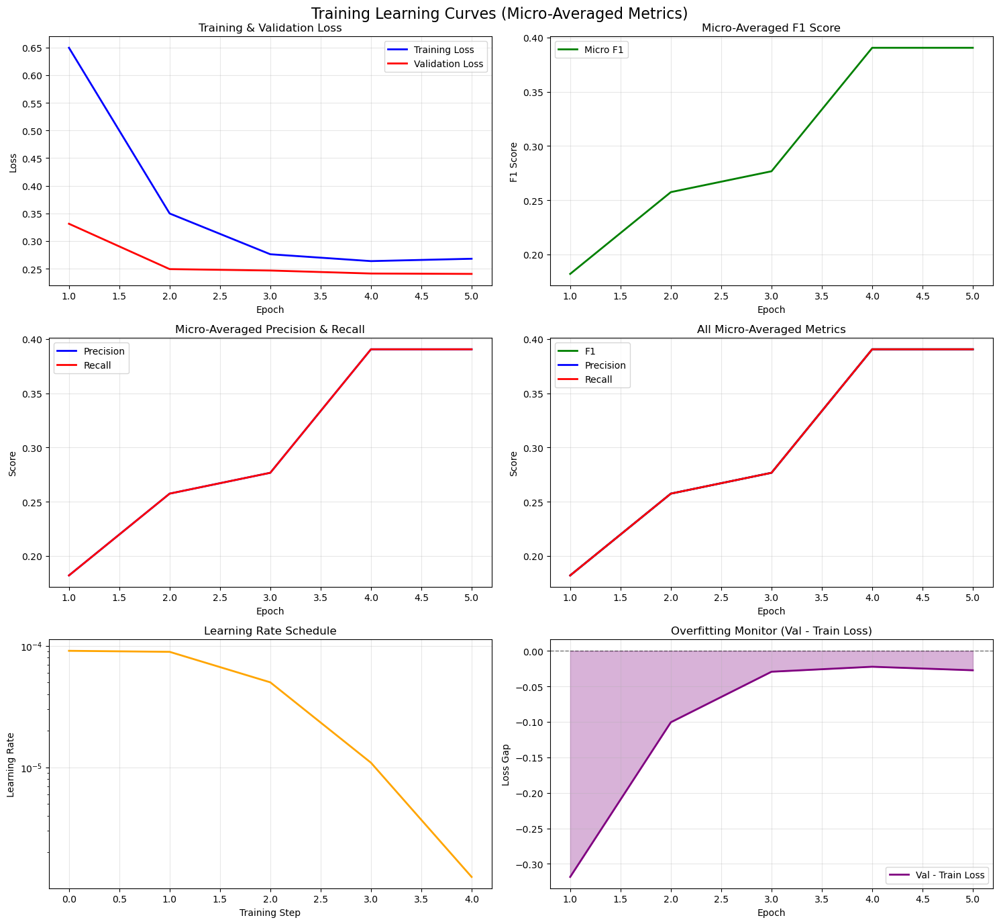


CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3905
   Recall:    0.3905
   F1-Score:  0.3905
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


Epoch 1/5: 100%|██████████| 4/4 [00:01<00:00,  3.01it/s, loss=0.5412, lr=9.08e-05, timesteps=27] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.2326
   Recall:    0.2326
   F1-Score:  0.2326
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


Epoch 2/5: 100%|██████████| 4/4 [00:01<00:00,  3.07it/s, loss=0.3119, lr=8.91e-05, timesteps=9]  



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3837
   Recall:    0.3837
   F1-Score:  0.3837
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


...


CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3542
   Recall:    0.3542
   F1-Score:  0.3542
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


Epoch 4/5: 100%|██████████| 4/4 [00:01<00:00,  3.05it/s, loss=0.2957, lr=1.09e-05, timesteps=9]  



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3785
   Recall:    0.3785
   F1-Score:  0.3785
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


Epoch 5/5: 100%|██████████| 4/4 [00:01<00:00,  3.05it/s, loss=0.2021, lr=1.25e-06, timesteps=33] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3819
   Recall:    0.3819
   F1-Score:  0.3819
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


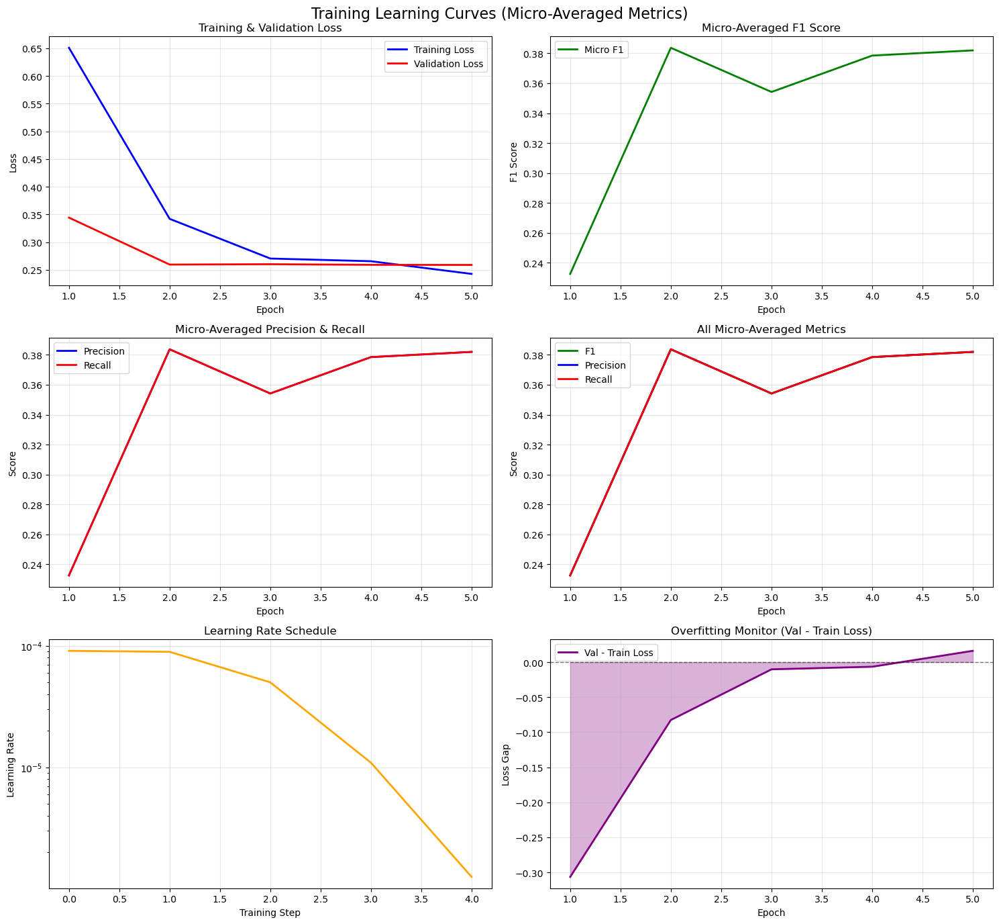


CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3819
   Recall:    0.3819
   F1-Score:  0.3819
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


In [44]:
if sequences and label_sequences_raw:
    if parameters_dict['model_validation_strategy'] == 'train_val_split':
        print("Debugging model with a sample from training data...")
        debug_model_sample(train_sequences_and_labels, case_outcome_model)
        
        trained_case_model, trained_case_logger = train_model(
            case_outcome_model,
            train_sequences_and_labels,
            label_processor,
            val_sequences_and_labels,
            computation_device,
            epochs=parameters_dict['number_of_epochs_for_training'],
            batch_size=parameters_dict['batch_size_for_training'],
            use_mixed_precision=parameters_dict['use_mixed_precision'],
            use_learning_rate_scheduler=parameters_dict['use_learning_rate_scheduler'],
            gradient_clip_norm=parameters_dict['gradient_clip_norm'],
            weighted_loss=parameters_dict['weighted_loss_function'],
            fold_idx=None,
            cache_manager=model_cache_manager
        )
    elif parameters_dict['model_validation_strategy'] == 'k_fold_cross_validation':
        print("\nStarting K-Fold Cross-Validation training...")
        set_global_seed(parameters_dict['random_seed'])
        cv_runner = KFoldCVRunner(
            data=filtered_training_data,
            model_creation_func=create_fresh_model,
            label_processor=label_processor,
            device=computation_device,
            n_splits=parameters_dict['k_fold_num_folds'],
            epochs=parameters_dict['number_of_epochs_for_training'],
            batch_size=parameters_dict['batch_size_for_training'],
            cache_manager=model_cache_manager,
            shuffle=parameters_dict['k_fold_shuffle'],
            use_mixed_precision=parameters_dict['use_mixed_precision'],
            use_learning_rate_scheduler=parameters_dict['use_learning_rate_scheduler'],
            gradient_clip_norm=parameters_dict['gradient_clip_norm'],
            random_state=parameters_dict['random_seed'],
            weighted_loss=parameters_dict['weighted_loss_function']
        ).run()
        
        trained_case_model = cv_runner.load_best_model()
        val_sequences_and_labels, val_data_for_eval = cv_runner.get_best_fold_val_data()

        # stash for later blocks if needed
        cv_training_results = {
            "fold_results": cv_runner.fold_results,
            "aggregate_metrics": cv_runner.aggregate_metrics,
            "best_fold_idx": cv_runner.best_fold_idx,
            "n_splits": cv_runner.n_splits,
        }
        print("K-Fold Cross-Validation training complete.")
        print(f"Best fold: {cv_training_results['best_fold_idx'] + 1} out of {cv_training_results['n_splits']}")
    print("\nTraining complete.")

In [45]:
if sequences and label_sequences_raw:
    if parameters_dict['model_validation_strategy'] == 'train_val_split':
        val_data_for_eval = prepare_validation_data_for_eval(
            val_sequences_and_labels, 
            label_processor
        )
        
        validation_metrics, predictions = evaluate_model(
            trained_case_model,
            val_data_for_eval,
            computation_device,
            label_processor,
            fold_idx=None,
            cache_manager=model_cache_manager
        )
        print_micro_averaged_metrics(validation_metrics)
        print_top_performing_labels(validation_metrics, top_n=parameters_dict['top_n_performing_labels_to_display'])
    elif parameters_dict['model_validation_strategy'] == 'k_fold_cross_validation':
        cv_runner.print_evaluation_summary()
        #get validation metrics from best fold
        #evaluate each fold
        validation_metrics_per_fold = {}
        predictions_per_fold = {}
        for fold_idx in range(cv_runner.n_splits):
            val_sequences_and_labels, val_data_for_eval = cv_runner.get_fold_val_data(fold_idx)
            fold_model = cv_runner.load_fold_model(fold_idx)
            train_data_for_fold = cv_runner.get_fold_train_data(fold_idx)
            fold_validation_metrics, predictions = evaluate_model(
                fold_model,
                val_data_for_eval,
                computation_device,
                label_processor,
                fold_idx=fold_idx,
                cache_manager=model_cache_manager
            )
            validation_metrics_per_fold[fold_idx] = fold_validation_metrics
            predictions_per_fold[fold_idx] = predictions

            table_generator.add_k_fold_results(
                fold_idx,
                fold_validation_metrics,
                case_results=None,
                train_size=len(train_data_for_fold),
                val_size=len(val_sequences_and_labels)
            )
            
        print("\nValidation Metrics for Each Fold:")

Cross-Validation Evaluation Results
Aggregate Metrics Across All Folds:
Micro F1:        0.3862 ± 0.0043
Micro Precision: 0.3862 ± 0.0043
Micro Recall:    0.3862 ± 0.0043
Macro F1:        0.1448 ± 0.0022
Best Fold (1) Metrics:
Micro F1:        0.3905
Micro Precision: 0.3905
Micro Recall:    0.3905
Analyzing date range in data...
MAG data - Date range: 2008-11-28 00:00:00 to 2025-12-04 00:00:00, Count: 86075
CDC data - Date range: 2018-03-07 00:00:00 to 2025-12-30 00:00:00, Count: 83304
Overall date range in data: 2008 - 2025
Date range updated: 2008 to 2025
Date range in data: 2008 to 2025
Using MIN_YEAR=2008, NUM_YEARS=18
Updated temporal dimensions: 216 features (12 months × 18 years)
Creating charge vocabulary from charges DataFrame with 2139 unique charges
Found 5 unique magistrate sections in mag data.
Creating magistrate vocabulary of size 5
Checking BERT embeddings cache...
BERT embeddings cache found.
CaseTransformerModel(
  (text_emb): StreamingCachedBertEmbedding(
    (projec

In [46]:
if sequences and label_sequences_raw:
    set_global_seed(parameters_dict['random_seed'])
    if parameters_dict['model_validation_strategy'] == 'train_val_split':
        case_results = evaluate_case_level(
            trained_case_model,
            val_sequences_and_labels,
            label_processor
        )
        
        print_case_level_metrics(case_results)
        
        print_best_worst_cases(case_results, top_n=parameters_dict['num_best_and_worst_cases_to_display'])
        print_f1_distribution(case_results)
        
        case_level_output_path = models_directory / 'case_level_evaluation.xlsx'
        save_case_level_results(case_results, case_level_output_path)
        
        case_level_label_df = calculate_label_metrics_from_cases(
            case_results, 
            label_processor
        )
        
        save_label_metrics_to_excel(
            case_level_label_df, 
            case_level_output_path
        )
        
        table_generator.add_main_model_results(
            step_metrics=validation_metrics,
            case_results=case_results,
            model_name="Main Transformer (Train/Val Split)"
        )

    elif parameters_dict['model_validation_strategy'] == 'k_fold_cross_validation':
        case_level_dict = {}
        for fold_idx in range(cv_runner.n_splits):
            val_sequences_and_labels, val_data_for_eval = cv_runner.get_fold_val_data(fold_idx)
            fold_model = cv_runner.load_fold_model(fold_idx)
            fold_case_results = evaluate_case_level(
                fold_model,
                val_sequences_and_labels,
                label_processor
            )
            case_level_dict[fold_idx] = fold_case_results
            print(f"\nCase-Level Metrics for Fold {fold_idx + 1}:")
            print_case_level_metrics(fold_case_results)
            print_best_worst_cases(
                fold_case_results,
                top_n=parameters_dict['num_best_and_worst_cases_to_display']
            )
            print_f1_distribution(fold_case_results)
            # Now evaluate case-level metrcis for each fold
            case_level_output_path = models_directory / cv_runner.get_fold_filename(
                'case_level_evaluation',
                fold_idx
            )
            case_level_df = calculate_label_metrics_from_cases(
                fold_case_results,
                label_processor
            )
            save_label_metrics_to_excel(
                case_level_df,
                case_level_output_path
            )
        cv_runner.aggregate_case_level_metrics()

Analyzing date range in data...
MAG data - Date range: 2008-11-28 00:00:00 to 2025-12-04 00:00:00, Count: 86075
CDC data - Date range: 2018-03-07 00:00:00 to 2025-12-30 00:00:00, Count: 83304
Overall date range in data: 2008 - 2025
Date range updated: 2008 to 2025
Date range in data: 2008 to 2025
Using MIN_YEAR=2008, NUM_YEARS=18
Updated temporal dimensions: 216 features (12 months × 18 years)
Creating charge vocabulary from charges DataFrame with 2139 unique charges
Found 5 unique magistrate sections in mag data.
Creating magistrate vocabulary of size 5
Checking BERT embeddings cache...
BERT embeddings cache found.
CaseTransformerModel(
  (text_emb): StreamingCachedBertEmbedding(
    (projector): Identity()
  )
  (def_emb): DefendantRoleEmbedding(
    (race_emb): Embedding(6, 8)
    (gender_emb): Embedding(3, 8)
    (age_linear): Linear(in_features=1, out_features=8, bias=True)
    (fuse): Sequential(
      (0): Linear(in_features=24, out_features=32, bias=True)
      (1): LayerNorm((


Running ablation study...

Running ablation study for fold 1...
Analyzing date range in data...
MAG data - Date range: 2008-11-28 00:00:00 to 2025-12-04 00:00:00, Count: 86075
CDC data - Date range: 2018-03-07 00:00:00 to 2025-12-30 00:00:00, Count: 83304
Overall date range in data: 2008 - 2025
Date range updated: 2008 to 2025
Date range in data: 2008 to 2025
Using MIN_YEAR=2008, NUM_YEARS=18
Updated temporal dimensions: 216 features (12 months × 18 years)
Creating charge vocabulary from charges DataFrame with 2139 unique charges
Found 5 unique magistrate sections in mag data.
Creating magistrate vocabulary of size 5
Checking BERT embeddings cache...
BERT embeddings cache found.
CaseTransformerModel(
  (text_emb): StreamingCachedBertEmbedding(
    (projector): Identity()
  )
  (def_emb): DefendantRoleEmbedding(
    (race_emb): Embedding(6, 8)
    (gender_emb): Embedding(3, 8)
    (age_linear): Linear(in_features=1, out_features=8, bias=True)
    (fuse): Sequential(
      (0): Linear(i

Epoch 1/5: 100%|██████████| 4/4 [00:01<00:00,  3.49it/s, loss=0.5325, lr=9.08e-05, timesteps=17] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.1701
   Recall:    0.1701
   F1-Score:  0.1701
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


Epoch 2/5: 100%|██████████| 4/4 [00:01<00:00,  3.47it/s, loss=0.2682, lr=8.91e-05, timesteps=16] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3328
   Recall:    0.3328
   F1-Score:  0.3328
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


...


CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3107
   Recall:    0.3107
   F1-Score:  0.3107
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


Epoch 4/5: 100%|██████████| 4/4 [00:01<00:00,  3.57it/s, loss=0.2373, lr=1.09e-05, timesteps=11] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.2515
   Recall:    0.2515
   F1-Score:  0.2515
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


Epoch 5/5: 100%|██████████| 4/4 [00:01<00:00,  3.55it/s, loss=0.2794, lr=1.25e-06, timesteps=10] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.2500
   Recall:    0.2500
   F1-Score:  0.2500
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


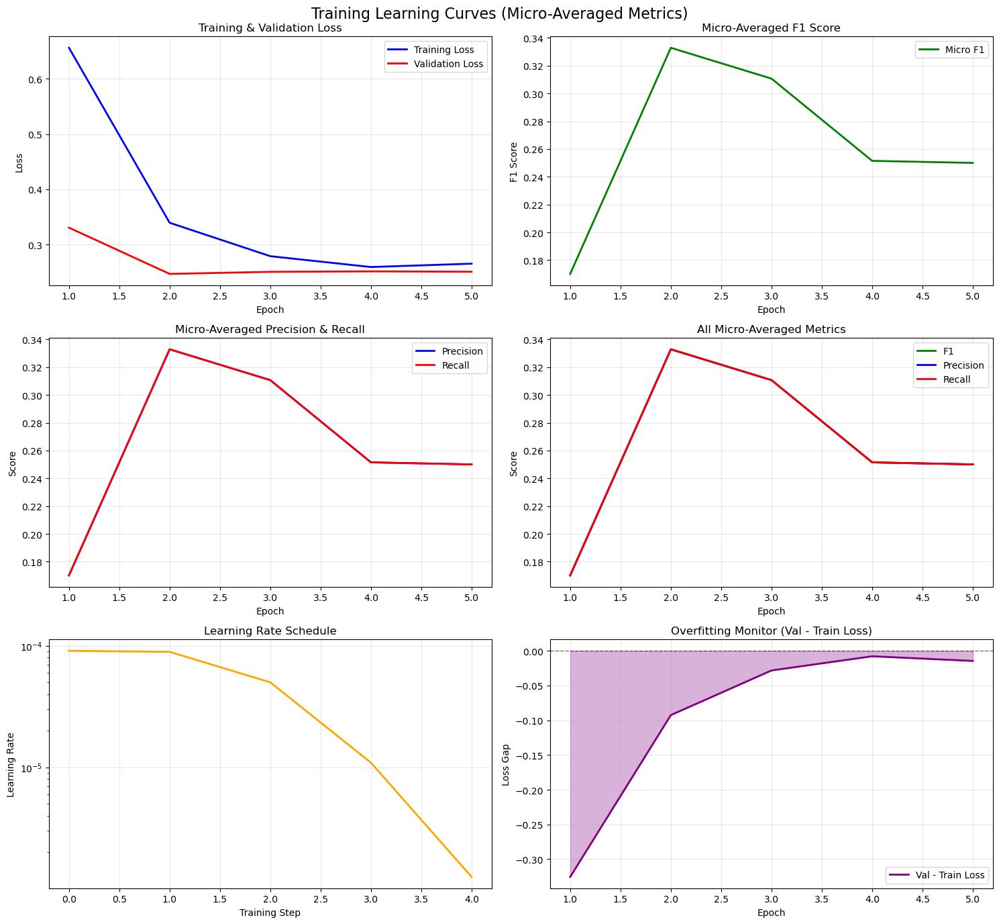

Training complete.
Evaluating model...

CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.2500
   Recall:    0.2500
   F1-Score:  0.2500
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLU

Epoch 1/5: 100%|██████████| 4/4 [00:01<00:00,  3.52it/s, loss=0.5455, lr=9.08e-05, timesteps=30] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.1953
   Recall:    0.1953
   F1-Score:  0.1953
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


Epoch 2/5: 100%|██████████| 4/4 [00:01<00:00,  3.55it/s, loss=0.3049, lr=8.91e-05, timesteps=14] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.2219
   Recall:    0.2219
   F1-Score:  0.2219
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


...


CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.2308
   Recall:    0.2308
   F1-Score:  0.2308
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


Epoch 4/5: 100%|██████████| 4/4 [00:01<00:00,  3.59it/s, loss=0.3042, lr=1.09e-05, timesteps=5]  



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.2781
   Recall:    0.2781
   F1-Score:  0.2781
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


Epoch 5/5: 100%|██████████| 4/4 [00:01<00:00,  3.58it/s, loss=0.2359, lr=1.25e-06, timesteps=27] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.2663
   Recall:    0.2663
   F1-Score:  0.2663
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


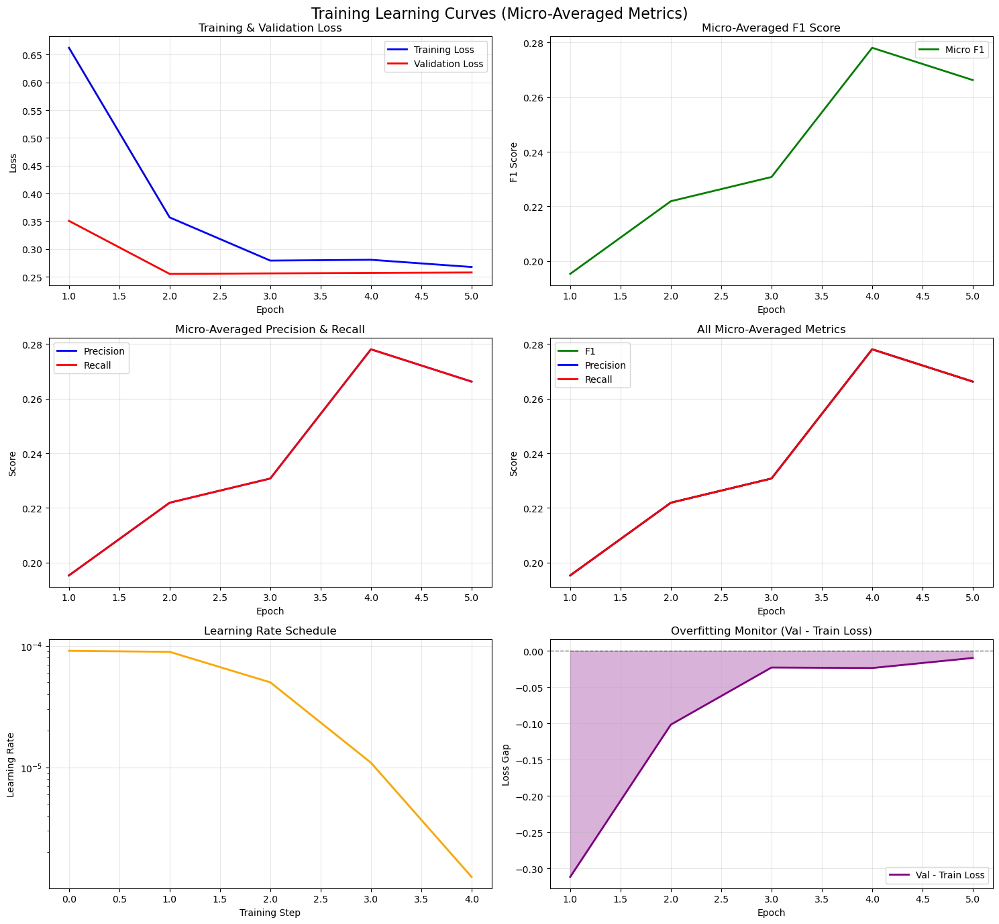

Training complete.
Evaluating model...

CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.2663
   Recall:    0.2663
   F1-Score:  0.2663
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLU

Epoch 1/5: 100%|██████████| 4/4 [00:01<00:00,  3.88it/s, loss=0.5243, lr=9.08e-05, timesteps=11] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.1879
   Recall:    0.1879
   F1-Score:  0.1879
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


Epoch 2/5: 100%|██████████| 4/4 [00:01<00:00,  3.95it/s, loss=0.3161, lr=8.91e-05, timesteps=4]  



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.2411
   Recall:    0.2411
   F1-Score:  0.2411
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


...


CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3328
   Recall:    0.3328
   F1-Score:  0.3328
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


Epoch 4/5: 100%|██████████| 4/4 [00:01<00:00,  3.92it/s, loss=0.2240, lr=1.09e-05, timesteps=4]  



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3861
   Recall:    0.3861
   F1-Score:  0.3861
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


Epoch 5/5: 100%|██████████| 4/4 [00:01<00:00,  3.91it/s, loss=0.2225, lr=1.25e-06, timesteps=15] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3905
   Recall:    0.3905
   F1-Score:  0.3905
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


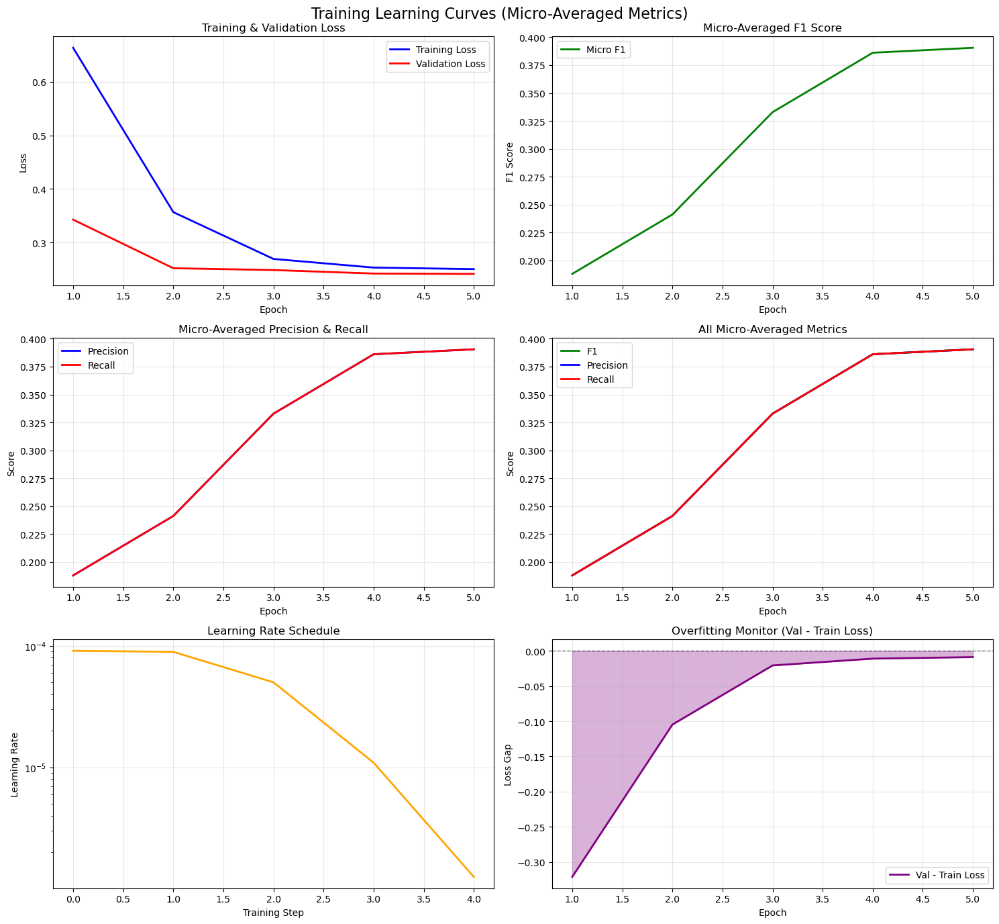

Training complete.
Evaluating model...

CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3905
   Recall:    0.3905
   F1-Score:  0.3905
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLU

Epoch 1/5: 100%|██████████| 4/4 [00:01<00:00,  3.55it/s, loss=0.5843, lr=9.08e-05, timesteps=4]  



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.1760
   Recall:    0.1760
   F1-Score:  0.1760
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


Epoch 2/5: 100%|██████████| 4/4 [00:01<00:00,  3.68it/s, loss=0.2766, lr=8.91e-05, timesteps=21] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3151
   Recall:    0.3151
   F1-Score:  0.3151
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


...


CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3269
   Recall:    0.3269
   F1-Score:  0.3269
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


Epoch 4/5: 100%|██████████| 4/4 [00:01<00:00,  3.61it/s, loss=0.2731, lr=1.09e-05, timesteps=5]  



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3891
   Recall:    0.3891
   F1-Score:  0.3891
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


Epoch 5/5: 100%|██████████| 4/4 [00:01<00:00,  3.63it/s, loss=0.2181, lr=1.25e-06, timesteps=23] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3891
   Recall:    0.3891
   F1-Score:  0.3891
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


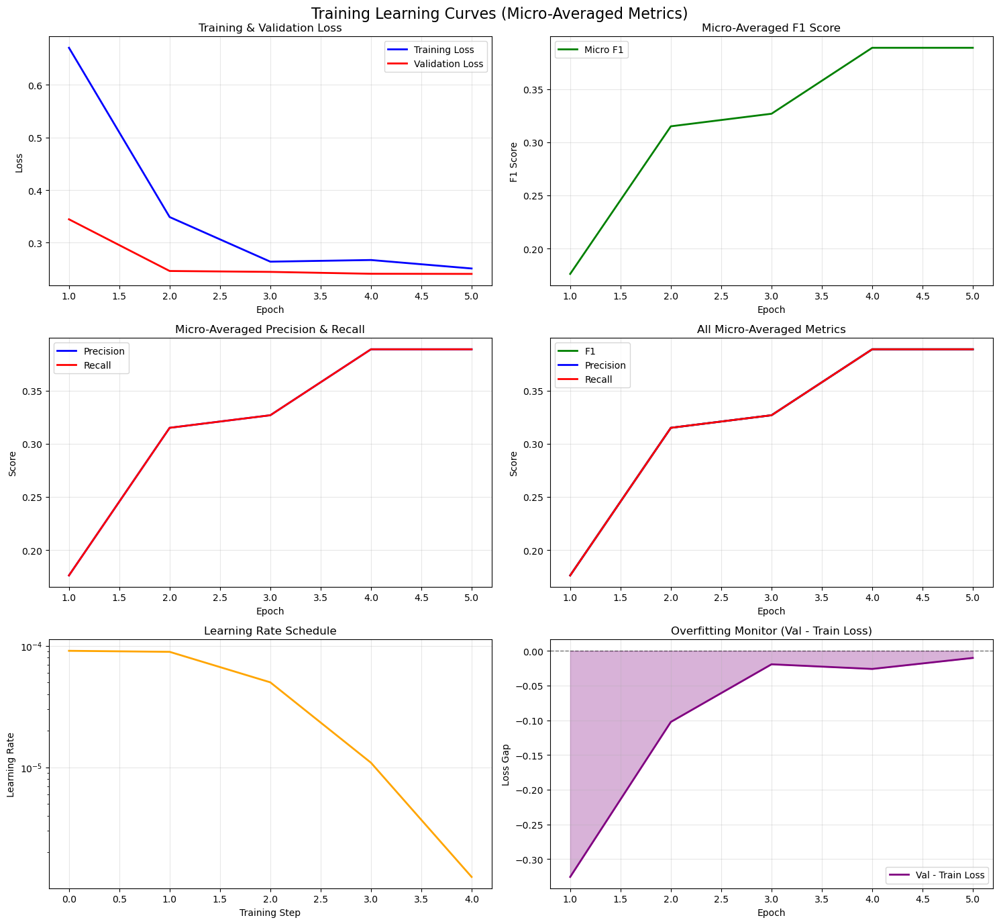

Training complete.
Evaluating model...

CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3891
   Recall:    0.3891
   F1-Score:  0.3891
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLU

Epoch 1/5: 100%|██████████| 4/4 [00:01<00:00,  3.55it/s, loss=0.5599, lr=9.08e-05, timesteps=15] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.1746
   Recall:    0.1746
   F1-Score:  0.1746
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


Epoch 2/5: 100%|██████████| 4/4 [00:01<00:00,  3.63it/s, loss=0.3261, lr=8.91e-05, timesteps=14] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.2086
   Recall:    0.2086
   F1-Score:  0.2086
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


...


CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.2189
   Recall:    0.2189
   F1-Score:  0.2189
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


Epoch 4/5: 100%|██████████| 4/4 [00:01<00:00,  3.63it/s, loss=0.2926, lr=1.09e-05, timesteps=5]  



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.1997
   Recall:    0.1997
   F1-Score:  0.1997
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


Epoch 5/5: 100%|██████████| 4/4 [00:01<00:00,  3.59it/s, loss=0.3567, lr=1.25e-06, timesteps=15] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.1982
   Recall:    0.1982
   F1-Score:  0.1982
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED           21


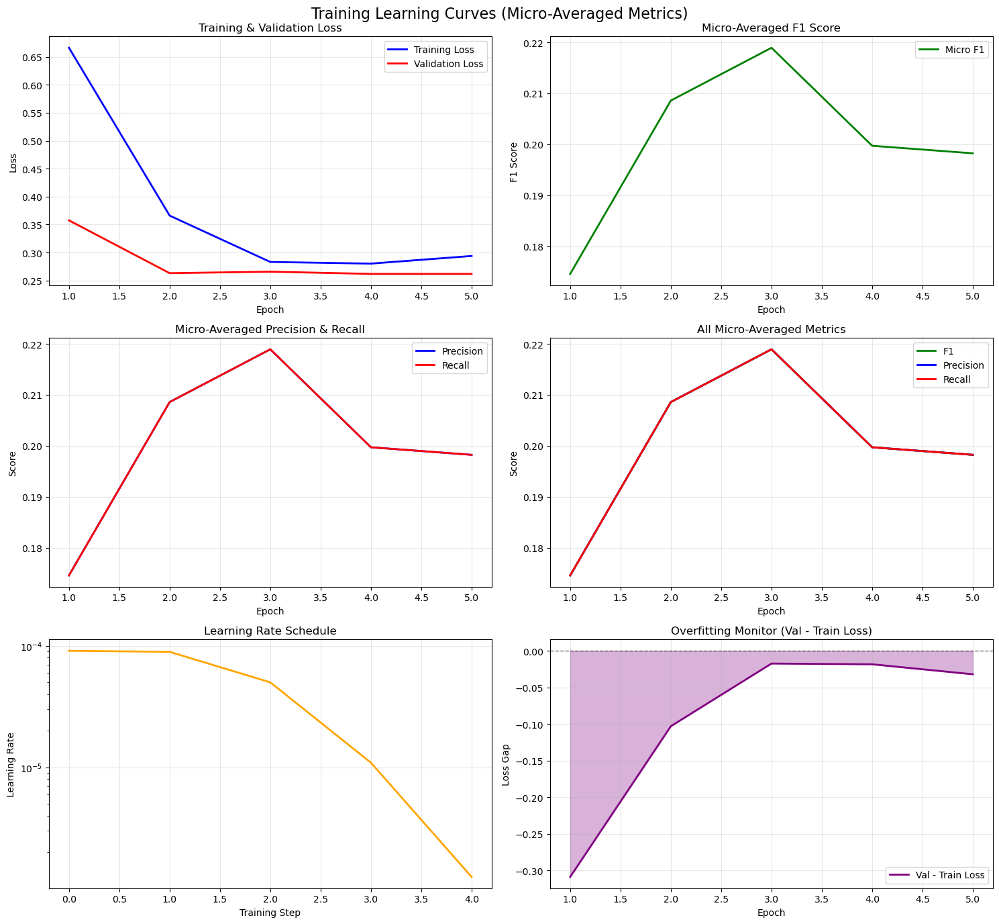

Training complete.
Evaluating model...

CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.1982
   Recall:    0.1982
   F1-Score:  0.1982
   Steps processed: 431
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                  127
  PRE_TRIAL_CONFERENCE_HELD                              78
  BOND_SET                                               70
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        55
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  CHARGES_REFUSED                                        36
  PLED_NOT_GUILTY_TO_CHARGES                             34
  PROBABLE_CAUSE_FOUND                                   31
  BOND_NOT_SET                                           30
  PLED_GUILTY_TO_CHARGES                                 26
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 25
  SENTENCE_THAT_INCLU

Epoch 1/5: 100%|██████████| 4/4 [00:01<00:00,  3.13it/s, loss=0.5042, lr=9.08e-05, timesteps=18] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.1771
   Recall:    0.1771
   F1-Score:  0.1771
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


Epoch 2/5: 100%|██████████| 4/4 [00:01<00:00,  3.08it/s, loss=0.2561, lr=8.91e-05, timesteps=30] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3837
   Recall:    0.3837
   F1-Score:  0.3837
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


...


CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3785
   Recall:    0.3785
   F1-Score:  0.3785
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


Epoch 4/5: 100%|██████████| 4/4 [00:01<00:00,  3.11it/s, loss=0.2976, lr=1.09e-05, timesteps=11] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.4115
   Recall:    0.4115
   F1-Score:  0.4115
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


Epoch 5/5: 100%|██████████| 4/4 [00:01<00:00,  3.08it/s, loss=0.2067, lr=1.25e-06, timesteps=15] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.4080
   Recall:    0.4080
   F1-Score:  0.4080
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


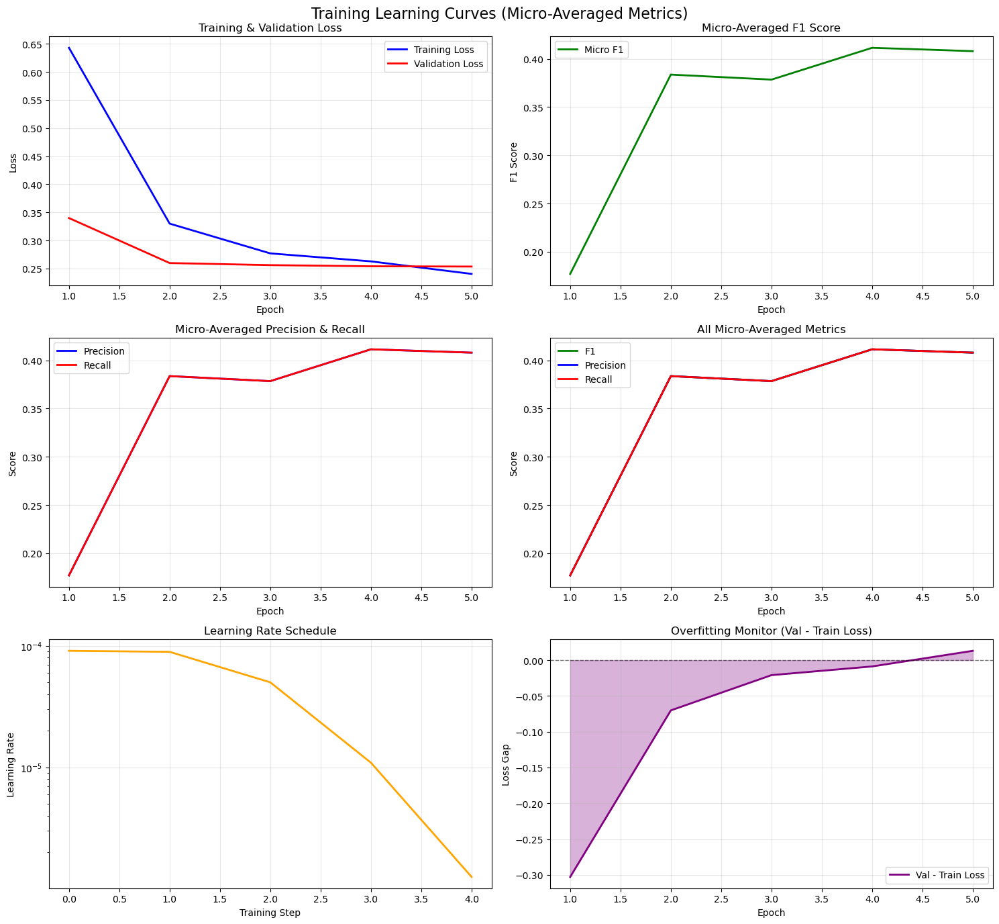

Training complete.
Evaluating model...

CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.4080
   Recall:    0.4080
   F1-Score:  0.4080
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET       

Epoch 1/5: 100%|██████████| 4/4 [00:01<00:00,  3.02it/s, loss=0.6180, lr=9.08e-05, timesteps=5]  



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.1094
   Recall:    0.1094
   F1-Score:  0.1094
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


Epoch 2/5: 100%|██████████| 4/4 [00:01<00:00,  3.08it/s, loss=0.2610, lr=8.91e-05, timesteps=28] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3264
   Recall:    0.3264
   F1-Score:  0.3264
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


...


CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3351
   Recall:    0.3351
   F1-Score:  0.3351
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


Epoch 4/5: 100%|██████████| 4/4 [00:01<00:00,  3.10it/s, loss=0.2261, lr=1.09e-05, timesteps=13] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3038
   Recall:    0.3038
   F1-Score:  0.3038
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


Epoch 5/5: 100%|██████████| 4/4 [00:01<00:00,  3.07it/s, loss=0.2374, lr=1.25e-06, timesteps=16] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.2969
   Recall:    0.2969
   F1-Score:  0.2969
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


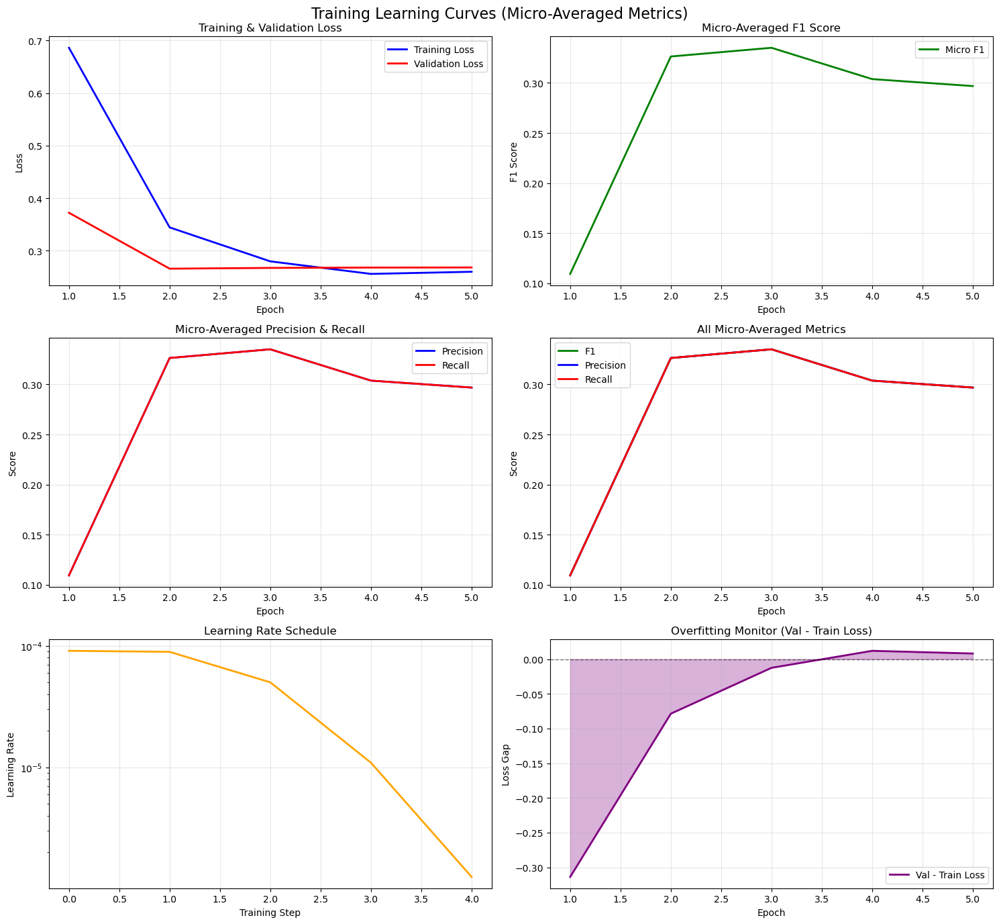

Training complete.
Evaluating model...

CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.2969
   Recall:    0.2969
   F1-Score:  0.2969
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET       

Epoch 1/5: 100%|██████████| 4/4 [00:01<00:00,  3.32it/s, loss=0.5463, lr=9.08e-05, timesteps=26] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.1684
   Recall:    0.1684
   F1-Score:  0.1684
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


Epoch 2/5: 100%|██████████| 4/4 [00:01<00:00,  3.41it/s, loss=0.2431, lr=8.91e-05, timesteps=21] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3611
   Recall:    0.3611
   F1-Score:  0.3611
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


...


CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3490
   Recall:    0.3490
   F1-Score:  0.3490
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


Epoch 4/5: 100%|██████████| 4/4 [00:01<00:00,  3.40it/s, loss=0.2874, lr=1.09e-05, timesteps=12] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3802
   Recall:    0.3802
   F1-Score:  0.3802
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


Epoch 5/5: 100%|██████████| 4/4 [00:01<00:00,  3.40it/s, loss=0.2828, lr=1.25e-06, timesteps=7]  



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3889
   Recall:    0.3889
   F1-Score:  0.3889
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


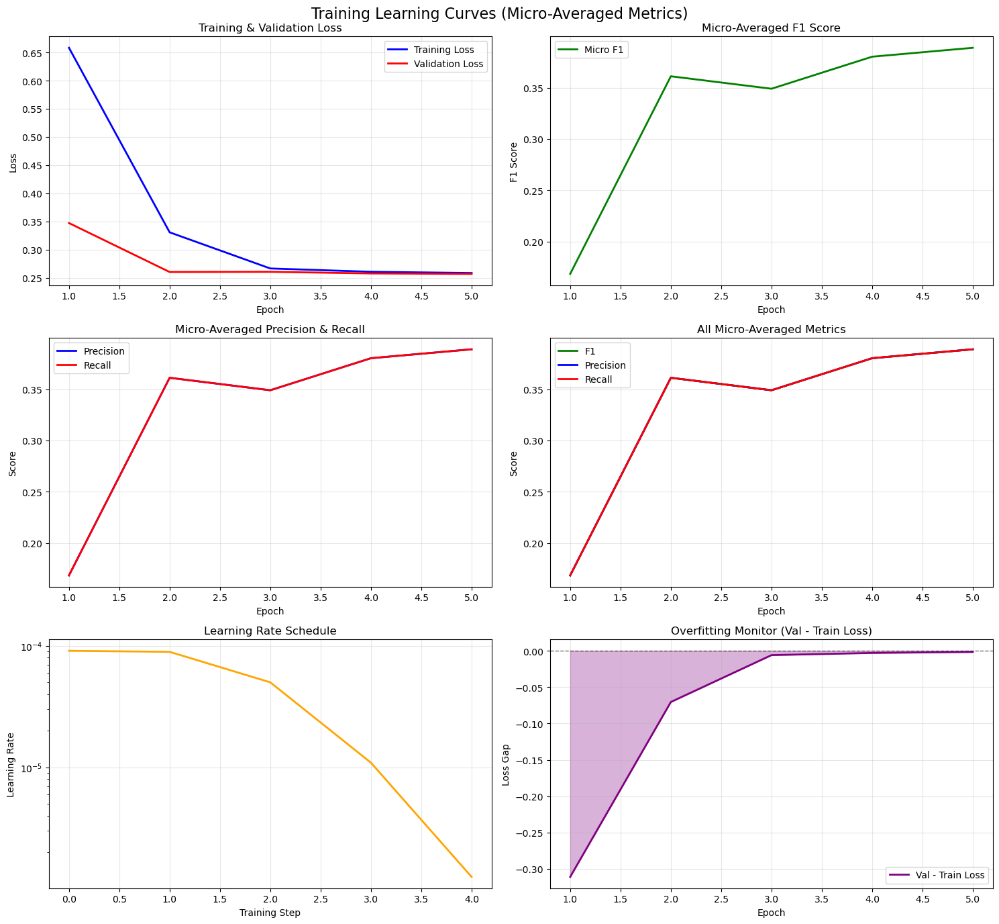

Training complete.
Evaluating model...

CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3889
   Recall:    0.3889
   F1-Score:  0.3889
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET       

Epoch 1/5: 100%|██████████| 4/4 [00:01<00:00,  3.15it/s, loss=0.5732, lr=9.08e-05, timesteps=10] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.1580
   Recall:    0.1580
   F1-Score:  0.1580
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


Epoch 2/5: 100%|██████████| 4/4 [00:01<00:00,  3.14it/s, loss=0.3336, lr=8.91e-05, timesteps=4]  



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3073
   Recall:    0.3073
   F1-Score:  0.3073
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


...


CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3229
   Recall:    0.3229
   F1-Score:  0.3229
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


Epoch 4/5: 100%|██████████| 4/4 [00:01<00:00,  3.18it/s, loss=0.2514, lr=1.09e-05, timesteps=22] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3663
   Recall:    0.3663
   F1-Score:  0.3663
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


Epoch 5/5: 100%|██████████| 4/4 [00:01<00:00,  3.17it/s, loss=0.2258, lr=1.25e-06, timesteps=17] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3715
   Recall:    0.3715
   F1-Score:  0.3715
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


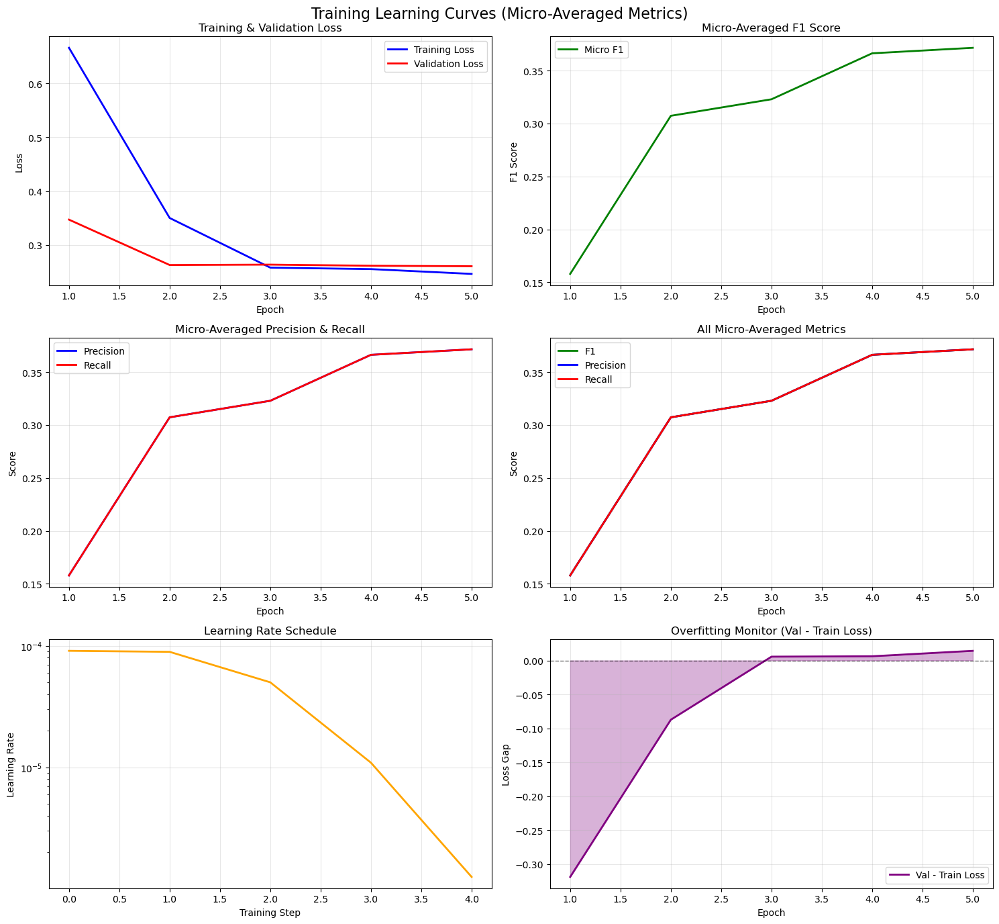

Training complete.
Evaluating model...

CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3715
   Recall:    0.3715
   F1-Score:  0.3715
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET       

Epoch 1/5: 100%|██████████| 4/4 [00:01<00:00,  3.13it/s, loss=0.5992, lr=9.08e-05, timesteps=4]  



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.1181
   Recall:    0.1181
   F1-Score:  0.1181
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


Epoch 2/5: 100%|██████████| 4/4 [00:01<00:00,  3.16it/s, loss=0.2521, lr=8.91e-05, timesteps=15] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3229
   Recall:    0.3229
   F1-Score:  0.3229
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


...


CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3524
   Recall:    0.3524
   F1-Score:  0.3524
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


Epoch 4/5: 100%|██████████| 4/4 [00:01<00:00,  3.16it/s, loss=0.2345, lr=1.09e-05, timesteps=24] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.2986
   Recall:    0.2986
   F1-Score:  0.2986
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


Epoch 5/5: 100%|██████████| 4/4 [00:01<00:00,  3.07it/s, loss=0.2925, lr=1.25e-06, timesteps=19] 



CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3177
   Recall:    0.3177
   F1-Score:  0.3177
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET                                           19


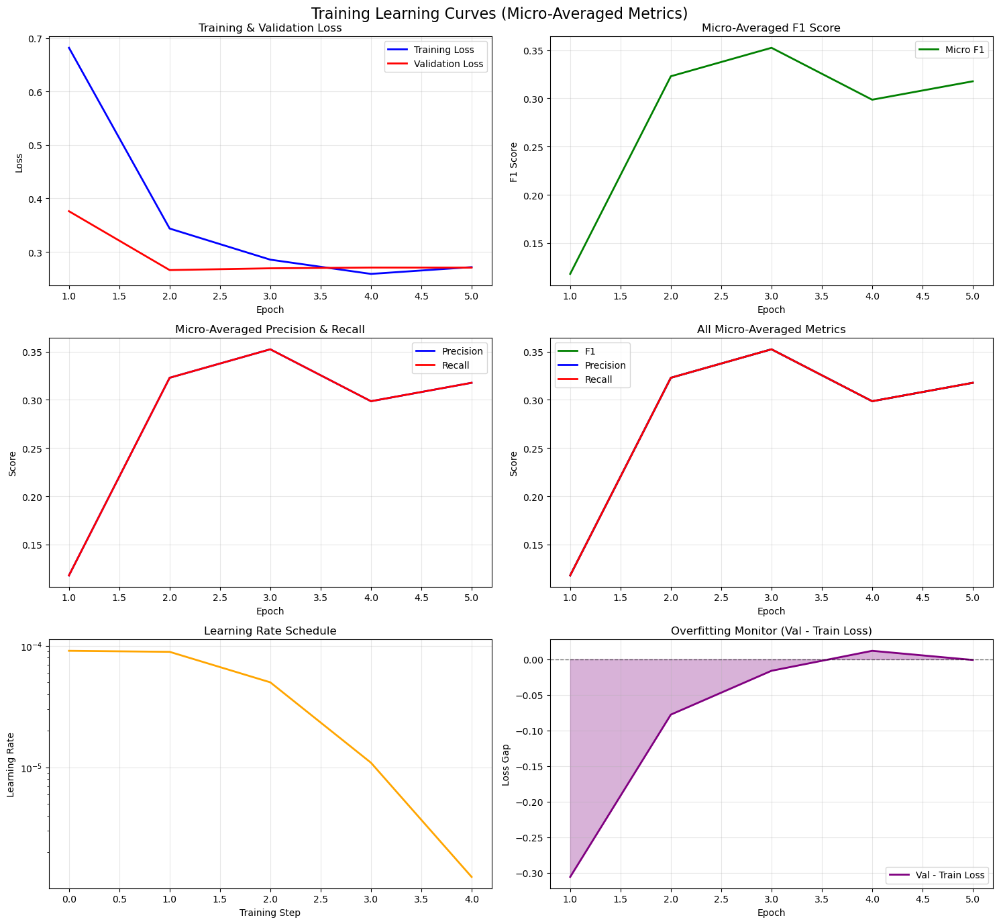

Training complete.
Evaluating model...

CAUSAL MODEL - MICRO-AVERAGED METRICS:
   Precision: 0.3177
   Recall:    0.3177
   F1-Score:  0.3177
   Steps processed: 350
   Cases processed: 50

1. True Label Distribution:
----------------------------------------
  CONTINUANCE_OCCURRED                                   86
  BOND_SET                                               74
  PRE_TRIAL_CONFERENCE_HELD                              56
  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER        51
  FIRST_APPEARANCE_HEARING_OCCURRED                      50
  PLED_NOT_GUILTY_TO_CHARGES                             29
  CHARGES_REFUSED                                        29
  DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                  27
  PLED_GUILTY_TO_CHARGES                                 25
  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                 24
  PROBABLE_CAUSE_FOUND                                   22
  THE_STATE_WAS_NOT_PRESENT                              19
  BOND_NOT_SET       

In [47]:
set_global_seed(parameters_dict['random_seed'])
if sequences and label_sequences_raw:
    print("\nRunning ablation study...")
    if parameters_dict['model_validation_strategy'] == 'train_val_split':
        ablation_configs = create_standard_ablation_configurations()
        fresh_model = create_model_from_data(data=court_data, cache_dir=model_cache_manager.get_cache_dir('bert'), device=computation_device, cache_manager=model_cache_manager, parameters_dict=parameters_dict, bert_out_dim=bert_out_dim)

        ablation_results = run_ablation_study(
            base_model=fresh_model,
            train_data=train_sequences_and_labels,
            val_data=val_sequences_and_labels,
            label_processor=label_processor,
            device=computation_device,
            ablation_configs=ablation_configs,
            output_dir=model_cache_manager.get_cache_dir('ablation_study'),
            epochs=parameters_dict['number_of_epochs_for_training'],
            batch_size=parameters_dict['batch_size_for_training'],
            use_mixed_precision=parameters_dict['use_mixed_precision'],
            use_learning_rate_scheduler=parameters_dict['use_learning_rate_scheduler'],
            gradient_clip_norm=parameters_dict['gradient_clip_norm'],
            weighted_loss=parameters_dict['weighted_loss_function'],
            fold_idx=None,
            cache_manager=model_cache_manager
        )
        df = compare_ablation_table(ablation_results)

    elif parameters_dict['model_validation_strategy'] == 'k_fold_cross_validation':
        ablation_configs = create_standard_ablation_configurations()
        # do it for each fold's training/validation split
        df_dict_per_fold = {}
        ablation_results_per_fold = {}

        for fold_idx in range(cv_training_results['n_splits']):
            print(f"\nRunning ablation study for fold {fold_idx + 1}...")
            val_sequences_and_labels, val_data_for_eval = cv_runner.get_fold_val_data(fold_idx)
            train_data = cv_runner.get_fold_train_data(fold_idx)
            fresh_model = create_fresh_model()  # This is already defined in the notebook
            set_global_seed(parameters_dict['random_seed'])
            ablation_results = run_ablation_study(
                base_model=fresh_model,
                train_data=train_data,
                val_data=val_sequences_and_labels,
                label_processor=label_processor,
                device=computation_device,
                ablation_configs=ablation_configs,
                output_dir=model_cache_manager.get_cache_dir('ablation_study') / f'fold_{fold_idx + 1}',
                epochs=parameters_dict['number_of_epochs_for_training'],
                batch_size=parameters_dict['batch_size_for_training'],
                use_mixed_precision=parameters_dict['use_mixed_precision'],
                use_learning_rate_scheduler=parameters_dict['use_learning_rate_scheduler'],
                gradient_clip_norm=parameters_dict['gradient_clip_norm'],
                weighted_loss=parameters_dict['weighted_loss_function'],
                fold_idx=fold_idx,
                cache_manager=model_cache_manager
            )

            # keep raw results per fold
            ablation_results_per_fold[fold_idx] = ablation_results

            df = compare_ablation_table(ablation_results)
            # add a column for fold index
            df['fold_idx'] = fold_idx
            df_dict_per_fold[fold_idx] = df

        # combine all folds into one dataframe if you want it
        combined_df = pd.concat(df_dict_per_fold.values(), ignore_index=True)


In [48]:
if parameters_dict['model_validation_strategy'] == 'train_val_split':
    print("\nAblation study complete. Saving results...")
    df.to_excel(model_cache_manager.get_cache_dir('ablation_study') / "ablation_comparison_table.xlsx")
elif parameters_dict['model_validation_strategy'] == 'k_fold_cross_validation':
    print("\nAblation study complete for all folds. Saving combined results...")
    combined_df.to_excel(model_cache_manager.get_cache_dir('ablation_study') / "ablation_comparison_table_kfold.xlsx")


Ablation study complete for all folds. Saving combined results...


In [49]:
# ADD ABLATION RESULTS TO COMPARISON TABLES
if parameters_dict['model_validation_strategy'] == 'train_val_split':
    if 'ablation_results' in locals() and ablation_results:
        print("Adding ablation study results to comparison tables...")
        for config_name, ablation_result in ablation_results.items():
            ablation_config = ablation_result['ablation_config']
            ablated_features = [k for k, v in ablation_config.items() if v]

            table_generator.add_ablation_results(
                config_name=config_name,
                ablated_features=ablated_features,
                step_metrics=ablation_result['metrics'],
                case_results=None  # Ablation typically doesn't include case-level
            )
        print(f"   ✅ Added {len(ablation_results)} ablation configurations")

elif parameters_dict['model_validation_strategy'] == 'k_fold_cross_validation':
    if 'ablation_results_per_fold' in locals() and ablation_results_per_fold:
        print("Adding ablation study results to comparison tables (K-Fold)...")
        total_configs = 0

        for fold_idx, fold_ablation_results in ablation_results_per_fold.items():
            for config_name, ablation_result in fold_ablation_results.items():
                ablation_config = ablation_result['ablation_config']
                ablated_features = [k for k, v in ablation_config.items() if v]

                # include fold info in the name so you can distinguish them later
                table_generator.add_ablation_results(
                    config_name=f"{config_name} (Fold {fold_idx + 1})",
                    ablated_features=ablated_features,
                    step_metrics=ablation_result['metrics'],
                    case_results=None
                )
                total_configs += 1

        print(f"   ✅ Added {total_configs} ablation configurations across {len(ablation_results_per_fold)} folds")


Adding ablation study results to comparison tables (K-Fold)...
   ✅ Added 10 ablation configurations across 2 folds



──────────────────────────────────────────────────────────────────────
  Extracting embeddings from Fold 1 / 2
──────────────────────────────────────────────────────────────────────
Analyzing date range in data...
MAG data - Date range: 2008-11-28 00:00:00 to 2025-12-04 00:00:00, Count: 86075
CDC data - Date range: 2018-03-07 00:00:00 to 2025-12-30 00:00:00, Count: 83304
Overall date range in data: 2008 - 2025
Date range updated: 2008 to 2025
Date range in data: 2008 to 2025
Using MIN_YEAR=2008, NUM_YEARS=18
Updated temporal dimensions: 216 features (12 months × 18 years)
Creating charge vocabulary from charges DataFrame with 2139 unique charges
Found 5 unique magistrate sections in mag data.
Creating magistrate vocabulary of size 5
Checking BERT embeddings cache...
BERT embeddings cache found.
CaseTransformerModel(
  (text_emb): StreamingCachedBertEmbedding(
    (projector): Identity()
  )
  (def_emb): DefendantRoleEmbedding(
    (race_emb): Embedding(6, 8)
    (gender_emb): Embeddin

Extracting pre-classifier vectors for 50 samples: 100%|██████████| 50/50 [00:00<00:00, 100.62it/s]


Extracted 50 vectors of dimension 896
  Fold 1: extracted 50 vectors (dim=896)

──────────────────────────────────────────────────────────────────────
  Extracting embeddings from Fold 2 / 2
──────────────────────────────────────────────────────────────────────
Analyzing date range in data...
MAG data - Date range: 2008-11-28 00:00:00 to 2025-12-04 00:00:00, Count: 86075
CDC data - Date range: 2018-03-07 00:00:00 to 2025-12-30 00:00:00, Count: 83304
Overall date range in data: 2008 - 2025
Date range updated: 2008 to 2025
Date range in data: 2008 to 2025
Using MIN_YEAR=2008, NUM_YEARS=18
Updated temporal dimensions: 216 features (12 months × 18 years)
Creating charge vocabulary from charges DataFrame with 2139 unique charges
Found 5 unique magistrate sections in mag data.
Creating magistrate vocabulary of size 5
Checking BERT embeddings cache...
BERT embeddings cache found.
CaseTransformerModel(
  (text_emb): StreamingCachedBertEmbedding(
    (projector): Identity()
  )
  (def_emb): Def

Extracting pre-classifier vectors for 50 samples: 100%|██████████| 50/50 [00:00<00:00, 117.42it/s]


Extracted 50 vectors of dimension 896
  Fold 2: extracted 50 vectors (dim=896)

COMBINED: 100 vectors × 896 dims across 2 folds
  Fold 1: 50 samples (50.0%)
  Fold 2: 50 samples (50.0%)
PCA: Reduced from 896 to 2 dimensions, explained variance ratio: [0.82114375 0.0230829 ]

📊 Elbow / Silhouette analysis …
💾 Saved: /data/krosen5/cache/transformers/balanced_10/embedding_analysis/elbow_silhouette.png


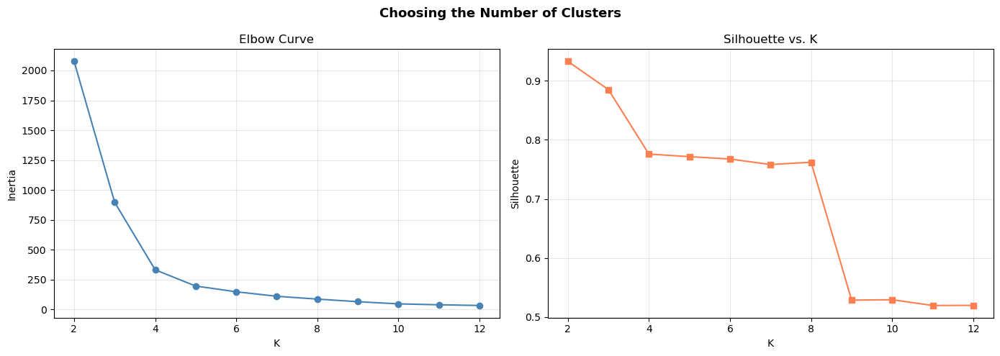


🔶 KMeans with K=6 …
Number of clusters found: 6
   KMeans metrics: {'number_of_clusters': 6, 'silhouette_score': 0.7674517631530762, 'calinski_harabasz_score': 9668.894702386937}
💾 Saved label grid to /data/krosen5/cache/transformers/balanced_10/embedding_analysis/pca_label_grid.png


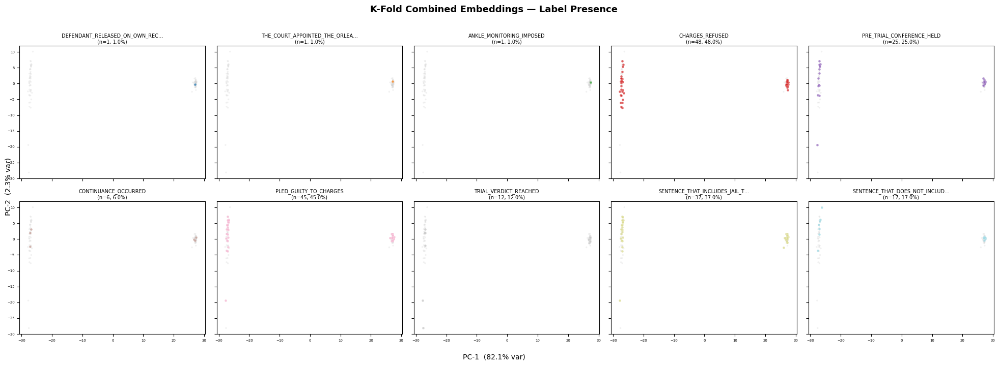

💾 Saved cluster PCA to /data/krosen5/cache/transformers/balanced_10/embedding_analysis/pca_by_kmeans_cluster.png


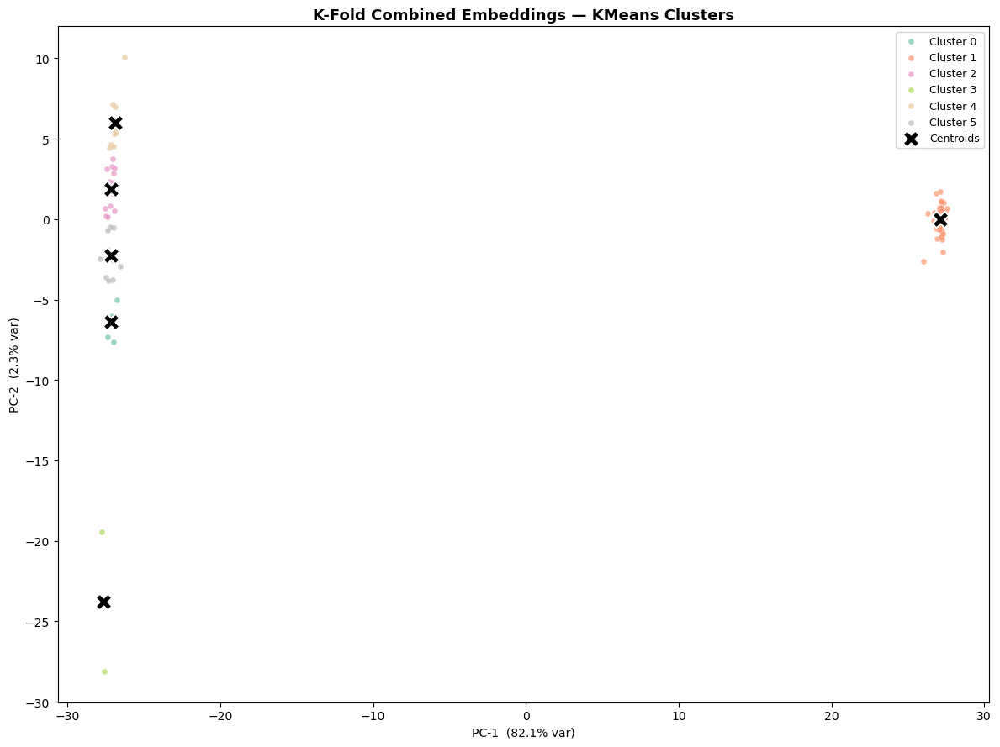

💾 Saved: /data/krosen5/cache/transformers/balanced_10/embedding_analysis/pca_by_fold.png


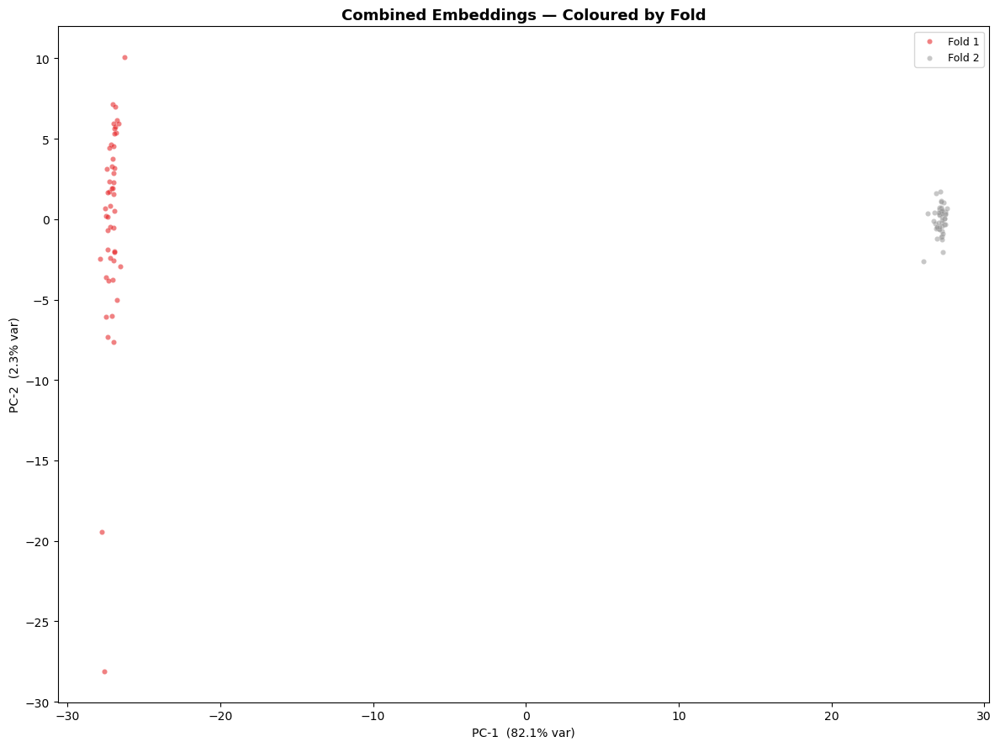

💾 Saved multi-label heatmap to /data/krosen5/cache/transformers/balanced_10/embedding_analysis/multilabel_cluster_heatmap.png


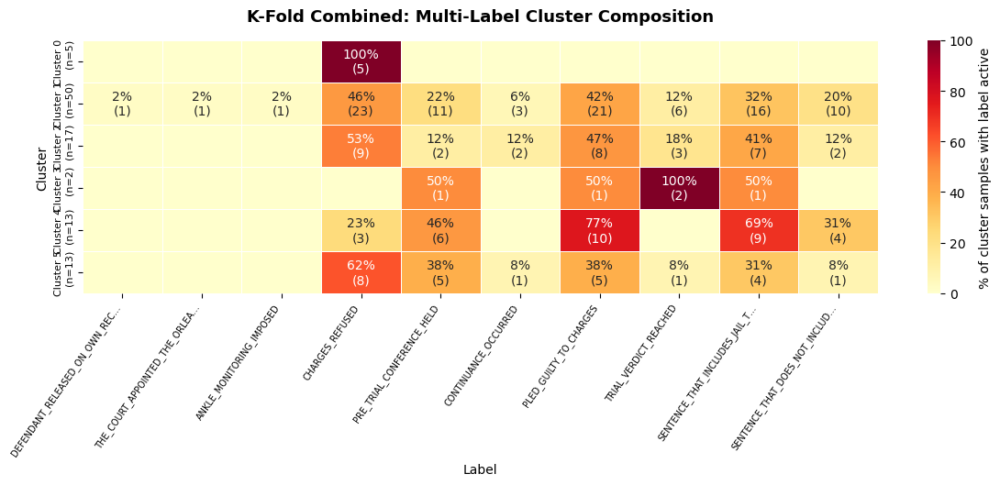


📊 MULTI-LABEL CLUSTER SUMMARY
----------------------------------------------------------------------
  Cluster 0 (5 samples): CHARGES_REFUSED (100%)
  Cluster 1 (50 samples): CHARGES_REFUSED (46%), PLED_GUILTY_TO_CHARGES (42%), SENTENCE_THAT_INCLUDES_J… (32%), PRE_TRIAL_CONFERENCE_HELD (22%), SENTENCE_THAT_DOES_NOT_I… (20%)
  Cluster 2 (17 samples): CHARGES_REFUSED (53%), PLED_GUILTY_TO_CHARGES (47%), SENTENCE_THAT_INCLUDES_J… (41%), TRIAL_VERDICT_REACHED (18%), SENTENCE_THAT_DOES_NOT_I… (12%)
  Cluster 3 (2 samples): TRIAL_VERDICT_REACHED (100%), PLED_GUILTY_TO_CHARGES (50%), PRE_TRIAL_CONFERENCE_HELD (50%), SENTENCE_THAT_INCLUDES_J… (50%)
  Cluster 4 (13 samples): PLED_GUILTY_TO_CHARGES (77%), SENTENCE_THAT_INCLUDES_J… (69%), PRE_TRIAL_CONFERENCE_HELD (46%), SENTENCE_THAT_DOES_NOT_I… (31%), CHARGES_REFUSED (23%)
  Cluster 5 (13 samples): CHARGES_REFUSED (62%), PLED_GUILTY_TO_CHARGES (38%), PRE_TRIAL_CONFERENCE_HELD (38%), SENTENCE_THAT_INCLUDES_J… (31%), SENTENCE_THAT_DOES_NOT_I… (8

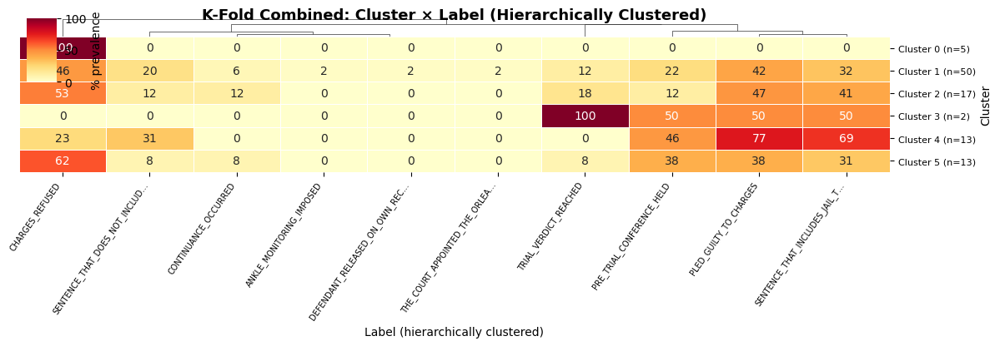

💾 Saved stacked bars to /data/krosen5/cache/transformers/balanced_10/embedding_analysis/cluster_label_stacked_bars.png


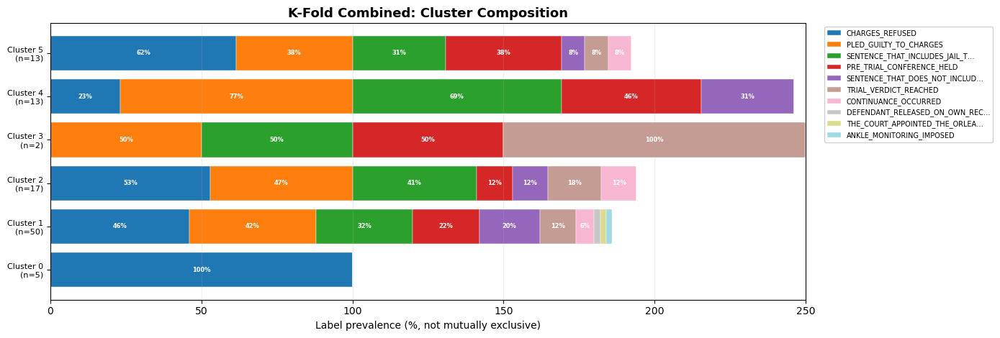


💾 Results CSV: /data/krosen5/cache/transformers/balanced_10/embedding_analysis/embedding_clustering_results.csv

CLUSTER COMPOSITION SUMMARY (KMeans)
  Cluster 0 — 5 samples — folds: [F1:5]
      top labels: CHARGES_REFUSED (5)
  Cluster 1 — 50 samples — folds: [F2:50]
      top labels: CHARGES_REFUSED (23), PLED_GUILTY_TO_CHARGES (21), SENTENCE_THAT_INCLUDES_JA (16), PRE_TRIAL_CONFERENCE_HELD (11), SENTENCE_THAT_DOES_NOT_IN (10)
  Cluster 2 — 17 samples — folds: [F1:17]
      top labels: CHARGES_REFUSED (9), PLED_GUILTY_TO_CHARGES (8), SENTENCE_THAT_INCLUDES_JA (7), TRIAL_VERDICT_REACHED (3), SENTENCE_THAT_DOES_NOT_IN (2)
  Cluster 3 — 2 samples — folds: [F1:2]
      top labels: TRIAL_VERDICT_REACHED (2), PLED_GUILTY_TO_CHARGES (1), PRE_TRIAL_CONFERENCE_HELD (1), SENTENCE_THAT_INCLUDES_JA (1)
  Cluster 4 — 13 samples — folds: [F1:13]
      top labels: PLED_GUILTY_TO_CHARGES (10), SENTENCE_THAT_INCLUDES_JA (9), PRE_TRIAL_CONFERENCE_HELD (6), SENTENCE_THAT_DOES_NOT_IN (4), CHARGES_REFU

In [50]:
if sequences and label_sequences_raw:
    if parameters_dict['model_validation_strategy'] == 'train_val_split':
        set_global_seed(parameters_dict['random_seed'])
        embedding_results = run_embedding_clusters_pipeline(
            model=trained_case_model,
            data=val_sequences_and_labels,
            label_processor=label_processor,
            device=computation_device,
            output_dir=model_cache_manager.get_cache_dir('embedding_analysis'),
            max_samples=None,
            n_clusters=6,
            use_teacher_forcing=True,
            run_dbscan=False,
            show_elbow=True,
            verbose=True,
            random_state=parameters_dict['random_seed']
        )

    elif parameters_dict['model_validation_strategy'] == 'k_fold_cross_validation':
        set_global_seed(parameters_dict['random_seed'])
        kfold_embedding_results = run_embedding_clusters_kfolds_pipeline(
            cv_runner=cv_runner,
            label_processor=label_processor,
            device=computation_device,
            output_dir=model_cache_manager.get_cache_dir('embedding_analysis'),
            max_samples_per_fold=None,
            n_clusters=6,
            use_teacher_forcing=True,
            run_dbscan=False,
            show_elbow=True,
            verbose=True,
            random_state=parameters_dict['random_seed']
        )

In [51]:
if sequences and label_sequences_raw:
    if parameters_dict['model_validation_strategy'] == 'train_val_split':
        # Use helper function for diagnostic analysis
        diagnostic_results = run_diagnostic_analysis(
            val_data_for_eval,
            label_processor,
            trained_case_model,
            computation_device
        )
    elif parameters_dict['model_validation_strategy'] == 'k_fold_cross_validation':
        diagnostic_results = run_diagnostic_analysis(
            val_data_for_eval,  # Best fold's validation data
            label_processor,
            trained_case_model,
            computation_device
        )


DIAGNOSTIC ANALYSIS
🔍 COMPREHENSIVE TRAINING DIAGNOSTIC

1. EVALUATION SKIPPING ANALYSIS
----------------------------------------
Total prediction steps: 350
Steps with k=0 (skipped): 0 (0.0%)
Steps actually evaluated: 350 (100.0%)
Initial State predictions: 50

Label count distribution (k values):
  k=1: 224 steps (64.0%) - EVALUATED
  k=2: 65 steps (18.6%) - EVALUATED
  k=3: 31 steps (8.9%) - EVALUATED
  k=4: 22 steps (6.3%) - EVALUATED
  k=5: 7 steps (2.0%) - EVALUATED
  k=6: 1 steps (0.3%) - EVALUATED

2. SAMPLE OF SKIPPED vs EVALUATED STEPS
----------------------------------------
SKIPPED STEPS (k=0) - Examples:

EVALUATED STEPS (k>0) - Examples:
  1. Seq 0, Step -1: k=5, Labels: ['FIRST_APPEARANCE_HEARING_OCCURRED', 'BOND_SET', 'THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER', 'PROBABLE_CAUSE_FOUND', 'THE_STATE_WAS_NOT_PRESENT']
  2. Seq 0, Step 0: k=1, Labels: ['THE_STATE_WAS_NOT_PRESENT']
  3. Seq 0, Step 1: k=1, Labels: ['THE_STATE_WAS_NOT_PRESENT']
  4. Seq 0, Step 2: k=1, 

In [52]:
if sequences and label_sequences_raw:
    if parameters_dict['model_validation_strategy'] == 'train_val_split':
        # Use helper function for baseline comparison
        set_global_seed(parameters_dict['random_seed'])
        baseline_model, baseline_results, baseline1_predictions_binary = run_baseline_comparison(
            train_sequences_and_labels,
            val_sequences_and_labels,
            label_processor,
            epochs=parameters_dict['number_of_epochs_for_training'],
            batch_size=parameters_dict['batch_size_for_training']
        )

    elif parameters_dict['model_validation_strategy'] == 'k_fold_cross_validation':
        # do the baseline on each fold's validation data
        baseline_results_per_fold = {}
        baseline_pred_binaries_per_fold = {}
        set_global_seed(parameters_dict['random_seed'])
        for fold_idx in range(cv_training_results['n_splits']):
            print(f"Running baseline comparison on fold {fold_idx + 1} validation data.")
            fold = cv_training_results['fold_results'][fold_idx]
            baseline_model, baseline_results, baseline1_predictions_binary = run_baseline_comparison(
                fold['train_data'],
                fold['val_data'],
                label_processor,
                epochs=parameters_dict['number_of_epochs_for_training'],
                batch_size=parameters_dict['batch_size_for_training']
            )
            baseline_results_per_fold[fold_idx] = baseline_results
            baseline_pred_binaries_per_fold[fold_idx] = baseline1_predictions_binary


Running baseline comparison on fold 1 validation data.

BASELINE MODEL COMPARISON
BASELINE MODEL COMPARISON
🚀 Starting baseline model training...
   Training sequences: 50
   Validation sequences: 50
   Label processor has 20 labels
   Will predict final case completion outcomes
🎯 Baseline model will predict 5 completion outcomes:
   0: CHARGES_REFUSED (MLB index: 8)
   1: SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED (MLB index: 18)
   2: TRIAL_VERDICT_REACHED (MLB index: 17)
   3: SENTENCE_THAT_DOES_NOT_INCLUDE_JAIL_TIME_WAS_IMPOSED (MLB index: 19)
   4: PROBABLE_CAUSE_NOT_FOUND (MLB index: 10)
🚀 Training baseline model on 50 sequences...


Extracting baseline features: 100%|██████████| 50/50 [00:00<00:00, 66916.15it/s]


📊 Feature extraction results:
   Valid samples: 50
   Skipped (no features): 0
   Skipped (no completion outcome): 0

📈 Completion outcome distribution:
   CHARGES_REFUSED: 23 (46.0%)
   PROBABLE_CAUSE_NOT_FOUND: 1 (2.0%)
   SENTENCE_THAT_DOES_NOT_INCLUDE_JAIL_TIME_WAS_IMPOSED: 7 (14.0%)
   SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED: 15 (30.0%)
   TRIAL_VERDICT_REACHED: 4 (8.0%)
   Feature matrix shape: (50, 10)
   Unique outcomes: 5
   Epoch 1/5 - Loss: 1.6185
   Epoch 5/5 - Loss: 1.4656

📊 VALIDATION PERFORMANCE:


Extracting baseline features: 100%|██████████| 50/50 [00:00<00:00, 67803.17it/s]


📊 Feature extraction results:
   Valid samples: 50
   Skipped (no features): 0
   Skipped (no completion outcome): 0

📈 Completion outcome distribution:
   CHARGES_REFUSED: 25 (50.0%)
   PROBABLE_CAUSE_NOT_FOUND: 1 (2.0%)
   SENTENCE_THAT_DOES_NOT_INCLUDE_JAIL_TIME_WAS_IMPOSED: 5 (10.0%)
   SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED: 14 (28.0%)
   TRIAL_VERDICT_REACHED: 5 (10.0%)

🎯 BASELINE MODEL RESULTS:
   Overall Accuracy: 0.540
   Macro F1: 0.186
   Weighted F1: 0.413

📊 Per-Class Results (only showing classes with samples):
   CHARGES_REFUSED                         : P=0.532 R=1.000 F1=0.694 N=25
   SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMP: P=0.667 R=0.143 F1=0.235 N=14
   TRIAL_VERDICT_REACHED                   : P=0.000 R=0.000 F1=0.000 N=5
   SENTENCE_THAT_DOES_NOT_INCLUDE_JAIL_TIME: P=0.000 R=0.000 F1=0.000 N=5
   PROBABLE_CAUSE_NOT_FOUND                : P=0.000 R=0.000 F1=0.000 N=1

✅ Baseline model comparison completed!
âœ… Baseline model comparison completed
Running ba

Extracting baseline features: 100%|██████████| 50/50 [00:00<00:00, 72116.64it/s]


📊 Feature extraction results:
   Valid samples: 50
   Skipped (no features): 0
   Skipped (no completion outcome): 0

📈 Completion outcome distribution:
   CHARGES_REFUSED: 25 (50.0%)
   PROBABLE_CAUSE_NOT_FOUND: 1 (2.0%)
   SENTENCE_THAT_DOES_NOT_INCLUDE_JAIL_TIME_WAS_IMPOSED: 5 (10.0%)
   SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED: 14 (28.0%)
   TRIAL_VERDICT_REACHED: 5 (10.0%)
   Feature matrix shape: (50, 10)
   Unique outcomes: 5
   Epoch 1/5 - Loss: 1.5630
   Epoch 5/5 - Loss: 1.3139

📊 VALIDATION PERFORMANCE:


Extracting baseline features: 100%|██████████| 50/50 [00:00<00:00, 69928.38it/s]

📊 Feature extraction results:
   Valid samples: 50
   Skipped (no features): 0
   Skipped (no completion outcome): 0

📈 Completion outcome distribution:
   CHARGES_REFUSED: 23 (46.0%)
   PROBABLE_CAUSE_NOT_FOUND: 1 (2.0%)
   SENTENCE_THAT_DOES_NOT_INCLUDE_JAIL_TIME_WAS_IMPOSED: 7 (14.0%)
   SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED: 15 (30.0%)
   TRIAL_VERDICT_REACHED: 4 (8.0%)

🎯 BASELINE MODEL RESULTS:
   Overall Accuracy: 0.460
   Macro F1: 0.126
   Weighted F1: 0.290

📊 Per-Class Results (only showing classes with samples):
   CHARGES_REFUSED                         : P=0.460 R=1.000 F1=0.630 N=23
   SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMP: P=0.000 R=0.000 F1=0.000 N=15
   TRIAL_VERDICT_REACHED                   : P=0.000 R=0.000 F1=0.000 N=4
   SENTENCE_THAT_DOES_NOT_INCLUDE_JAIL_TIME: P=0.000 R=0.000 F1=0.000 N=7
   PROBABLE_CAUSE_NOT_FOUND                : P=0.000 R=0.000 F1=0.000 N=1

✅ Baseline model comparison completed!
âœ… Baseline model comparison completed


In [53]:
if parameters_dict['model_validation_strategy'] == 'train_val_split':
    if 'baseline_results' in locals() and baseline_results:
        print("\n📊 Adding baseline model results to comparison tables...")
        formatted_baseline = convert_baseline_results_to_table_format(baseline_results)
        table_generator.add_baseline_results(
            step_metrics=formatted_baseline,
            case_results=None,  # no case-level for baseline
            model_name="Baseline Model (Train/Val Split)",
            type_of_model='Baseline Model',
            results_key = 'baseline_1'
        )
        print("   ✅ Added baseline model results")

elif parameters_dict['model_validation_strategy'] == 'k_fold_cross_validation':
    if 'baseline_results_per_fold' in locals() and baseline_results_per_fold:
        print("\n📊 Adding baseline model results to comparison tables (K-Fold)...")
        total = 0

        for fold_idx, fold_baseline_results in baseline_results_per_fold.items():
            formatted_fold_baseline = convert_baseline_results_to_table_format(fold_baseline_results)
            table_generator.add_baseline_fold_results(
                step_metrics=formatted_fold_baseline,
                case_results=None,  # no case-level for baseline
                model_name=f"Baseline Model",
                fold_idx=fold_idx,
                type_of_model='Baseline Model',
                results_key = 'baseline_1_folds'
            )
            total += 1

        print(f"   ✅ Added baseline model results for {total} folds")



📊 Adding baseline model results to comparison tables (K-Fold)...
   ✅ Added baseline model results for 2 folds


In [54]:
if sequences and label_sequences_raw:
    if parameters_dict['model_validation_strategy'] == 'train_val_split':
        # Use helper function for random baseline comparison
        set_global_seed(parameters_dict['random_seed'])
        baseline2_model, baseline2_results = run_random_baseline_comparison(
            train_sequences_and_labels,
            val_sequences_and_labels,
            label_processor,
            random_seed=parameters_dict['random_seed']
        )
    elif parameters_dict['model_validation_strategy'] == 'k_fold_cross_validation':
        # Run random baseline on each fold's validation data
        baseline2_results_per_fold = {}
        set_global_seed(parameters_dict['random_seed'])
        for fold_idx in range(cv_training_results['n_splits']):
            print(f"Running random baseline on fold {fold_idx + 1} validation data.")
            fold = cv_training_results['fold_results'][fold_idx]
            
            baseline2_model, baseline2_results = run_random_baseline_comparison(
                fold['train_data'],
                fold['val_data'],
                label_processor,
                random_seed=parameters_dict['random_seed']
            )
            baseline2_results_per_fold[fold_idx] = baseline2_results

Running random baseline on fold 1 validation data.

BASELINE MODEL 2: FREQUENCY-BASED RANDOM CLASSIFIER
🎲 Simple random baseline: Global frequencies + Actual k from ground truth
   Training sequences: 50
   Validation sequences: 50
   Total labels: 20
Learning label frequencies from 50 training sequences...


Counting labels: 100%|██████████| 50/50 [00:00<00:00, 189273.65it/s]


Training Statistics (Total proceedings: 350):

   Label Frequency Distribution:
   Label                                                   Count    Frequency
   ------------------------------------------------------------------------
   CONTINUANCE_OCCURRED                                       86    24.5714%
   BOND_SET                                                   74    21.1429%
   PRE_TRIAL_CONFERENCE_HELD                                  56    16.0000%
   THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER            51    14.5714%
   FIRST_APPEARANCE_HEARING_OCCURRED                          50    14.2857%
   CHARGES_REFUSED                                            29     8.2857%
   PLED_NOT_GUILTY_TO_CHARGES                                 29     8.2857%
   DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT                      27     7.7143%
   PLED_GUILTY_TO_CHARGES                                     25     7.1429%
   DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE                     24     6.85

Generating random predictions: 100%|██████████| 50/50 [00:00<00:00, 2946.22it/s]



🎯 RANDOM BASELINE RESULTS:
   Total samples: 431
   Total positive labels: 676

✅ Micro-averaged Precision: 0.1701
✅ Micro-averaged Recall:    0.1701
✅ Micro-averaged F1-Score:  0.1701

📊 Other averages:
   Macro F1:    0.1191
   Weighted F1: 0.1660

✅ Random baseline comparison completed
Running random baseline on fold 2 validation data.

BASELINE MODEL 2: FREQUENCY-BASED RANDOM CLASSIFIER
🎲 Simple random baseline: Global frequencies + Actual k from ground truth
   Training sequences: 50
   Validation sequences: 50
   Total labels: 20
Learning label frequencies from 50 training sequences...


Counting labels: 100%|██████████| 50/50 [00:00<00:00, 205804.91it/s]


Training Statistics (Total proceedings: 431):

   Label Frequency Distribution:
   Label                                                   Count    Frequency
   ------------------------------------------------------------------------
   CONTINUANCE_OCCURRED                                      127    29.4664%
   PRE_TRIAL_CONFERENCE_HELD                                  78    18.0974%
   BOND_SET                                                   70    16.2413%
   THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER            55    12.7610%
   FIRST_APPEARANCE_HEARING_OCCURRED                          50    11.6009%
   CHARGES_REFUSED                                            36     8.3527%
   PLED_NOT_GUILTY_TO_CHARGES                                 34     7.8886%
   PROBABLE_CAUSE_FOUND                                       31     7.1926%
   BOND_NOT_SET                                               30     6.9606%
   PLED_GUILTY_TO_CHARGES                                     26     6.03

Generating random predictions: 100%|██████████| 50/50 [00:00<00:00, 3568.65it/s]


🎯 RANDOM BASELINE RESULTS:
   Total samples: 350
   Total positive labels: 576

✅ Micro-averaged Precision: 0.1632
✅ Micro-averaged Recall:    0.1632
✅ Micro-averaged F1-Score:  0.1632

📊 Other averages:
   Macro F1:    0.0954
   Weighted F1: 0.1634

✅ Random baseline comparison completed


In [55]:
if parameters_dict['model_validation_strategy'] == 'train_val_split':
    if 'baseline2_results' in locals() and baseline2_results:
        print("\n📊 Adding random baseline results to comparison tables...")
        table_generator.add_baseline_results(
            step_metrics=baseline2_results,
            case_results=None,  # no case-level for baseline
            model_name="Random Baseline (Frequency-based)", 
            type_of_model='Random Baseline',
            results_key='baseline_2'
        )
        print("   ✅ Added random baseline results")

elif parameters_dict['model_validation_strategy'] == 'k_fold_cross_validation':
    if 'baseline2_results_per_fold' in locals() and baseline2_results_per_fold:
        print("\n📊 Adding random baseline results to comparison tables (K-Fold)...")
        total = 0
        
        for fold_idx, fold_baseline2_results in baseline2_results_per_fold.items():
            table_generator.add_baseline_fold_results(
                step_metrics=fold_baseline2_results,
                case_results=None,  # no case-level for baseline
                model_name="Random Baseline",
                fold_idx=fold_idx,
                type_of_model='Random Baseline',
                results_key='baseline_2_folds'
            )
            total += 1
        
        print(f"   ✅ Added random baseline results for {total} folds")


📊 Adding random baseline results to comparison tables (K-Fold)...
   ✅ Added random baseline results for 2 folds


In [56]:
if sequences and label_sequences_raw:
    if parameters_dict['model_validation_strategy'] == 'train_val_split':
        # use the baselien 1 predictions
        baseline_predictions_binary = baseline1_predictions_binary
        #get the predictions from evaluate_model
        transformer_predictions_binary = predictions
        #use the compare_transformer_vs_baseline1_on_completion_labels function
        comparison_results = compare_transformer_vs_baseline1_on_completion_labels(
            transformer_predictions_binary,
            baseline_predictions_binary,
            val_sequences_and_labels,
            label_processor
        )
        #now convert to table generator format using convert_baseline1_comparison_to_table_generator_format
        transformer_step_metrics, baseline_step_metrics = convert_baseline1_comparison_to_table_generator_format(
            comparison_results
        )
    elif parameters_dict['model_validation_strategy'] == 'k_fold_cross_validation':
        transformer_step_metrics_per_fold = {}
        baseline_step_metrics_per_fold = {}
        for fold_idx in range(cv_training_results['n_splits']):
            print(f"Comparing Transformer vs Baseline 1 on fold {fold_idx + 1}...")
            #get baseline 1 predictions
            baseline_predictions_binary = baseline_pred_binaries_per_fold[fold_idx]
            #get transformer predictions
            transformer_predictions_binary = predictions_per_fold[fold_idx]
            fold = cv_training_results['fold_results'][fold_idx]
            val_sequences_and_labels = fold['val_data']
            #compare
            comparison_results = compare_transformer_vs_baseline1_on_completion_labels(
                transformer_predictions_binary,
                baseline_predictions_binary,
                val_sequences_and_labels,
                label_processor
            )
            #convert to table generator format
            transformer_step_metrics, baseline_step_metrics = convert_baseline1_comparison_to_table_generator_format(
                comparison_results
            )
            transformer_step_metrics_per_fold[fold_idx] = transformer_step_metrics
            baseline_step_metrics_per_fold[fold_idx] = baseline_step_metrics

Comparing Transformer vs Baseline 1 on fold 1...
✅ Using existing predictions:
   Transformer: 431 steps
   Ground truth: 431 steps
   Baseline 1: 50 cases

Identifying final steps...
   Total cases: 50
   Average steps per case: 8.6

✅ Filtering to 5 completion labels:
   - CHARGES_REFUSED
   - SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED
   - TRIAL_VERDICT_REACHED
   - SENTENCE_THAT_DOES_NOT_INCLUDE_JAIL_TIME_WAS_IMPOSED
   - PROBABLE_CAUSE_NOT_FOUND

Filtering to cases with completion labels:
   Total cases: 50
   Cases with completion labels: 49 (98.0%)

📊 Data shape: 49 cases × 5 completion labels

Calculating overall metrics for completion labels...
Comparing Transformer vs Baseline 1 on fold 2...
✅ Using existing predictions:
   Transformer: 350 steps
   Ground truth: 350 steps
   Baseline 1: 50 cases

Identifying final steps...
   Total cases: 50
   Average steps per case: 7.0

✅ Filtering to 5 completion labels:
   - CHARGES_REFUSED
   - SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IM

In [57]:
if parameters_dict['model_validation_strategy'] == 'train_val_split':
    if ('transformer_step_metrics' in locals() and transformer_step_metrics) and ('baseline_step_metrics' in locals() and baseline_step_metrics):
        print("\n📊 Adding baseline model results to comparison tables...")
        #first add transformer only
        table_generator.add_baseline_results(
            step_metrics=transformer_step_metrics,
            case_results=None,  # no case-level for baseline
            model_name="Transformer Only Completion (Train/Val Split)",
            type_of_model='Transformer Model Only Completion',
            results_key = 'transformer_only_completion'
        )
        #then add baseline 1 only
        table_generator.add_baseline_results(
            step_metrics=baseline_step_metrics,
            case_results=None,  # no case-level for baseline
            model_name="Baseline 1 Only Completion (Train/Val Split)",
            type_of_model='Baseline Model 1 Only Completion',
            results_key = 'baseline_1_only_completion'
        )
        print("   ✅ Added baseline model results")

elif parameters_dict['model_validation_strategy'] == 'k_fold_cross_validation':
    if ('transformer_step_metrics_per_fold' in locals() and transformer_step_metrics_per_fold) and ('baseline_step_metrics_per_fold' in locals() and baseline_step_metrics_per_fold):
        print("\n📊 Adding baseline model results to comparison tables (K-Fold)...")
        for fold_idx in range(cv_training_results['n_splits']):
            #first add transformer only
            table_generator.add_baseline_fold_results(
                step_metrics=transformer_step_metrics_per_fold[fold_idx],
                case_results=None,  # no case-level for baseline
                model_name="Transformer Only Completion",
                fold_idx=fold_idx,
                type_of_model='Transformer Model Only Completion',
                results_key = 'transformer_only_completion_folds'
            )
            #then add baseline 1 only
            table_generator.add_baseline_fold_results(
                step_metrics=baseline_step_metrics_per_fold[fold_idx],
                case_results=None,  # no case-level for baseline
                model_name="Baseline 1 Only Completion",
                fold_idx=fold_idx,
                type_of_model='Baseline Model 1 Only Completion',
                results_key = 'baseline_1_only_completion_folds'
            )


📊 Adding baseline model results to comparison tables (K-Fold)...


Running interpretability analysis on each fold
  Fold 1...
Analyzing date range in data...
MAG data - Date range: 2008-11-28 00:00:00 to 2025-12-04 00:00:00, Count: 86075
CDC data - Date range: 2018-03-07 00:00:00 to 2025-12-30 00:00:00, Count: 83304
Overall date range in data: 2008 - 2025
Date range updated: 2008 to 2025
Date range in data: 2008 to 2025
Using MIN_YEAR=2008, NUM_YEARS=18
Updated temporal dimensions: 216 features (12 months × 18 years)
Creating charge vocabulary from charges DataFrame with 2139 unique charges
Found 5 unique magistrate sections in mag data.
Creating magistrate vocabulary of size 5
Checking BERT embeddings cache...
BERT embeddings cache found.
CaseTransformerModel(
  (text_emb): StreamingCachedBertEmbedding(
    (projector): Identity()
  )
  (def_emb): DefendantRoleEmbedding(
    (race_emb): Embedding(6, 8)
    (gender_emb): Embedding(3, 8)
    (age_linear): Linear(in_features=1, out_features=8, bias=True)
    (fuse): Sequential(
      (0): Linear(in_feat

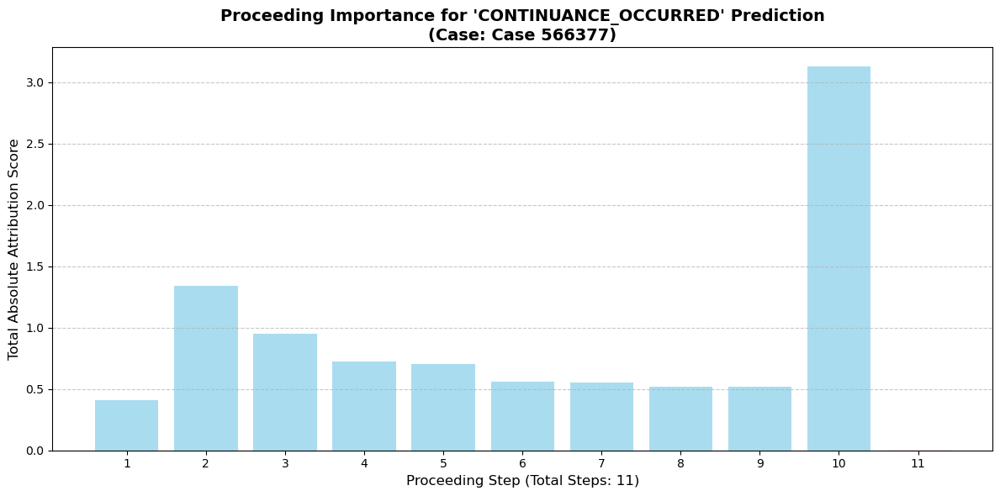

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_1.png


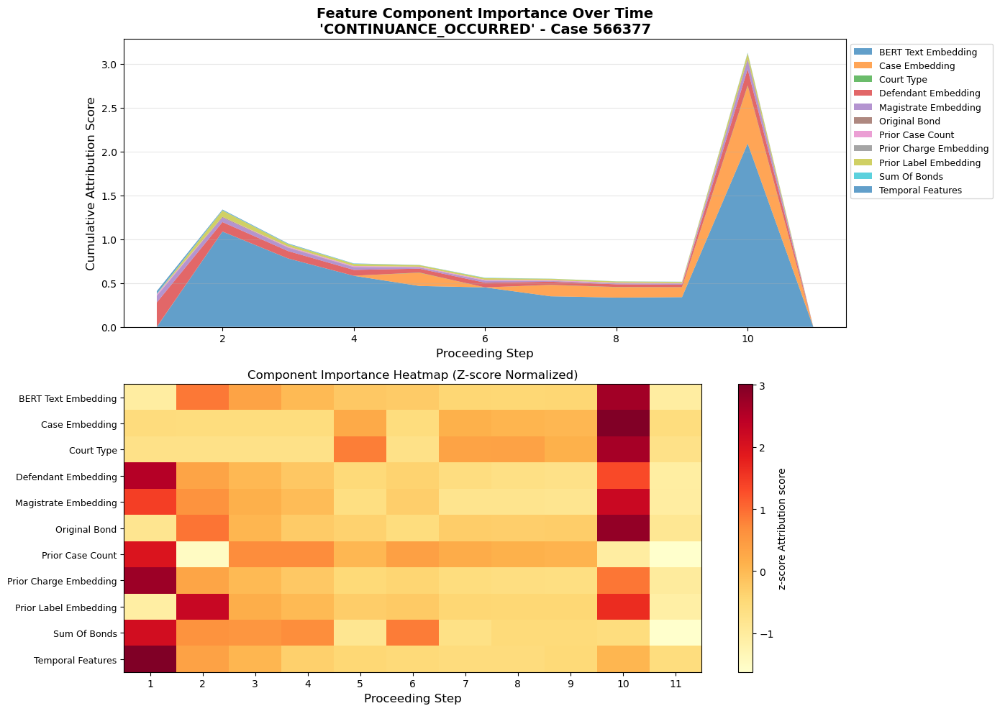


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 11 for class index 14 at proceeding index 9
   Attribution shape: torch.Size([1, 11, 1548])
   Convergence delta: 0.005069255828857422
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           6.489275          0.589934         2.098552         0.562100  CONTINUANCE_OCCURRED
1           Case_Embedding           1.172858          0.106623         0.658744         0.184590  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.910431          0.082766         0.276582         0.077504  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.352479          0.032044         0.100004         0.030448  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.261664          0.023788         0.072398         0.021567  CONTINUANCE_OCCURRED
9         Prior_Case_Count           0.082074          0.007461         0.0164

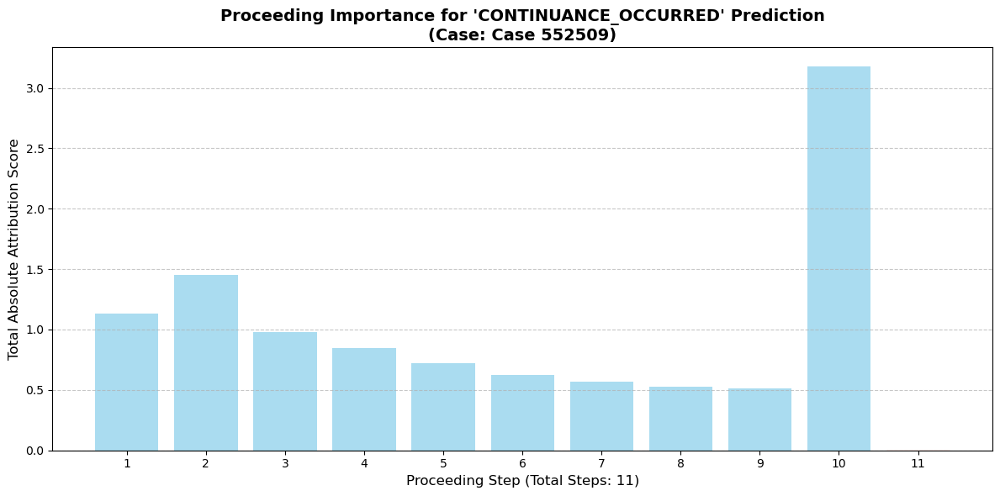

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_2.png


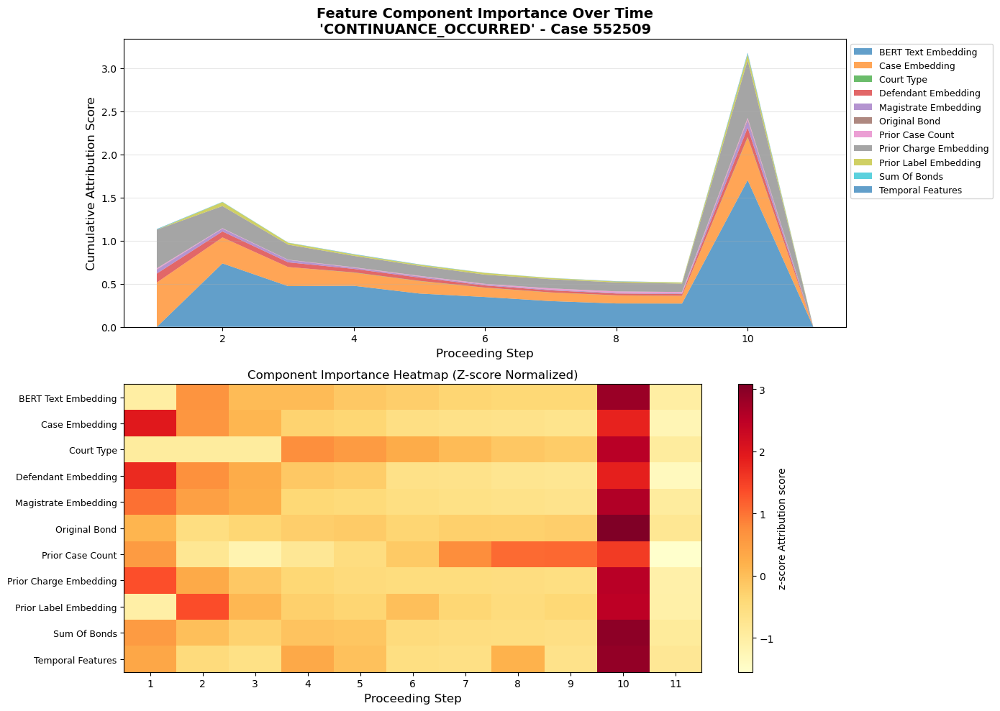


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 11 for class index 14 at proceeding index 9
   Attribution shape: torch.Size([1, 11, 1548])
   Convergence delta: 0.003661736845970154
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           4.967245          0.451568         1.704595         0.443465  CONTINUANCE_OCCURRED
1           Case_Embedding           2.218872          0.201716         0.514750         0.160524  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           2.210464          0.200951         0.669310         0.184540  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.501944          0.045631         0.108131         0.033464  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.237053          0.021550         0.080952         0.022780  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.220120          0.020011         0.0670

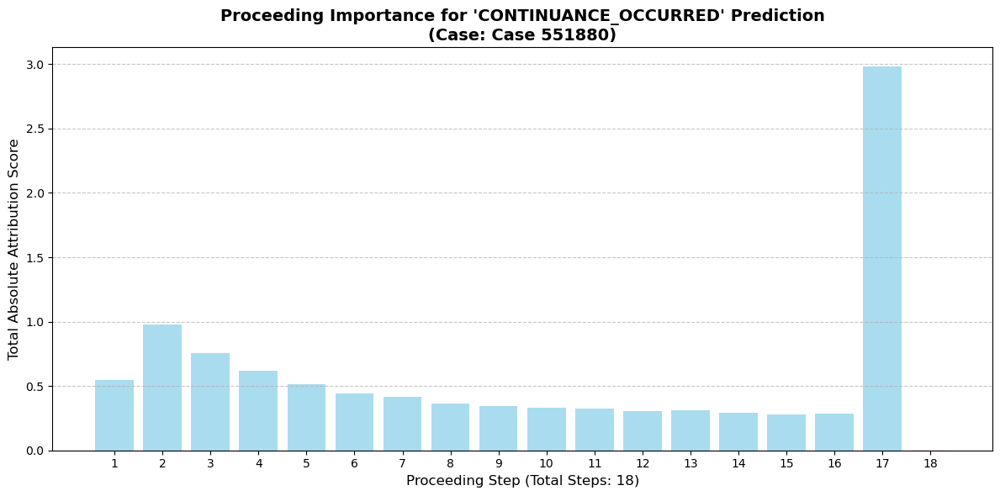

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_3.png


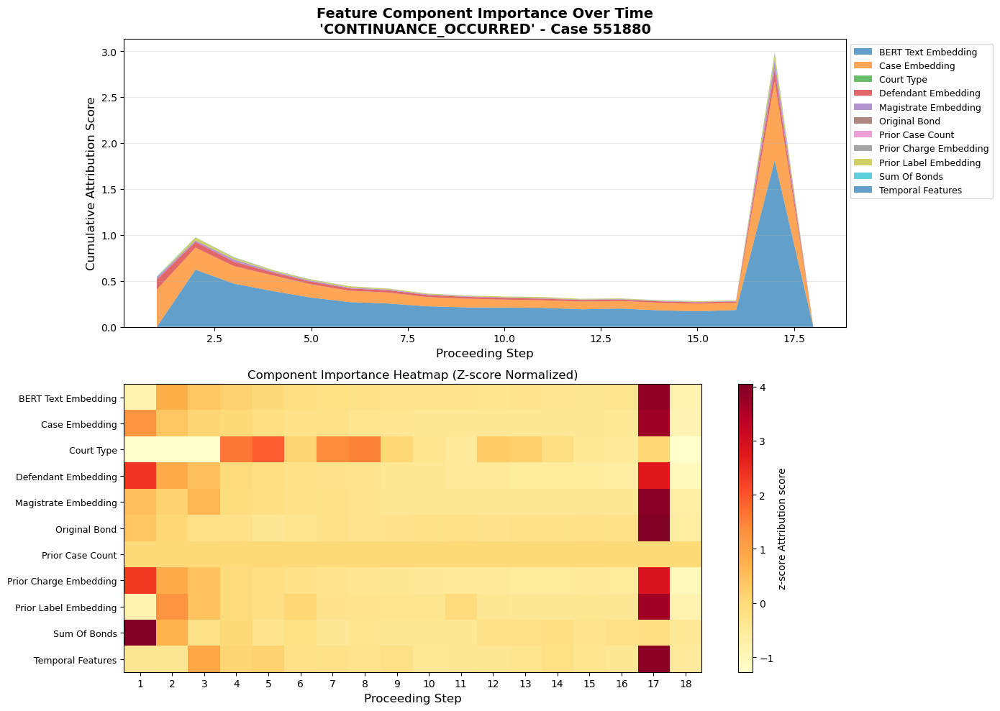


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 18 for class index 14 at proceeding index 16
   Attribution shape: torch.Size([1, 18, 1548])
   Convergence delta: -0.004506945610046387
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.907852          0.328214         1.803861         0.385067  CONTINUANCE_OCCURRED
1           Case_Embedding           3.032056          0.168448         0.869735         0.190089  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.608977          0.033832         0.123366         0.032283  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.228352          0.012686         0.068237         0.015143  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.221197          0.012289         0.083164         0.018171  CONTINUANCE_OCCURRED
7            Original_Bond           0.040790          0.002266         0.01

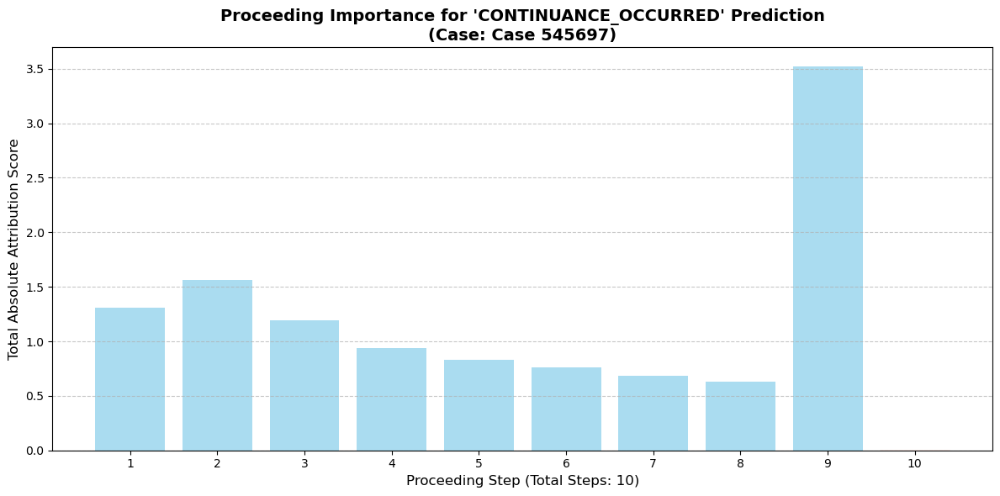

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_4.png


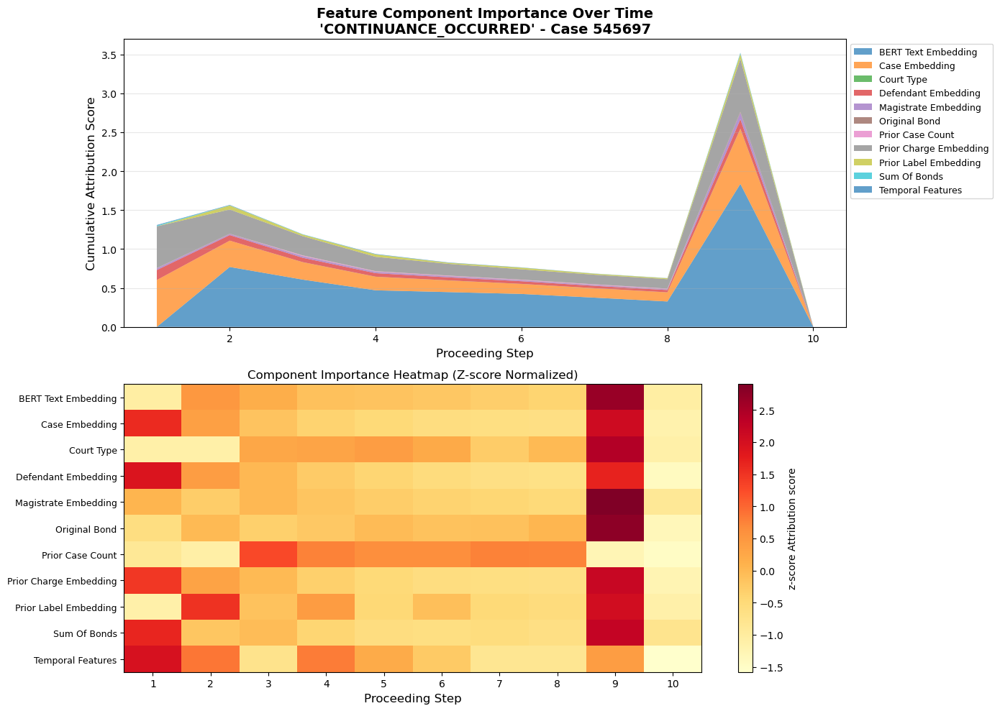


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 10 for class index 14 at proceeding index 8
   Attribution shape: torch.Size([1, 10, 1548])
   Convergence delta: 0.0003528594970703125
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.255446          0.525545         1.833323         0.491052  CONTINUANCE_OCCURRED
1           Case_Embedding           2.559412          0.255941         0.705284         0.216061  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           2.486863          0.248686         0.678125         0.197656  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.550966          0.055097         0.128100         0.038731  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.220202          0.022020         0.061565         0.019334  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.196755          0.019676         0.084

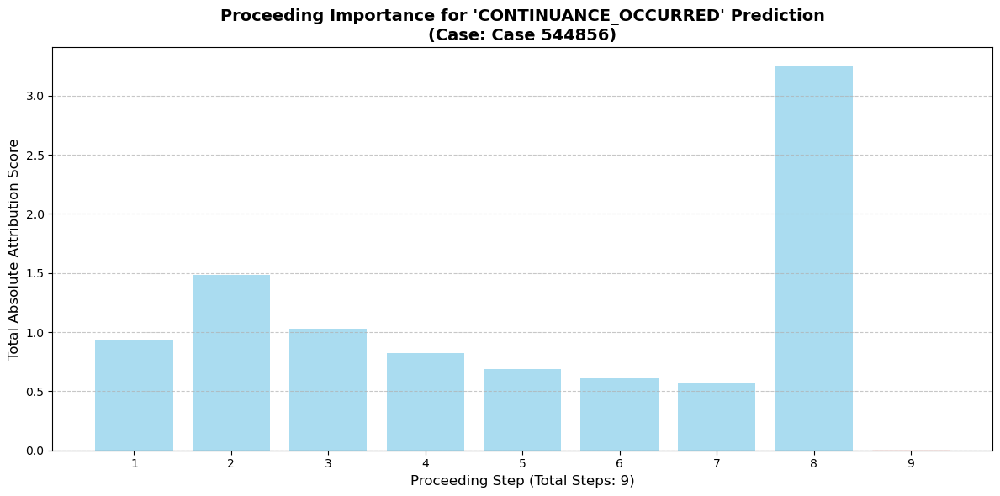

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_5.png


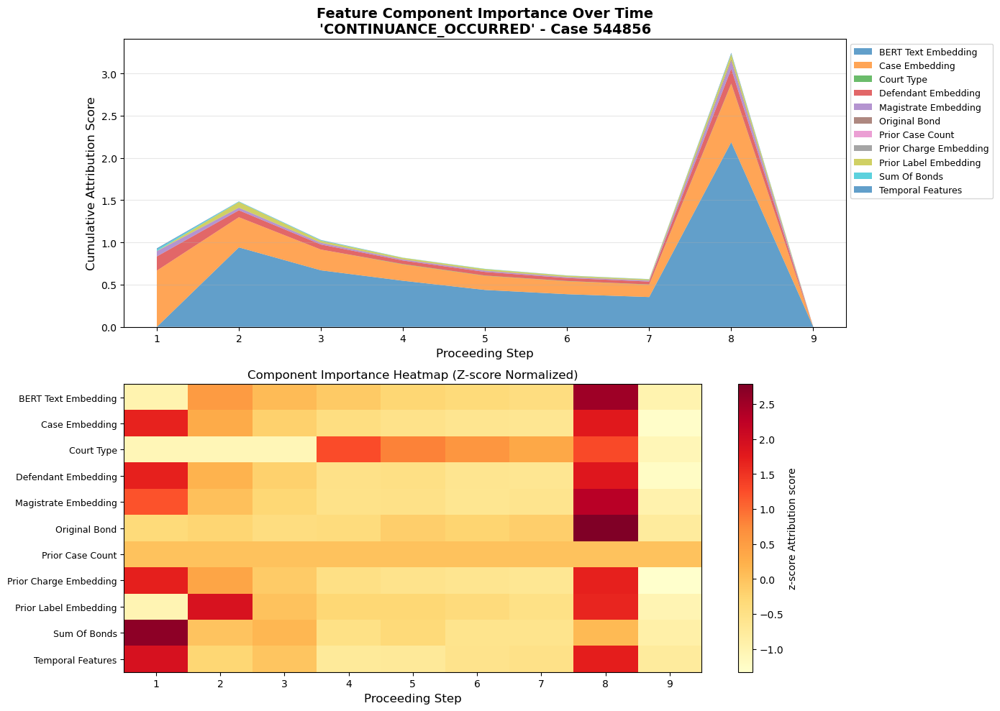


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 9 for class index 14 at proceeding index 7
   Attribution shape: torch.Size([1, 9, 1548])
   Convergence delta: -0.0018833279609680176
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.524937          0.613882         2.184051         0.622349  CONTINUANCE_OCCURRED
1           Case_Embedding           2.616257          0.290695         0.688609         0.224257  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.640013          0.071113         0.175333         0.057525  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.243866          0.027096         0.091757         0.028207  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.212478          0.023609         0.067163         0.022801  CONTINUANCE_OCCURRED
8             Sum_Of_Bonds           0.043755          0.004862         0.0191

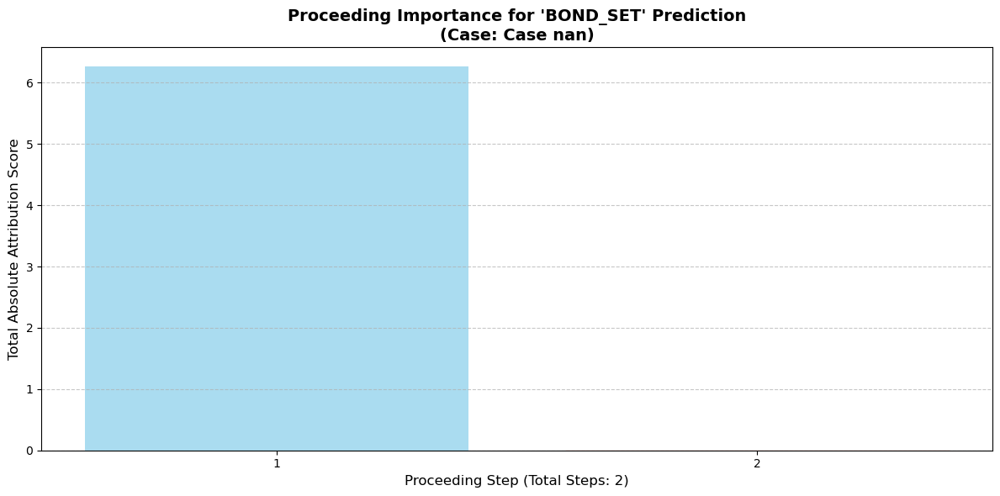

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_6.png


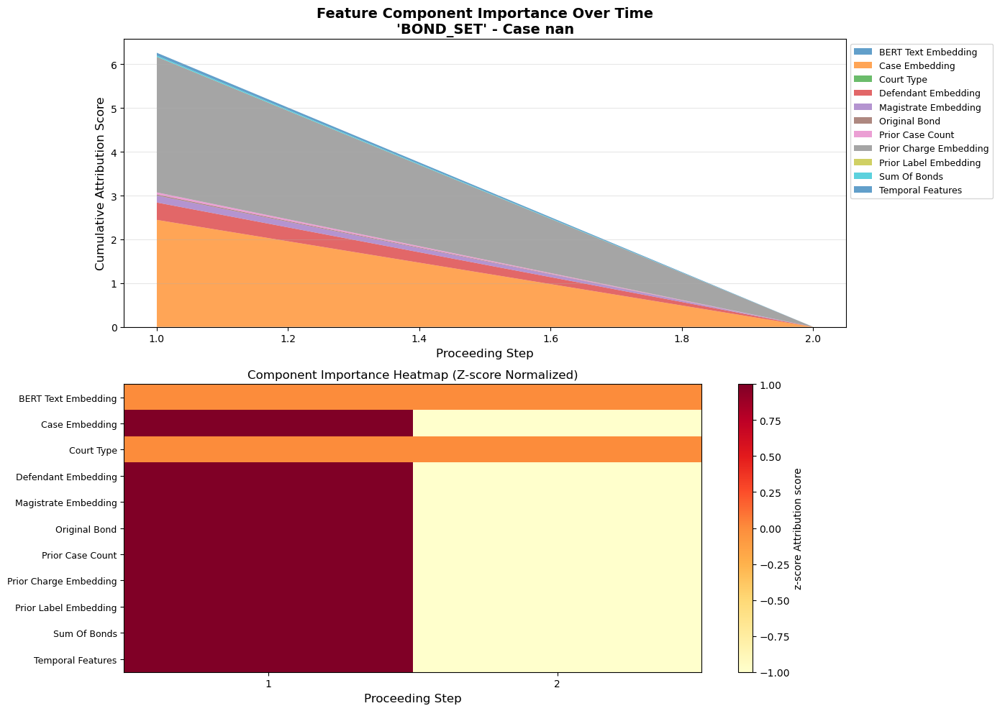


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 2 for class index 1 at proceeding index 0
   Attribution shape: torch.Size([1, 2, 1548])
   Convergence delta: -0.005086153745651245
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution Target_Label
5   Prior_Charge_Embedding           3.094160          1.547080         3.094160         1.547080     BOND_SET
1           Case_Embedding           2.451486          1.225743         2.451486         1.225743     BOND_SET
0      Defendant_Embedding           0.399720          0.199860         0.399720         0.199860     BOND_SET
3     Magistrate_Embedding           0.159634          0.079817         0.159634         0.079817     BOND_SET
10       Temporal_Features           0.064066          0.032033         0.064066         0.032033     BOND_SET
9         Prior_Case_Count           0.045615          0.022808         0.045615         0.022808     BOND_SET
8             Sum_Of_Bo

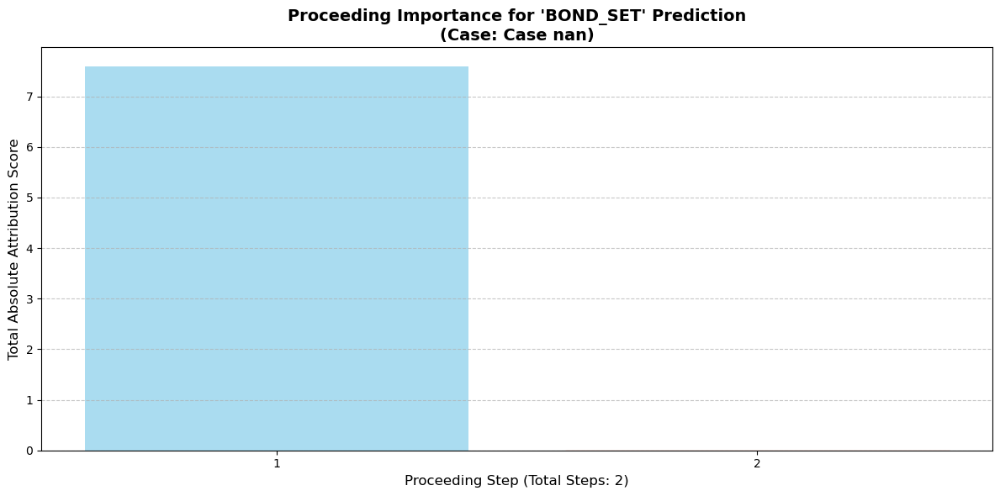

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_7.png


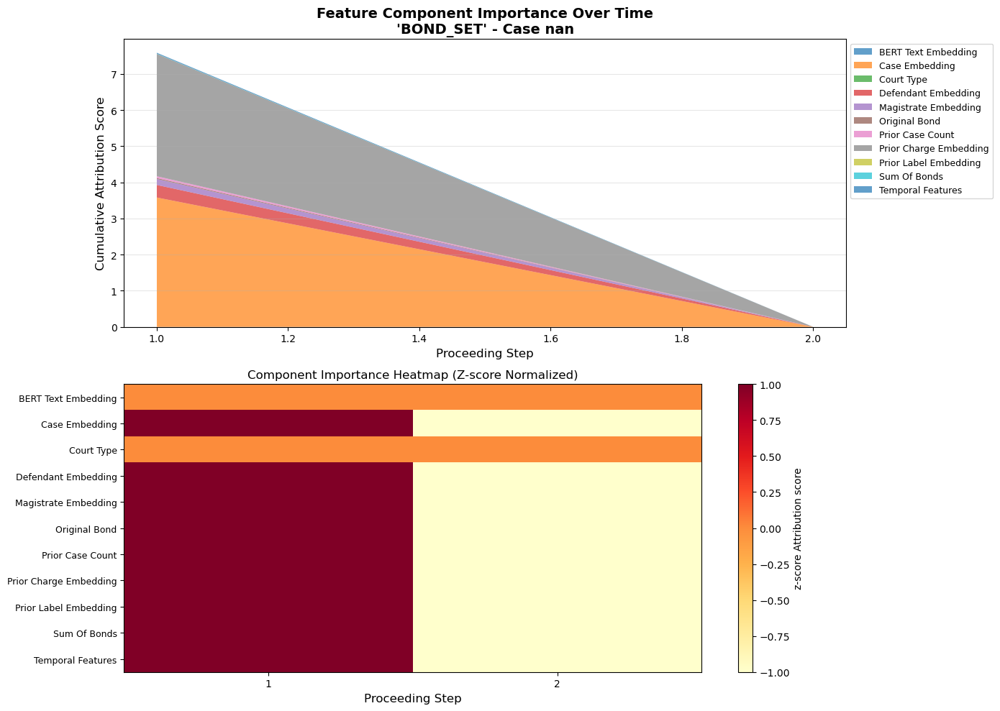


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 2 for class index 1 at proceeding index 0
   Attribution shape: torch.Size([1, 2, 1548])
   Convergence delta: 0.01054278016090393
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution Target_Label
1           Case_Embedding           3.589770          1.794885         3.589770         1.794885     BOND_SET
5   Prior_Charge_Embedding           3.383580          1.691790         3.383580         1.691790     BOND_SET
0      Defendant_Embedding           0.345737          0.172869         0.345737         0.172869     BOND_SET
3     Magistrate_Embedding           0.165977          0.082988         0.165977         0.082988     BOND_SET
9         Prior_Case_Count           0.049550          0.024775         0.049550         0.024775     BOND_SET
7            Original_Bond           0.026678          0.013339         0.026678         0.013339     BOND_SET
10       Temporal_Feature

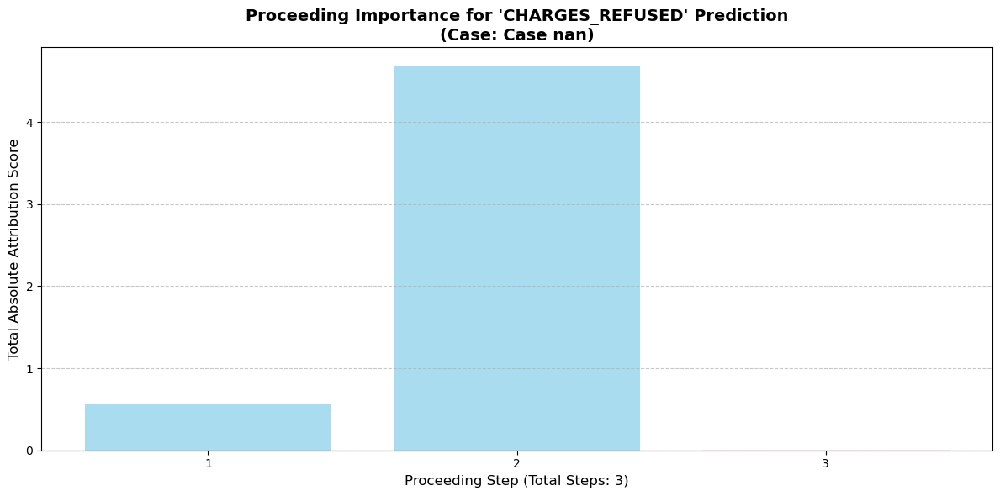

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_8.png


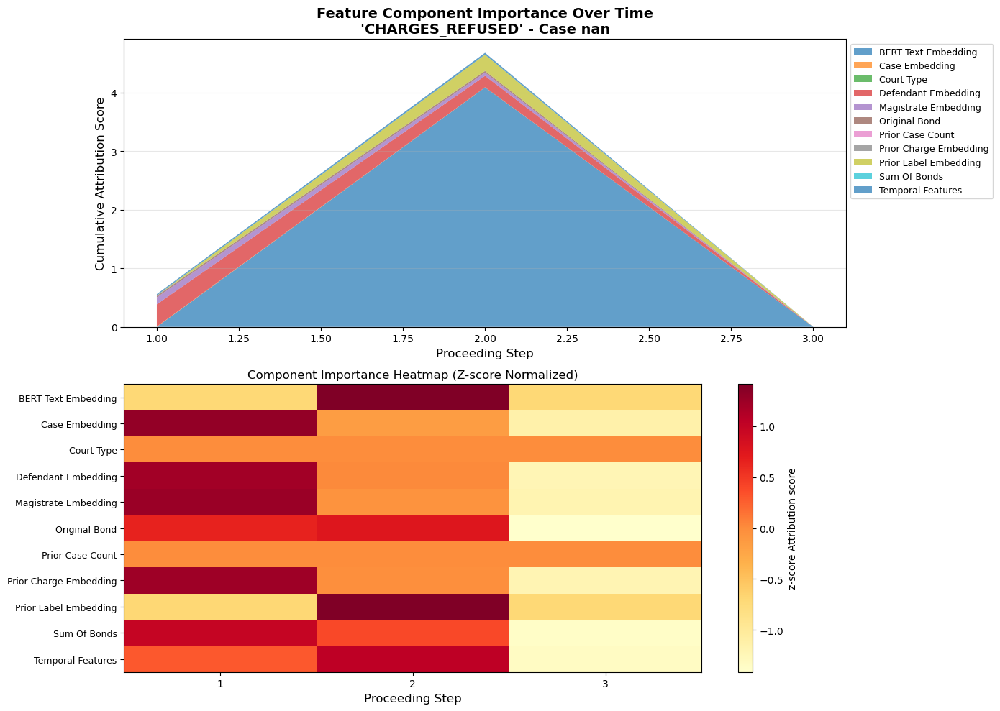


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 3 for class index 8 at proceeding index 1
   Attribution shape: torch.Size([1, 3, 1548])
   Convergence delta: -0.00503915548324585
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution     Target_Label
2      BERT_Text_Embedding           4.089400          1.363133         4.089400         1.927762  CHARGES_REFUSED
0      Defendant_Embedding           0.573291          0.191097         0.378157         0.154408  CHARGES_REFUSED
4    Prior_Label_Embedding           0.276755          0.092252         0.275904         0.129862  CHARGES_REFUSED
3     Magistrate_Embedding           0.177080          0.059027         0.121311         0.049579  CHARGES_REFUSED
10       Temporal_Features           0.053471          0.017824         0.031952         0.013304  CHARGES_REFUSED
7            Original_Bond           0.052349          0.017450         0.026820         0.012350  CHARGES_REFU

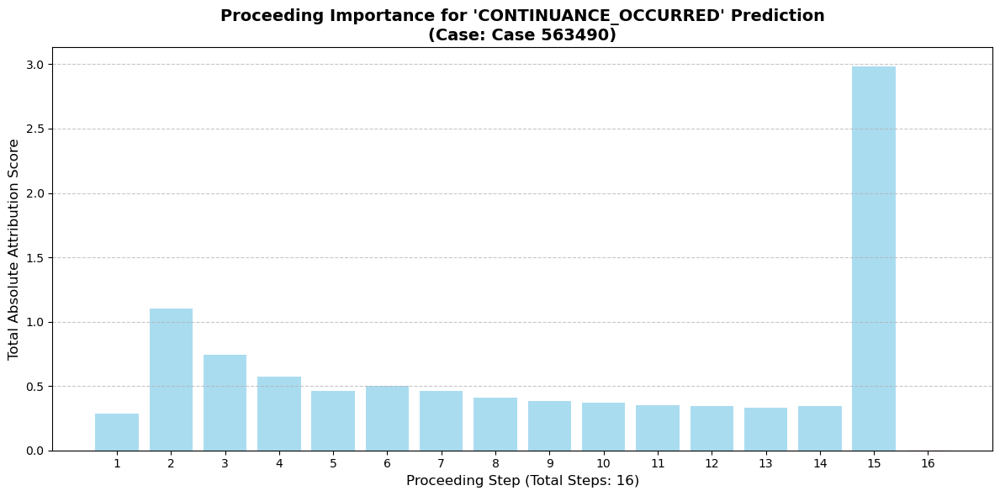

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_9.png


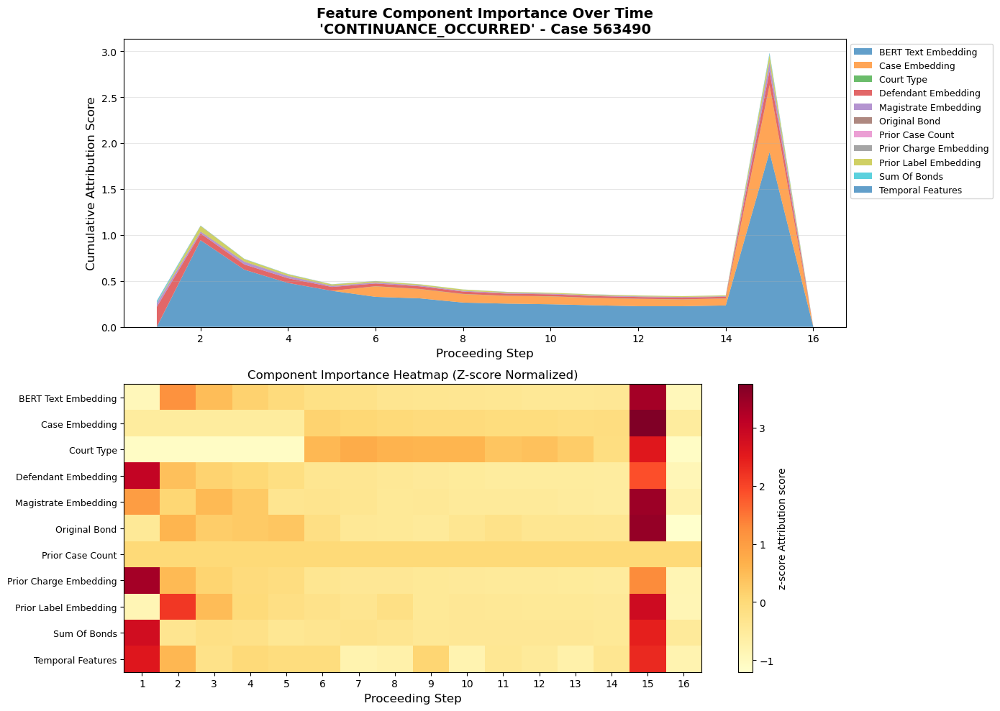


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 16 for class index 14 at proceeding index 14
   Attribution shape: torch.Size([1, 16, 1548])
   Convergence delta: 0.003519803285598755
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           6.660460          0.416279         1.904595         0.441795  CONTINUANCE_OCCURRED
1           Case_Embedding           1.509769          0.094361         0.724652         0.168082  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.797406          0.049838         0.216681         0.055088  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.279846          0.017490         0.072902         0.019536  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.261955          0.016372         0.090488         0.021428  CONTINUANCE_OCCURRED
7            Original_Bond           0.046819          0.002926         0.011

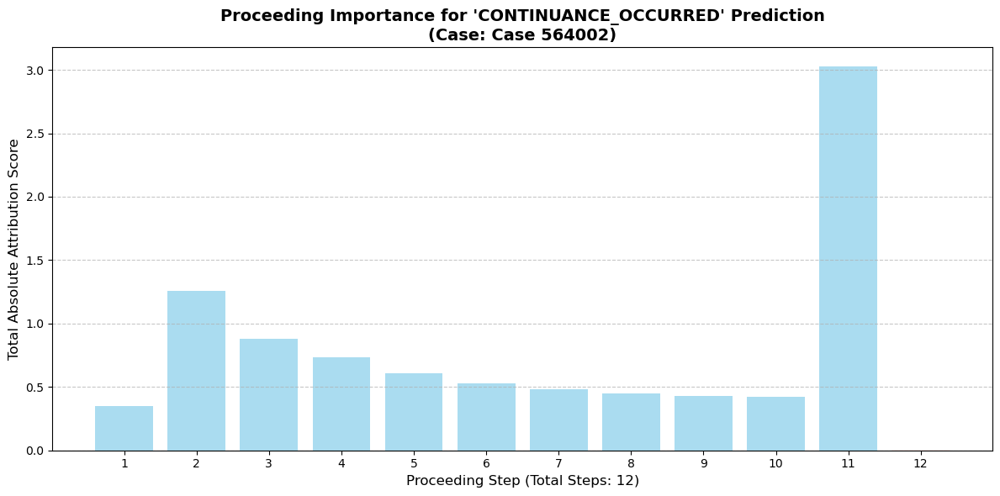

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_10.png


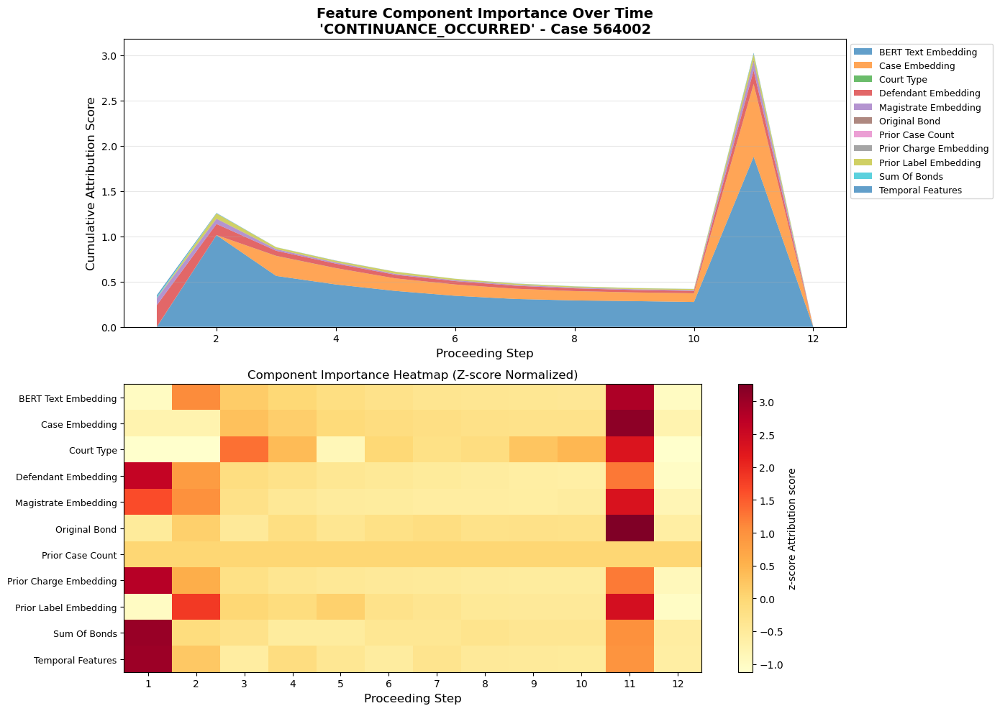


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 12 for class index 14 at proceeding index 10
   Attribution shape: torch.Size([1, 12, 1548])
   Convergence delta: 0.003266572952270508
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.829550          0.485796         1.881470         0.490437  CONTINUANCE_OCCURRED
1           Case_Embedding           1.875567          0.156297         0.802393         0.205704  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.804799          0.067067         0.236790         0.065179  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.304532          0.025378         0.095191         0.030120  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.244219          0.020352         0.067377         0.019723  CONTINUANCE_OCCURRED
10       Temporal_Features           0.038431          0.003203         0.018

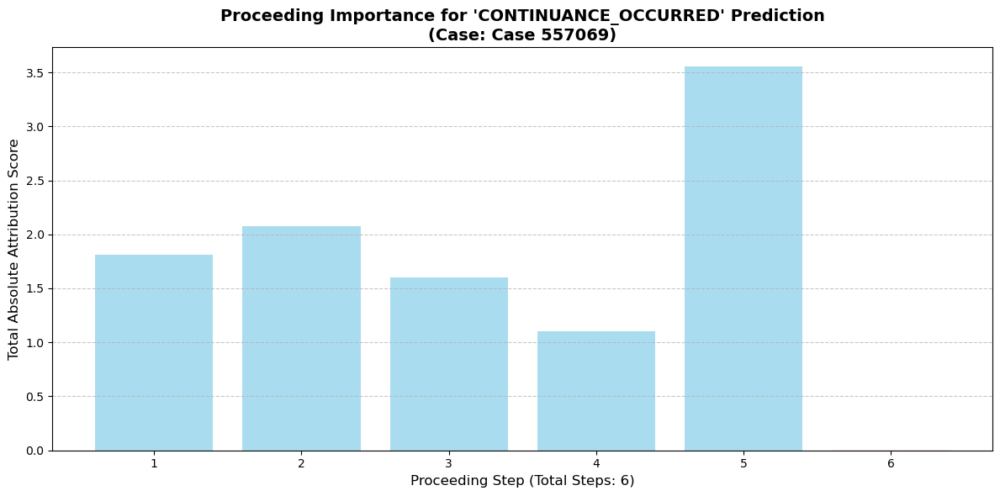

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_11.png


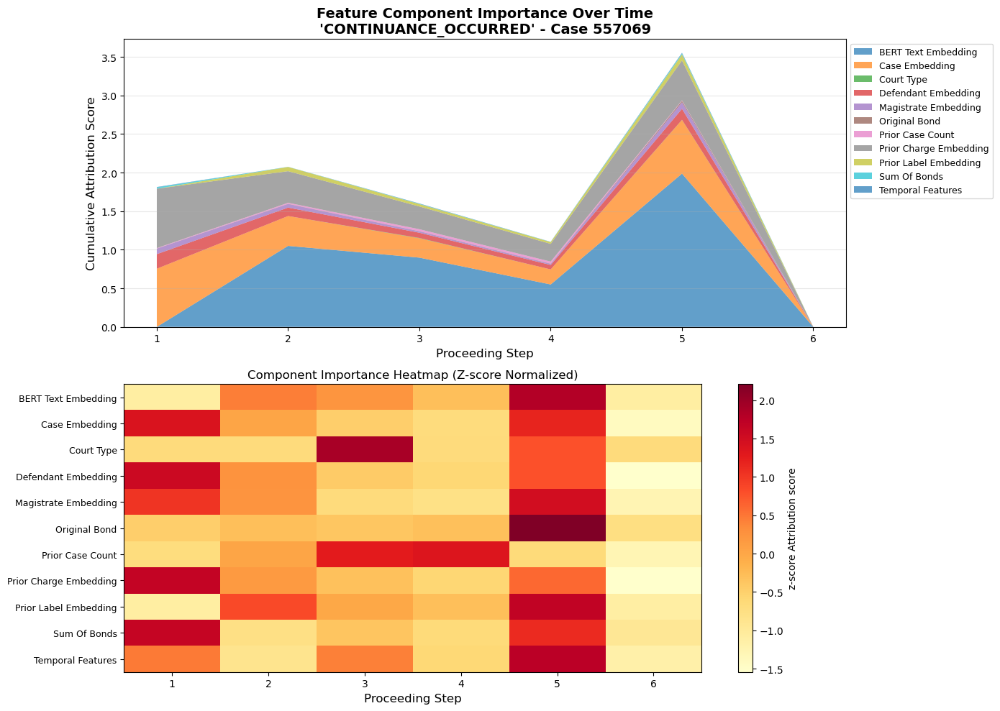


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 6 for class index 14 at proceeding index 4
   Attribution shape: torch.Size([1, 6, 1548])
   Convergence delta: 0.008873462677001953
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           4.485019          0.747503         1.986421         0.683862  CONTINUANCE_OCCURRED
1           Case_Embedding           2.286005          0.381001         0.753533         0.268897  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           2.219549          0.369925         0.770432         0.240031  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.564735          0.094123         0.188336         0.060853  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.236416          0.039403         0.084677         0.030800  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.188289          0.031381         0.078913

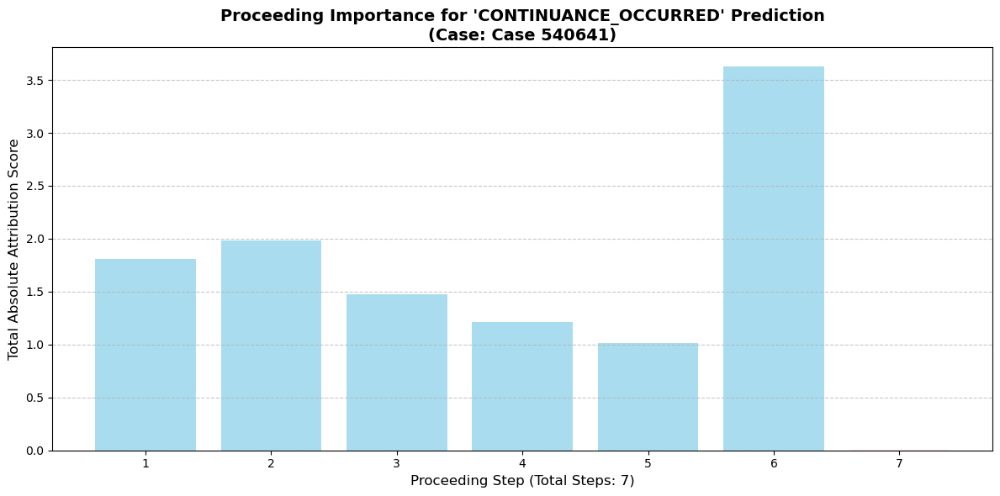

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_12.png


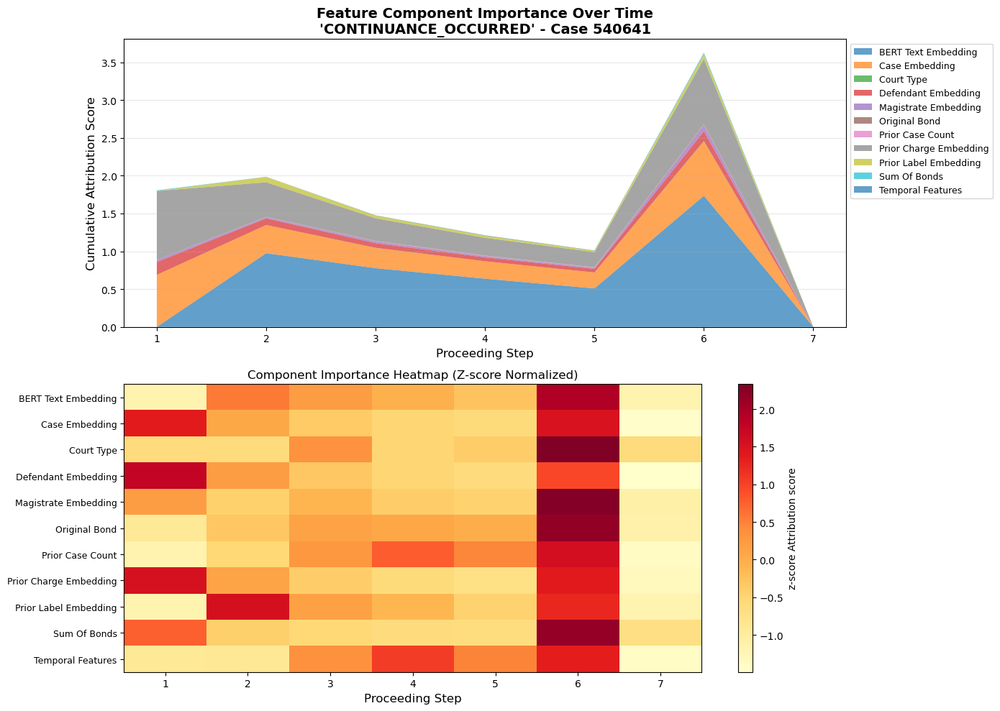


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 7 for class index 14 at proceeding index 5
   Attribution shape: torch.Size([1, 7, 1548])
   Convergence delta: 0.014572054147720337
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           4.632355          0.661765         1.735602         0.555888  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           2.965150          0.423593         0.907890         0.318366  CONTINUANCE_OCCURRED
1           Case_Embedding           2.486743          0.355249         0.719297         0.243110  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.545103          0.077872         0.169431         0.052282  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.214325          0.030618         0.070373         0.025704  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.165744          0.023678         0.073241

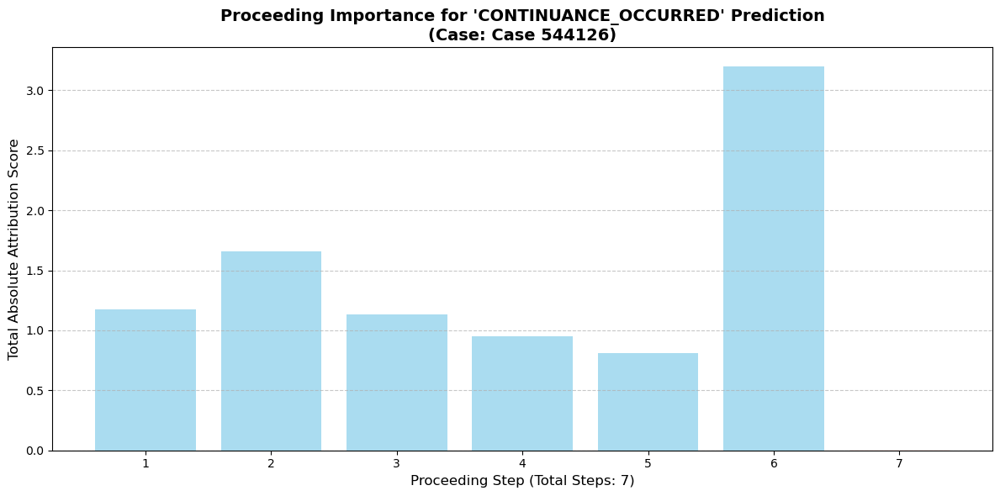

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_13.png


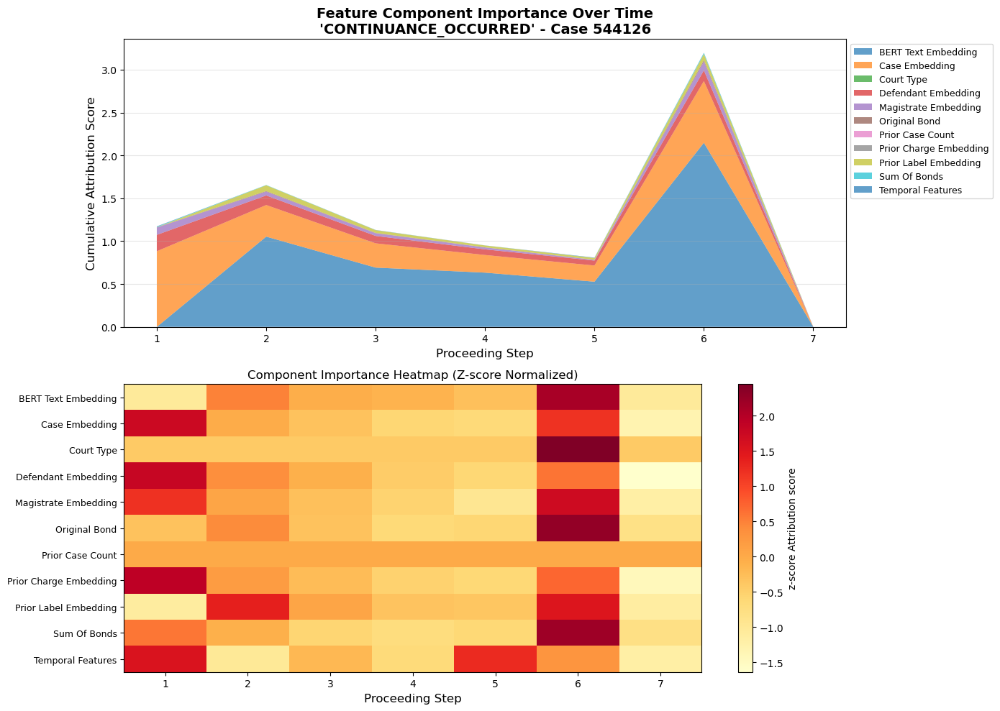


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 7 for class index 14 at proceeding index 5
   Attribution shape: torch.Size([1, 7, 1548])
   Convergence delta: 0.0026559829711914062
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.057155          0.722451         2.150814         0.680332  CONTINUANCE_OCCURRED
1           Case_Embedding           2.652579          0.378940         0.883677         0.290710  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.636242          0.090892         0.190841         0.055514  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.294469          0.042067         0.101934         0.035594  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.214834          0.030691         0.071876         0.027066  CONTINUANCE_OCCURRED
7            Original_Bond           0.027270          0.003896         0.01462

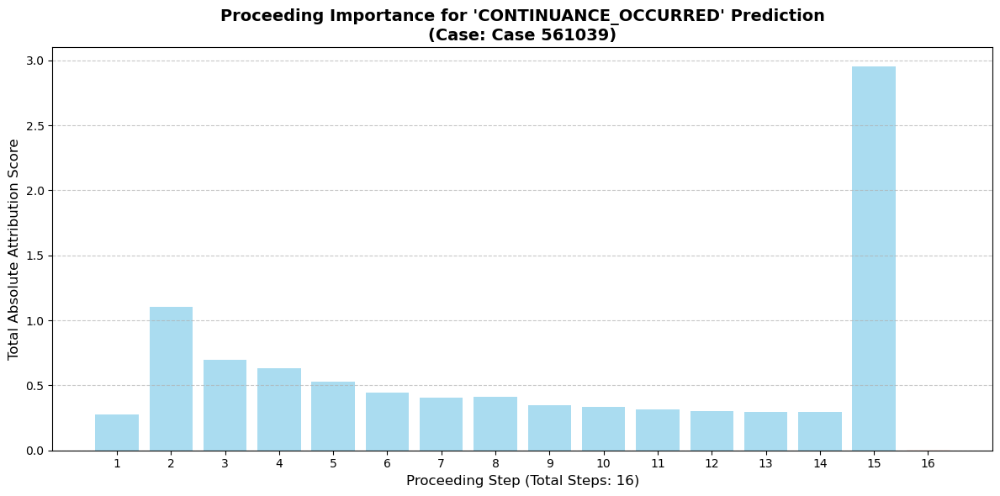

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_14.png


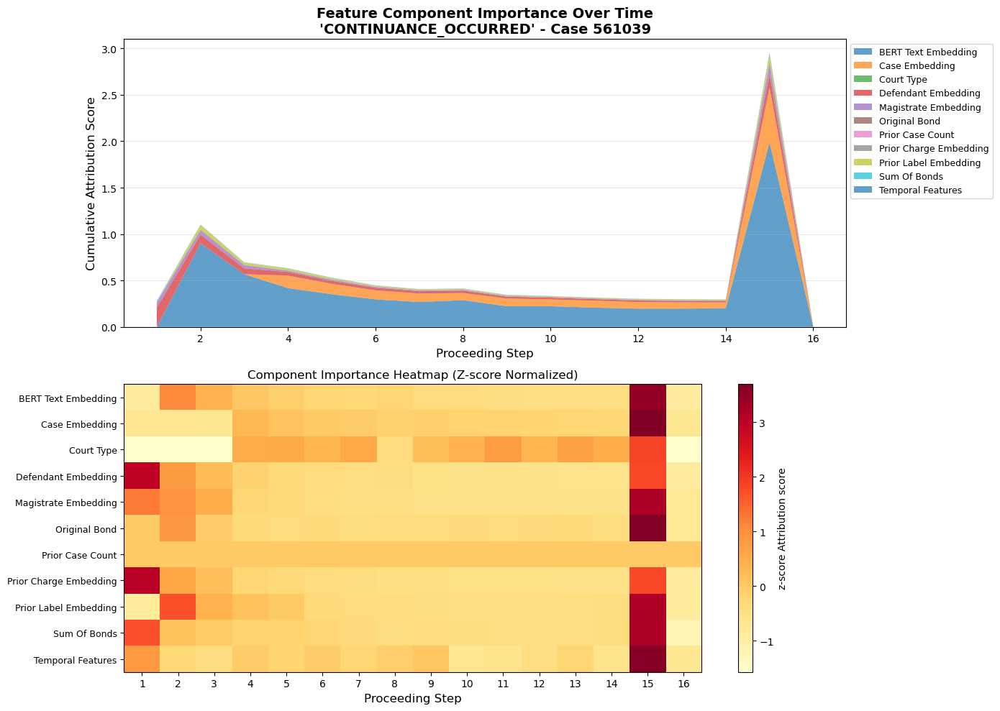


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 16 for class index 14 at proceeding index 14
   Attribution shape: torch.Size([1, 16, 1548])
   Convergence delta: 0.007748156785964966
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           6.332778          0.395799         1.992256         0.460943  CONTINUANCE_OCCURRED
1           Case_Embedding           1.531449          0.095716         0.593292         0.134513  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.756917          0.047307         0.208633         0.054221  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.318456          0.019903         0.105343         0.026792  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.276690          0.017293         0.081793         0.020341  CONTINUANCE_OCCURRED
7            Original_Bond           0.051675          0.003230         0.018

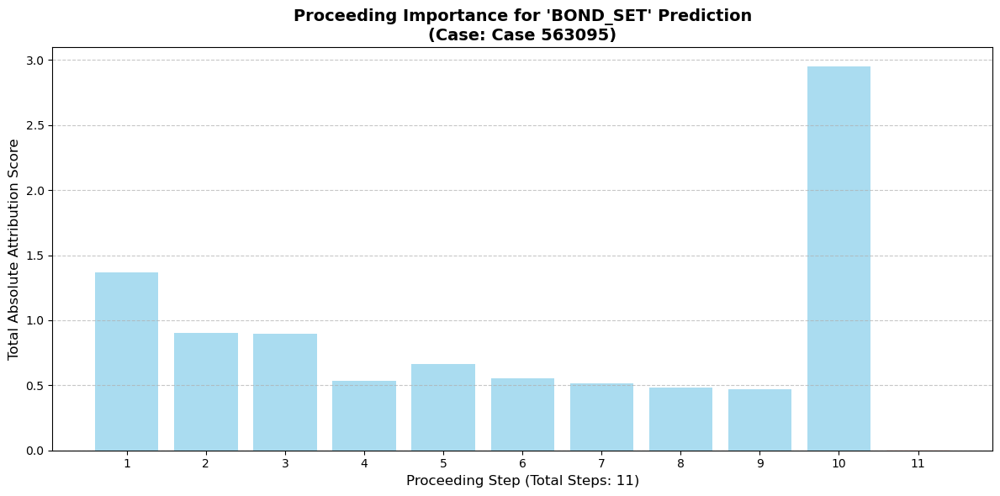

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_15.png


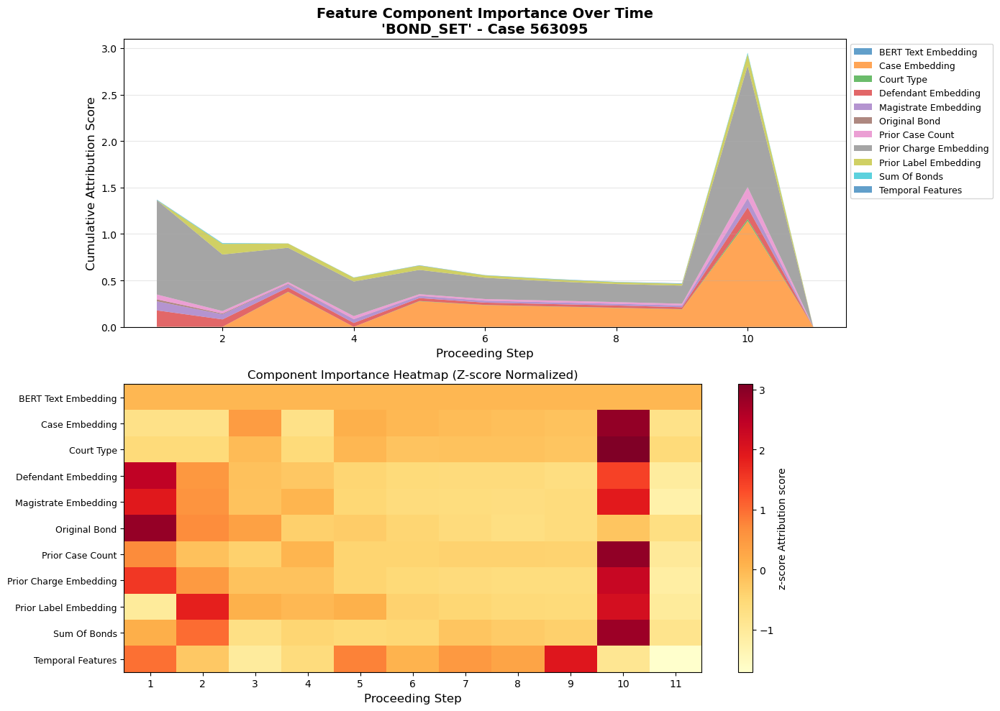


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 11 for class index 1 at proceeding index 9
   Attribution shape: torch.Size([1, 11, 1548])
   Convergence delta: -0.008372306823730469
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution Target_Label
5   Prior_Charge_Embedding           4.754554          0.432232         1.301463         0.375946     BOND_SET
1           Case_Embedding           2.639611          0.239965         1.140753         0.311002     BOND_SET
0      Defendant_Embedding           0.597853          0.054350         0.176373         0.050679     BOND_SET
4    Prior_Label_Embedding           0.460194          0.041836         0.126025         0.039932     BOND_SET
3     Magistrate_Embedding           0.422231          0.038385         0.097417         0.030852     BOND_SET
9         Prior_Case_Count           0.336960          0.030633         0.119225         0.030513     BOND_SET
7            Original

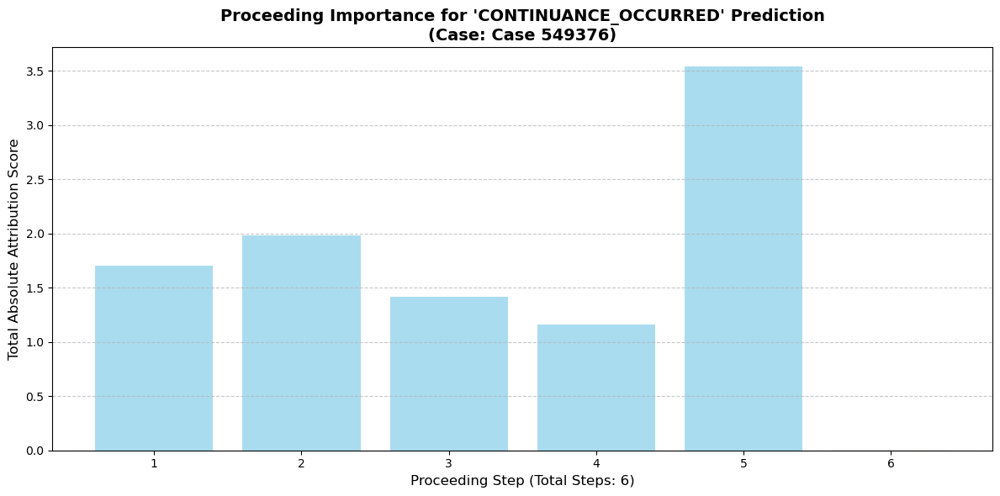

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_16.png


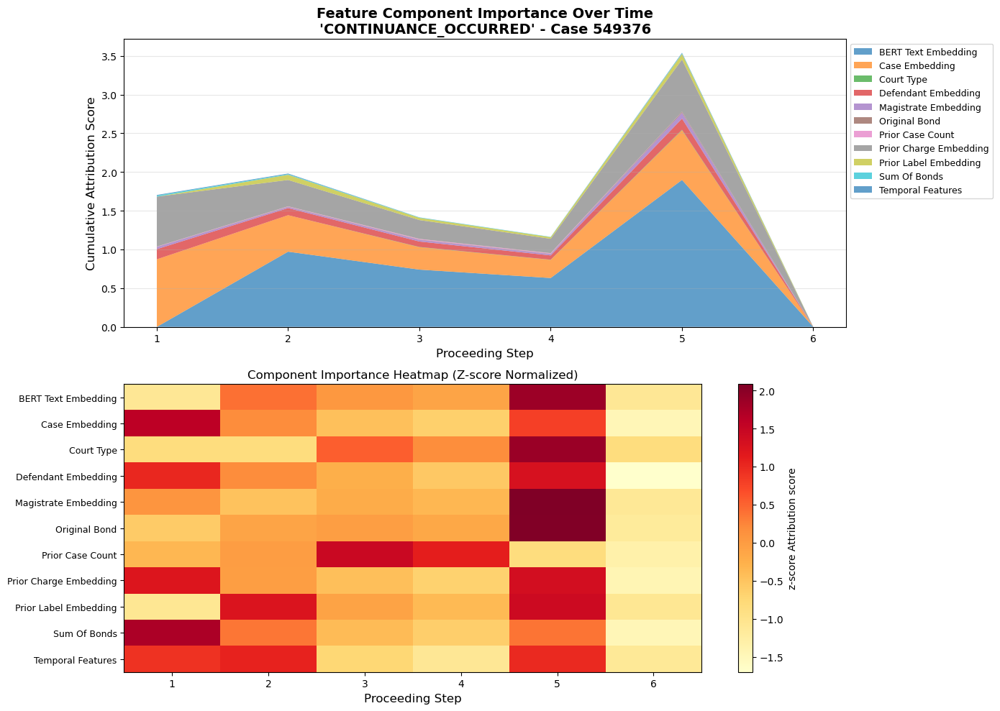


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 6 for class index 14 at proceeding index 4
   Attribution shape: torch.Size([1, 6, 1548])
   Convergence delta: -0.011258512735366821
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           4.238491          0.706415         1.895443         0.643959  CONTINUANCE_OCCURRED
1           Case_Embedding           2.508726          0.418121         0.871518         0.284073  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           2.084352          0.347392         0.670568         0.241364  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.491839          0.081973         0.143614         0.048089  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.188597          0.031433         0.072159         0.028872  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.156050          0.026008         0.07440

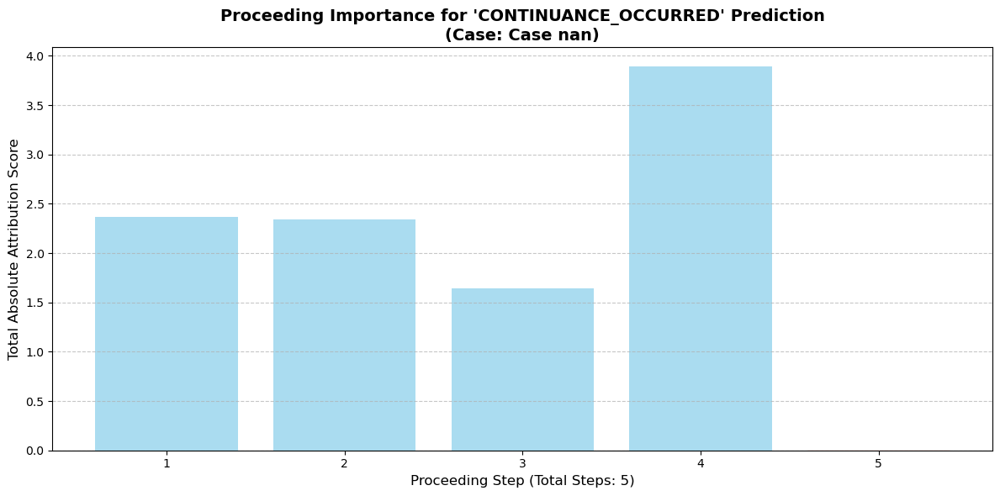

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_17.png


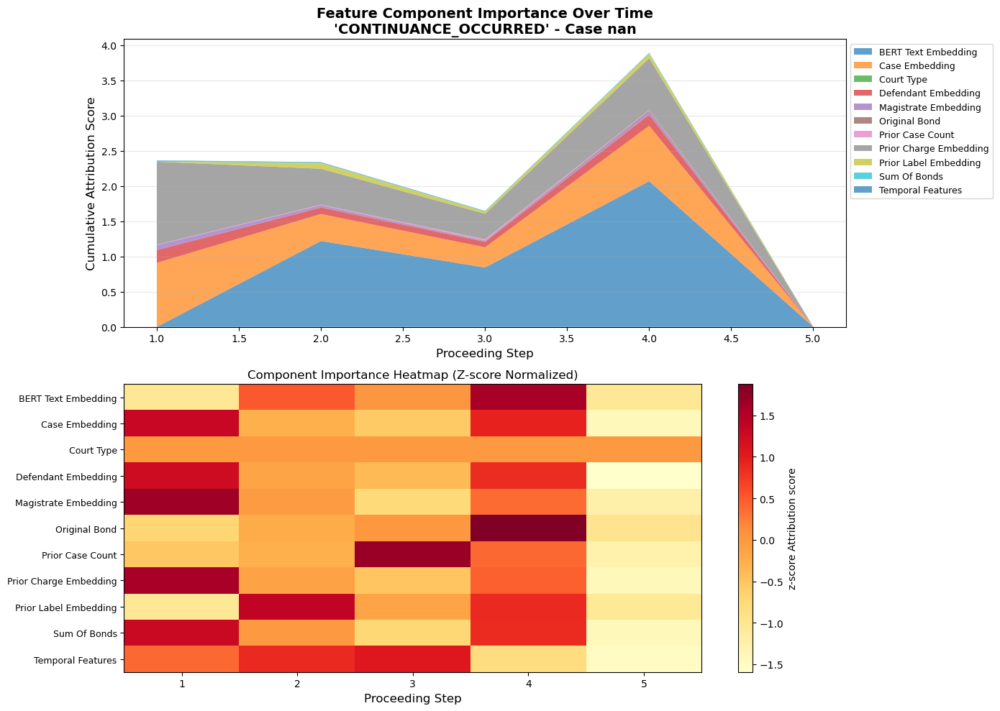


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 5 for class index 14 at proceeding index 3
   Attribution shape: torch.Size([1, 5, 1548])
   Convergence delta: 0.001095592975616455
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           4.131392          0.826278         2.073141         0.784013  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           2.787856          0.557571         1.178468         0.392318  CONTINUANCE_OCCURRED
1           Case_Embedding           2.367988          0.473598         0.909008         0.334157  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.504702          0.100940         0.178966         0.063253  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.178330          0.035666         0.081968         0.033345  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.149664          0.029933         0.069878

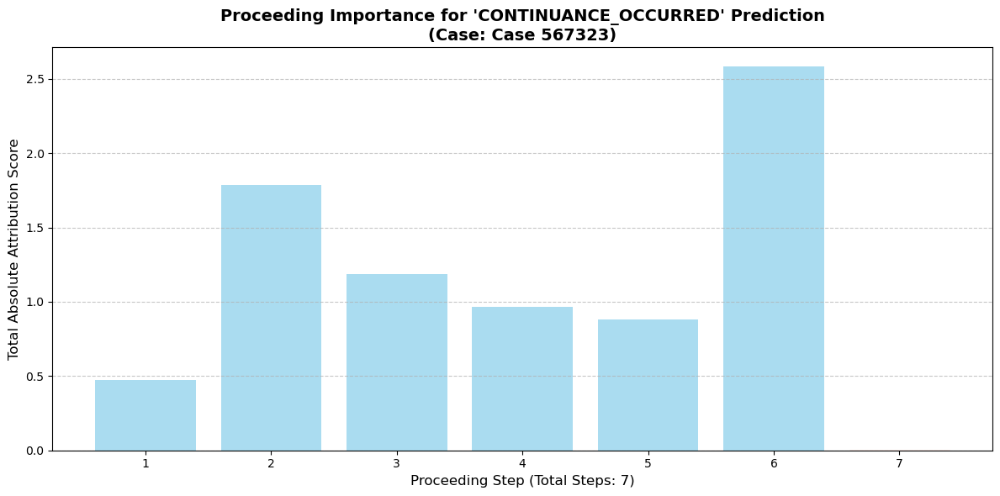

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_18.png


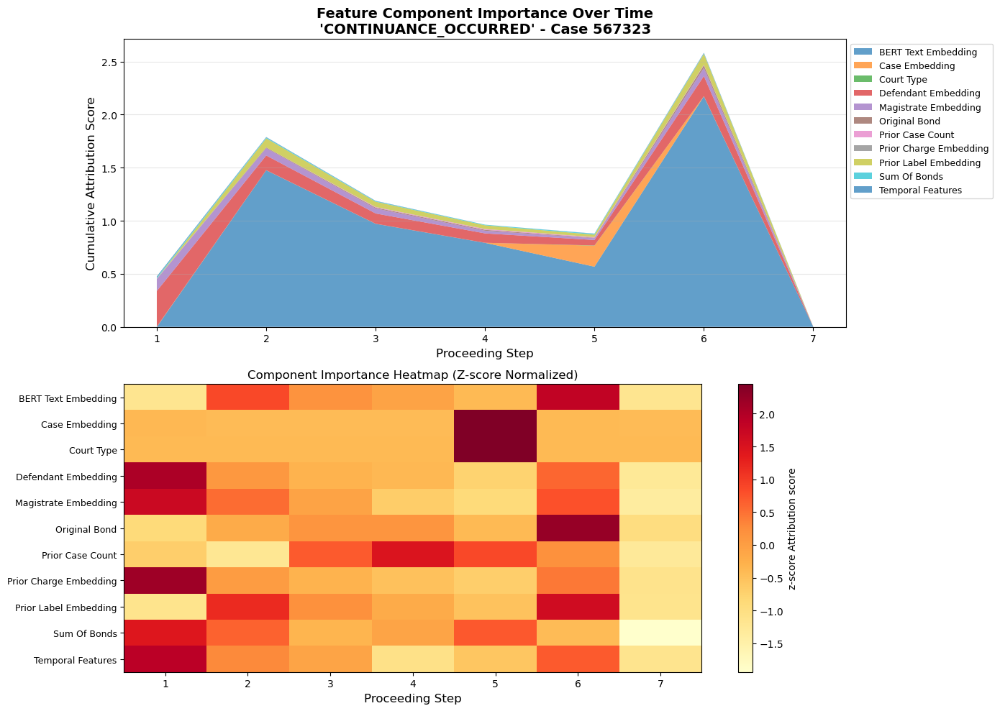


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 7 for class index 14 at proceeding index 5
   Attribution shape: torch.Size([1, 7, 1548])
   Convergence delta: 0.002248987555503845
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.979228          0.854175         2.171940         0.725667  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.900950          0.128707         0.336950         0.101660  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.350724          0.050103         0.112741         0.036550  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.294489          0.042070         0.102174         0.036650  CONTINUANCE_OCCURRED
1           Case_Embedding           0.205436          0.029348         0.198664         0.069129  CONTINUANCE_OCCURRED
7            Original_Bond           0.049167          0.007024         0.023142

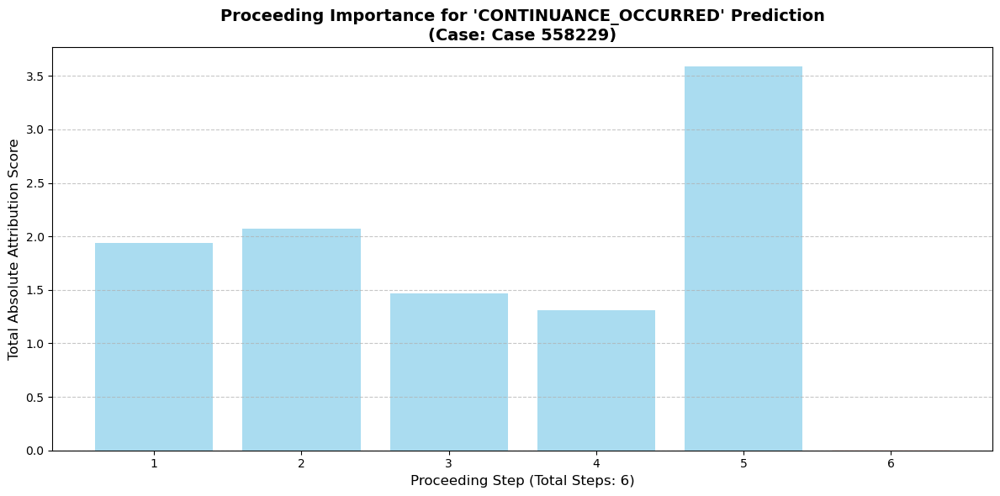

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_19.png


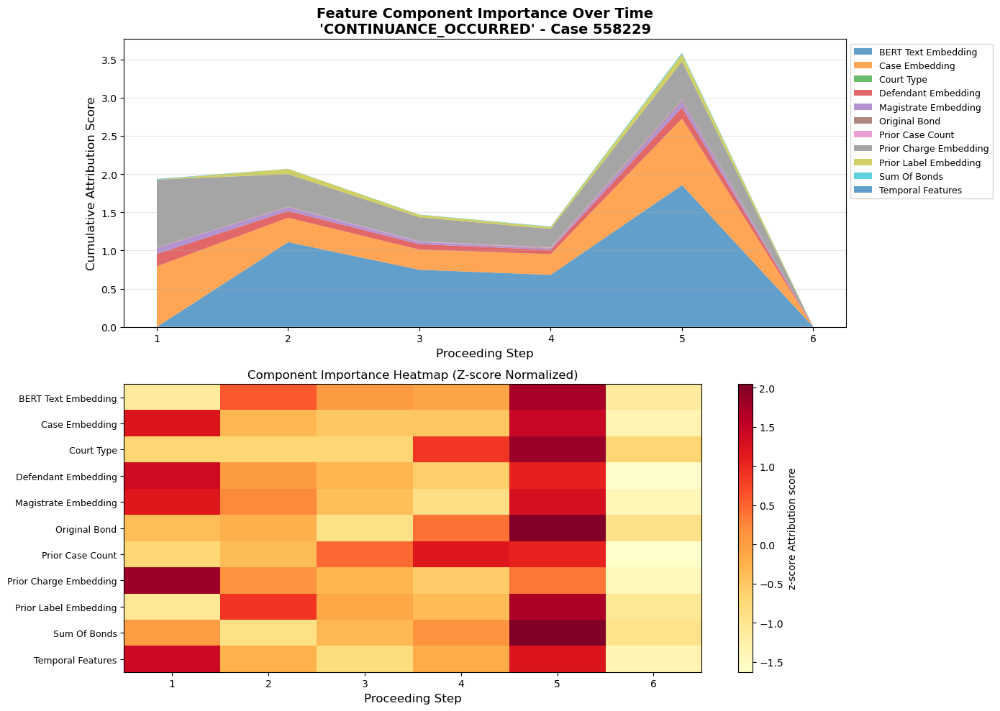


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 6 for class index 14 at proceeding index 4
   Attribution shape: torch.Size([1, 6, 1548])
   Convergence delta: -0.006469428539276123
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           4.393901          0.732317         1.854441         0.642391  CONTINUANCE_OCCURRED
1           Case_Embedding           2.516914          0.419486         0.868778         0.309715  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           2.365962          0.394327         0.891141         0.271924  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.517897          0.086316         0.160249         0.054041  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.254289          0.042381         0.081557         0.029858  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.223349          0.037225         0.09753

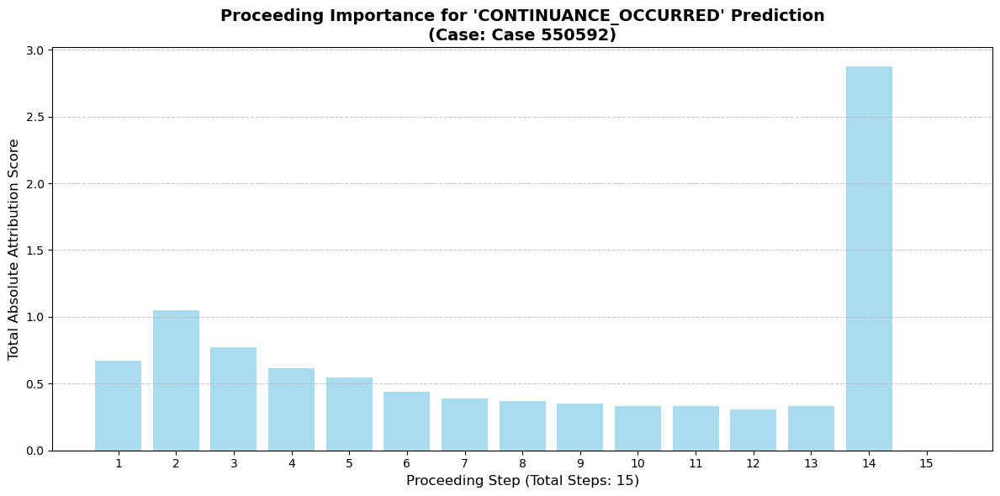

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_20.png


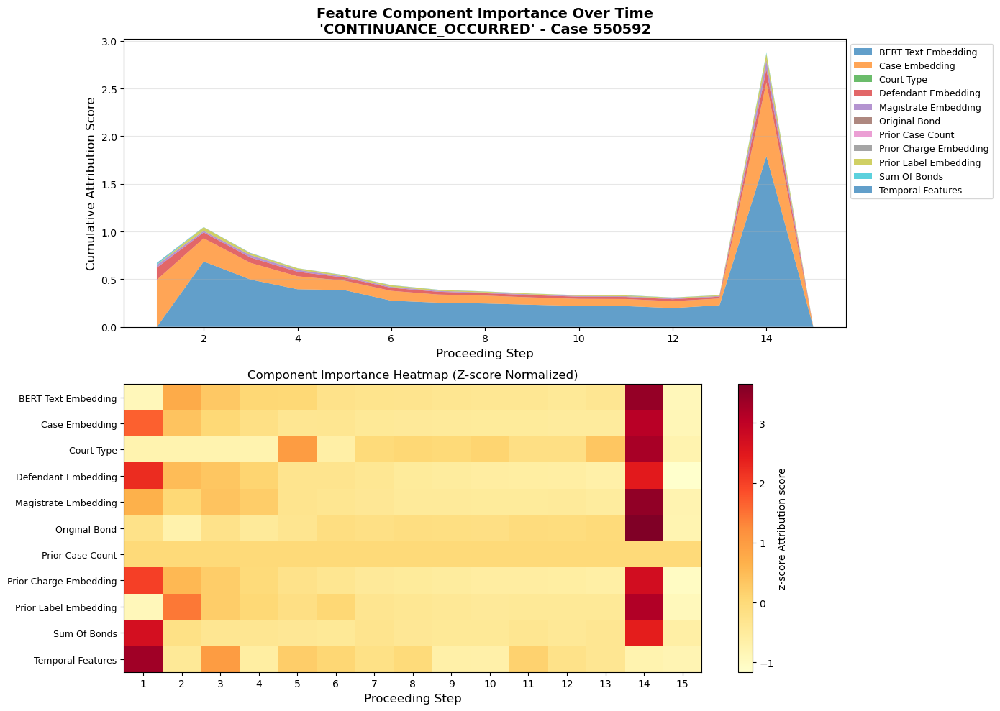


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 15 for class index 14 at proceeding index 13
   Attribution shape: torch.Size([1, 15, 1548])
   Convergence delta: -0.006404876708984375
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.617486          0.374499         1.785200         0.411959  CONTINUANCE_OCCURRED
1           Case_Embedding           2.553988          0.170266         0.770003         0.195269  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.651630          0.043442         0.135602         0.037527  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.229033          0.015269         0.084399         0.019930  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.221976          0.014798         0.065401         0.016049  CONTINUANCE_OCCURRED
7            Original_Bond           0.040142          0.002676         0.01

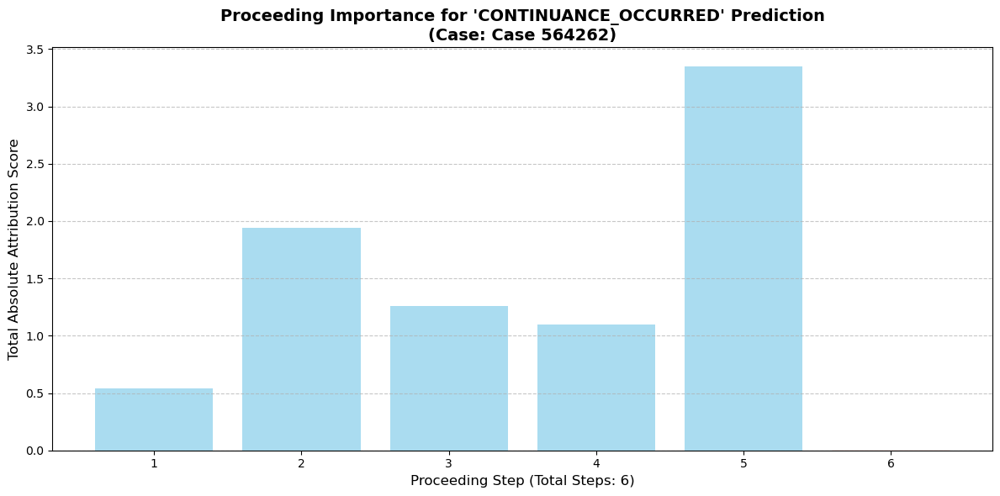

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_21.png


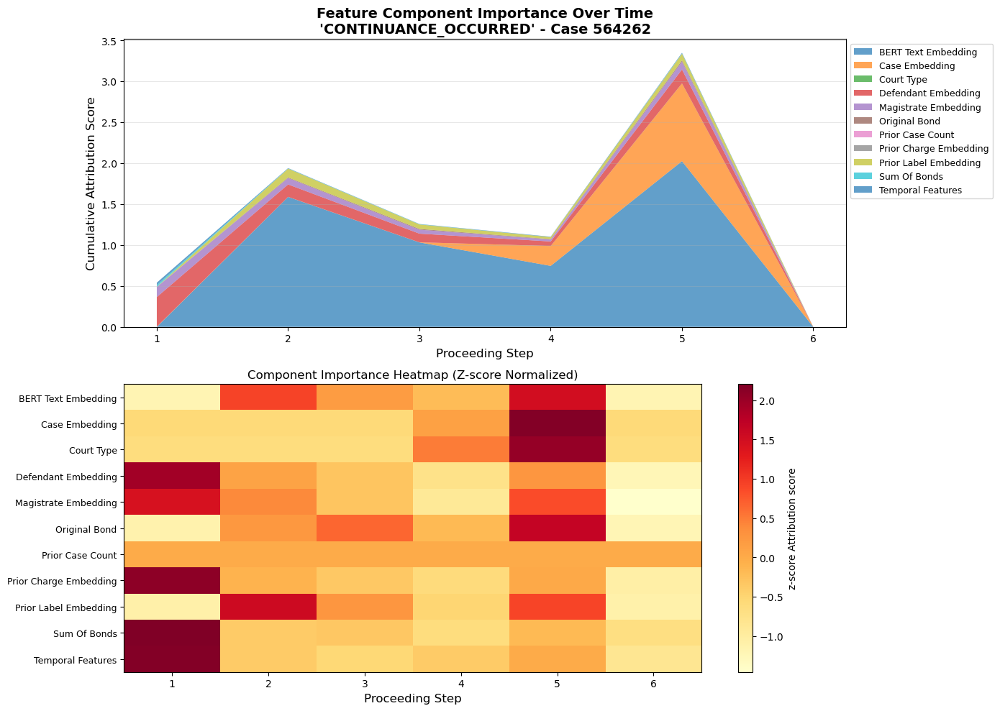


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 6 for class index 14 at proceeding index 4
   Attribution shape: torch.Size([1, 6, 1548])
   Convergence delta: 0.003009587526321411
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.384035          0.897339         2.022566         0.751838  CONTINUANCE_OCCURRED
1           Case_Embedding           1.193177          0.198863         0.946582         0.345726  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.841763          0.140294         0.359795         0.113410  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.367183          0.061197         0.120918         0.041852  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.266617          0.044436         0.106590         0.039989  CONTINUANCE_OCCURRED
10       Temporal_Features           0.049467          0.008245         0.029089

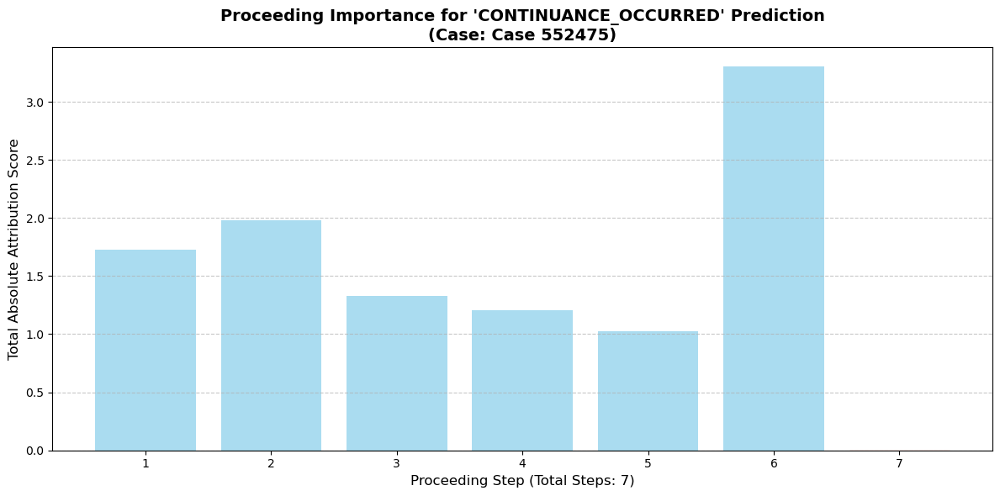

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_22.png


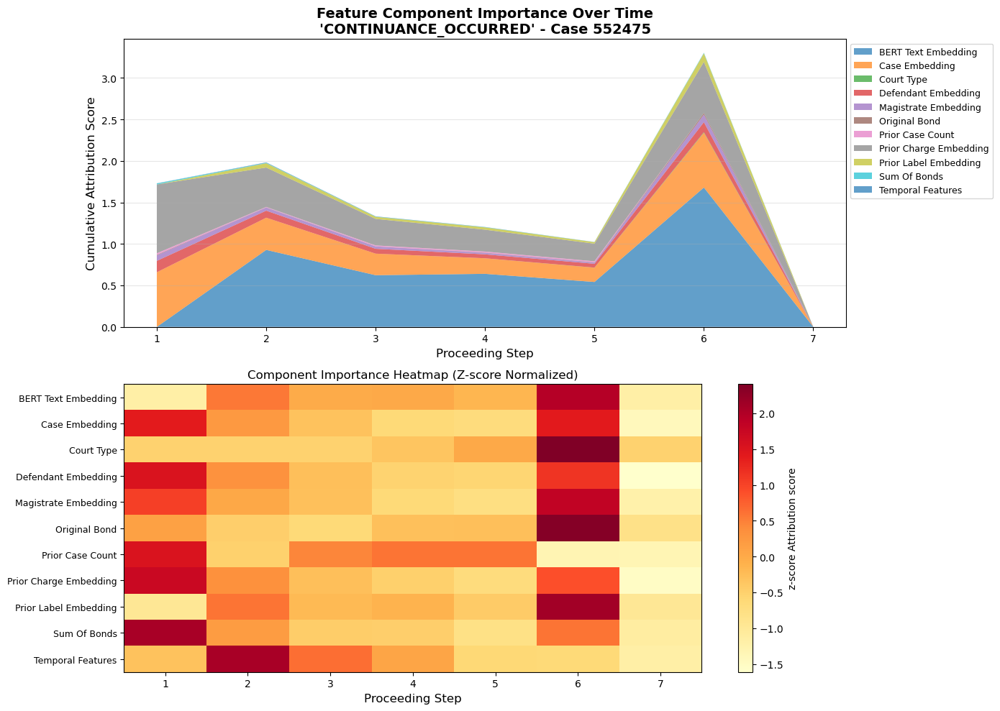


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 7 for class index 14 at proceeding index 5
   Attribution shape: torch.Size([1, 7, 1548])
   Convergence delta: 0.005978837609291077
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           4.413957          0.630565         1.680824         0.533714  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           2.713558          0.387651         0.831425         0.255327  CONTINUANCE_OCCURRED
1           Case_Embedding           2.323527          0.331932         0.660763         0.232973  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.493926          0.070561         0.137047         0.043768  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.256287          0.036612         0.091240         0.029682  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.226686          0.032384         0.102311

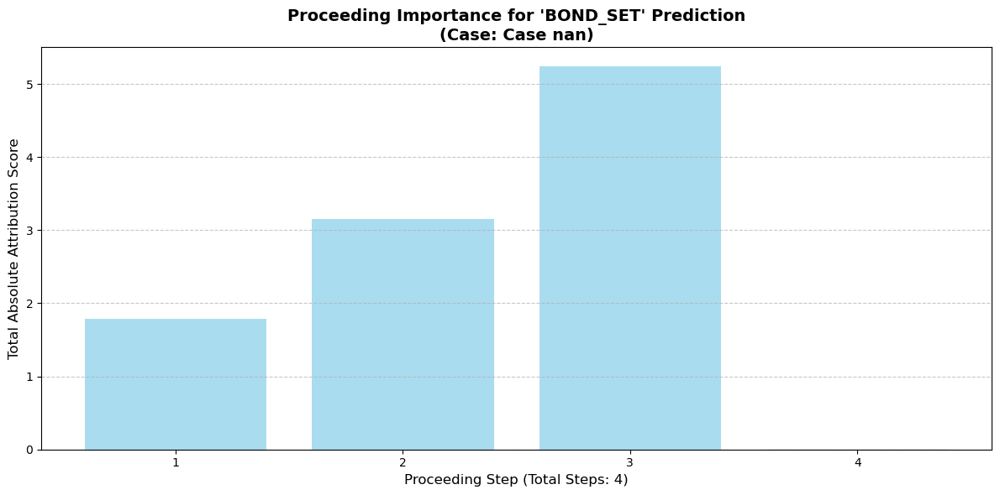

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_23.png


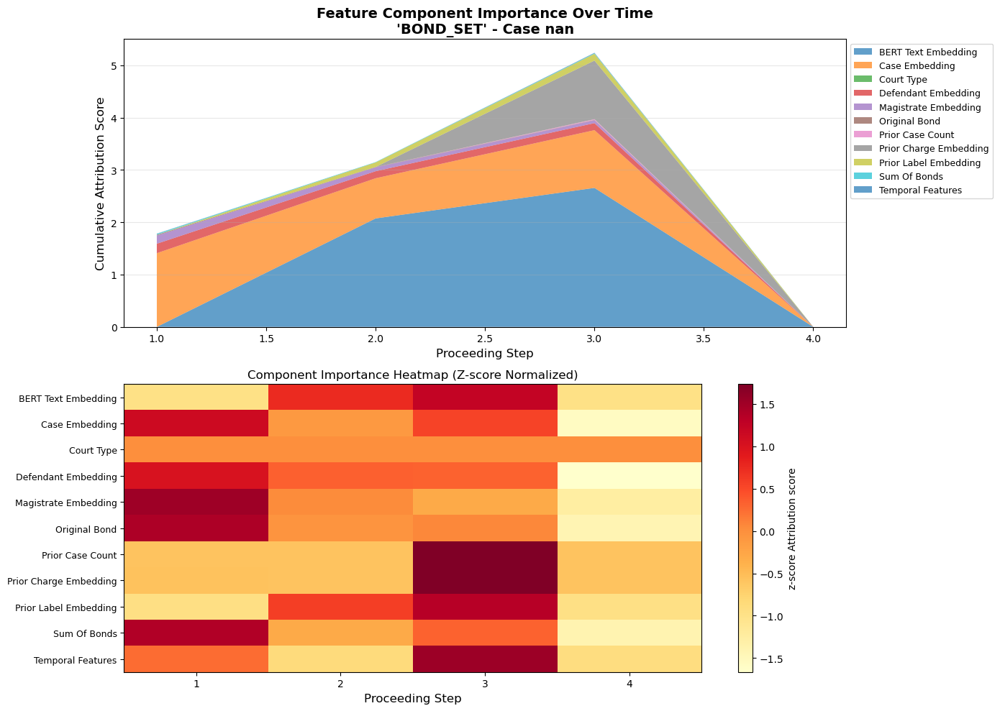


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 4 for class index 1 at proceeding index 2
   Attribution shape: torch.Size([1, 4, 1548])
   Convergence delta: 0.0033257603645324707
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution Target_Label
2      BERT_Text_Embedding           4.725448          1.181362         2.652793         1.199036     BOND_SET
1           Case_Embedding           3.269737          0.817434         1.402996         0.522801     BOND_SET
5   Prior_Charge_Embedding           1.121209          0.280302         1.118015         0.483654     BOND_SET
0      Defendant_Embedding           0.449478          0.112369         0.181363         0.067690     BOND_SET
3     Magistrate_Embedding           0.284311          0.071078         0.156490         0.056177     BOND_SET
4    Prior_Label_Embedding           0.216973          0.054243         0.129694         0.056113     BOND_SET
8             Sum_Of_Bo

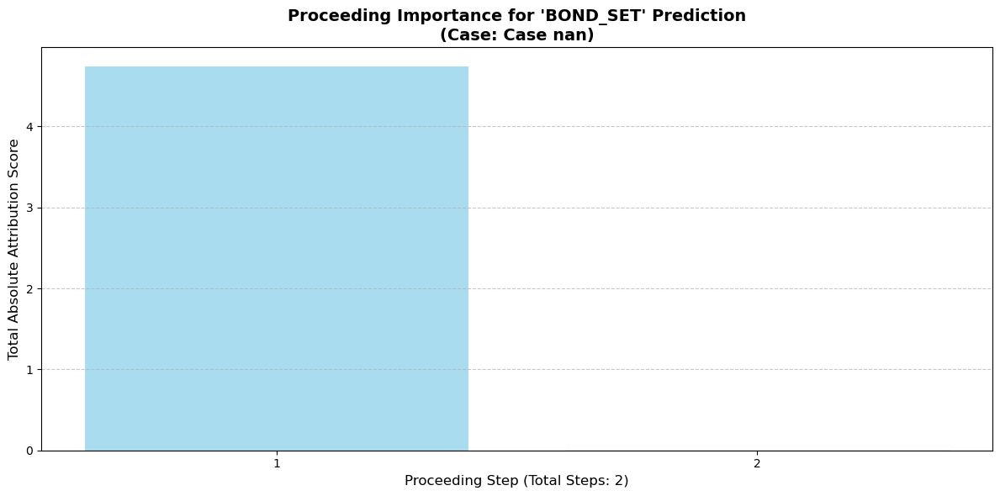

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_24.png


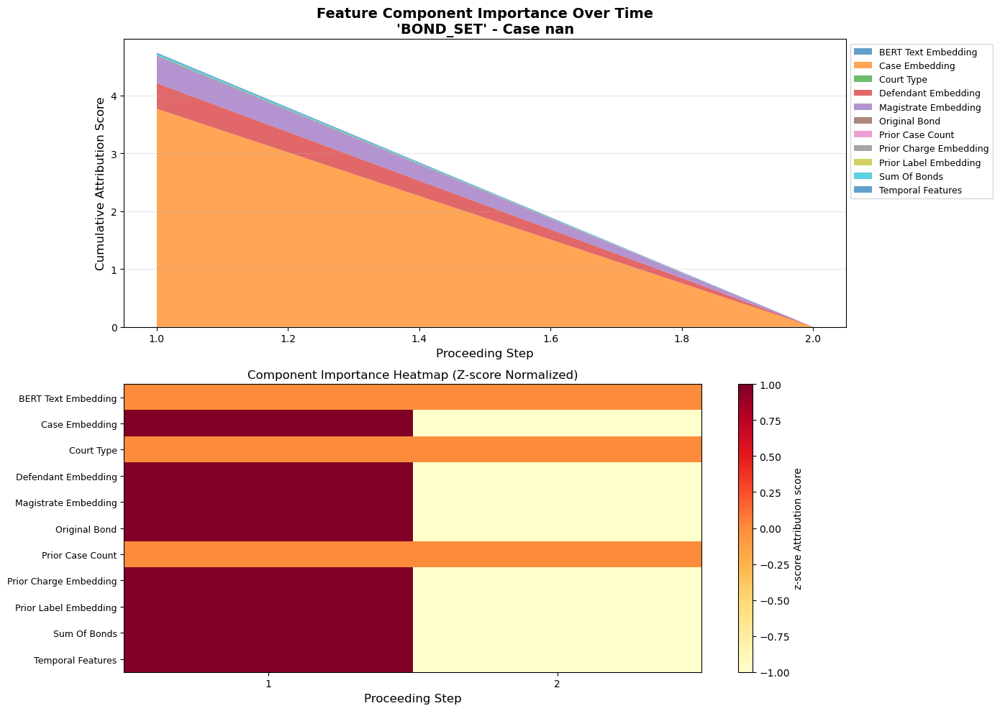


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 2 for class index 1 at proceeding index 0
   Attribution shape: torch.Size([1, 2, 1548])
   Convergence delta: 0.003969296813011169
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution Target_Label
1           Case_Embedding           3.777976          1.888988         3.777976         1.888988     BOND_SET
3     Magistrate_Embedding           0.462517          0.231258         0.462517         0.231258     BOND_SET
0      Defendant_Embedding           0.440732          0.220366         0.440732         0.220366     BOND_SET
8             Sum_Of_Bonds           0.027055          0.013528         0.027055         0.013528     BOND_SET
10       Temporal_Features           0.020498          0.010249         0.020498         0.010249     BOND_SET
7            Original_Bond           0.014075          0.007037         0.014075         0.007037     BOND_SET
5   Prior_Charge_Embeddi

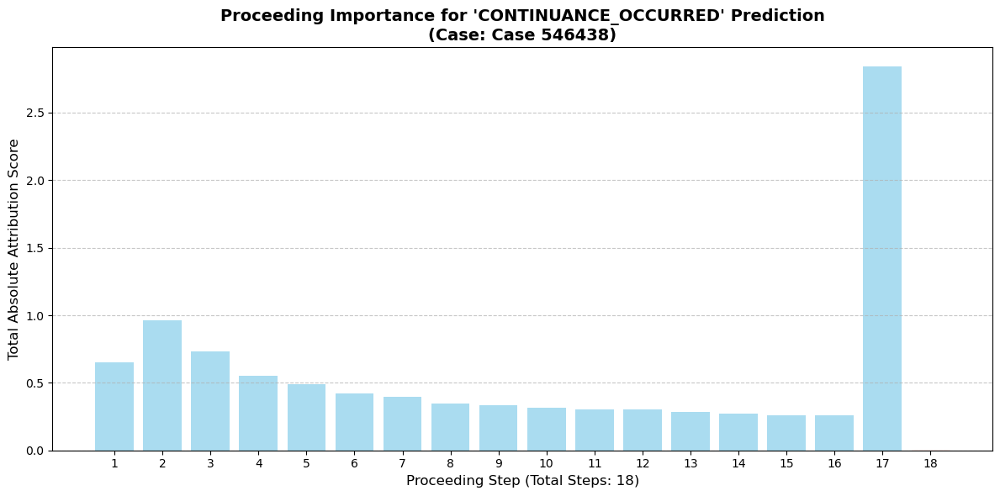

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_25.png


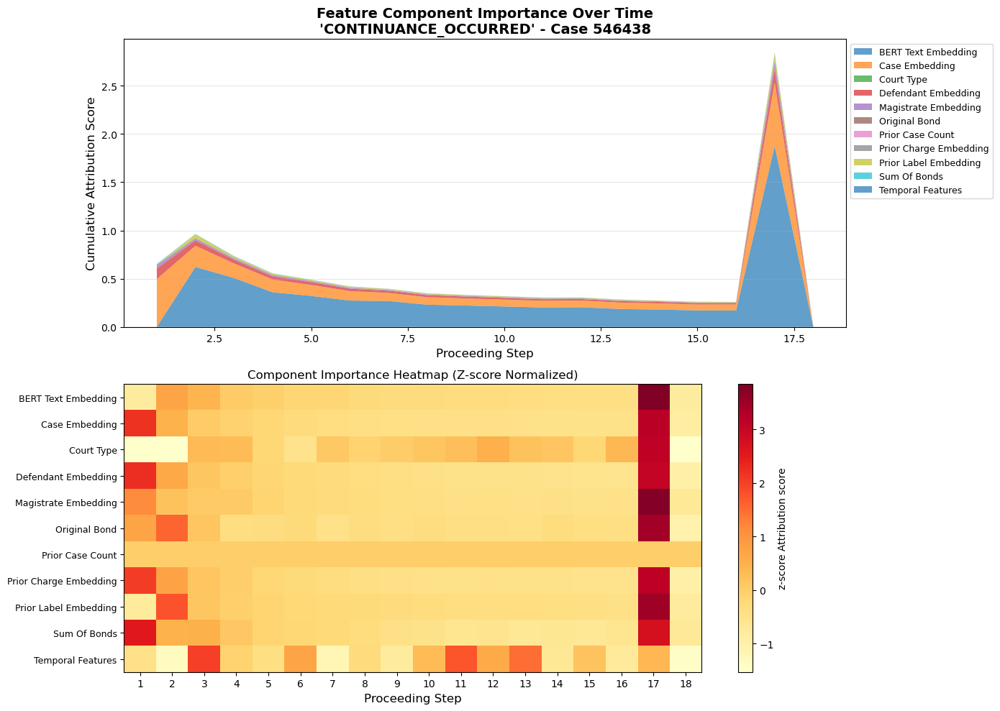


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 18 for class index 14 at proceeding index 16
   Attribution shape: torch.Size([1, 18, 1548])
   Convergence delta: 0.0005521178245544434
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.997496          0.333194         1.873463         0.400536  CONTINUANCE_OCCURRED
1           Case_Embedding           2.555094          0.141950         0.658277         0.162489  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.591875          0.032882         0.135787         0.033868  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.235748          0.013097         0.070452         0.016354  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.227180          0.012621         0.077534         0.017217  CONTINUANCE_OCCURRED
7            Original_Bond           0.043016          0.002390         0.01

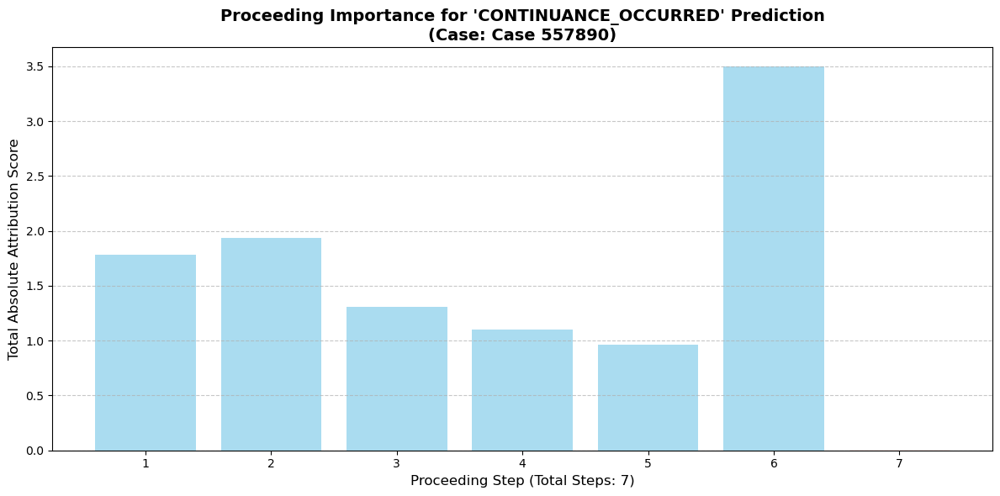

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_26.png


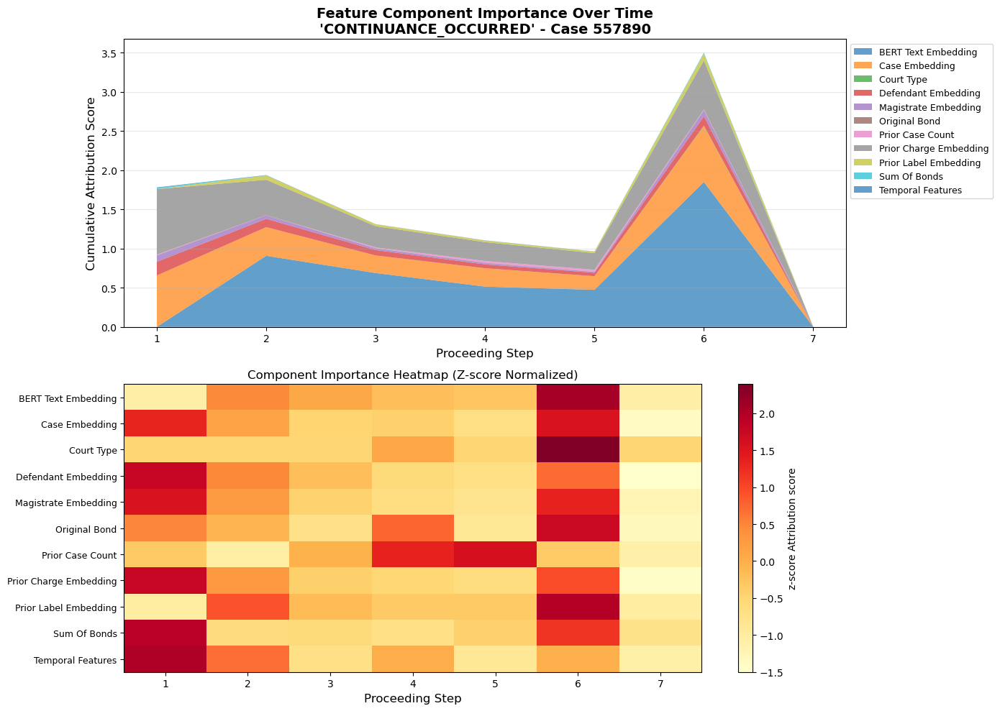


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 7 for class index 14 at proceeding index 5
   Attribution shape: torch.Size([1, 7, 1548])
   Convergence delta: 0.007664918899536133
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           4.432734          0.633248         1.848730         0.585279  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           2.626682          0.375240         0.834525         0.260214  CONTINUANCE_OCCURRED
1           Case_Embedding           2.365639          0.337949         0.711731         0.241034  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.559942          0.079992         0.174569         0.053152  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.248821          0.035546         0.080059         0.029038  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.205948          0.029421         0.085587

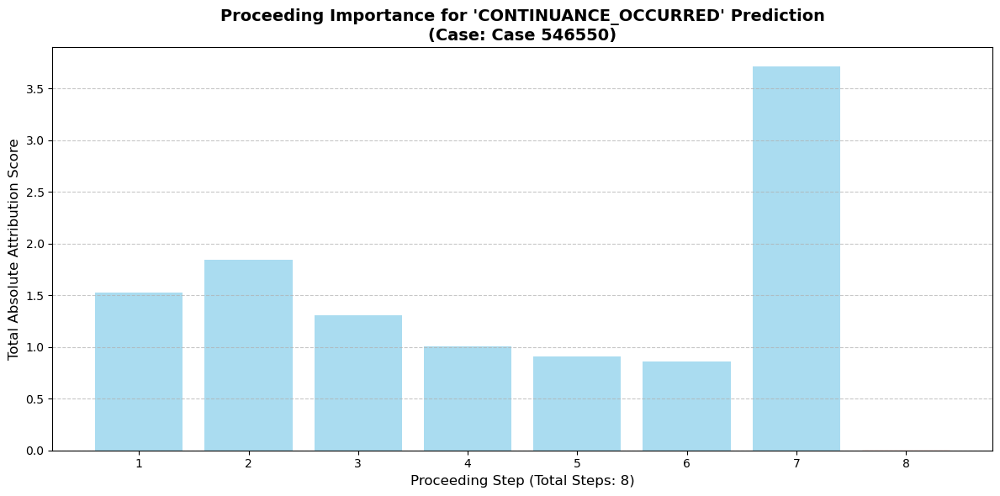

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_27.png


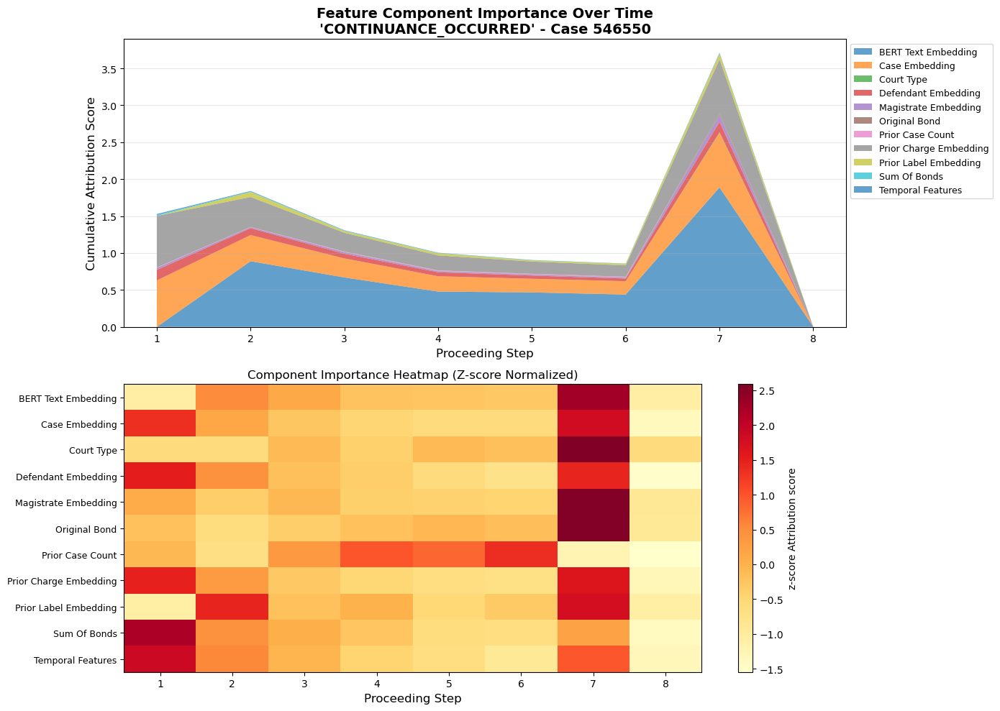


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 8 for class index 14 at proceeding index 6
   Attribution shape: torch.Size([1, 8, 1548])
   Convergence delta: 0.0029883533716201782
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           4.828955          0.603619         1.888497         0.562025  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           2.614094          0.326762         0.736170         0.248385  CONTINUANCE_OCCURRED
1           Case_Embedding           2.556381          0.319548         0.743820         0.232831  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.569489          0.071186         0.142001         0.047044  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.229828          0.028728         0.075196         0.026351  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.182770          0.022846         0.08785

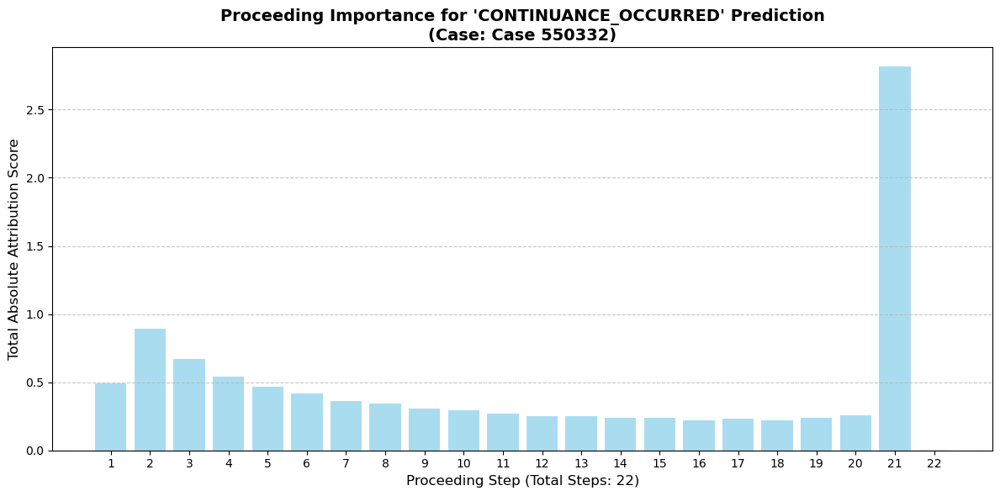

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_28.png


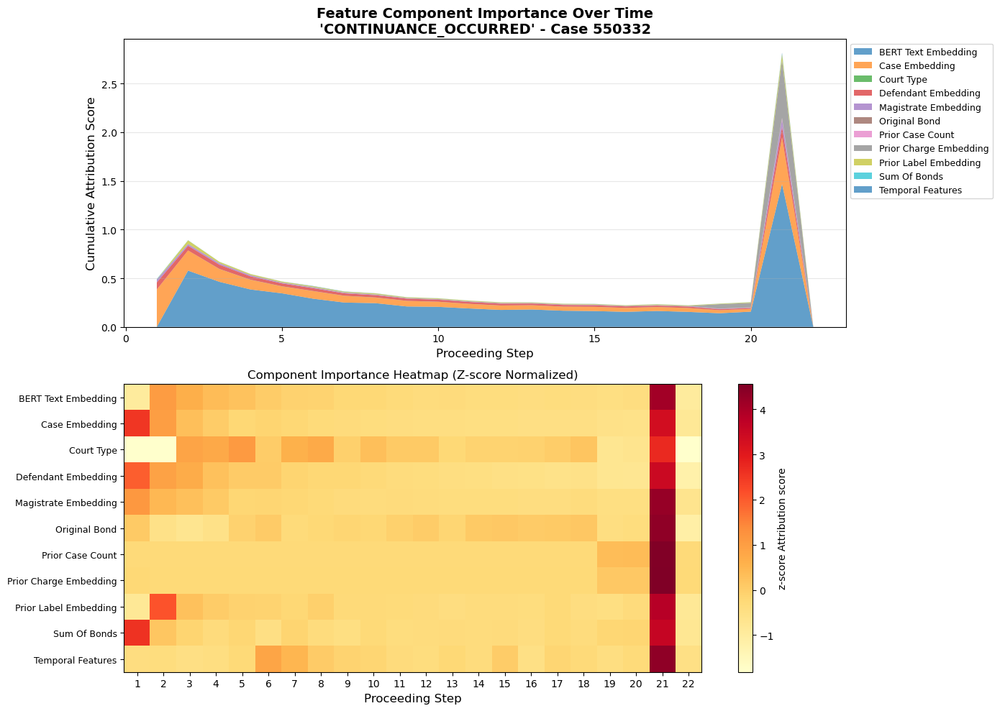


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 22 for class index 14 at proceeding index 20
   Attribution shape: torch.Size([1, 22, 1548])
   Convergence delta: -0.0045018792152404785
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           6.079139          0.276325         1.468118         0.290306  CONTINUANCE_OCCURRED
1           Case_Embedding           2.081967          0.094635         0.477994         0.115165  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           0.689408          0.031337         0.593777         0.123436  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.606152          0.027552         0.107900         0.023070  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.233159          0.010598         0.059432         0.012737  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.231296          0.010513         0.0

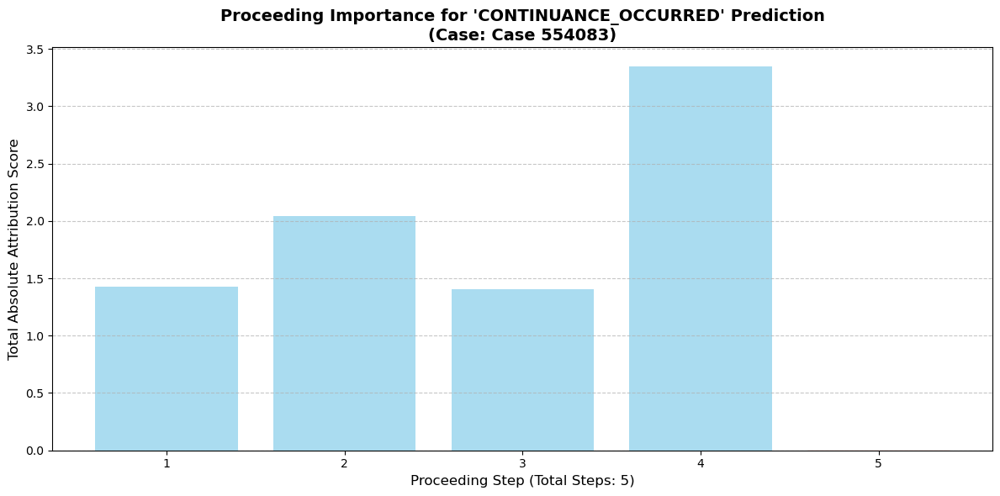

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_29.png


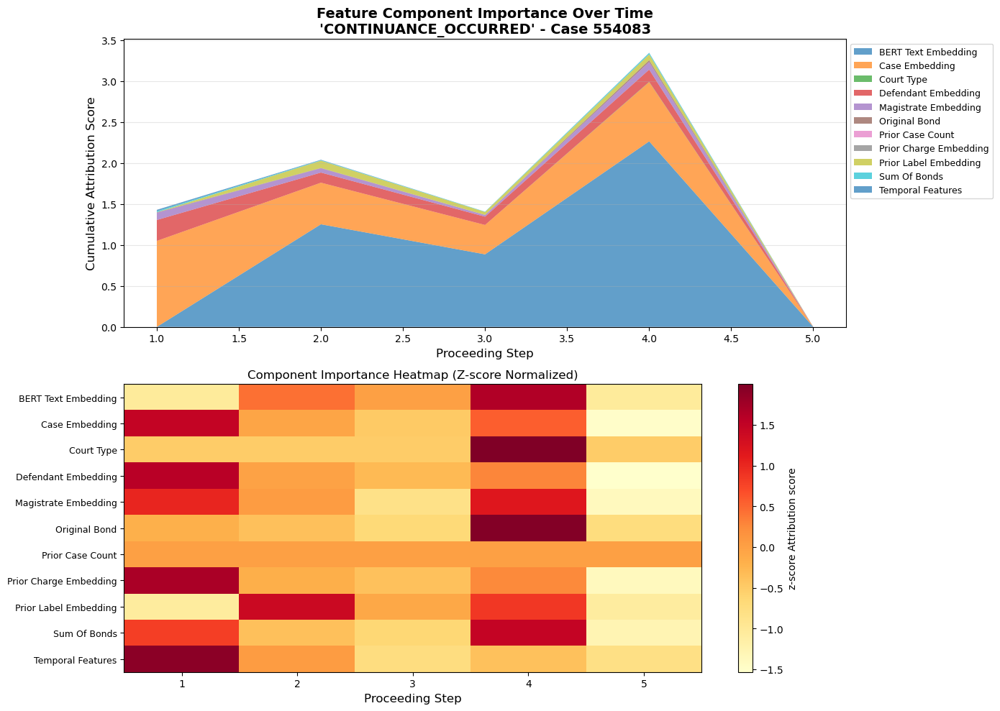


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 5 for class index 14 at proceeding index 3
   Attribution shape: torch.Size([1, 5, 1548])
   Convergence delta: -0.0017664730548858643
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           4.400021          0.880004         2.265831         0.849344  CONTINUANCE_OCCURRED
1           Case_Embedding           2.637811          0.527562         1.048798         0.351416  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.628607          0.125721         0.254890         0.081979  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.255912          0.051182         0.094056         0.036871  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.193998          0.038800         0.089034         0.035952  CONTINUANCE_OCCURRED
8             Sum_Of_Bonds           0.038855          0.007771         0.0168

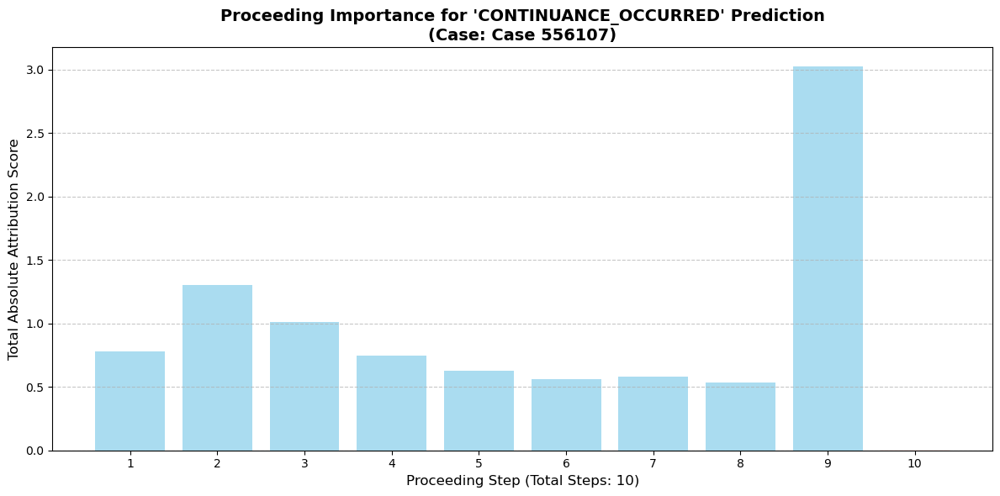

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_30.png


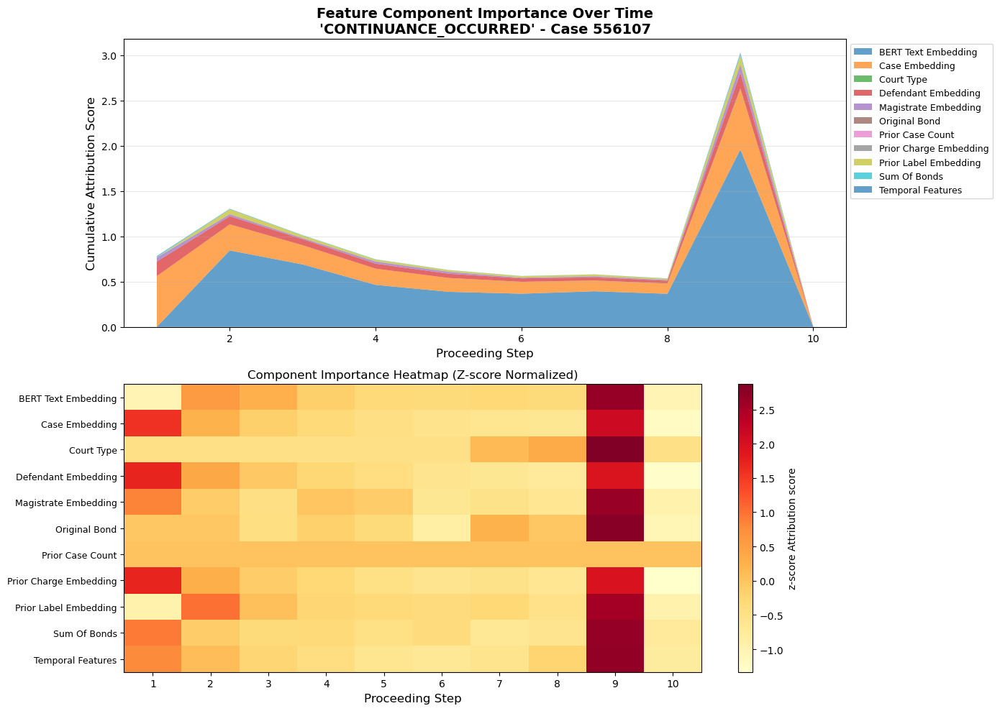


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 10 for class index 14 at proceeding index 8
   Attribution shape: torch.Size([1, 10, 1548])
   Convergence delta: 0.0032970309257507324
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.466099          0.546610         1.957046         0.530698  CONTINUANCE_OCCURRED
1           Case_Embedding           2.424151          0.242415         0.668207         0.200255  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.692799          0.069280         0.171817         0.053497  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.258246          0.025825         0.094341         0.026838  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.225344          0.022534         0.085421         0.023699  CONTINUANCE_OCCURRED
8             Sum_Of_Bonds           0.035869          0.003587         0.016

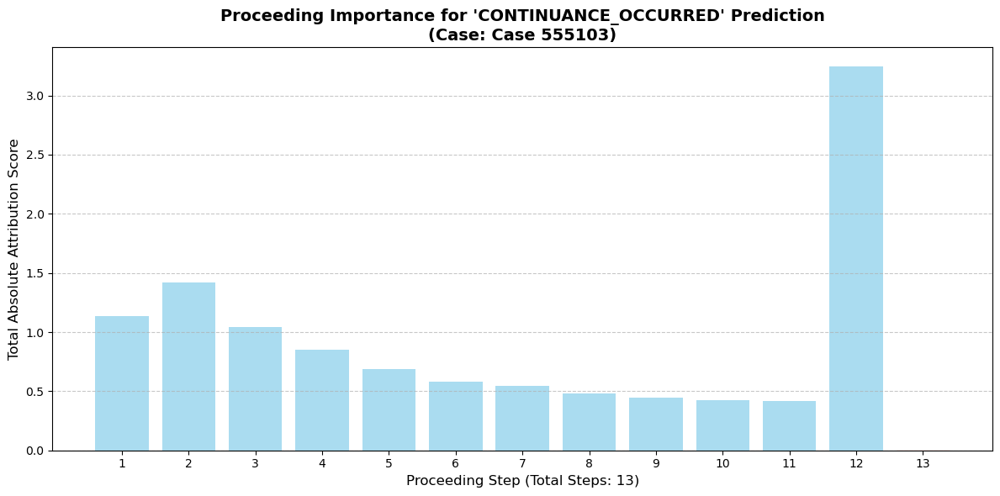

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_31.png


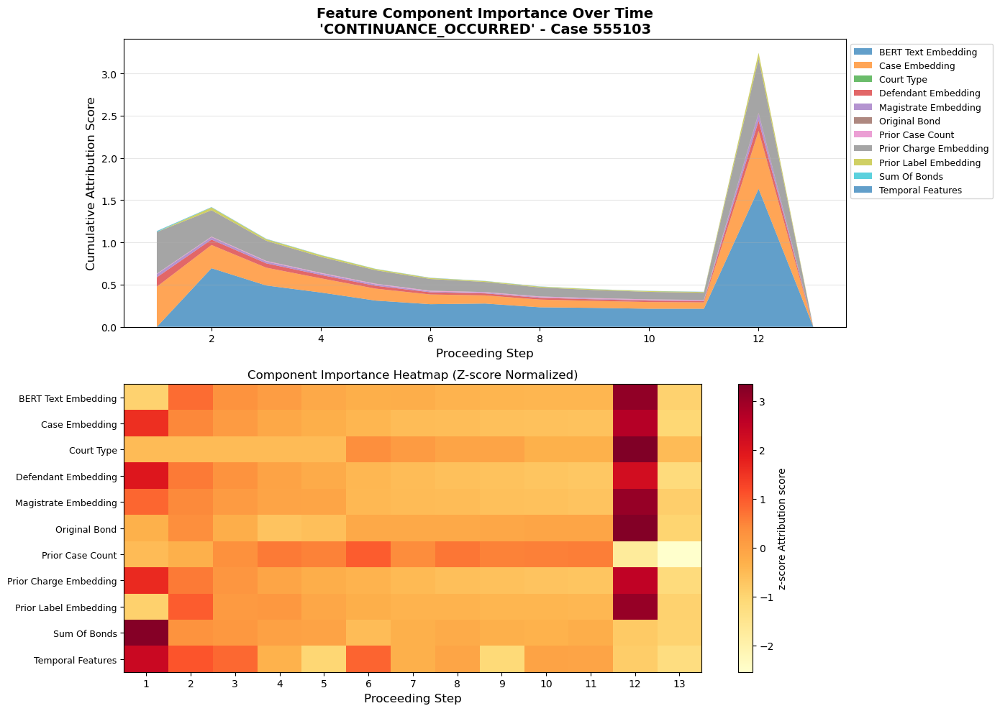


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 13 for class index 14 at proceeding index 11
   Attribution shape: torch.Size([1, 13, 1548])
   Convergence delta: 0.0015632957220077515
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           4.969726          0.382287         1.632870         0.401835  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           2.670850          0.205450         0.640119         0.173467  CONTINUANCE_OCCURRED
1           Case_Embedding           2.490542          0.191580         0.684332         0.182513  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.540775          0.041598         0.119794         0.035228  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.241294          0.018561         0.083000         0.021140  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.210811          0.016216         0.06

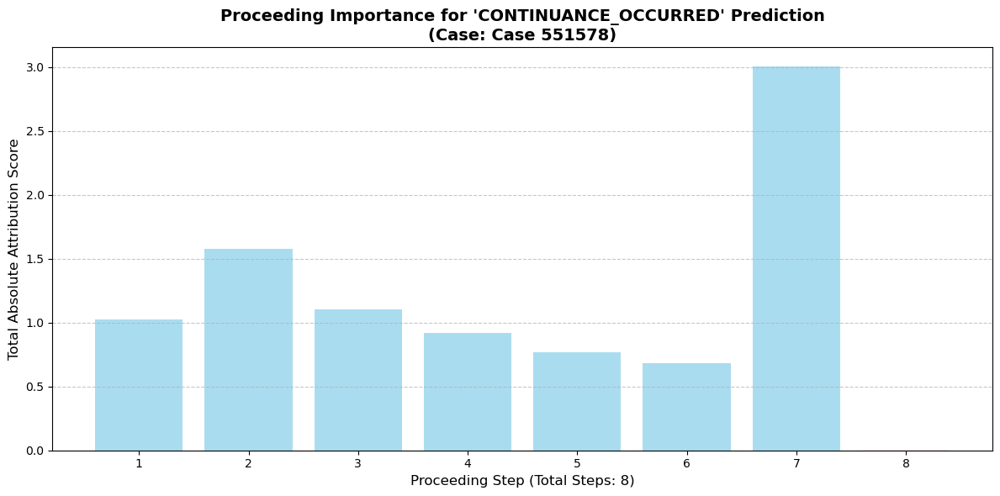

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_32.png


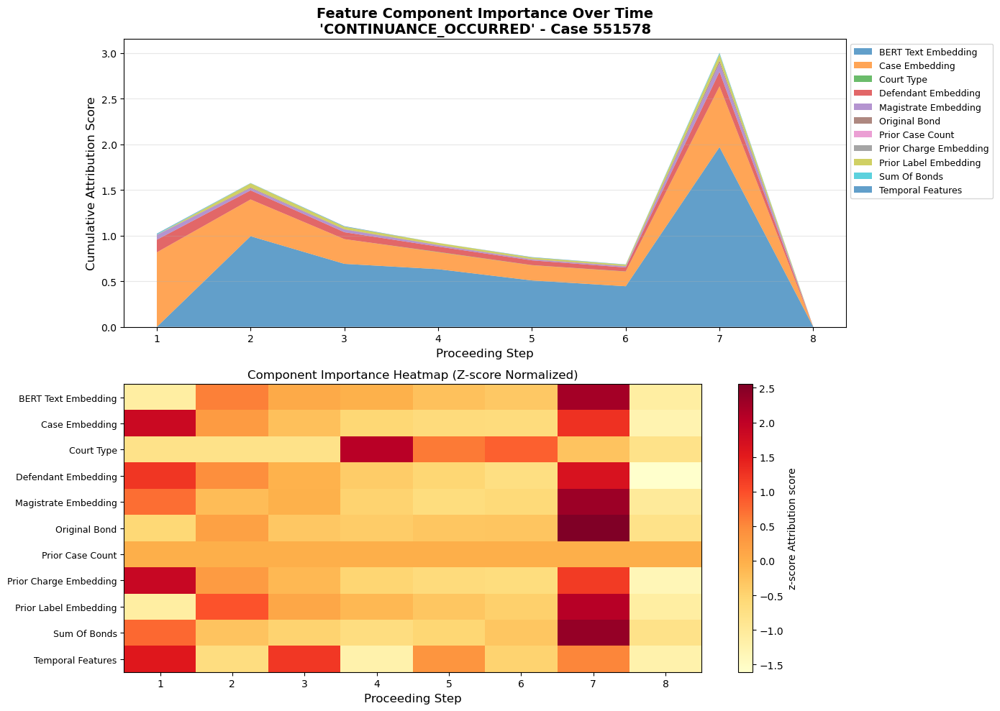


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 8 for class index 14 at proceeding index 6
   Attribution shape: torch.Size([1, 8, 1548])
   Convergence delta: -0.007794559001922607
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.239669          0.654959         1.972428         0.588897  CONTINUANCE_OCCURRED
1           Case_Embedding           2.667180          0.333398         0.814565         0.260526  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.626977          0.078372         0.159658         0.048842  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.240287          0.030036         0.098436         0.029654  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.196270          0.024534         0.069769         0.021930  CONTINUANCE_OCCURRED
7            Original_Bond           0.044260          0.005533         0.02291

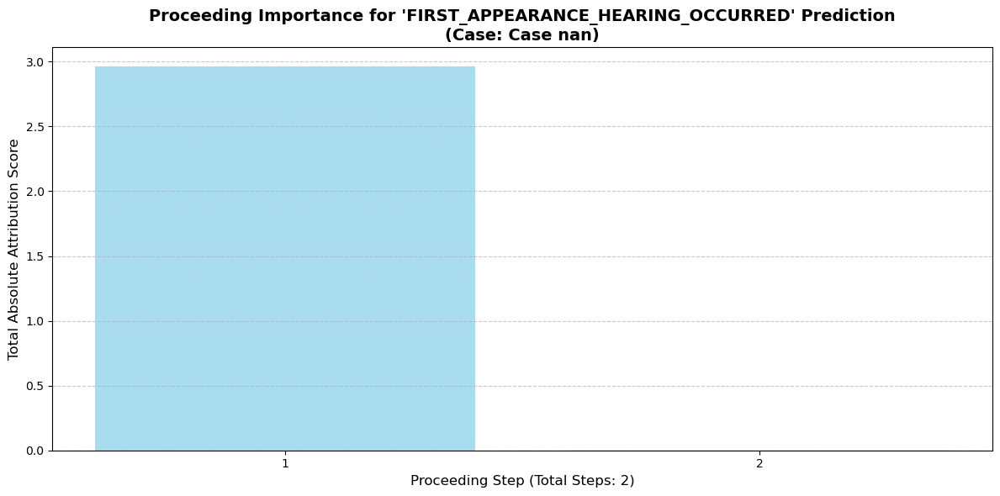

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_33.png


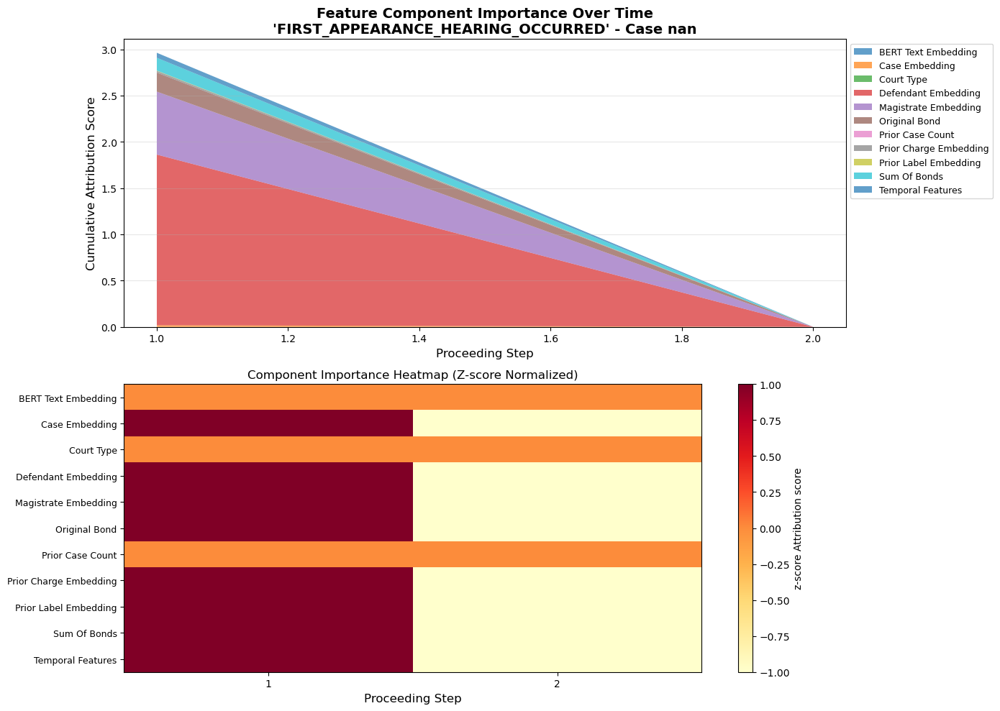


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 2 for class index 0 at proceeding index 0
   Attribution shape: torch.Size([1, 2, 1548])
   Convergence delta: -0.010112285614013672
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution                       Target_Label
0      Defendant_Embedding           1.838122          0.919061         1.838122         0.919061  FIRST_APPEARANCE_HEARING_OCCURRED
3     Magistrate_Embedding           0.673929          0.336965         0.673929         0.336965  FIRST_APPEARANCE_HEARING_OCCURRED
7            Original_Bond           0.204242          0.102121         0.204242         0.102121  FIRST_APPEARANCE_HEARING_OCCURRED
8             Sum_Of_Bonds           0.137778          0.068889         0.137778         0.068889  FIRST_APPEARANCE_HEARING_OCCURRED
10       Temporal_Features           0.053202          0.026601         0.053202         0.026601  FIRST_APPEARANCE_HEARING_OCCURRED
5 

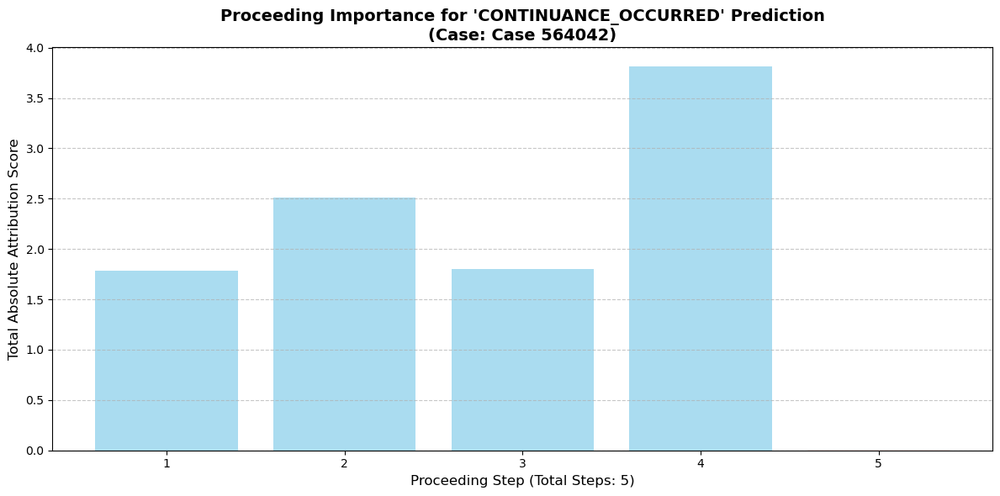

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_34.png


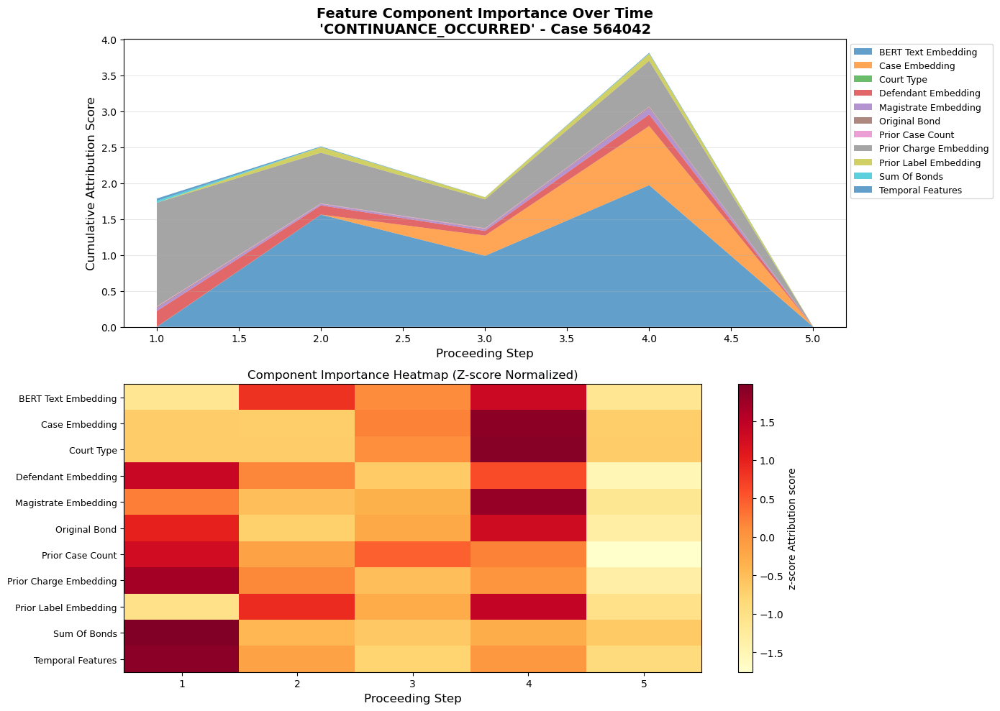


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 5 for class index 14 at proceeding index 3
   Attribution shape: torch.Size([1, 5, 1548])
   Convergence delta: -0.004941567778587341
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           4.513768          0.902754         1.966819         0.800095  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           3.192069          0.638414         1.449327         0.474675  CONTINUANCE_OCCURRED
1           Case_Embedding           1.104523          0.220905         0.818861         0.318351  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.568972          0.113794         0.218421         0.075676  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.206136          0.041227         0.098784         0.040355  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.171086          0.034217         0.08708

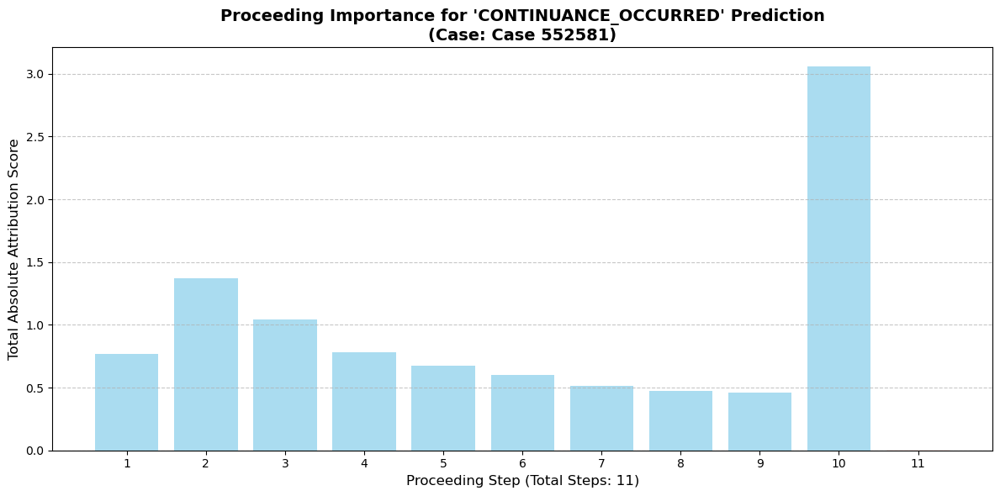

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_35.png


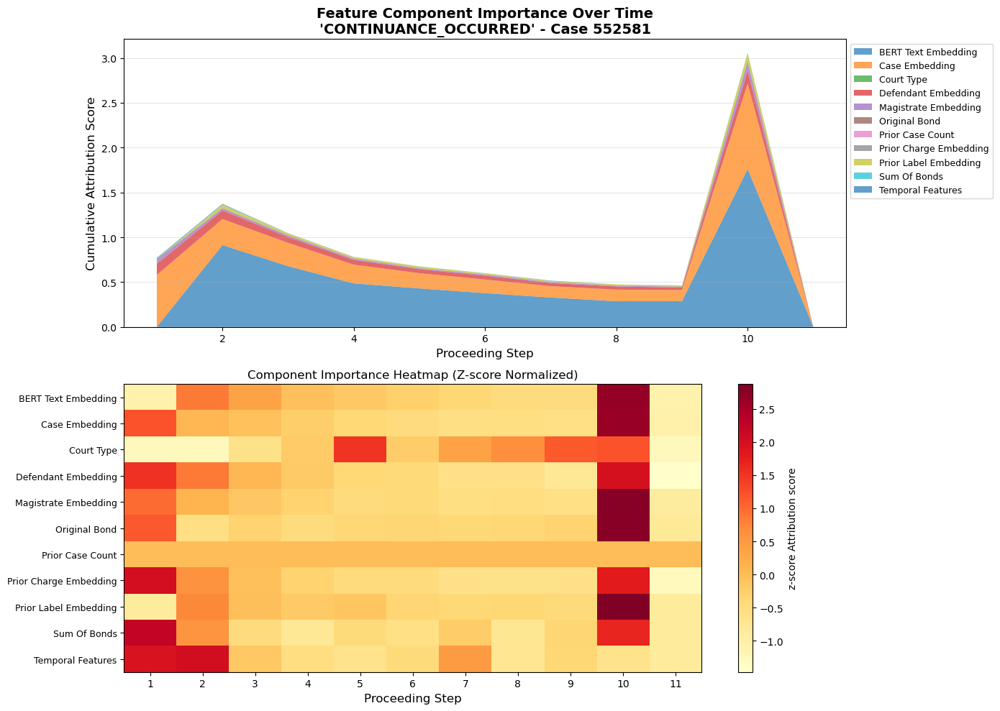


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 11 for class index 14 at proceeding index 9
   Attribution shape: torch.Size([1, 11, 1548])
   Convergence delta: -0.0011373162269592285
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.543602          0.503964         1.761045         0.470238  CONTINUANCE_OCCURRED
1           Case_Embedding           2.991208          0.271928         0.957268         0.257960  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.660447          0.060041         0.140774         0.040649  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.233680          0.021244         0.090938         0.024241  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.230959          0.020996         0.086637         0.023450  CONTINUANCE_OCCURRED
7            Original_Bond           0.047663          0.004333         0.01

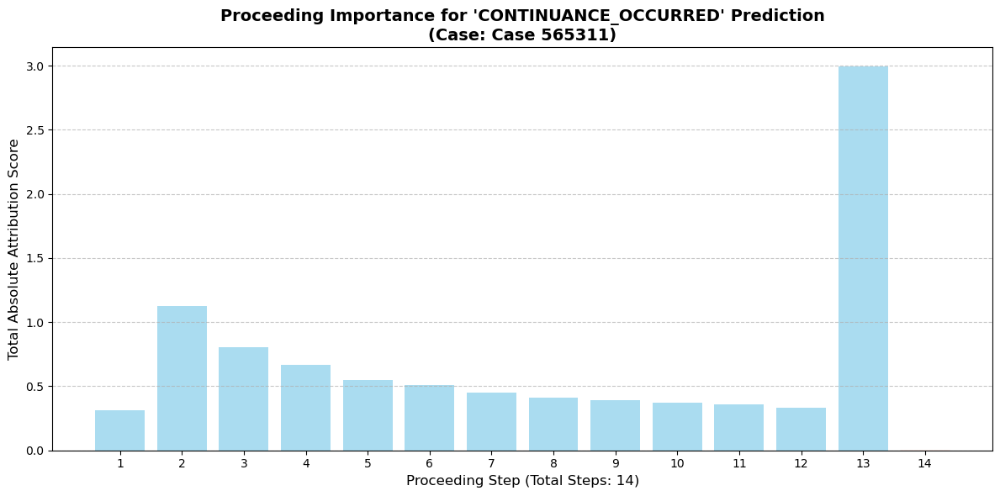

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_36.png


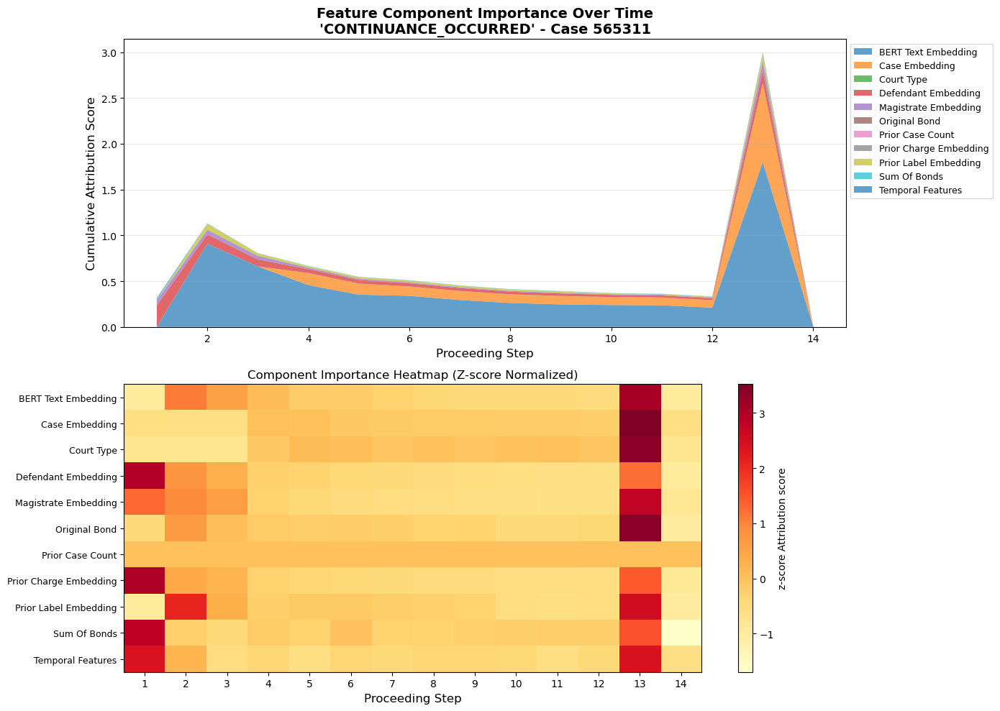


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 14 for class index 14 at proceeding index 12
   Attribution shape: torch.Size([1, 14, 1548])
   Convergence delta: 0.0015108585357666016
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.999089          0.428506         1.799617         0.442747  CONTINUANCE_OCCURRED
1           Case_Embedding           1.753356          0.125240         0.862748         0.209525  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.803333          0.057381         0.232949         0.059293  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.302308          0.021593         0.092107         0.025262  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.277695          0.019835         0.070866         0.020211  CONTINUANCE_OCCURRED
7            Original_Bond           0.047709          0.003408         0.01

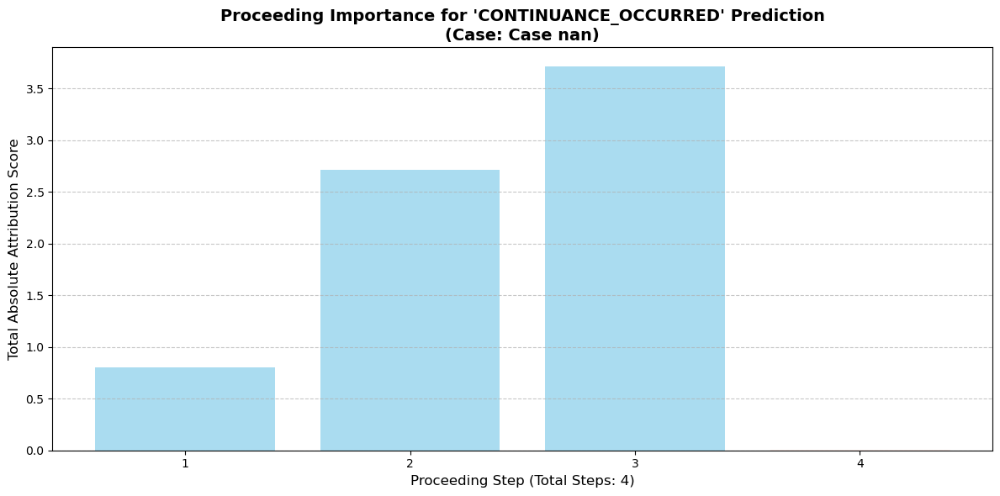

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_37.png


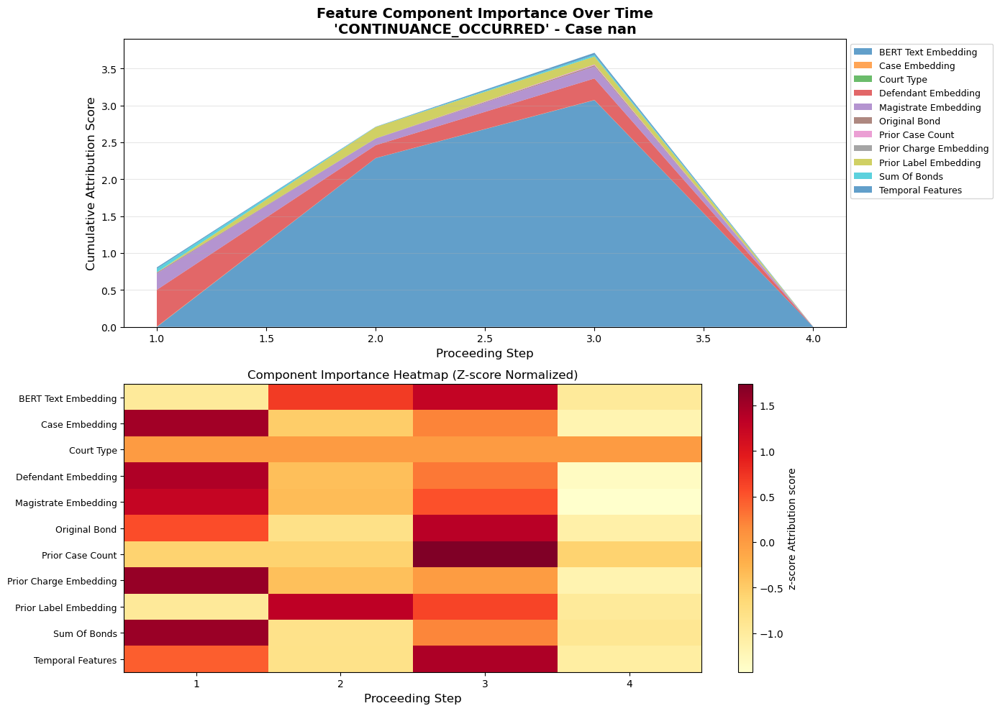


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 4 for class index 14 at proceeding index 2
   Attribution shape: torch.Size([1, 4, 1548])
   Convergence delta: 0.0038354694843292236
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.357958          1.339490         3.069397         1.367642  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.959210          0.239803         0.496383         0.180390  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.473140          0.118285         0.223569         0.083381  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.260097          0.065024         0.153717         0.066871  CONTINUANCE_OCCURRED
8             Sum_Of_Bonds           0.071516          0.017879         0.047865         0.019324  CONTINUANCE_OCCURRED
10       Temporal_Features           0.050595          0.012649         0.02944

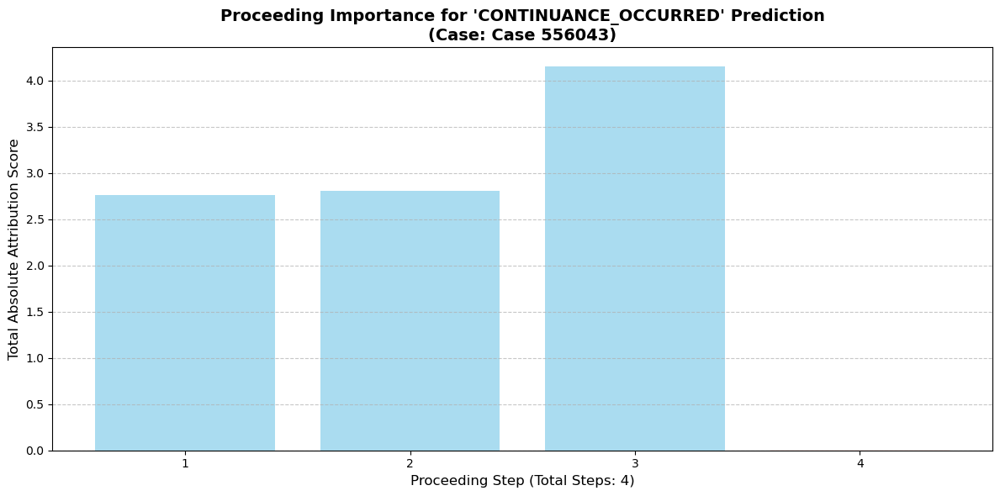

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_38.png


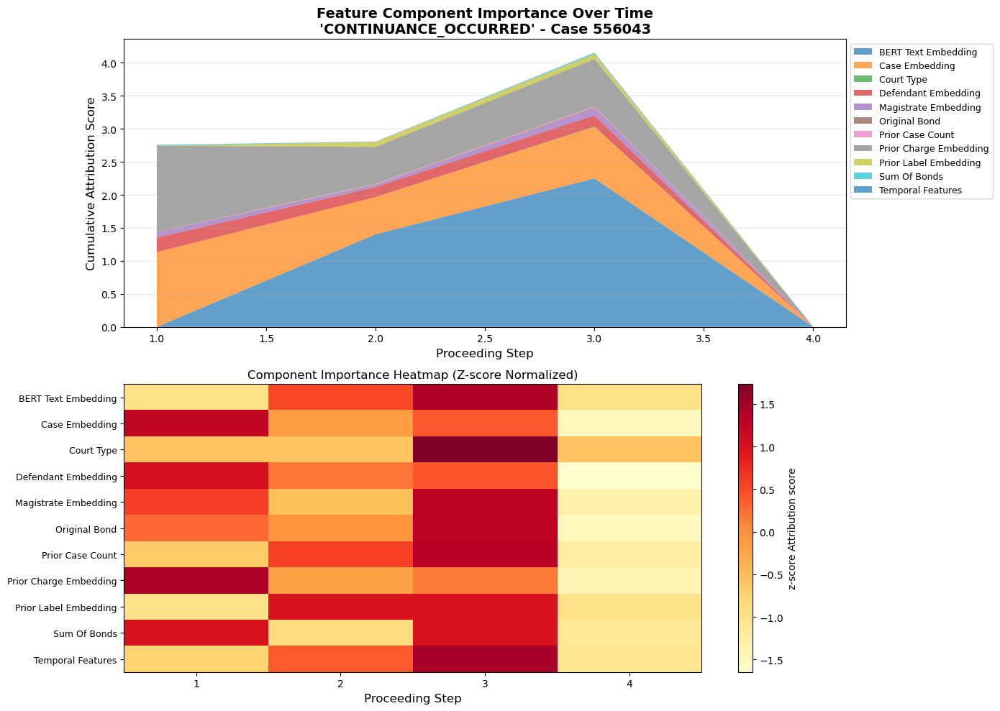


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 4 for class index 14 at proceeding index 2
   Attribution shape: torch.Size([1, 4, 1548])
   Convergence delta: -0.004031062126159668
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           3.644949          0.911237         2.244801         0.958923  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           2.587183          0.646796         1.306665         0.465397  CONTINUANCE_OCCURRED
1           Case_Embedding           2.469149          0.617287         1.128313         0.409615  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.542301          0.135575         0.221907         0.082491  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.209170          0.052293         0.102342         0.039309  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.146651          0.036663         0.07380

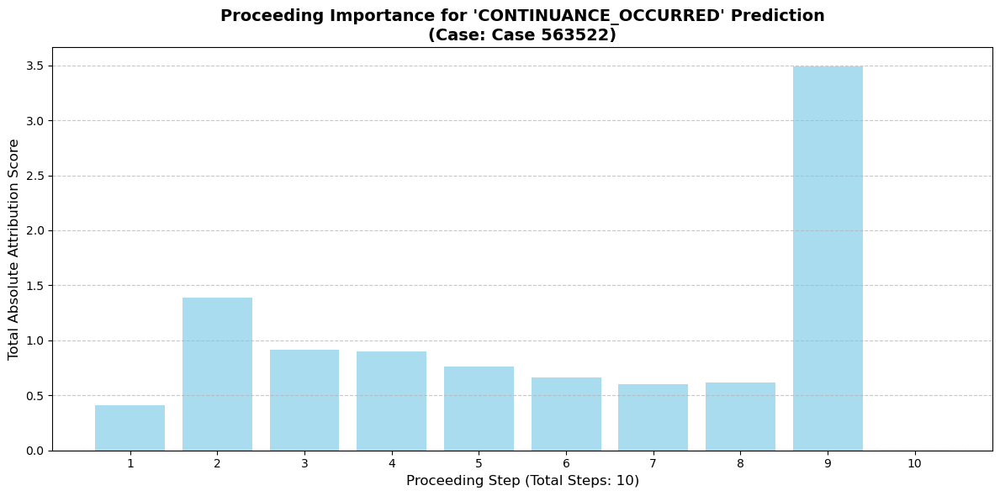

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_39.png


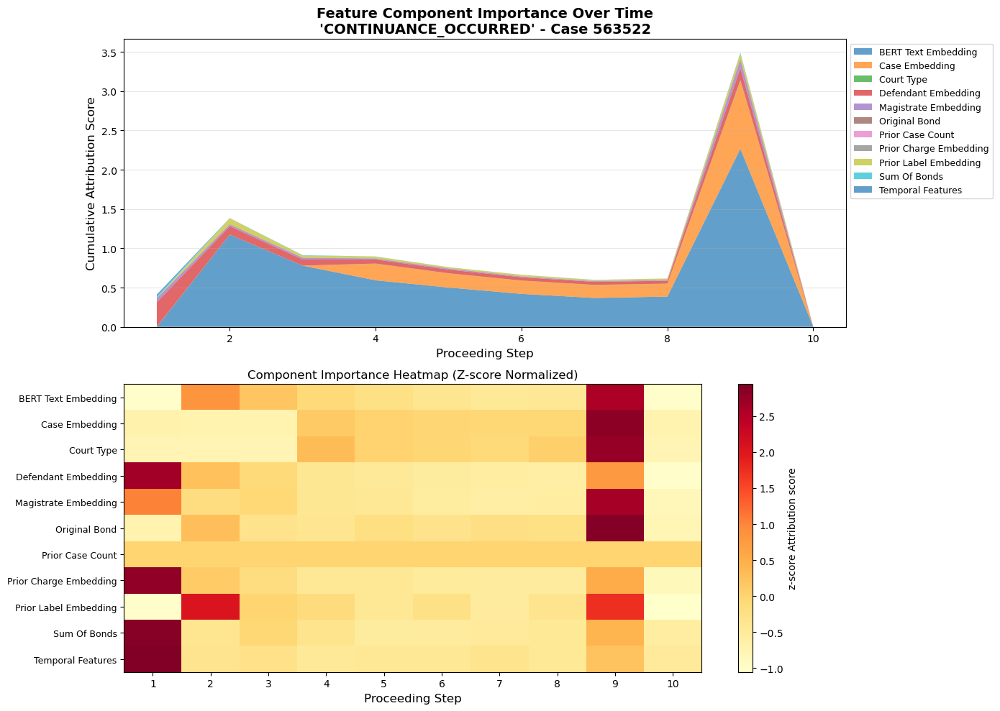


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 10 for class index 14 at proceeding index 8
   Attribution shape: torch.Size([1, 10, 1548])
   Convergence delta: 0.0016860365867614746
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           6.487455          0.648745         2.263118         0.629872  CONTINUANCE_OCCURRED
1           Case_Embedding           1.762228          0.176223         0.869389         0.245973  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.858612          0.085861         0.310077         0.084668  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.261499          0.026150         0.076548         0.024868  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.234616          0.023462         0.095487         0.027579  CONTINUANCE_OCCURRED
7            Original_Bond           0.040651          0.004065         0.019

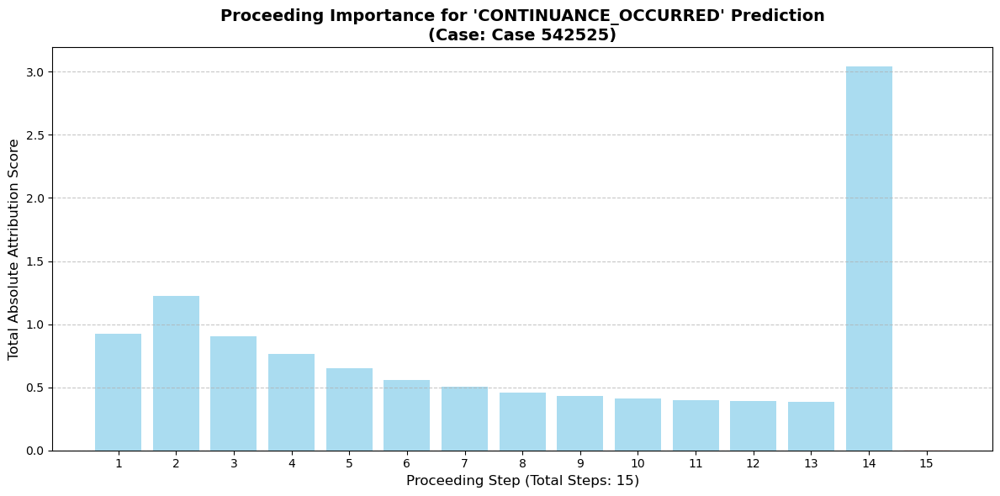

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_40.png


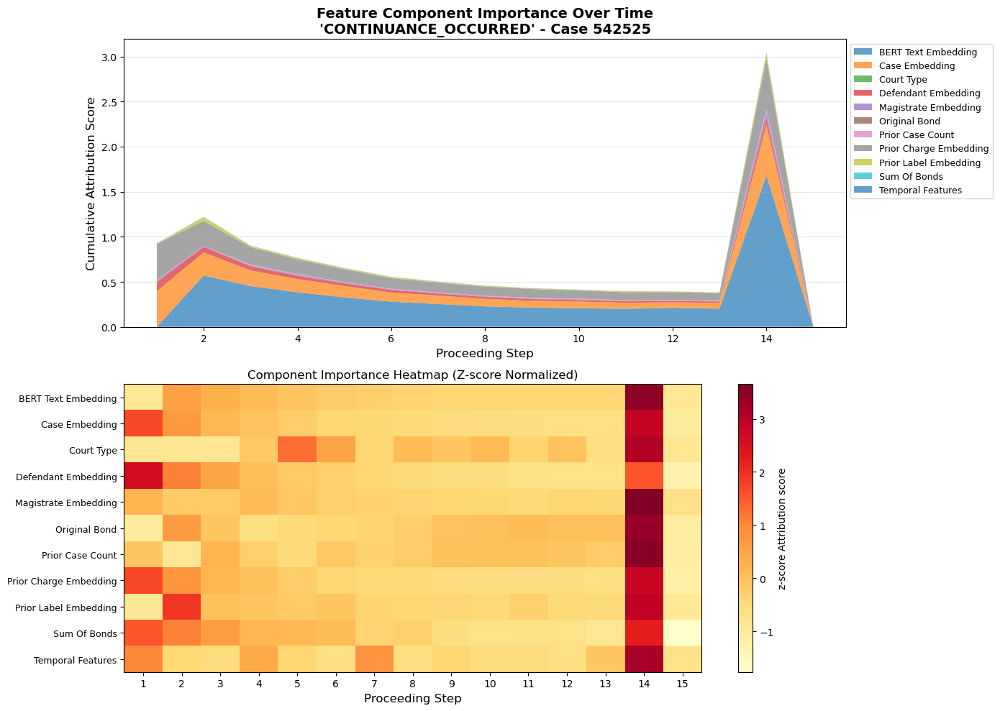


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 15 for class index 14 at proceeding index 13
   Attribution shape: torch.Size([1, 15, 1548])
   Convergence delta: -0.0034584999084472656
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.209214          0.347281         1.678601         0.383181  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           2.494687          0.166312         0.554586         0.138594  CONTINUANCE_OCCURRED
1           Case_Embedding           2.292077          0.152805         0.564967         0.144104  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.490118          0.032675         0.098949         0.025117  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.207030          0.013802         0.056750         0.014679  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.167484          0.011166         0.0

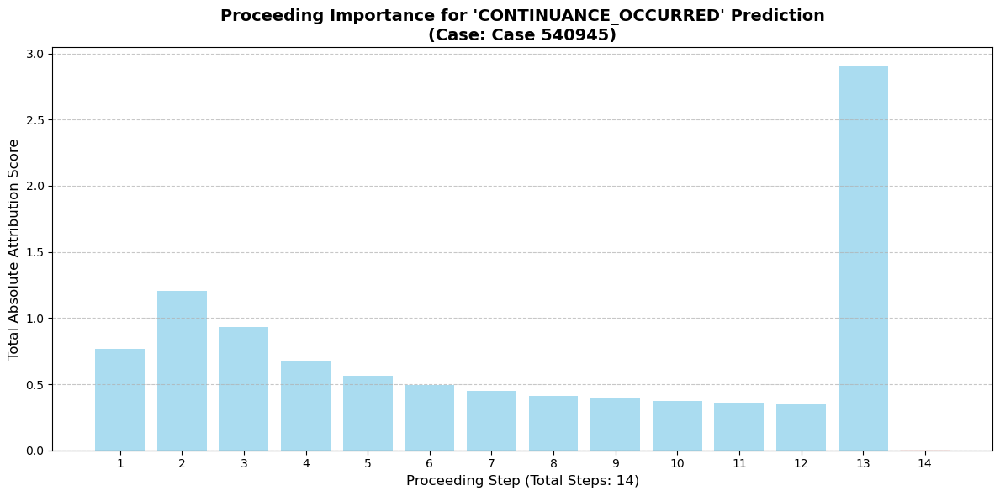

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_41.png


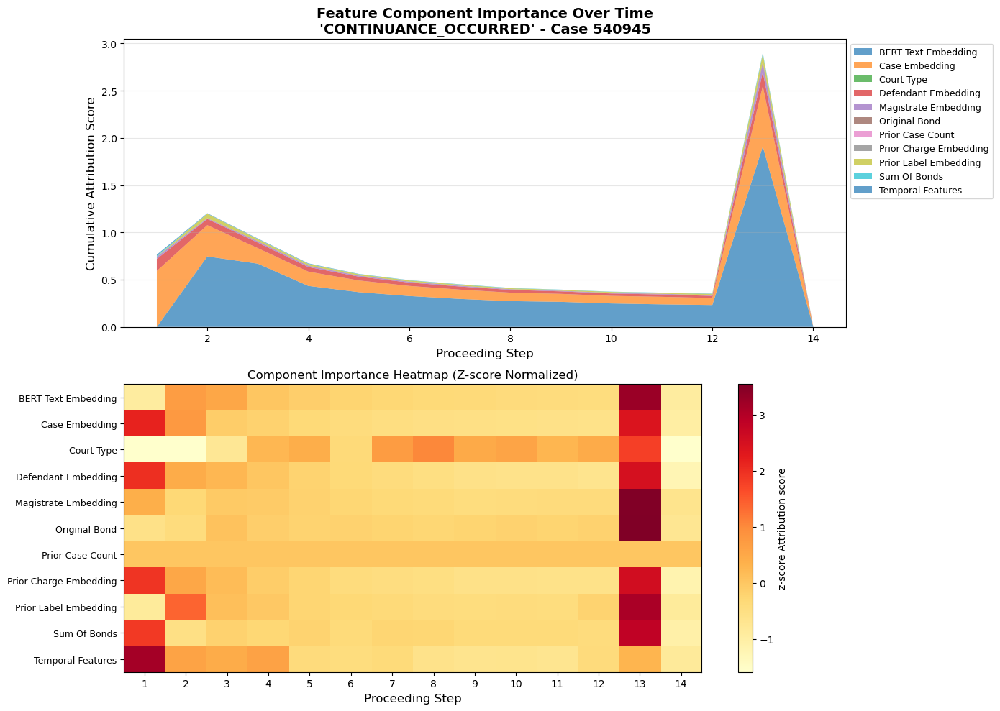


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 14 for class index 14 at proceeding index 12
   Attribution shape: torch.Size([1, 14, 1548])
   Convergence delta: 0.009657740592956543
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.997879          0.428420         1.905636         0.454787  CONTINUANCE_OCCURRED
1           Case_Embedding           2.605936          0.186138         0.638227         0.188699  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.680726          0.048623         0.145965         0.039272  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.250070          0.017862         0.080862         0.020451  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.198879          0.014206         0.091068         0.021920  CONTINUANCE_OCCURRED
8             Sum_Of_Bonds           0.048895          0.003493         0.012

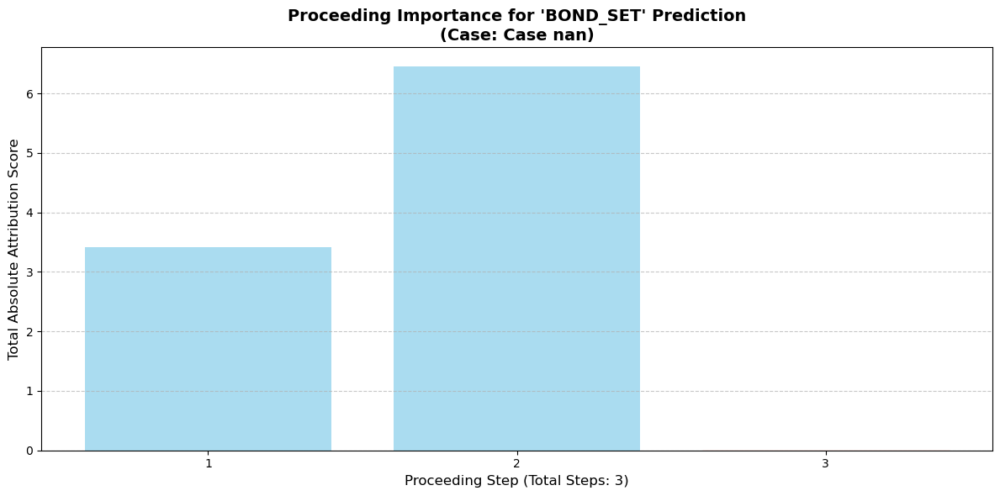

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_42.png


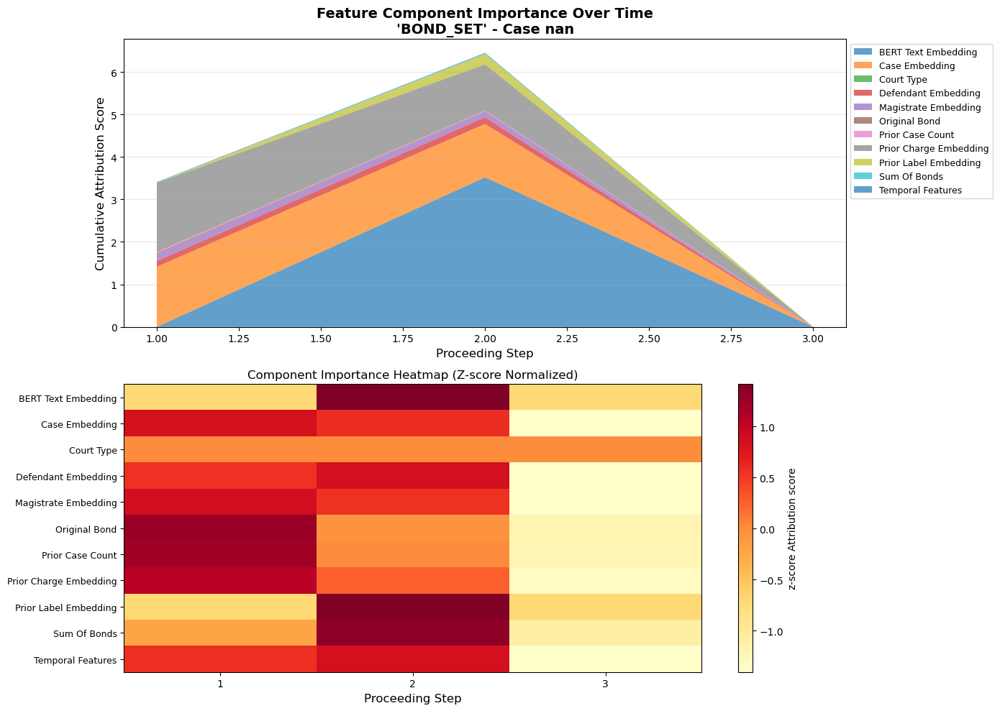


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 3 for class index 1 at proceeding index 1
   Attribution shape: torch.Size([1, 3, 1548])
   Convergence delta: 0.013830423355102539
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution Target_Label
2      BERT_Text_Embedding           3.514591          1.171530         3.514591         1.656794     BOND_SET
5   Prior_Charge_Embedding           2.712164          0.904055         1.628852         0.676949     BOND_SET
1           Case_Embedding           2.676730          0.892243         1.417629         0.634222     BOND_SET
3     Magistrate_Embedding           0.295586          0.098529         0.160143         0.070396     BOND_SET
0      Defendant_Embedding           0.290215          0.096738         0.154647         0.068846     BOND_SET
4    Prior_Label_Embedding           0.244384          0.081461         0.243874         0.114844     BOND_SET
7            Original_Bo

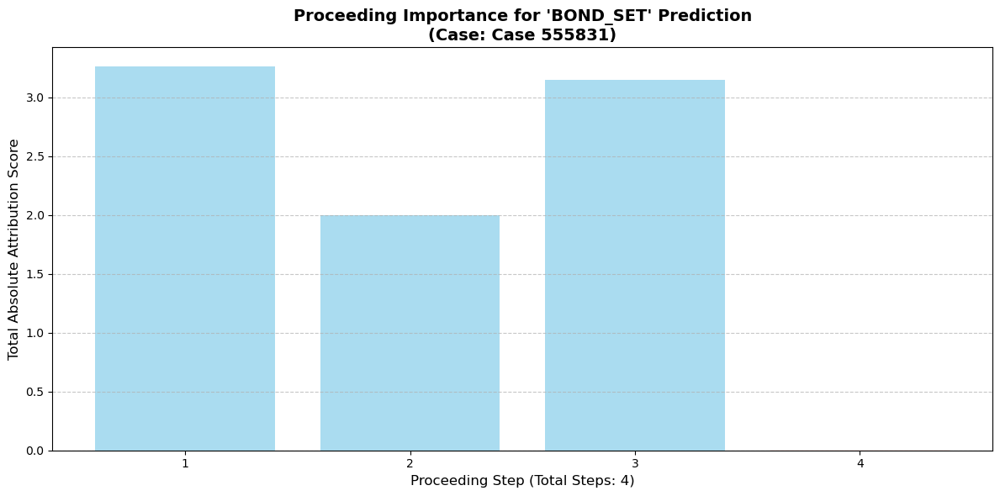

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_43.png


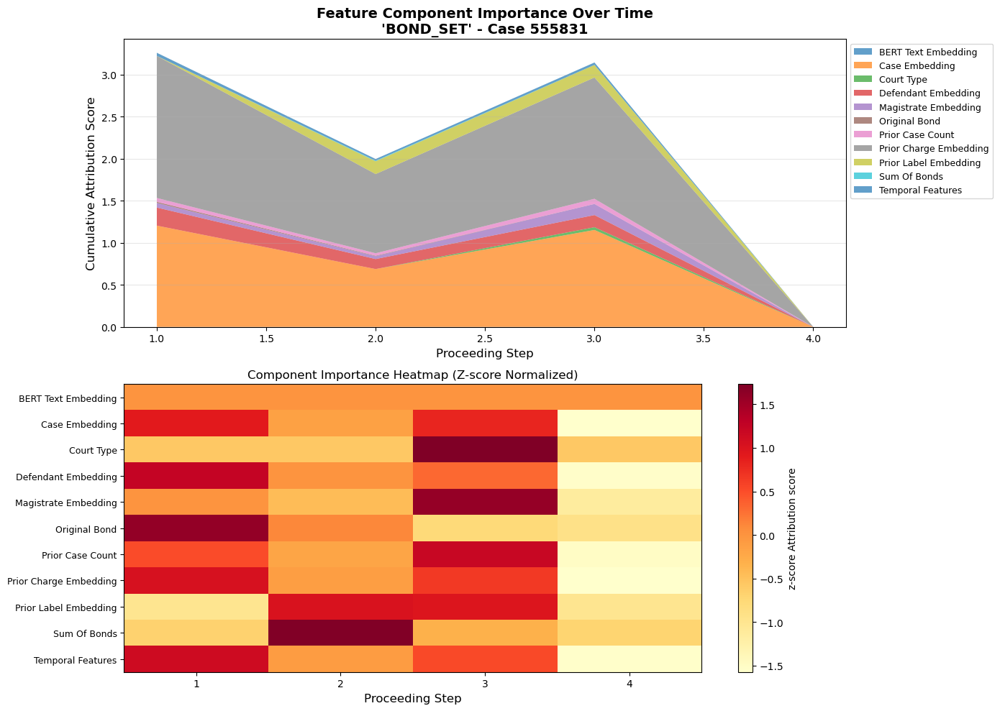


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 4 for class index 1 at proceeding index 2
   Attribution shape: torch.Size([1, 4, 1548])
   Convergence delta: 0.0137576162815094
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution Target_Label
5   Prior_Charge_Embedding           4.080719          1.020180         1.685966         0.646613     BOND_SET
1           Case_Embedding           3.046339          0.761585         1.200443         0.483156     BOND_SET
0      Defendant_Embedding           0.478758          0.119690         0.214528         0.077378     BOND_SET
4    Prior_Label_Embedding           0.302175          0.075544         0.152732         0.075303     BOND_SET
3     Magistrate_Embedding           0.222183          0.055546         0.132608         0.048759     BOND_SET
9         Prior_Case_Count           0.135119          0.033780         0.060450         0.022461     BOND_SET
10       Temporal_Features

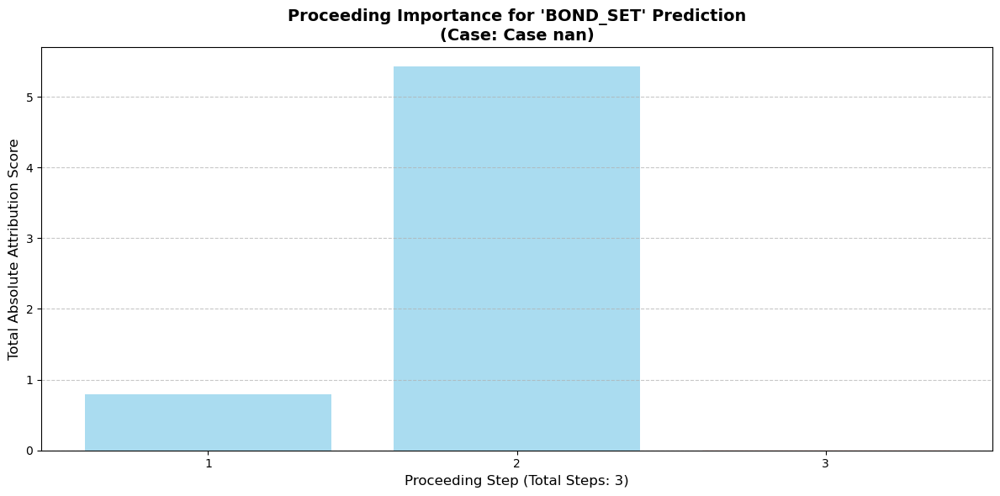

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_44.png


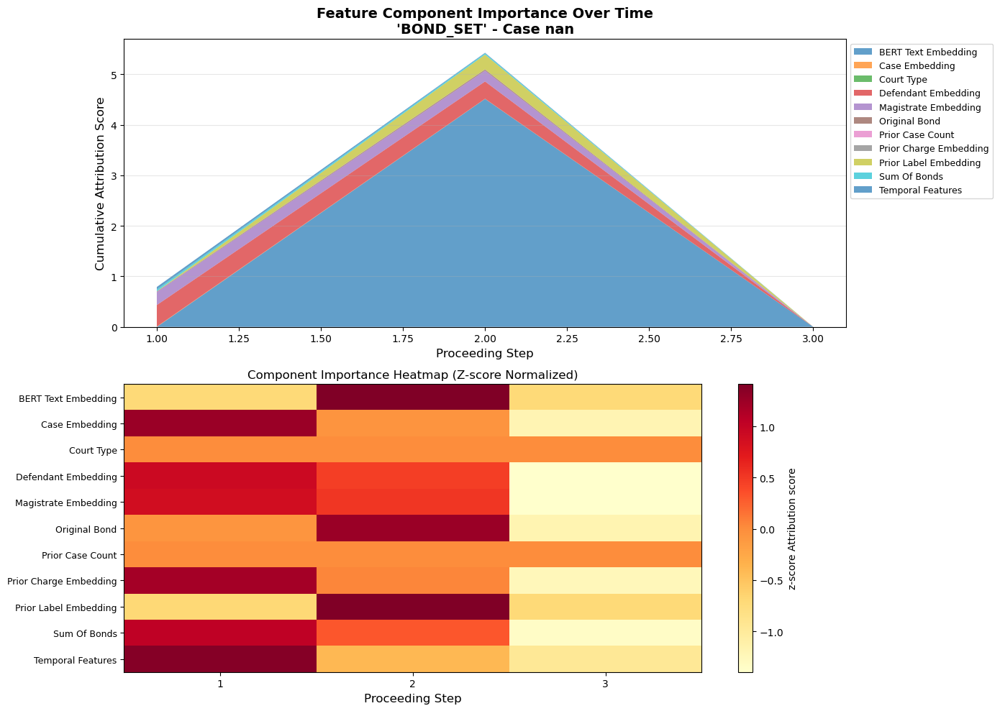


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 3 for class index 1 at proceeding index 1
   Attribution shape: torch.Size([1, 3, 1548])
   Convergence delta: -0.0006806254386901855
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution Target_Label
2      BERT_Text_Embedding           4.514555          1.504852         4.514555         2.128182     BOND_SET
0      Defendant_Embedding           0.772872          0.257624         0.428661         0.185401     BOND_SET
3     Magistrate_Embedding           0.472500          0.157500         0.257103         0.112663     BOND_SET
4    Prior_Label_Embedding           0.294249          0.098083         0.293186         0.137959     BOND_SET
10       Temporal_Features           0.059907          0.019969         0.048495         0.020702     BOND_SET
8             Sum_Of_Bonds           0.059389          0.019796         0.035182         0.014698     BOND_SET
7            Original_

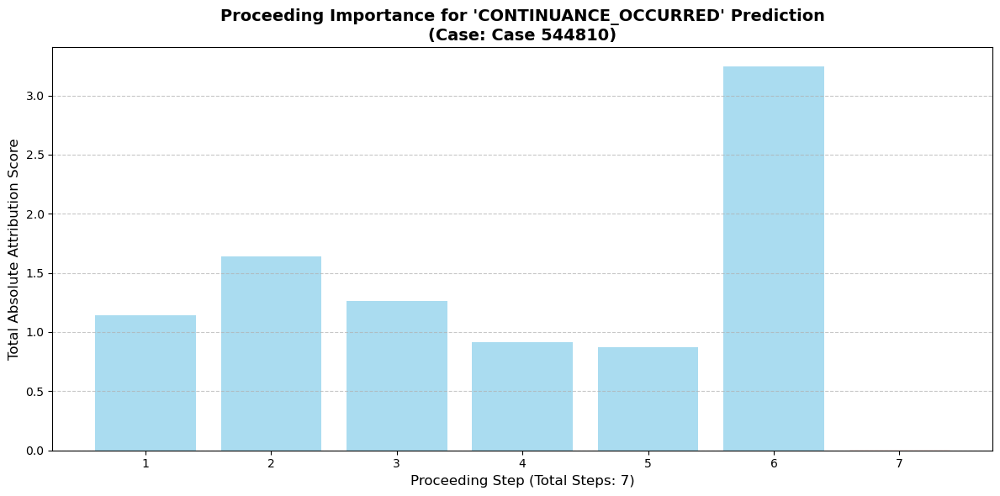

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_45.png


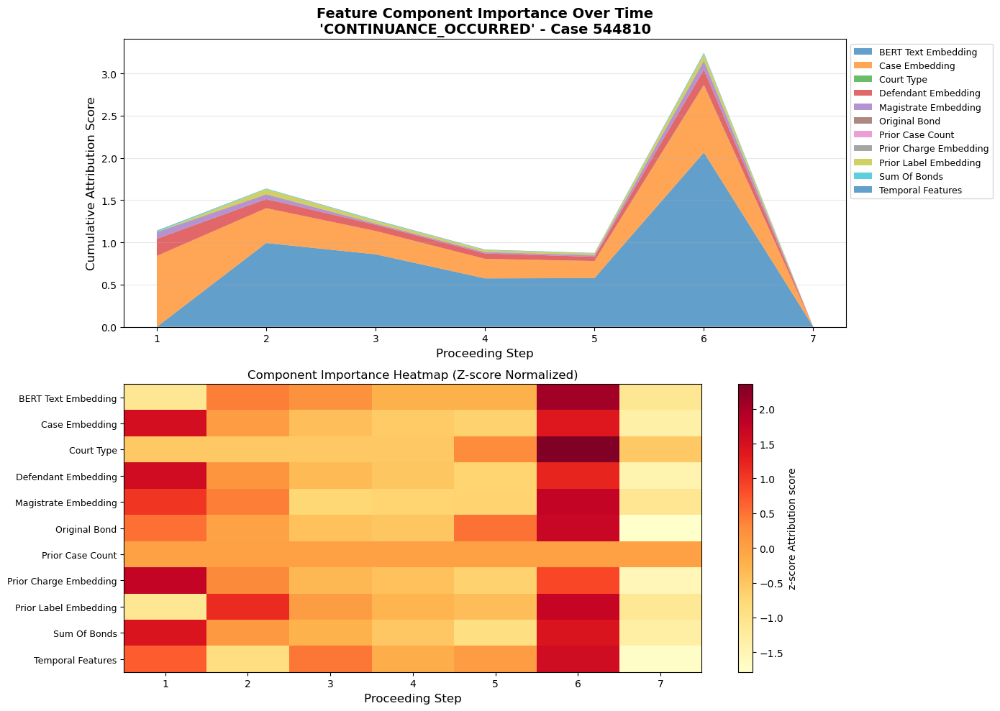


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 7 for class index 14 at proceeding index 5
   Attribution shape: torch.Size([1, 7, 1548])
   Convergence delta: 0.006050586700439453
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.063470          0.723353         2.063623         0.651975  CONTINUANCE_OCCURRED
1           Case_Embedding           2.755175          0.393596         0.841333         0.291570  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.675817          0.096545         0.203321         0.066671  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.265720          0.037960         0.098386         0.034598  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.212356          0.030337         0.076482         0.026906  CONTINUANCE_OCCURRED
8             Sum_Of_Bonds           0.036616          0.005231         0.011022

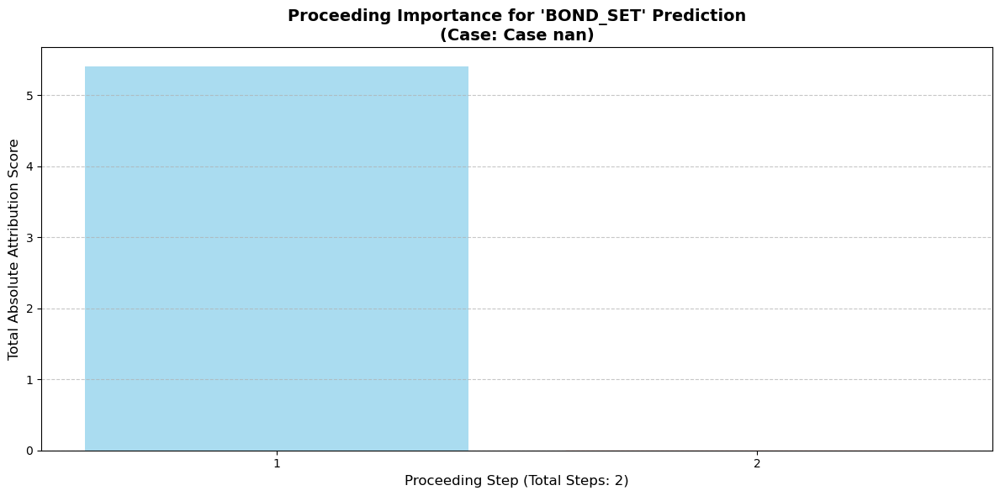

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_46.png


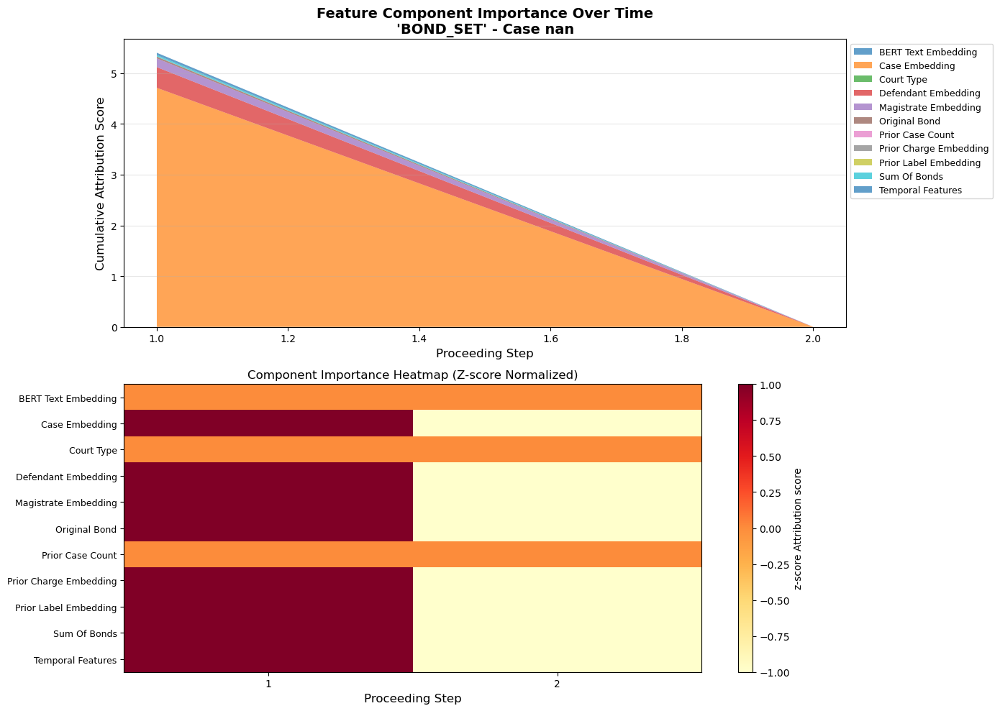


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 2 for class index 1 at proceeding index 0
   Attribution shape: torch.Size([1, 2, 1548])
   Convergence delta: 0.004027038812637329
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution Target_Label
1           Case_Embedding           4.717194          2.358597         4.717194         2.358597     BOND_SET
0      Defendant_Embedding           0.406466          0.203233         0.406466         0.203233     BOND_SET
3     Magistrate_Embedding           0.173011          0.086506         0.173011         0.086506     BOND_SET
10       Temporal_Features           0.045086          0.022543         0.045086         0.022543     BOND_SET
7            Original_Bond           0.030672          0.015336         0.030672         0.015336     BOND_SET
8             Sum_Of_Bonds           0.028035          0.014017         0.028035         0.014017     BOND_SET
5   Prior_Charge_Embeddi

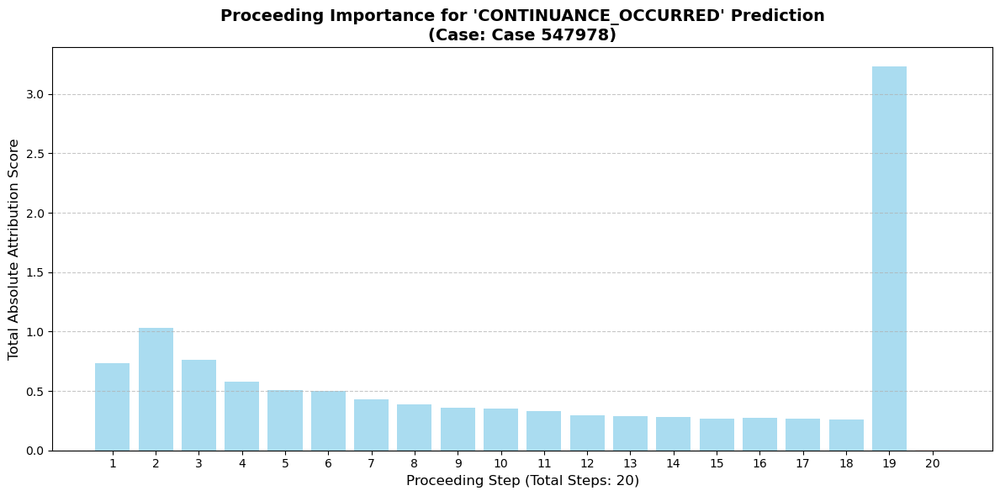

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_47.png


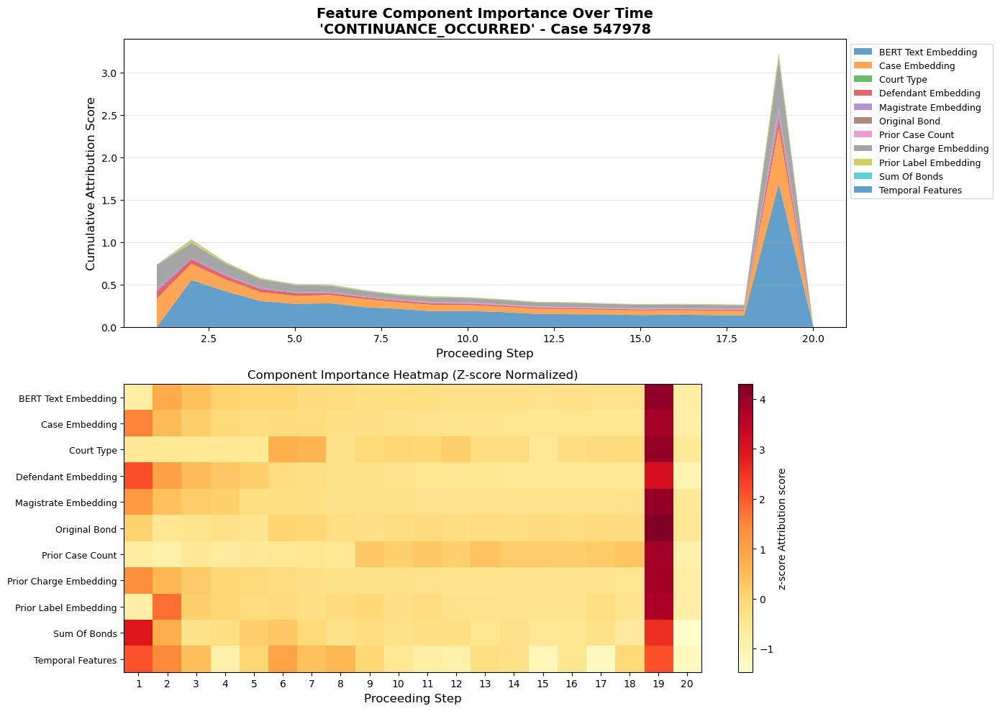


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 20 for class index 14 at proceeding index 18
   Attribution shape: torch.Size([1, 20, 1548])
   Convergence delta: -0.002913177013397217
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.512345          0.275617         1.690769         0.346948  CONTINUANCE_OCCURRED
1           Case_Embedding           2.393854          0.119693         0.656117         0.140061  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           2.028701          0.101435         0.579170         0.123942  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.559563          0.027978         0.112041         0.026762  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.233756          0.011688         0.066010         0.014441  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.226925          0.011346         0.08

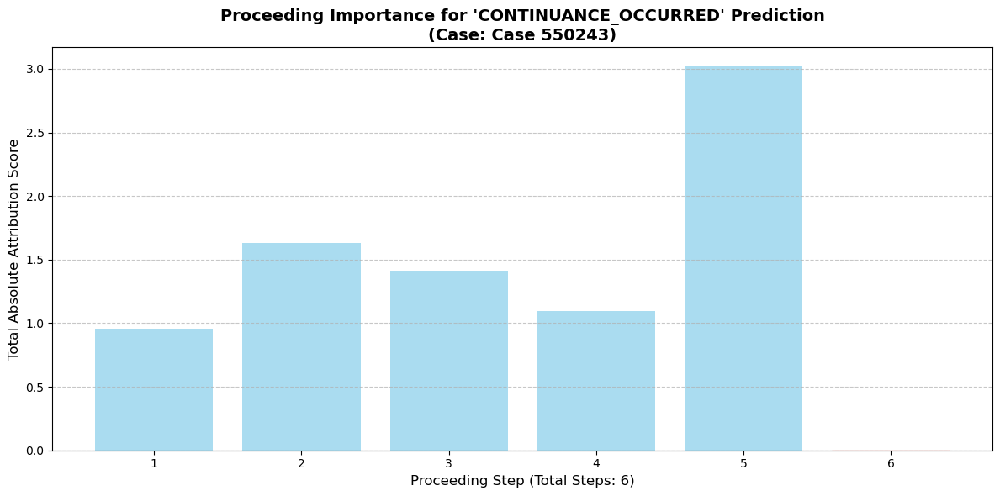

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_48.png


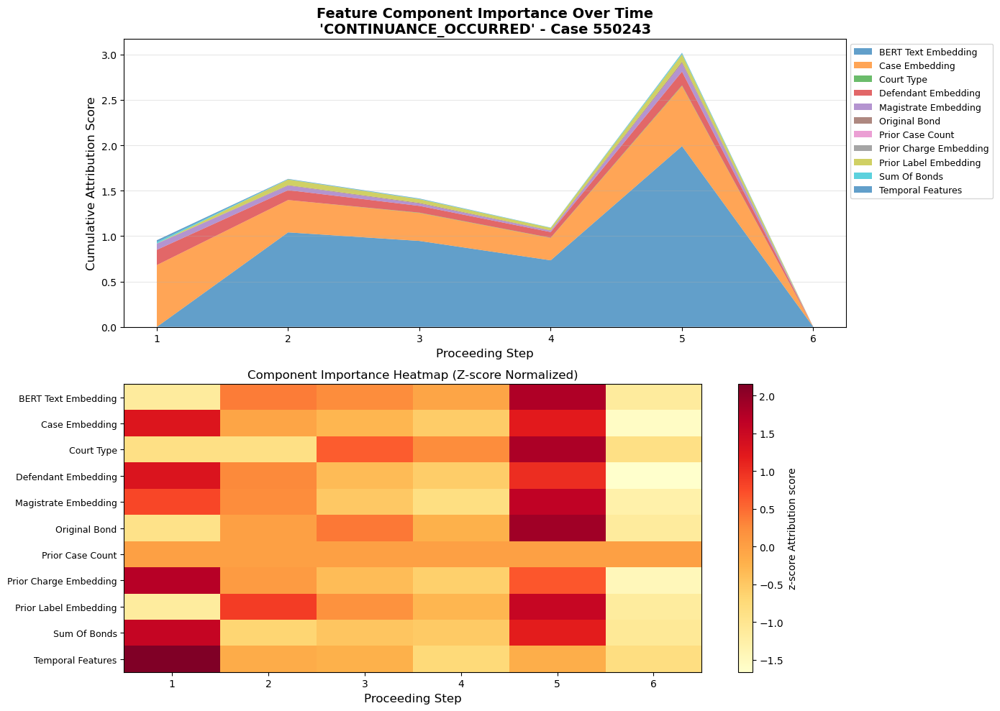


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 6 for class index 14 at proceeding index 4
   Attribution shape: torch.Size([1, 6, 1548])
   Convergence delta: 2.7626752853393555e-05
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           4.710339          0.785057         1.989993         0.680597  CONTINUANCE_OCCURRED
1           Case_Embedding           2.256998          0.376166         0.681875         0.237413  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.563878          0.093980         0.166863         0.056394  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.251525          0.041921         0.094064         0.032177  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.210231          0.035039         0.081052         0.029926  CONTINUANCE_OCCURRED
8             Sum_Of_Bonds           0.037723          0.006287         0.0152

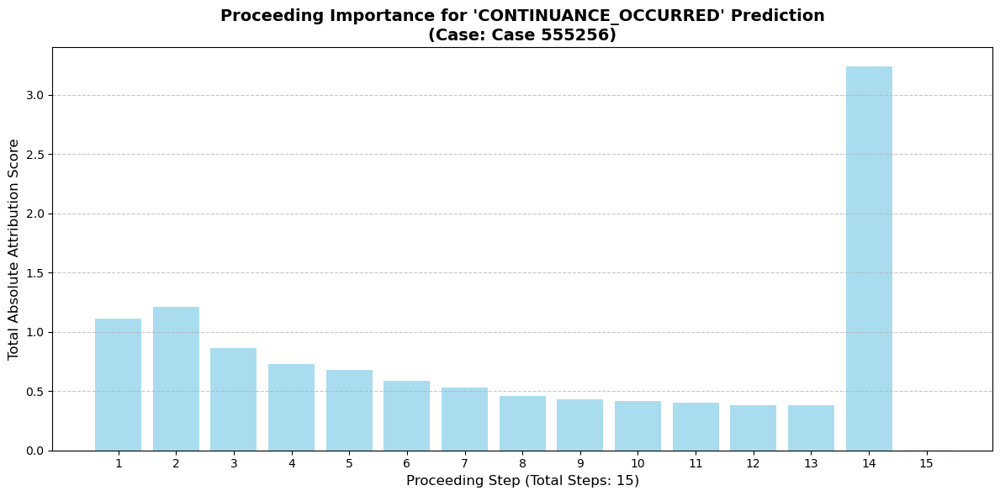

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_49.png


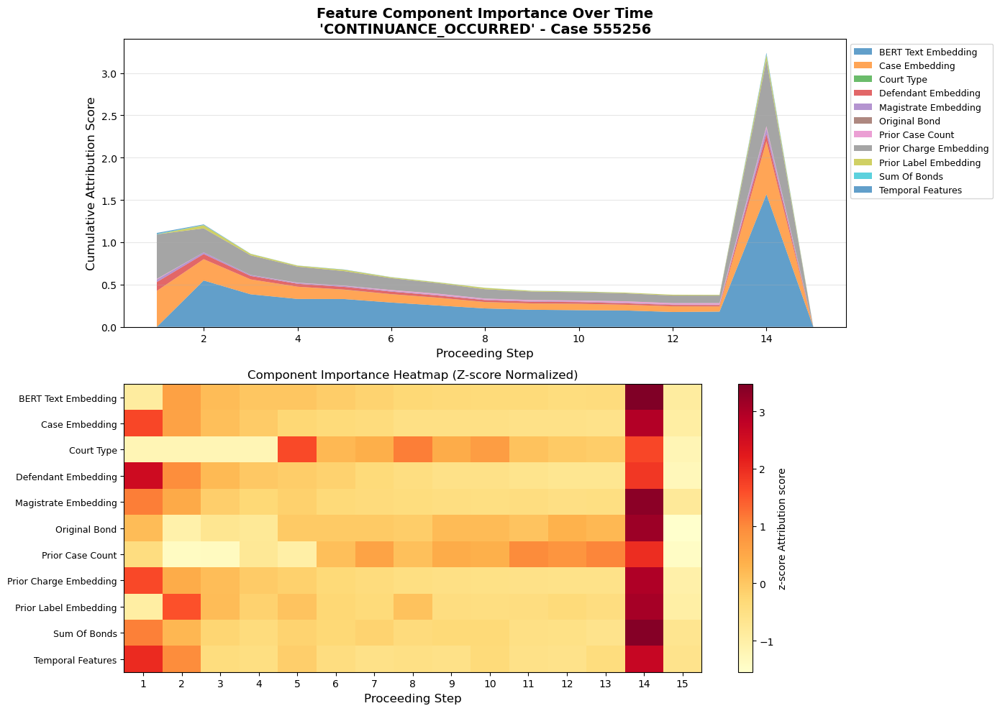


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 15 for class index 14 at proceeding index 13
   Attribution shape: torch.Size([1, 15, 1548])
   Convergence delta: 0.01218259334564209
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           4.876392          0.325093         1.568981         0.357900  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           3.031388          0.202093         0.781052         0.194251  CONTINUANCE_OCCURRED
1           Case_Embedding           2.342840          0.156189         0.624494         0.159278  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.524575          0.034972         0.104350         0.027241  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.216524          0.014435         0.059388         0.014642  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.184781          0.012319         0.0634

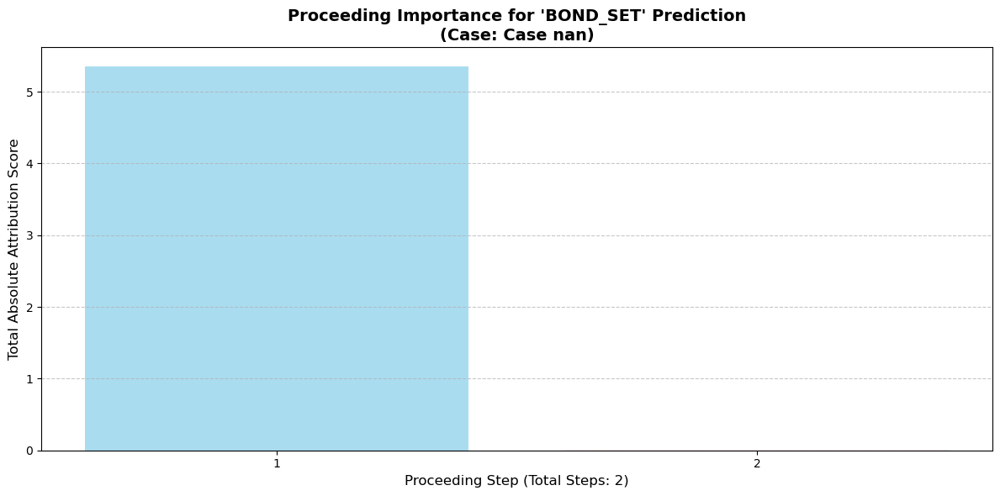

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_50.png


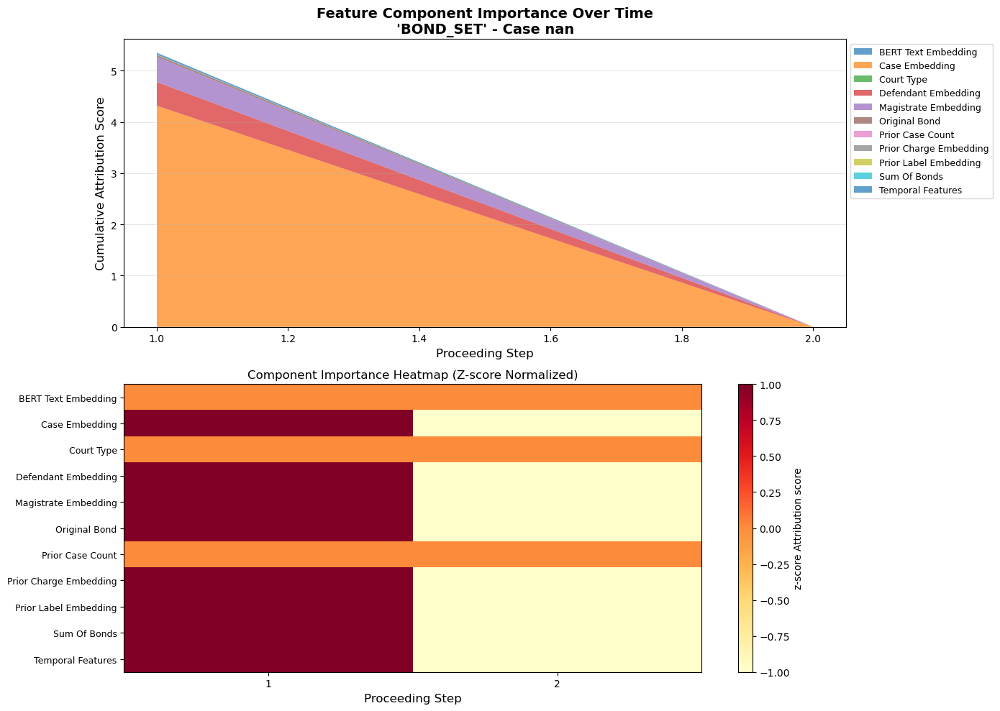


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 2 for class index 1 at proceeding index 0
   Attribution shape: torch.Size([1, 2, 1548])
   Convergence delta: 0.009576529264450073
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution Target_Label
1           Case_Embedding           4.312244          2.156122         4.312244         2.156122     BOND_SET
3     Magistrate_Embedding           0.495786          0.247893         0.495786         0.247893     BOND_SET
0      Defendant_Embedding           0.460946          0.230473         0.460946         0.230473     BOND_SET
7            Original_Bond           0.036343          0.018171         0.036343         0.018171     BOND_SET
10       Temporal_Features           0.033224          0.016612         0.033224         0.016612     BOND_SET
5   Prior_Charge_Embedding           0.006272          0.003136         0.006272         0.003136     BOND_SET
8             Sum_Of_Bon

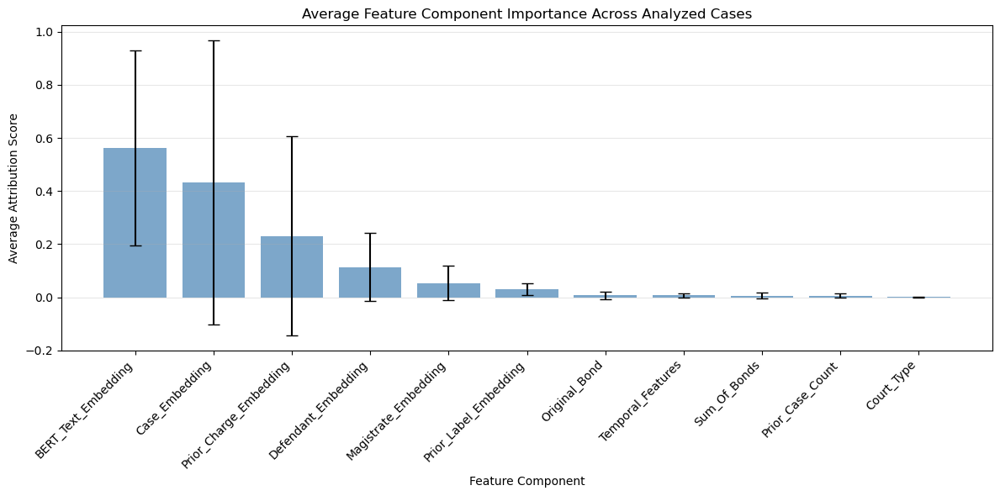


âœ… Aggregate analysis complete!

ANALYZING ALL 20 LABELS (not just first 5)

LABEL-SPECIFIC FEATURE ANALYSIS

ðŸ·ï¸ Analyzing feature importance for labels: ['FIRST_APPEARANCE_HEARING_OCCURRED', 'BOND_SET', 'BOND_NOT_SET', 'DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE', 'THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER', 'ANKLE_MONITORING_IMPOSED', 'DOMESTIC_STAY_AWAY_ORDER_IMPOSED', 'CHARGES_ACCEPTED', 'CHARGES_REFUSED', 'PROBABLE_CAUSE_FOUND', 'PROBABLE_CAUSE_NOT_FOUND', 'DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT', 'THE_STATE_WAS_NOT_PRESENT', 'PRE_TRIAL_CONFERENCE_HELD', 'CONTINUANCE_OCCURRED', 'PLED_GUILTY_TO_CHARGES', 'PLED_NOT_GUILTY_TO_CHARGES', 'TRIAL_VERDICT_REACHED', 'SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED', 'SENTENCE_THAT_DOES_NOT_INCLUDE_JAIL_TIME_WAS_IMPOSED']
[1/20] Analyzing label: FIRST_APPEARANCE_HEARING_OCCURRED (index: 0)
   Found in sequence 0, proceeding 0
🔍 Attributing sequence of length 11 for class index 0 at proceeding index 0
   Attribution shape: torch.Size([1

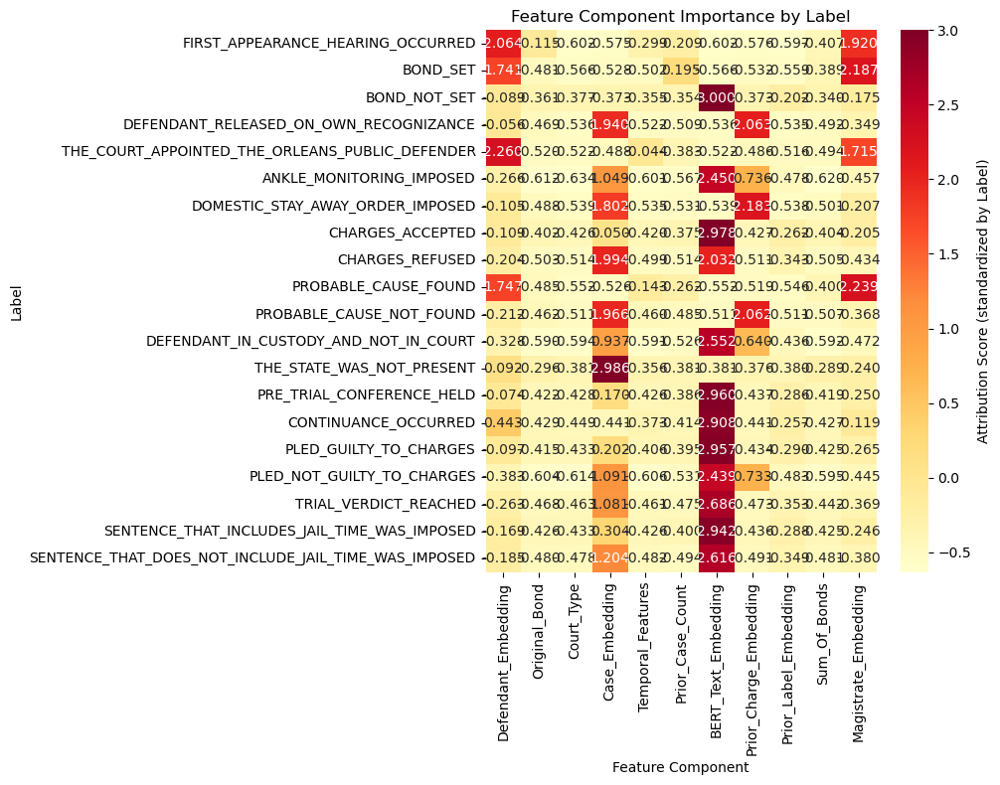


âœ… Label-specific analysis complete!
  Fold 2...
Analyzing date range in data...
MAG data - Date range: 2008-11-28 00:00:00 to 2025-12-04 00:00:00, Count: 86075
CDC data - Date range: 2018-03-07 00:00:00 to 2025-12-30 00:00:00, Count: 83304
Overall date range in data: 2008 - 2025
Date range updated: 2008 to 2025
Date range in data: 2008 to 2025
Using MIN_YEAR=2008, NUM_YEARS=18
Updated temporal dimensions: 216 features (12 months × 18 years)
Creating charge vocabulary from charges DataFrame with 2139 unique charges
Found 5 unique magistrate sections in mag data.
Creating magistrate vocabulary of size 5
Checking BERT embeddings cache...
BERT embeddings cache found.
CaseTransformerModel(
  (text_emb): StreamingCachedBertEmbedding(
    (projector): Identity()
  )
  (def_emb): DefendantRoleEmbedding(
    (race_emb): Embedding(6, 8)
    (gender_emb): Embedding(3, 8)
    (age_linear): Linear(in_features=1, out_features=8, bias=True)
    (fuse): Sequential(
      (0): Linear(in_features=24,

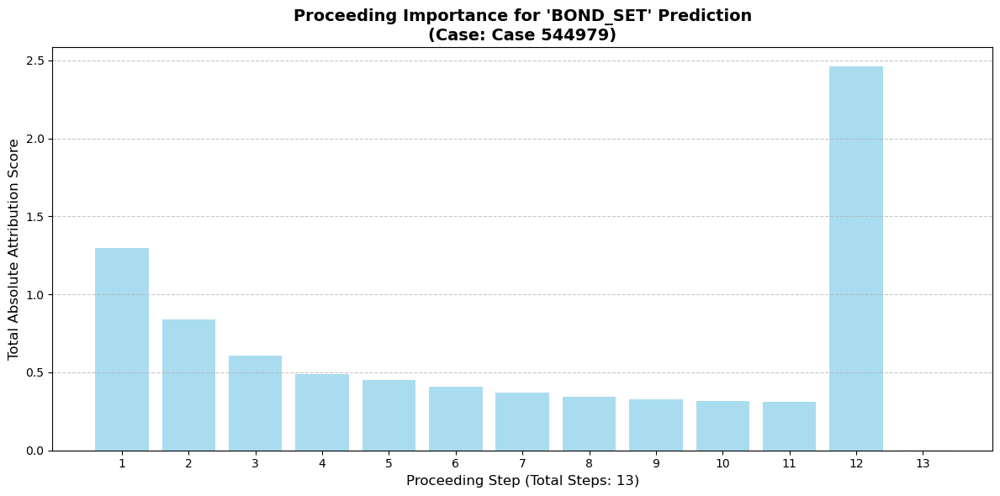

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_1.png


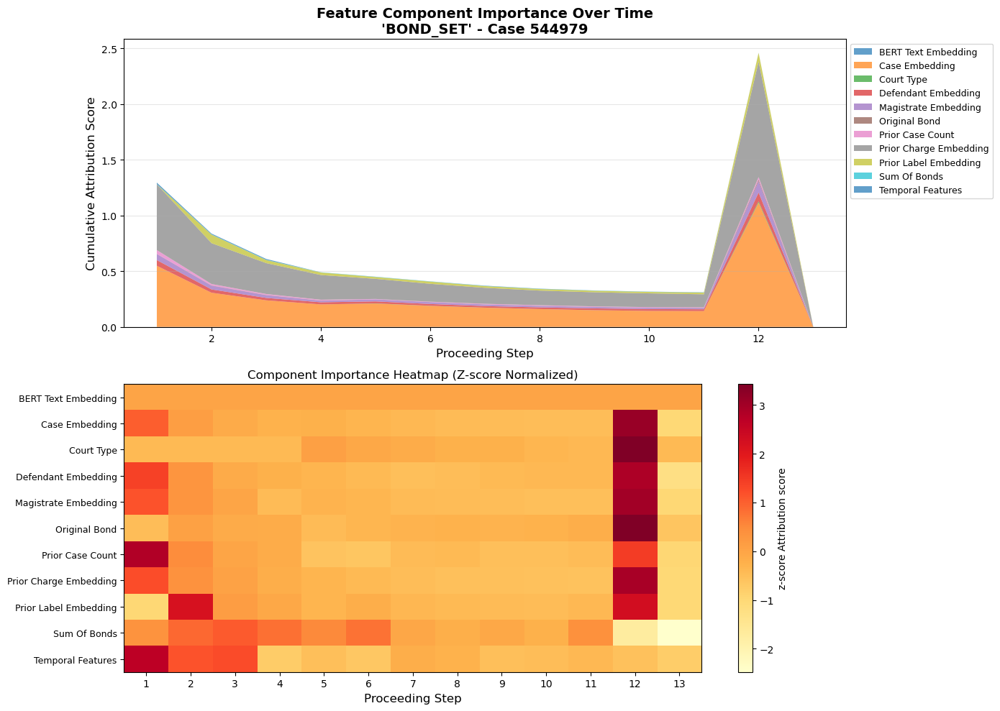


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 13 for class index 1 at proceeding index 11
   Attribution shape: torch.Size([1, 13, 1548])
   Convergence delta: -0.004133701324462891
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution Target_Label
1           Case_Embedding           3.580661          0.275435         1.114611         0.270536     BOND_SET
5   Prior_Charge_Embedding           3.470747          0.266981         1.035644         0.262142     BOND_SET
3     Magistrate_Embedding           0.328543          0.025273         0.102862         0.025748     BOND_SET
4    Prior_Label_Embedding           0.313160          0.024089         0.078529         0.023955     BOND_SET
0      Defendant_Embedding           0.310619          0.023894         0.078132         0.019104     BOND_SET
9         Prior_Case_Count           0.114641          0.008819         0.034572         0.009032     BOND_SET
10       Temporal_Fe

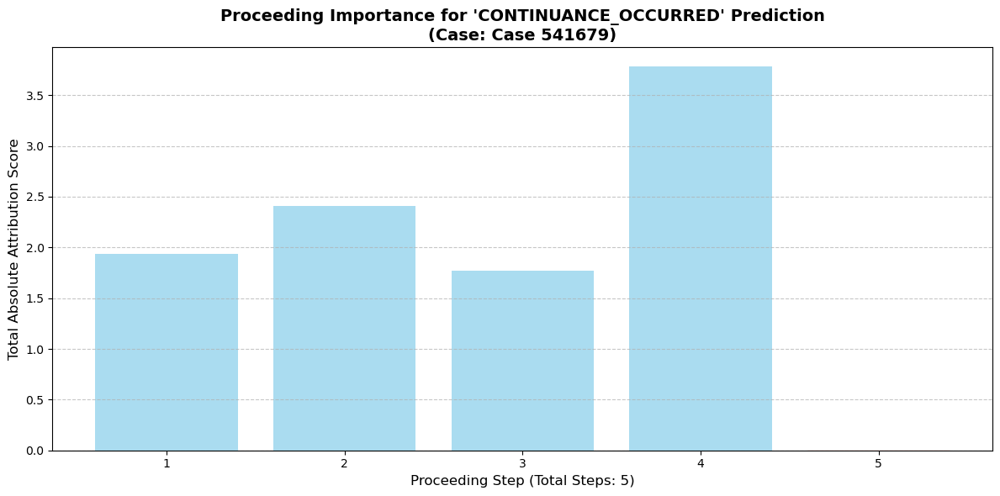

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_2.png


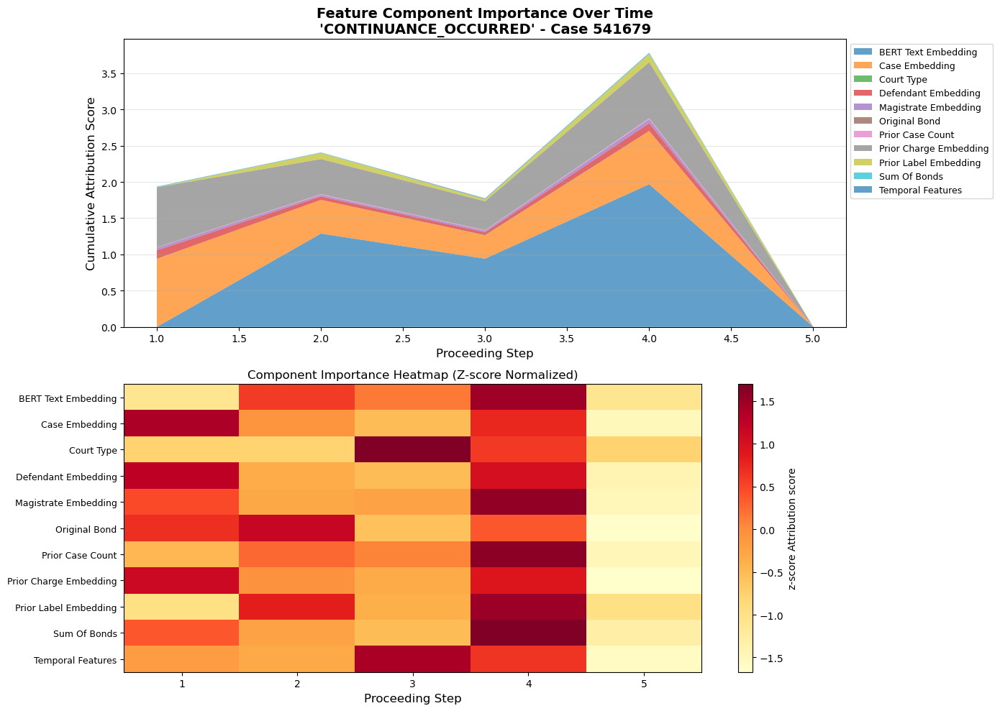


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 5 for class index 14 at proceeding index 3
   Attribution shape: torch.Size([1, 5, 1548])
   Convergence delta: -0.003602266311645508
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           4.193840          0.838768         1.964159         0.759514  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           2.481789          0.496358         0.822428         0.296791  CONTINUANCE_OCCURRED
1           Case_Embedding           2.460661          0.492132         0.940610         0.326516  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.307585          0.061517         0.118339         0.043955  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.224518          0.044904         0.113483         0.045806  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.134525          0.026905         0.05536

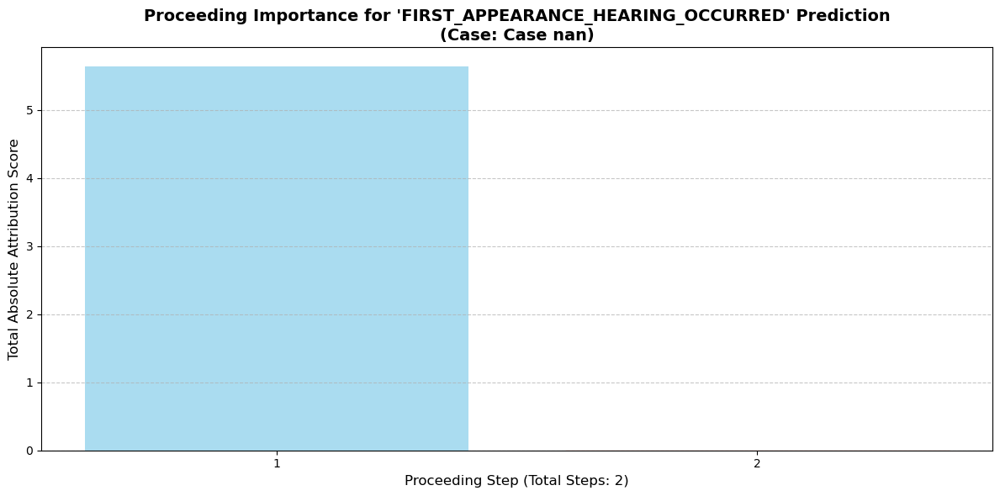

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_3.png


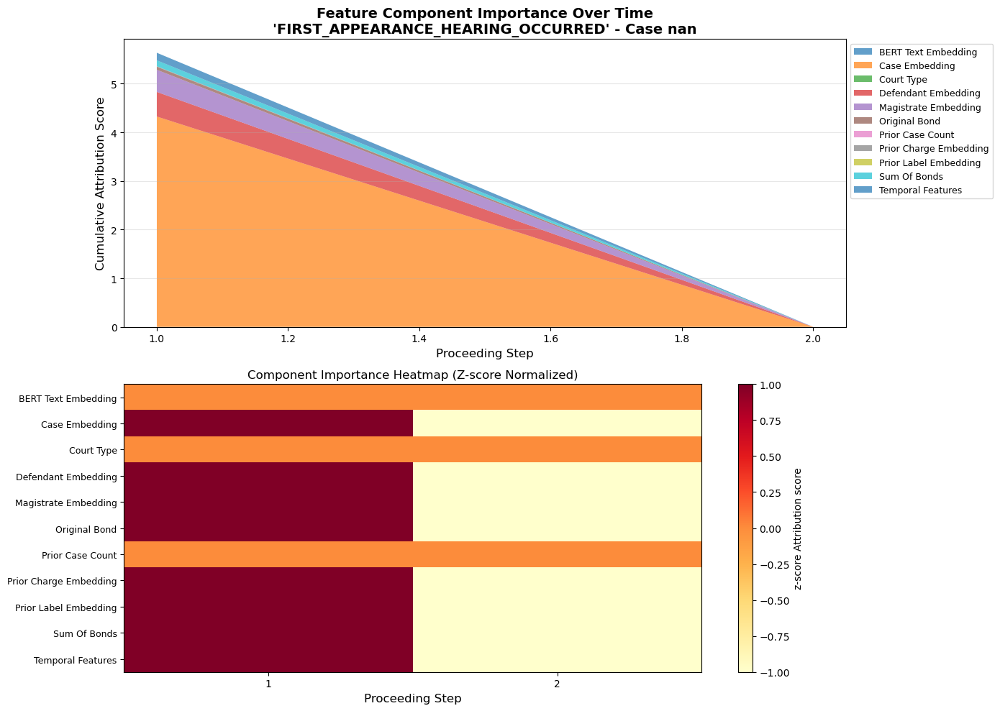


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 2 for class index 0 at proceeding index 0
   Attribution shape: torch.Size([1, 2, 1548])
   Convergence delta: -0.010762900114059448
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution                       Target_Label
1           Case_Embedding           4.306138          2.153069         4.306138         2.153069  FIRST_APPEARANCE_HEARING_OCCURRED
0      Defendant_Embedding           0.508961          0.254480         0.508961         0.254480  FIRST_APPEARANCE_HEARING_OCCURRED
3     Magistrate_Embedding           0.456842          0.228421         0.456842         0.228421  FIRST_APPEARANCE_HEARING_OCCURRED
10       Temporal_Features           0.155028          0.077514         0.155028         0.077514  FIRST_APPEARANCE_HEARING_OCCURRED
8             Sum_Of_Bonds           0.122266          0.061133         0.122266         0.061133  FIRST_APPEARANCE_HEARING_OCCURRED
7 

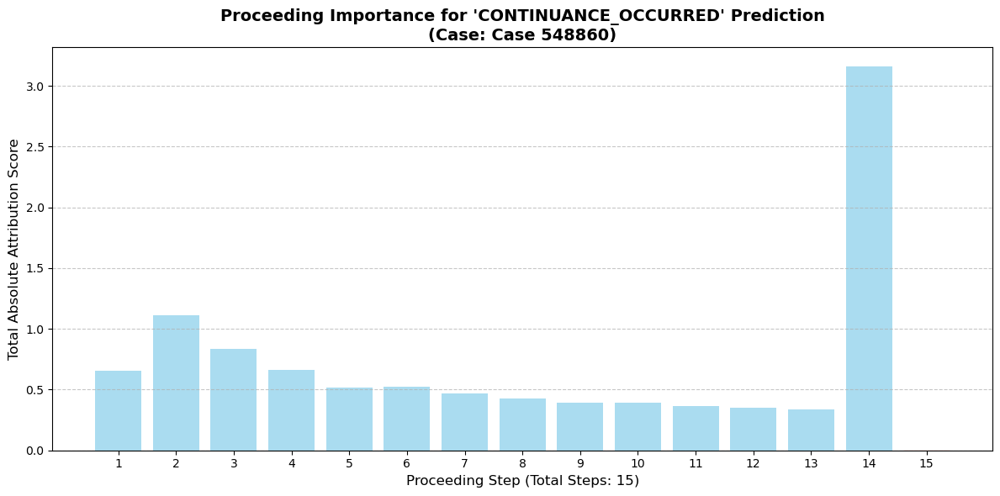

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_4.png


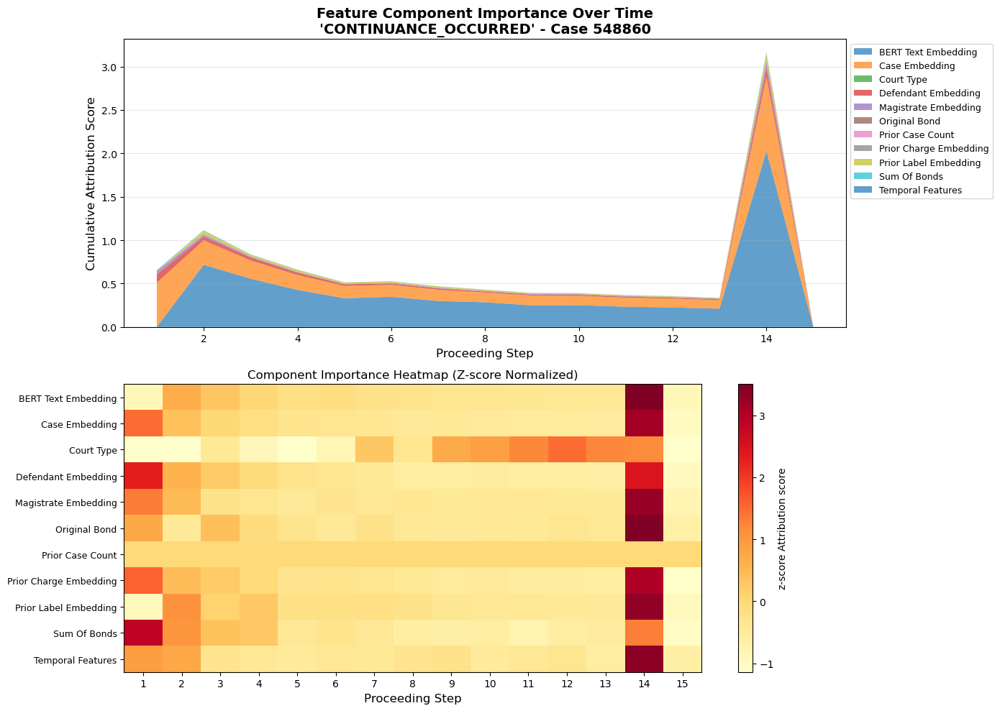


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 15 for class index 14 at proceeding index 13
   Attribution shape: torch.Size([1, 15, 1548])
   Convergence delta: -0.010978400707244873
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           6.150975          0.410065         2.028122         0.466546  CONTINUANCE_OCCURRED
1           Case_Embedding           3.070991          0.204733         0.857322         0.206612  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.425915          0.028394         0.101065         0.029453  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.279930          0.018662         0.085375         0.020166  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.202351          0.013490         0.068722         0.016926  CONTINUANCE_OCCURRED
10       Temporal_Features           0.026667          0.001778         0.01

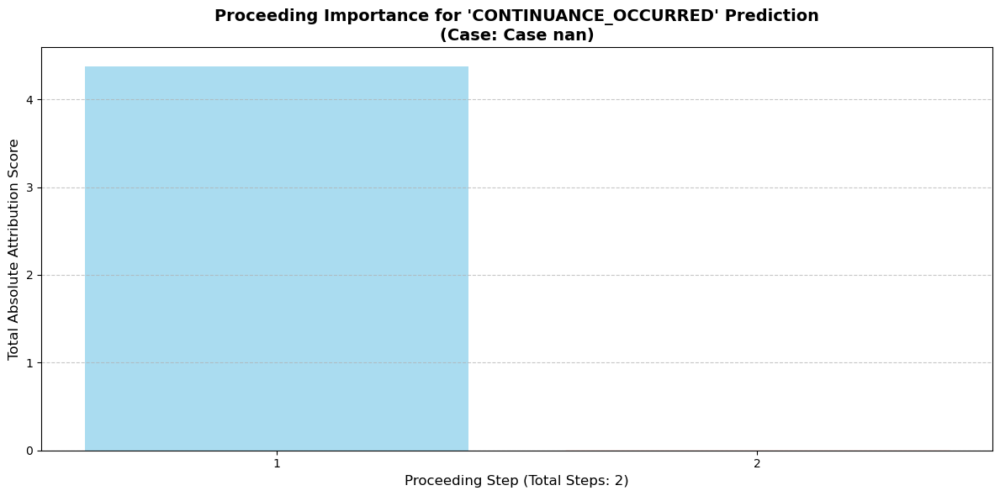

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_5.png


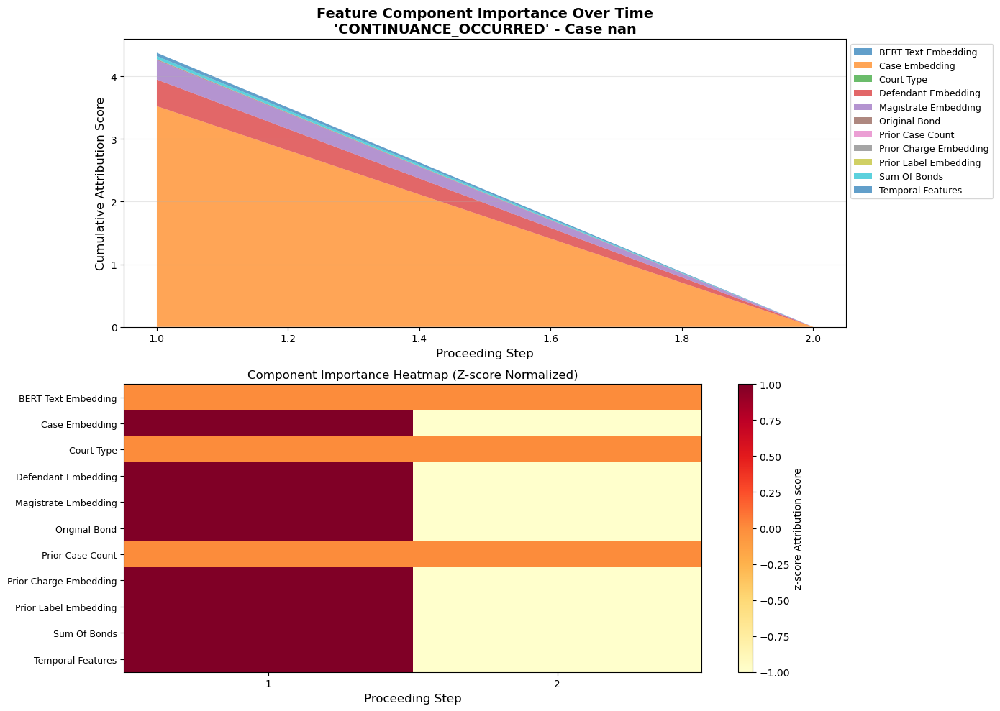


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 2 for class index 14 at proceeding index 0
   Attribution shape: torch.Size([1, 2, 1548])
   Convergence delta: 0.00533980131149292
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
1           Case_Embedding           3.523273          1.761636         3.523273         1.761636  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.418764          0.209382         0.418764         0.209382  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.311413          0.155707         0.311413         0.155707  CONTINUANCE_OCCURRED
10       Temporal_Features           0.053189          0.026594         0.053189         0.026594  CONTINUANCE_OCCURRED
8             Sum_Of_Bonds           0.046323          0.023161         0.046323         0.023161  CONTINUANCE_OCCURRED
7            Original_Bond           0.009785          0.004893         0.009785 

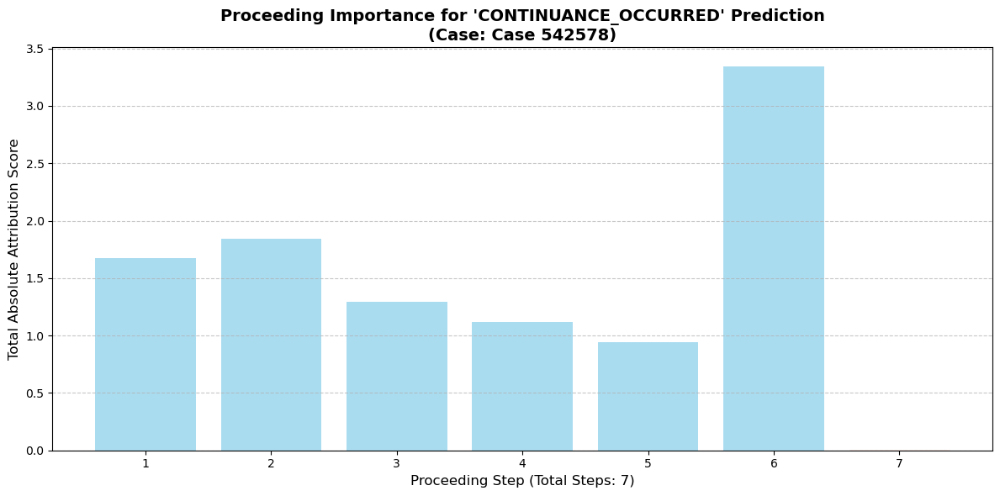

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_6.png


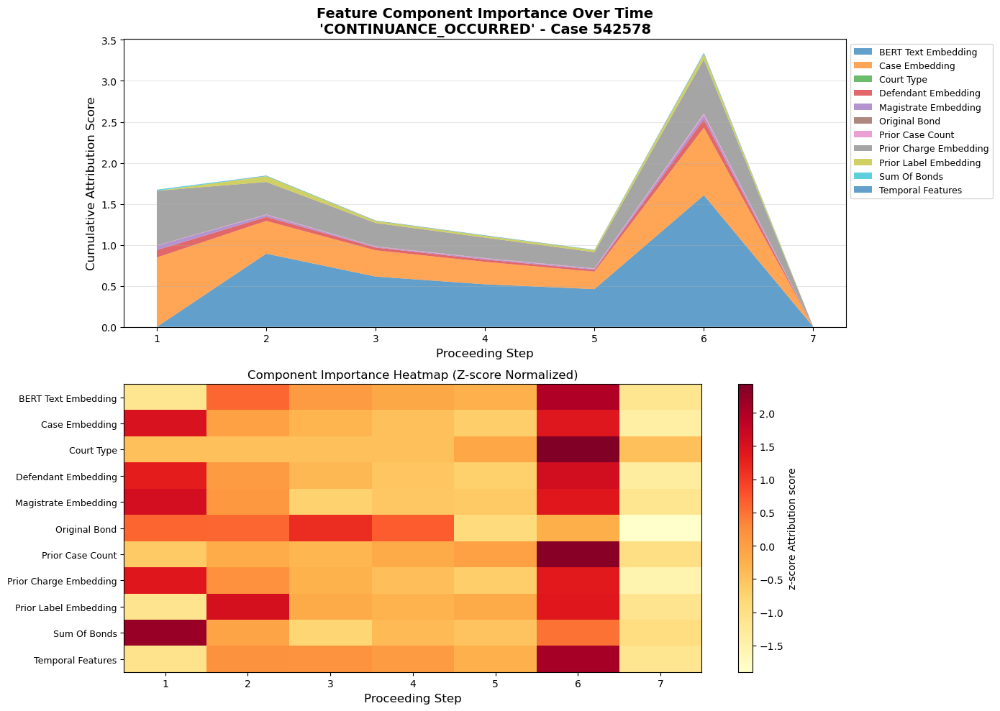


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 7 for class index 14 at proceeding index 5
   Attribution shape: torch.Size([1, 7, 1548])
   Convergence delta: -0.0030289888381958008
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           4.092462          0.584637         1.603802         0.512542  CONTINUANCE_OCCURRED
1           Case_Embedding           2.876175          0.410882         0.845300         0.290914  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           2.445804          0.349401         0.663958         0.225397  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.321954          0.045993         0.100728         0.034204  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.206102          0.029443         0.069474         0.025872  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.161649          0.023093         0.0544

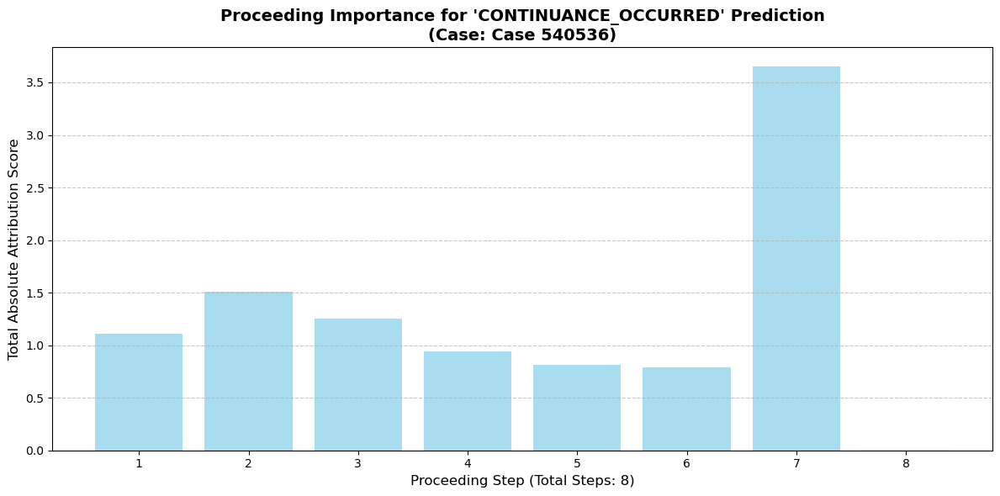

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_7.png


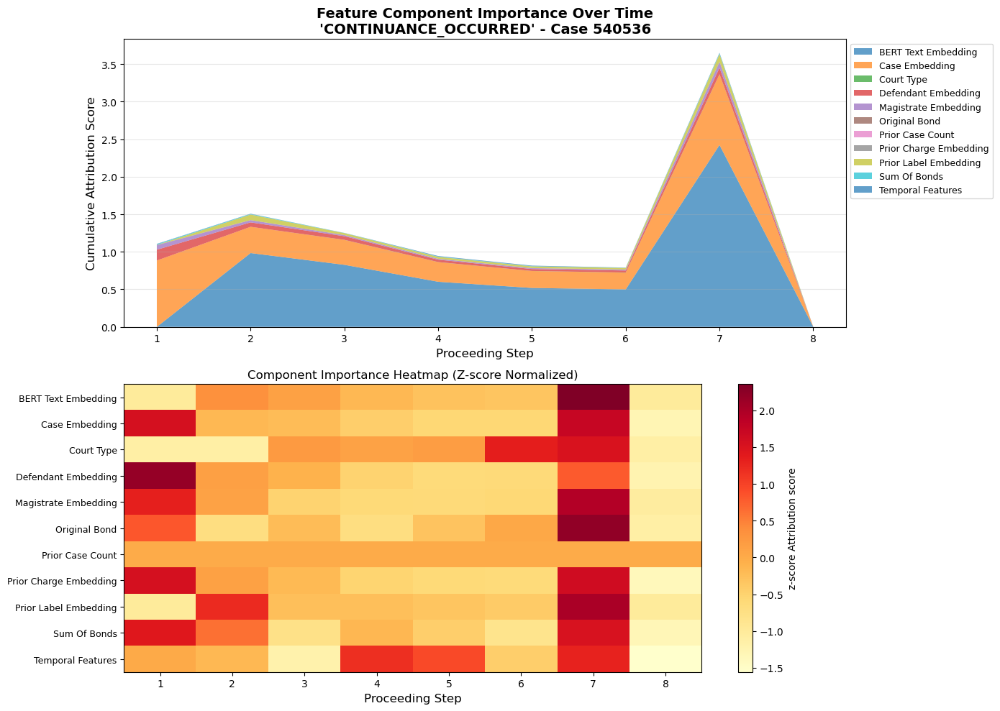


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 8 for class index 14 at proceeding index 6
   Attribution shape: torch.Size([1, 8, 1548])
   Convergence delta: 0.009182929992675781
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.857186          0.732148         2.422410         0.717484  CONTINUANCE_OCCURRED
1           Case_Embedding           3.220345          0.402543         0.940663         0.311418  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.422902          0.052863         0.144226         0.042262  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.268866          0.033608         0.100557         0.033130  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.211235          0.026404         0.074318         0.024861  CONTINUANCE_OCCURRED
8             Sum_Of_Bonds           0.038685          0.004836         0.010303

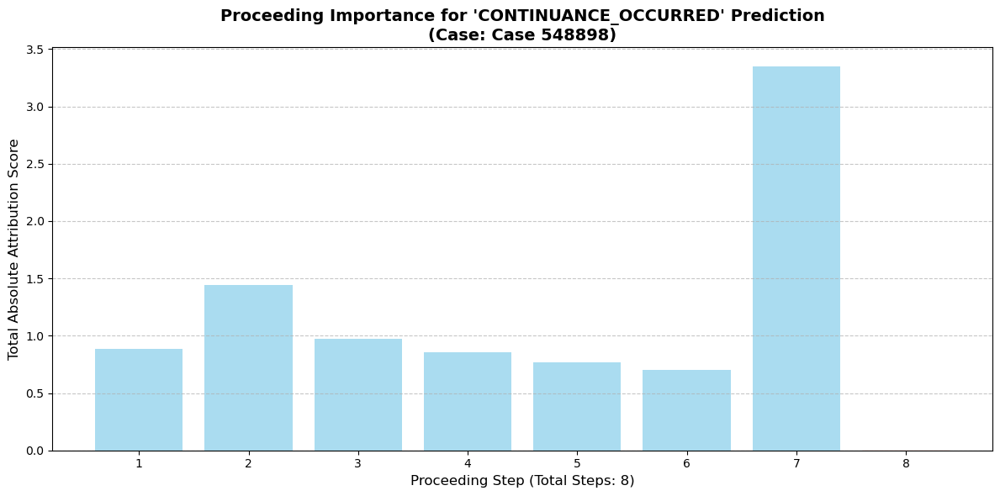

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_8.png


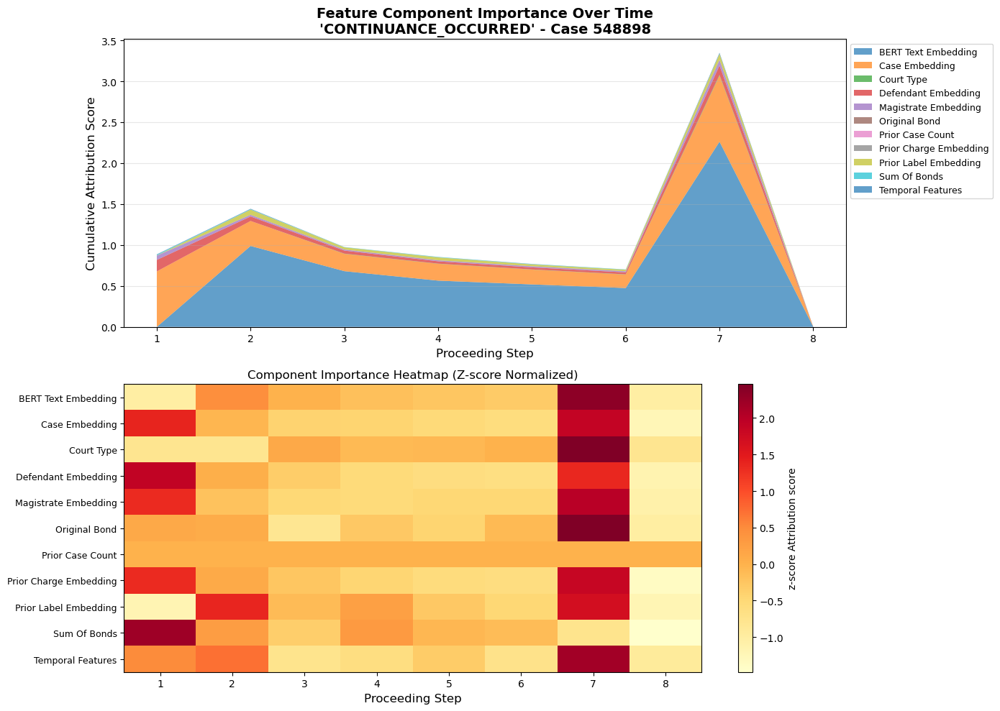


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 8 for class index 14 at proceeding index 6
   Attribution shape: torch.Size([1, 8, 1548])
   Convergence delta: -0.00961083173751831
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.487535          0.685942         2.256636         0.669572  CONTINUANCE_OCCURRED
1           Case_Embedding           2.555384          0.319423         0.807112         0.258752  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.423509          0.052939         0.140047         0.045597  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.235668          0.029458         0.070552         0.024356  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.185870          0.023234         0.065224         0.021130  CONTINUANCE_OCCURRED
10       Temporal_Features           0.028327          0.003541         0.012020

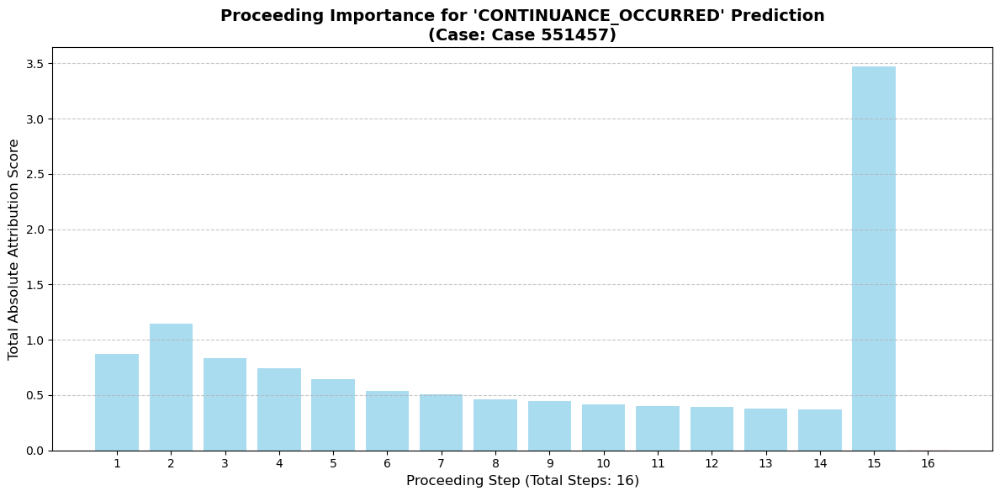

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_9.png


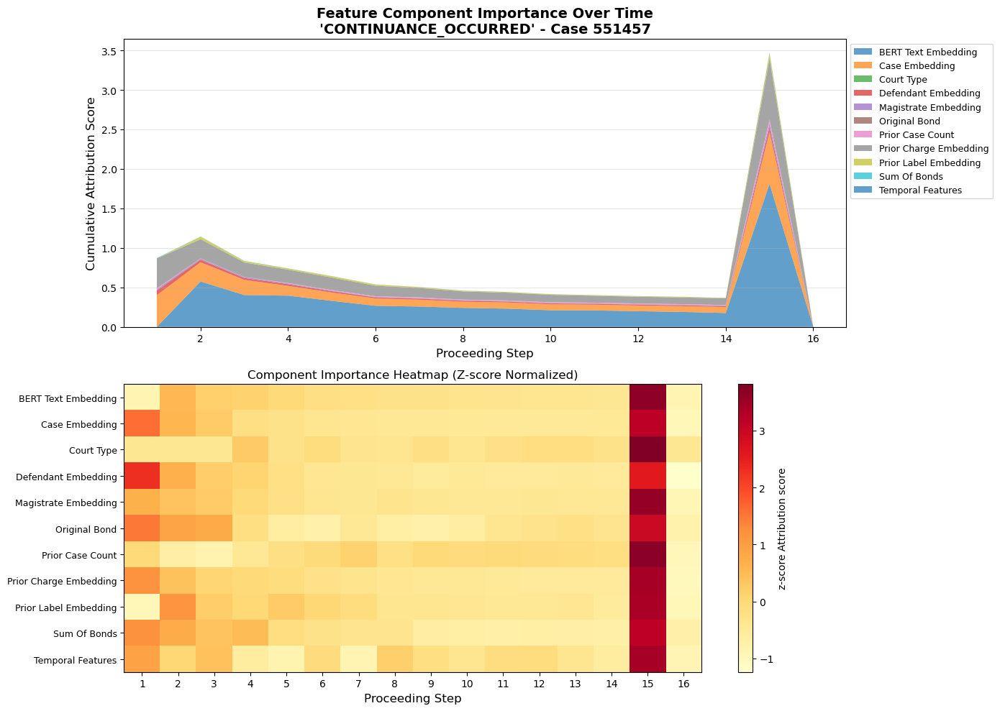


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 16 for class index 14 at proceeding index 14
   Attribution shape: torch.Size([1, 16, 1548])
   Convergence delta: 0.0008762478828430176
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.497123          0.343570         1.813353         0.403199  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           2.792889          0.174556         0.773865         0.175091  CONTINUANCE_OCCURRED
1           Case_Embedding           2.417977          0.151124         0.650806         0.157547  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.324976          0.020311         0.062138         0.016389  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.221615          0.013851         0.062596         0.014437  CONTINUANCE_OCCURRED
9         Prior_Case_Count           0.158348          0.009897         0.04

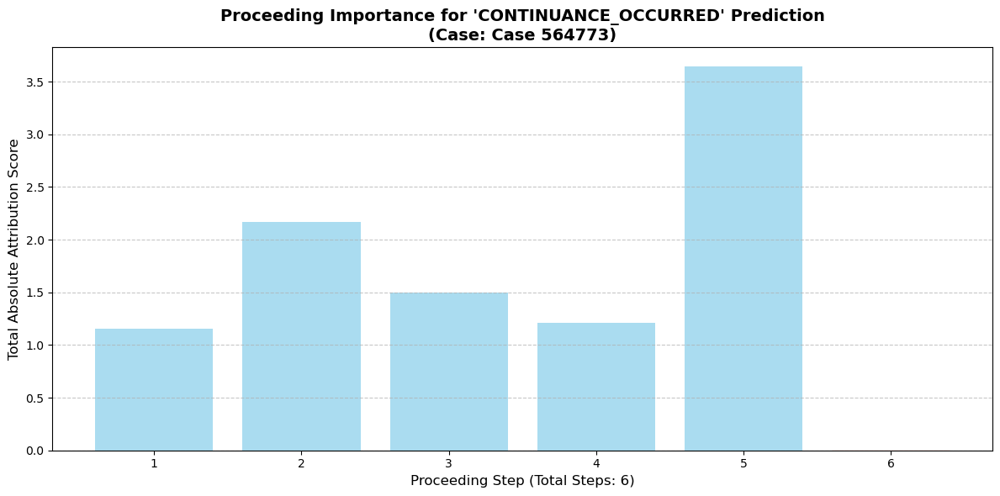

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_10.png


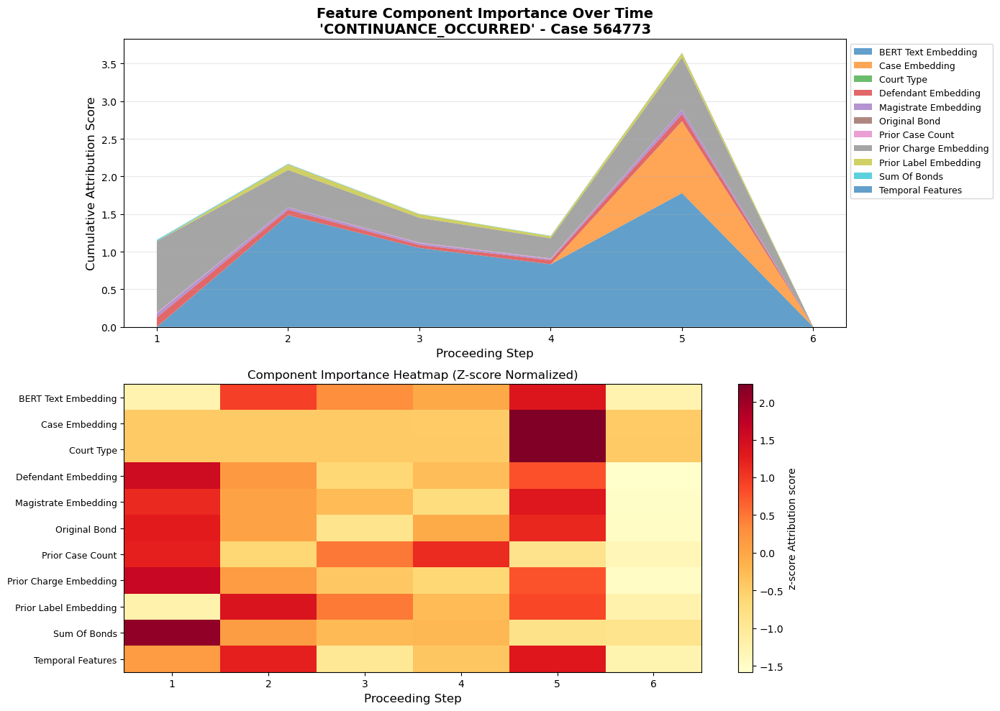


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 6 for class index 14 at proceeding index 4
   Attribution shape: torch.Size([1, 6, 1548])
   Convergence delta: -0.002333134412765503
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.139045          0.856508         1.777351         0.676499  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           2.730867          0.455145         0.949100         0.305622  CONTINUANCE_OCCURRED
1           Case_Embedding           0.951160          0.158527         0.947544         0.352860  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.378040          0.063007         0.124579         0.039834  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.207694          0.034616         0.073243         0.027951  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.186829          0.031138         0.05829

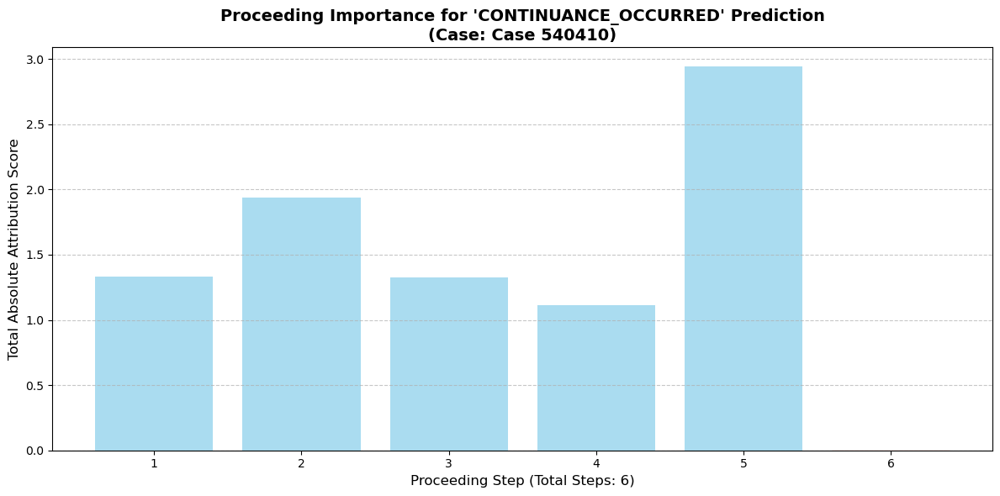

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_11.png


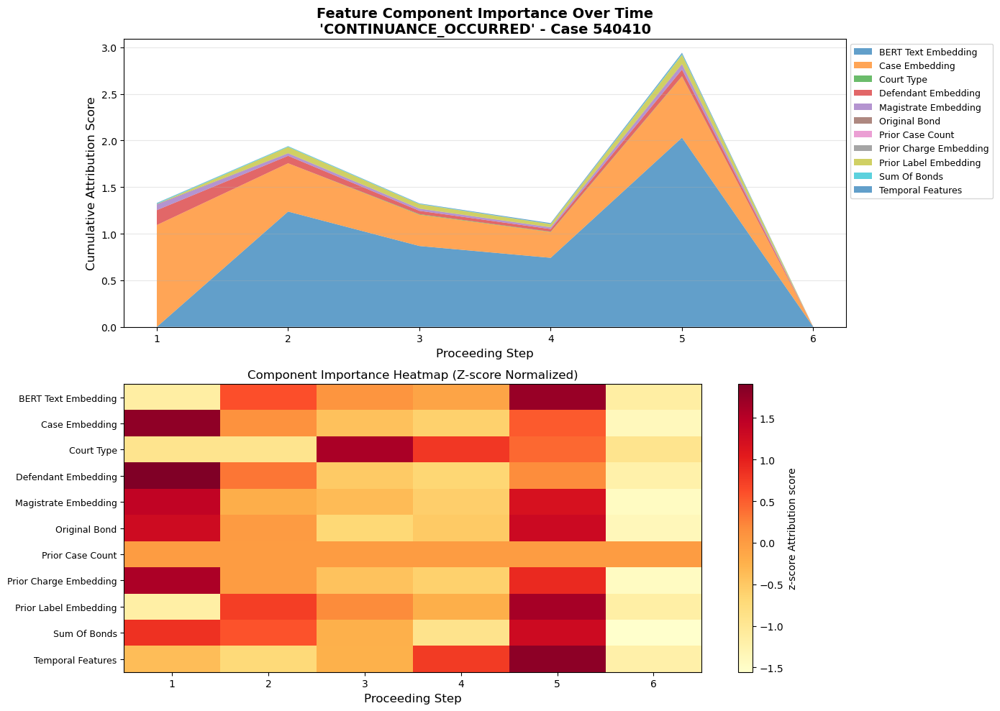


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 6 for class index 14 at proceeding index 4
   Attribution shape: torch.Size([1, 6, 1548])
   Convergence delta: -0.005096793174743652
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           4.878823          0.813137         2.029686         0.706188  CONTINUANCE_OCCURRED
1           Case_Embedding           2.877696          0.479616         1.093242         0.341185  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.372417          0.062069         0.157747         0.050461  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.244430          0.040738         0.097313         0.034775  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.178520          0.029753         0.058498         0.020589  CONTINUANCE_OCCURRED
10       Temporal_Features           0.031378          0.005230         0.01319

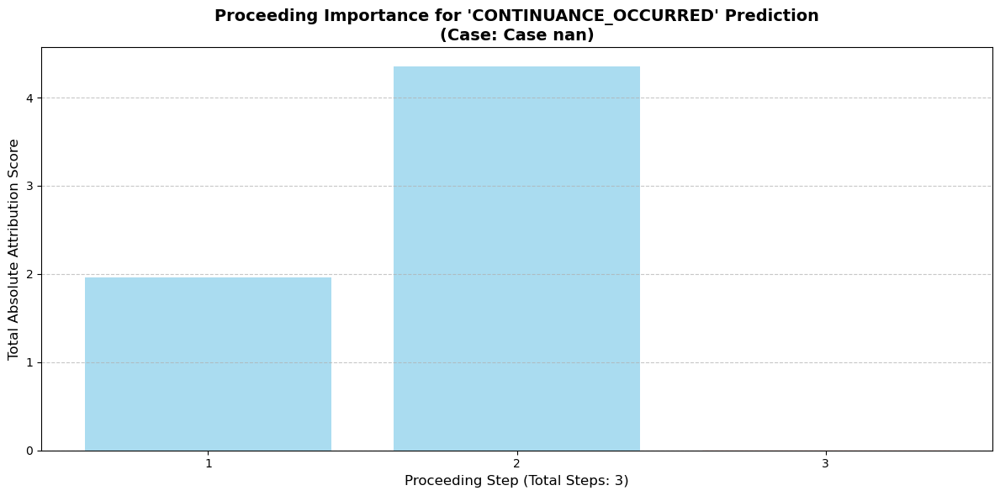

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_12.png


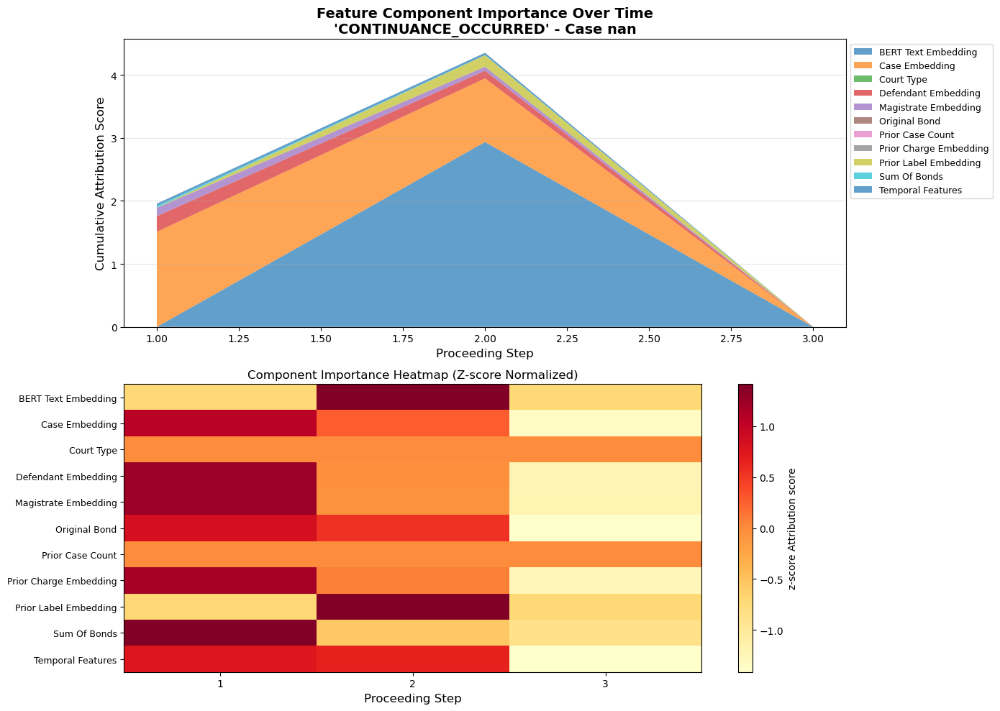


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 3 for class index 14 at proceeding index 1
   Attribution shape: torch.Size([1, 3, 1548])
   Convergence delta: -0.017857849597930908
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           2.924247          0.974749         2.924247         1.378503  CONTINUANCE_OCCURRED
1           Case_Embedding           2.516803          0.838934         1.507206         0.627036  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.366995          0.122332         0.248651         0.101551  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.191377          0.063792         0.129696         0.052969  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.181460          0.060487         0.180900         0.085146  CONTINUANCE_OCCURRED
10       Temporal_Features           0.073164          0.024388         0.03788

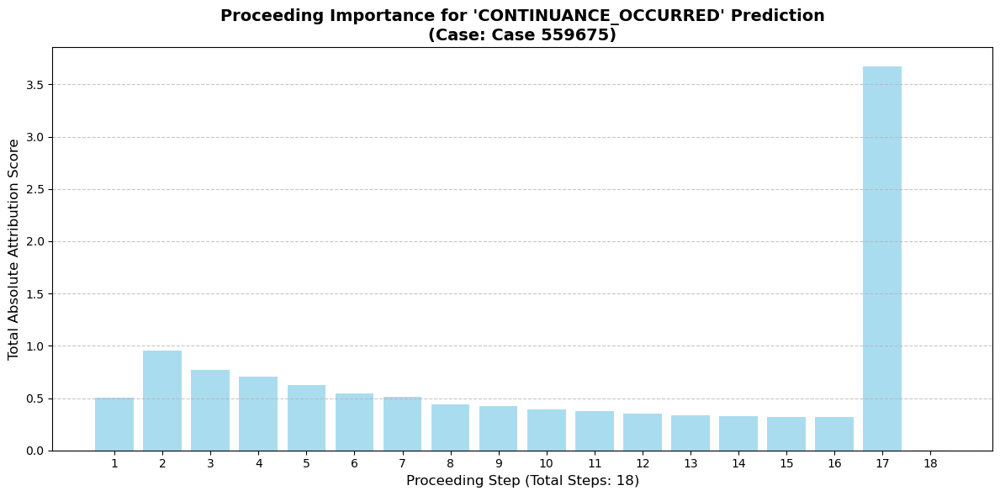

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_13.png


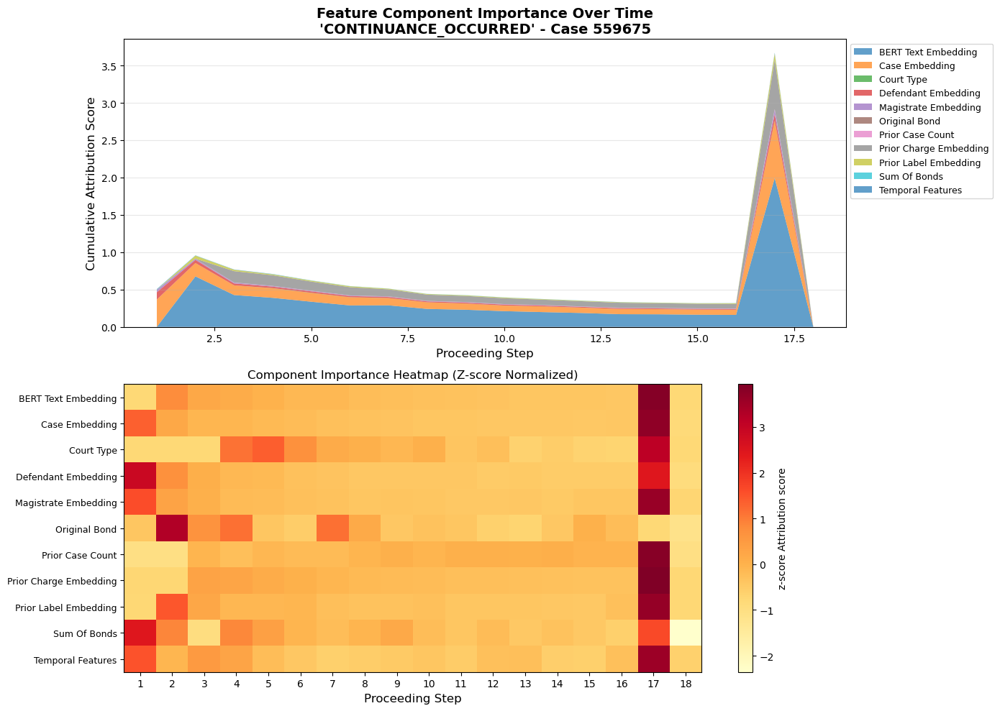


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 18 for class index 14 at proceeding index 16
   Attribution shape: torch.Size([1, 18, 1548])
   Convergence delta: -0.01222693920135498
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           6.115698          0.339761         1.985003         0.426170  CONTINUANCE_OCCURRED
1           Case_Embedding           2.556879          0.142049         0.766242         0.167901  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           1.922621          0.106812         0.660543         0.140708  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.421668          0.023426         0.096987         0.025667  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.249057          0.013836         0.079366         0.017982  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.182822          0.010157         0.060

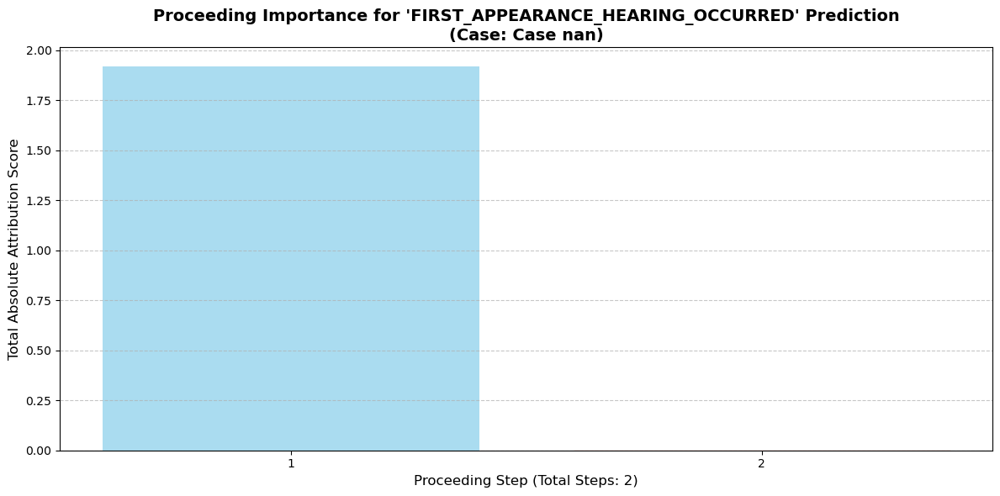

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_14.png


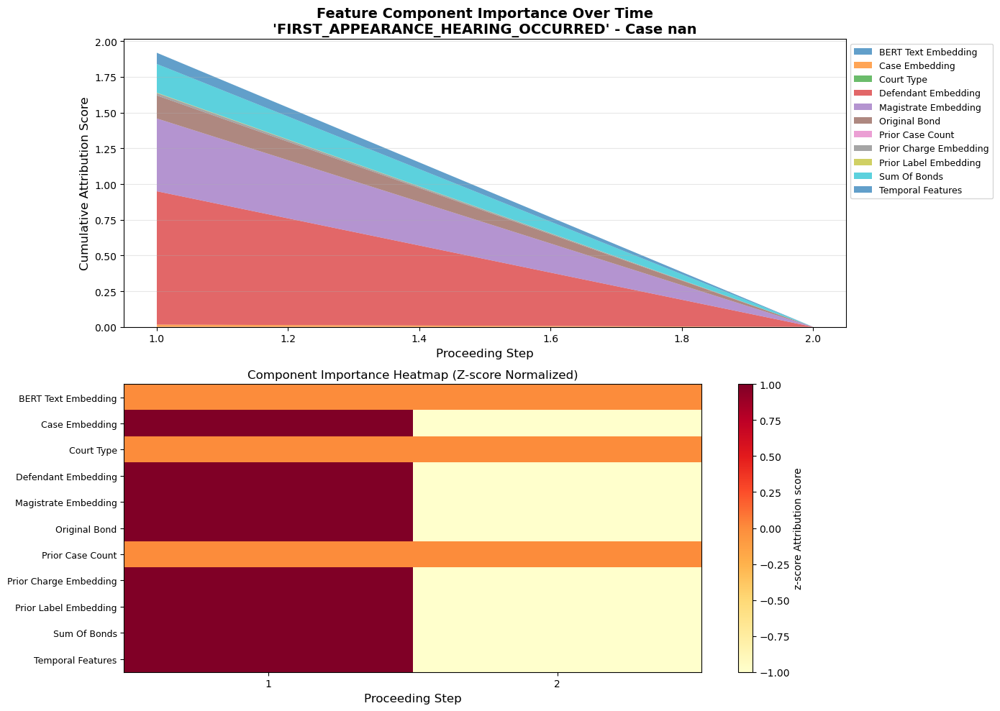


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 2 for class index 0 at proceeding index 0
   Attribution shape: torch.Size([1, 2, 1548])
   Convergence delta: 0.0005981922149658203
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution                       Target_Label
0      Defendant_Embedding           0.928999          0.464499         0.928999         0.464499  FIRST_APPEARANCE_HEARING_OCCURRED
3     Magistrate_Embedding           0.517300          0.258650         0.517300         0.258650  FIRST_APPEARANCE_HEARING_OCCURRED
8             Sum_Of_Bonds           0.200695          0.100348         0.200695         0.100348  FIRST_APPEARANCE_HEARING_OCCURRED
7            Original_Bond           0.162732          0.081366         0.162732         0.081366  FIRST_APPEARANCE_HEARING_OCCURRED
10       Temporal_Features           0.077619          0.038810         0.077619         0.038810  FIRST_APPEARANCE_HEARING_OCCURRED
5 

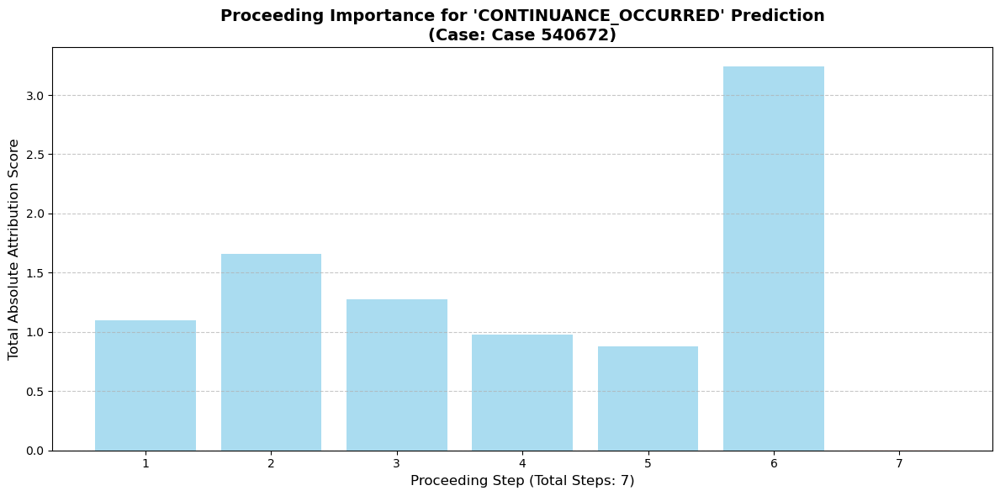

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_15.png


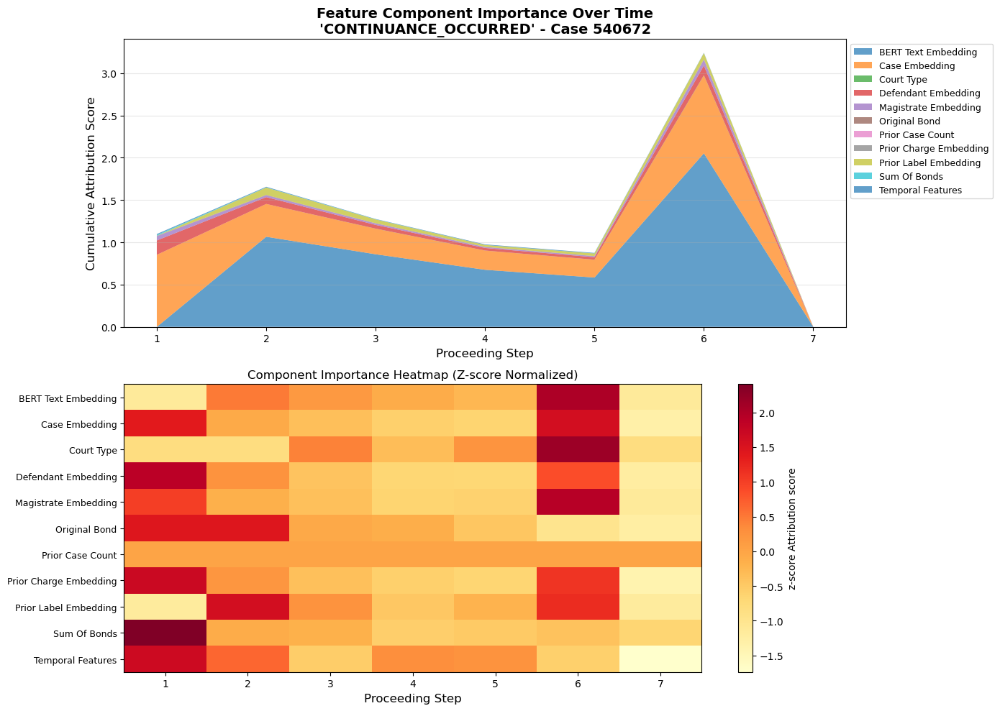


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 7 for class index 14 at proceeding index 5
   Attribution shape: torch.Size([1, 7, 1548])
   Convergence delta: 0.0031847357749938965
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.238588          0.748370         2.055710         0.651760  CONTINUANCE_OCCURRED
1           Case_Embedding           2.907516          0.415359         0.925763         0.319784  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.467652          0.066807         0.171133         0.054743  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.258896          0.036985         0.086465         0.031294  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.185965          0.026566         0.071950         0.023423  CONTINUANCE_OCCURRED
10       Temporal_Features           0.038217          0.005460         0.01055

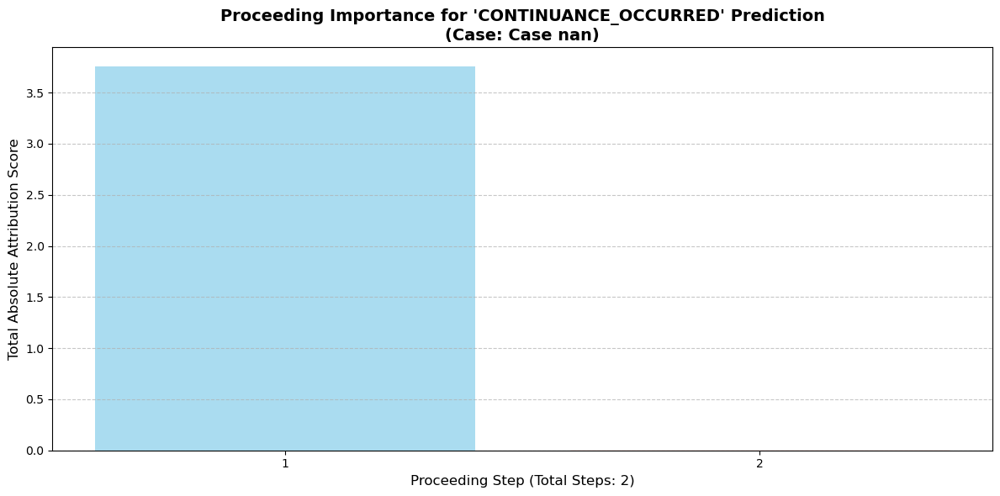

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_16.png


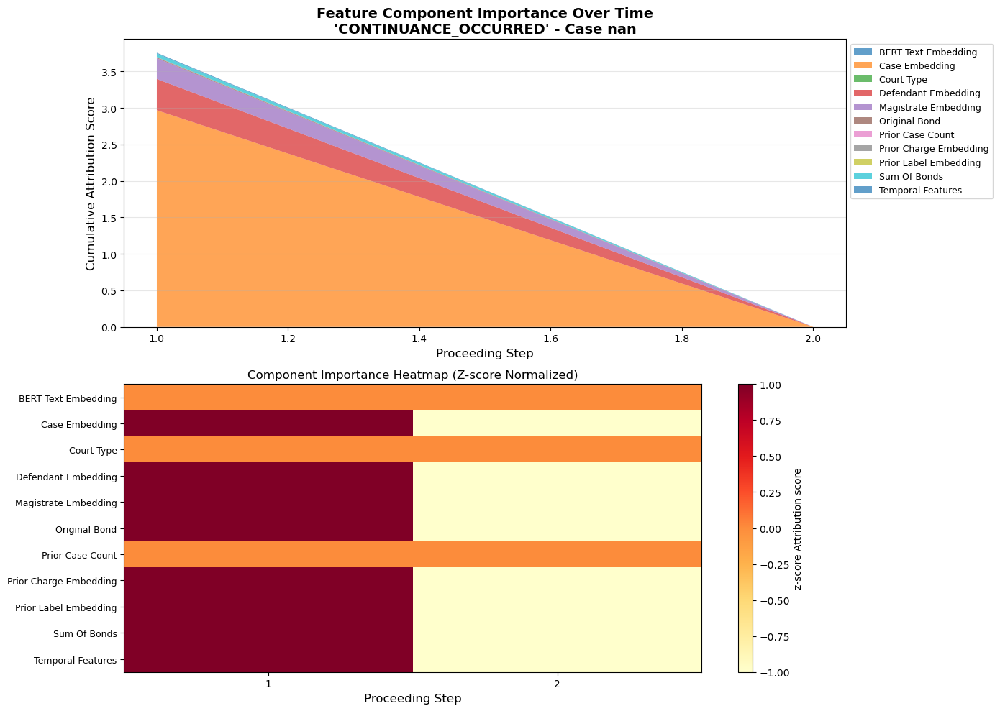


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 2 for class index 14 at proceeding index 0
   Attribution shape: torch.Size([1, 2, 1548])
   Convergence delta: 0.006314456462860107
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
1           Case_Embedding           2.980327          1.490164         2.980327         1.490164  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.427383          0.213691         0.427383         0.213691  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.285001          0.142501         0.285001         0.142501  CONTINUANCE_OCCURRED
8             Sum_Of_Bonds           0.045948          0.022974         0.045948         0.022974  CONTINUANCE_OCCURRED
10       Temporal_Features           0.010529          0.005265         0.010529         0.005265  CONTINUANCE_OCCURRED
7            Original_Bond           0.009827          0.004913         0.009827

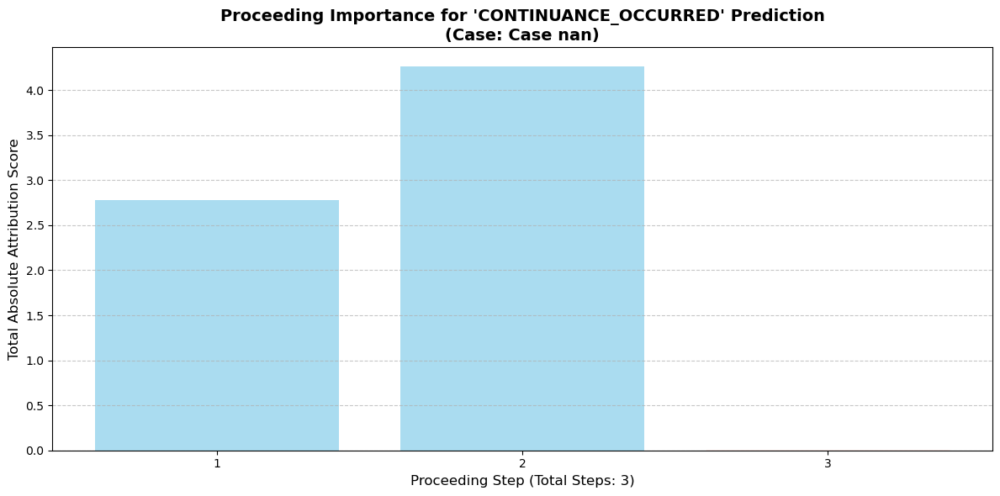

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_17.png


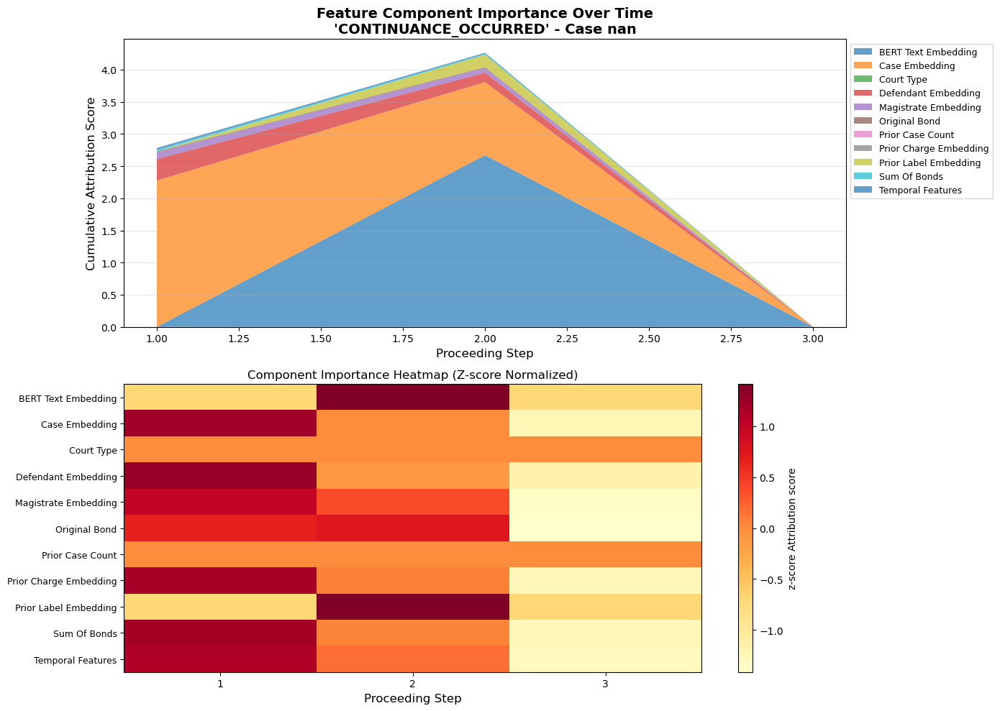


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 3 for class index 14 at proceeding index 1
   Attribution shape: torch.Size([1, 3, 1548])
   Convergence delta: 0.004785001277923584
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
1           Case_Embedding           3.422551          1.140850         2.282622         0.931877  CONTINUANCE_OCCURRED
2      BERT_Text_Embedding           2.663299          0.887766         2.663299         1.255491  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.478719          0.159573         0.334449         0.136966  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.191517          0.063839         0.190954         0.089884  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.179157          0.059719         0.103232         0.043675  CONTINUANCE_OCCURRED
10       Temporal_Features           0.046893          0.015631         0.029297

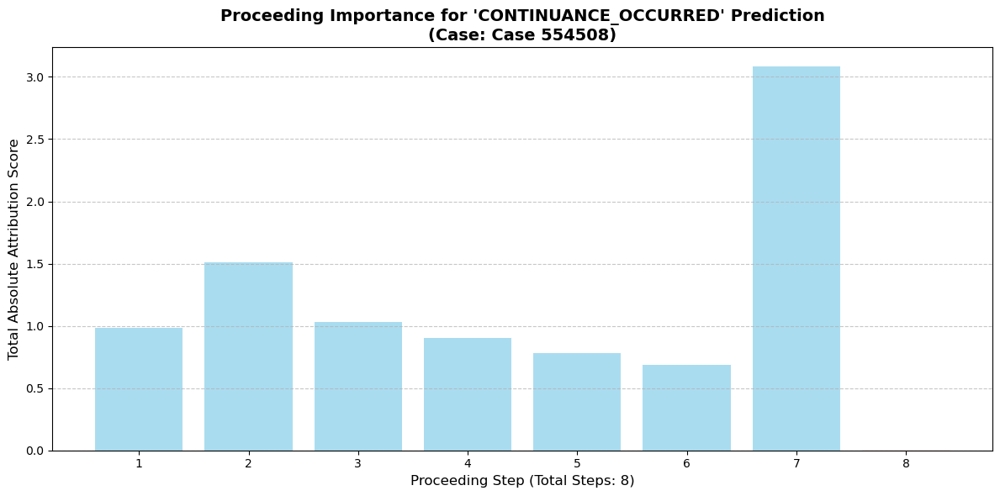

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_18.png


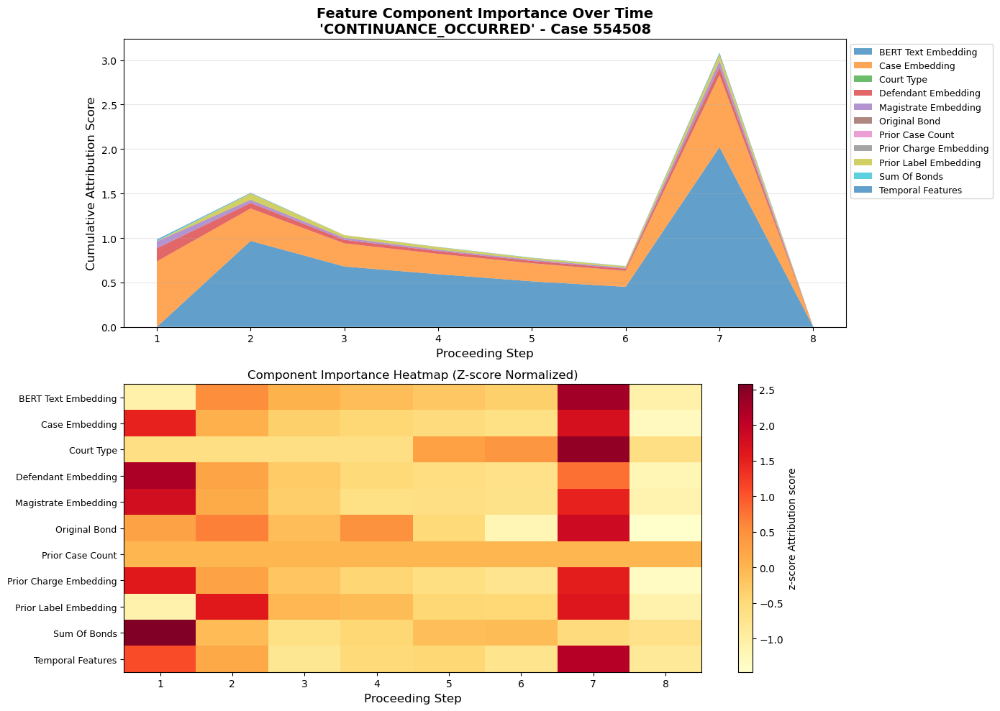


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 8 for class index 14 at proceeding index 6
   Attribution shape: torch.Size([1, 8, 1548])
   Convergence delta: -0.007608473300933838
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.230076          0.653759         2.023356         0.601507  CONTINUANCE_OCCURRED
1           Case_Embedding           2.780991          0.347624         0.807979         0.263846  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.418656          0.052332         0.149227         0.044106  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.231567          0.028946         0.071727         0.026240  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.226595          0.028324         0.073066         0.025068  CONTINUANCE_OCCURRED
10       Temporal_Features           0.038757          0.004845         0.01670

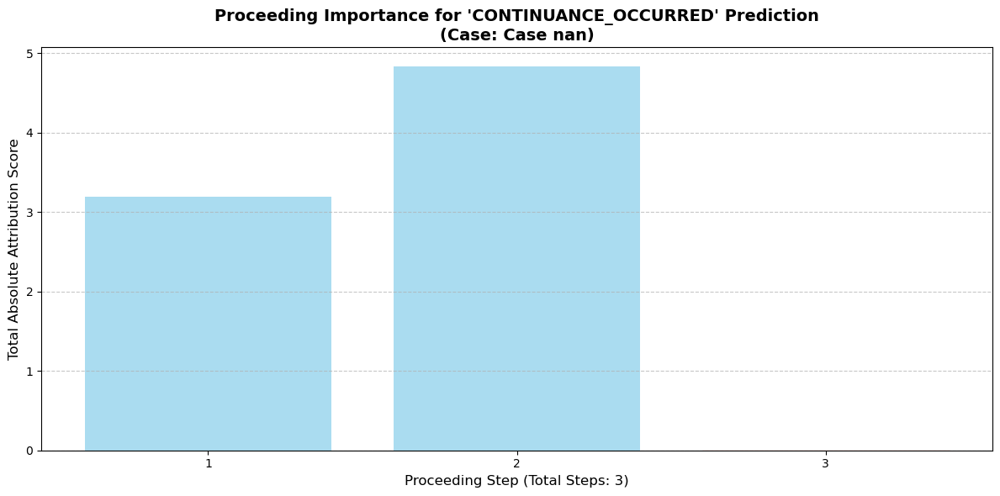

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_19.png


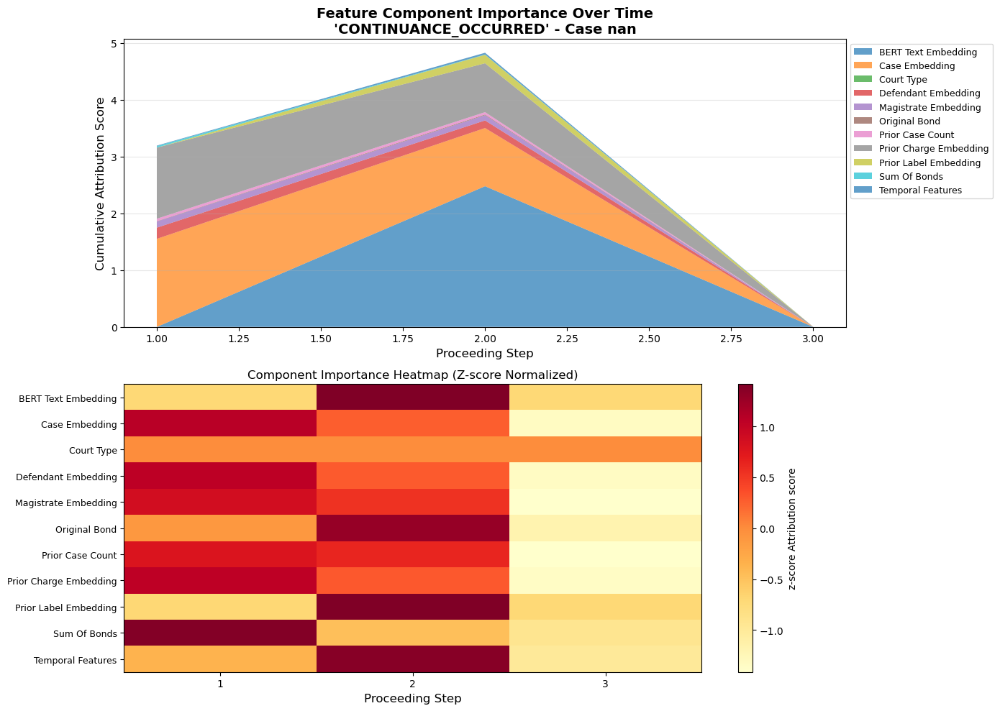


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 3 for class index 14 at proceeding index 1
   Attribution shape: torch.Size([1, 3, 1548])
   Convergence delta: -0.0014296174049377441
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
1           Case_Embedding           2.580427          0.860142         1.548365         0.643701  CONTINUANCE_OCCURRED
2      BERT_Text_Embedding           2.484606          0.828202         2.484606         1.171254  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           2.114193          0.704731         1.254453         0.523727  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.331719          0.110573         0.198354         0.082566  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.200650          0.066883         0.107874         0.047694  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.149008          0.049669         0.1485

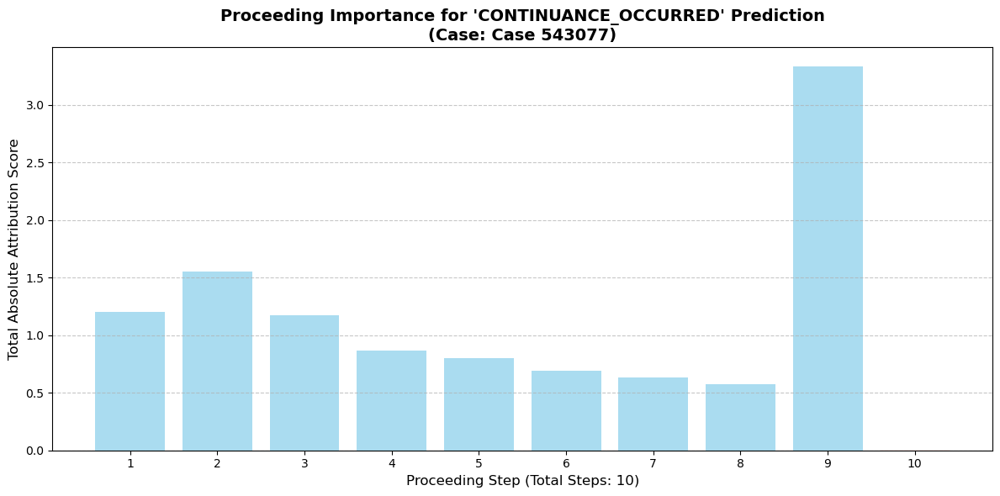

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_20.png


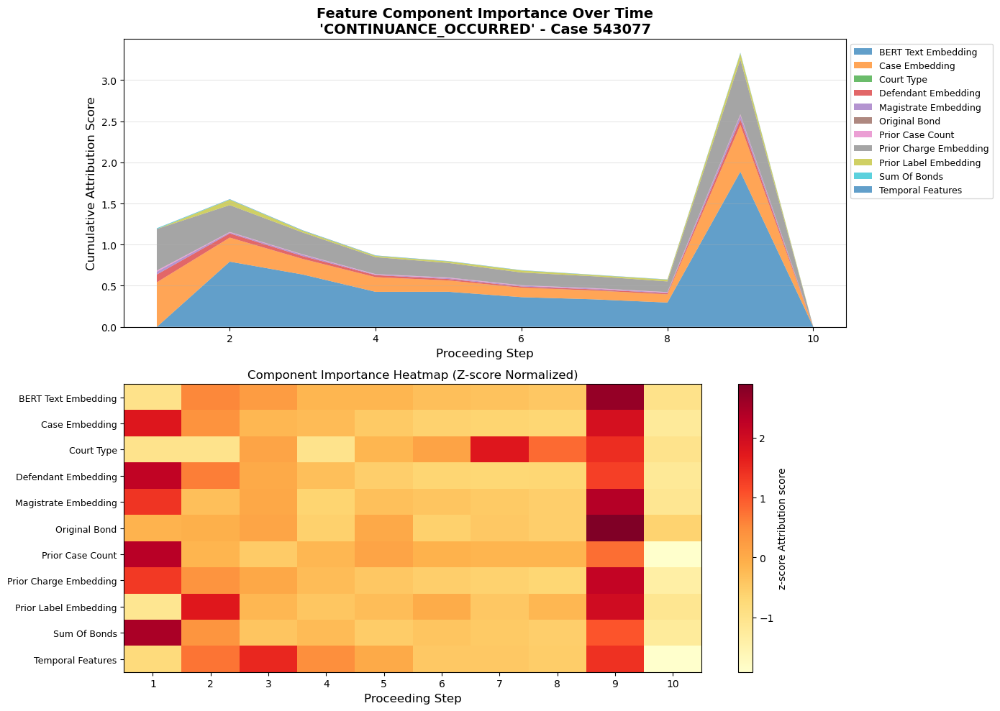


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 10 for class index 14 at proceeding index 8
   Attribution shape: torch.Size([1, 10, 1548])
   Convergence delta: -0.008713901042938232
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.163561          0.516356         1.886405         0.512200  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           2.576547          0.257655         0.668482         0.186952  CONTINUANCE_OCCURRED
1           Case_Embedding           2.228453          0.222845         0.567545         0.180995  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.330503          0.033050         0.094321         0.027872  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.253480          0.025348         0.071376         0.023024  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.148942          0.014894         0.046

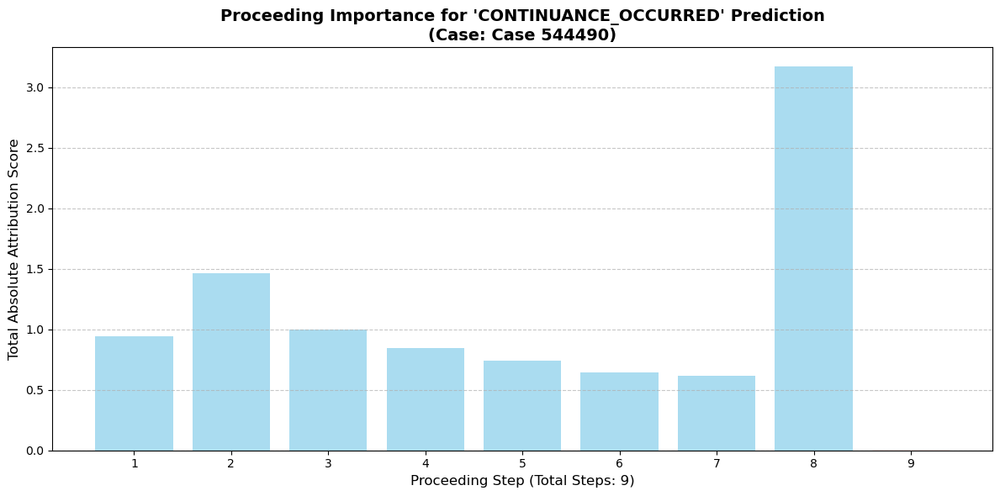

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_21.png


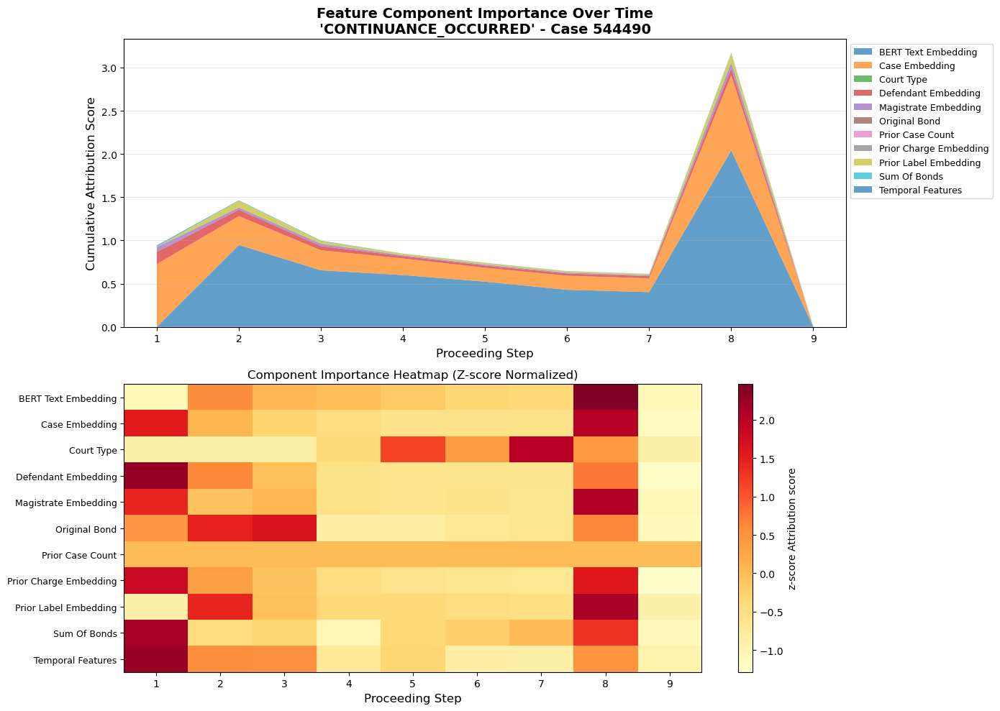


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 9 for class index 14 at proceeding index 7
   Attribution shape: torch.Size([1, 9, 1548])
   Convergence delta: 0.004626750946044922
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.603760          0.622640         2.040942         0.576392  CONTINUANCE_OCCURRED
1           Case_Embedding           2.833641          0.314849         0.865037         0.272194  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.436976          0.048553         0.139129         0.039708  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.273615          0.030402         0.101536         0.033264  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.210694          0.023410         0.068576         0.021785  CONTINUANCE_OCCURRED
10       Temporal_Features           0.028541          0.003171         0.010578

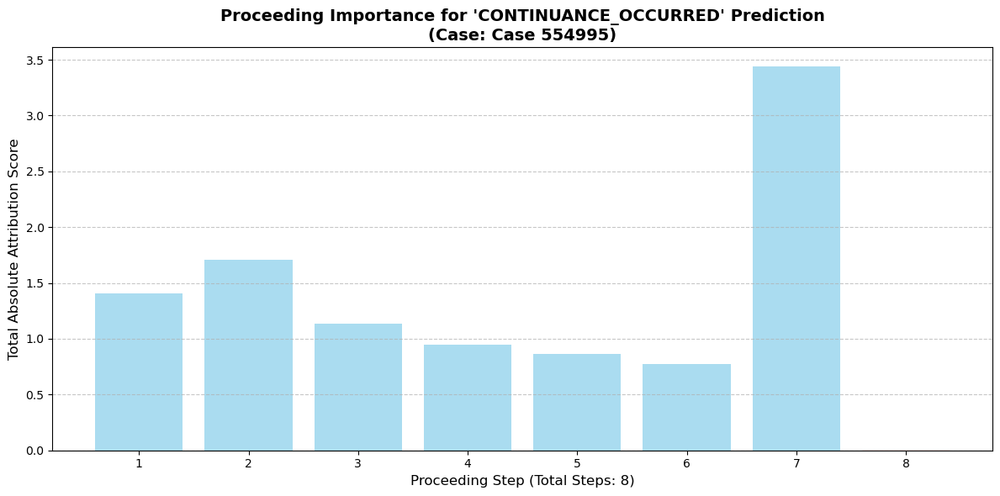

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_22.png


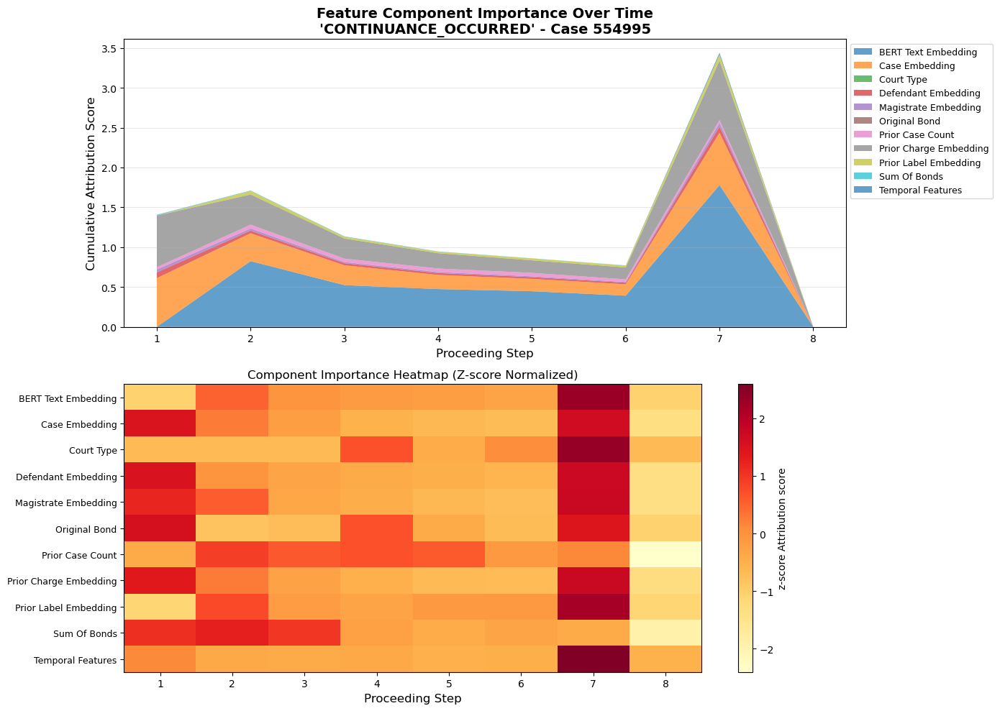


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 8 for class index 14 at proceeding index 6
   Attribution shape: torch.Size([1, 8, 1548])
   Convergence delta: 0.01039150357246399
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           4.444528          0.555566         1.777651         0.527822  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           2.520617          0.315077         0.743178         0.242175  CONTINUANCE_OCCURRED
1           Case_Embedding           2.340403          0.292550         0.656335         0.217333  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.274776          0.034347         0.077771         0.025128  CONTINUANCE_OCCURRED
9         Prior_Case_Count           0.274583          0.034323         0.047469         0.014242  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.206800          0.025850         0.076704 

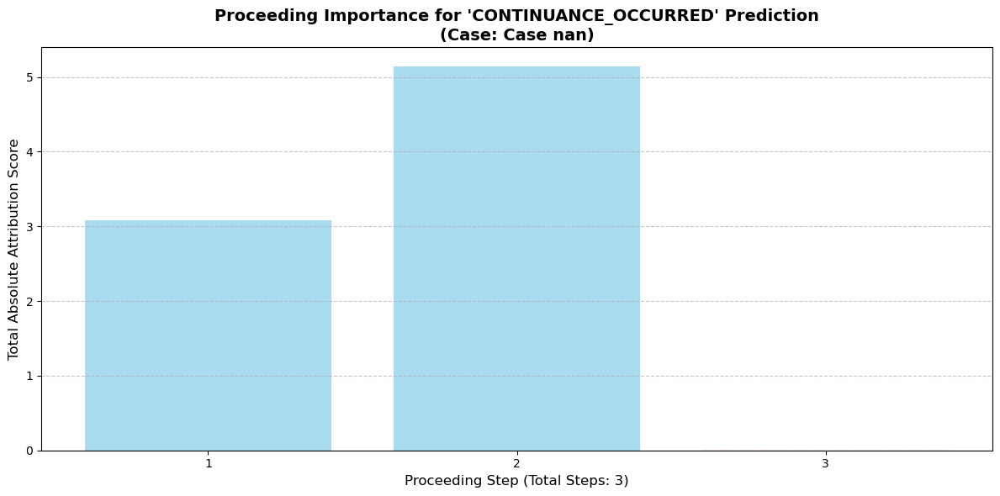

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_23.png


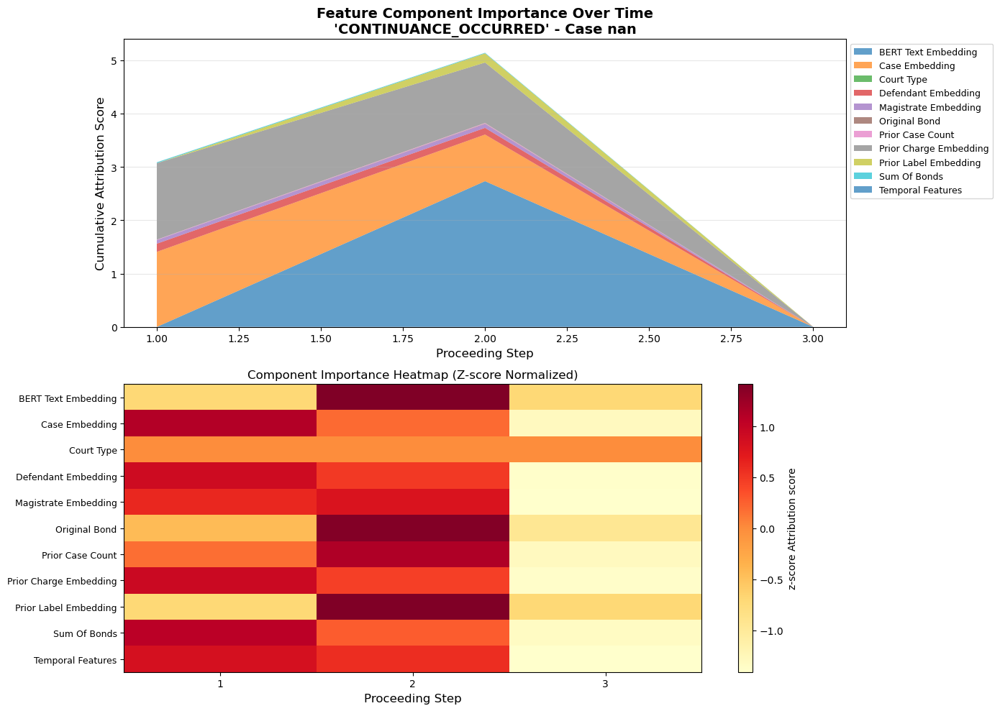


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 3 for class index 14 at proceeding index 1
   Attribution shape: torch.Size([1, 3, 1548])
   Convergence delta: -0.011967837810516357
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           2.732345          0.910782         2.732345         1.288040  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           2.565129          0.855043         1.430053         0.616483  CONTINUANCE_OCCURRED
1           Case_Embedding           2.282517          0.760839         1.404865         0.579451  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.278009          0.092670         0.152653         0.066468  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.173033          0.057678         0.172682         0.081321  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.140554          0.046851         0.07314

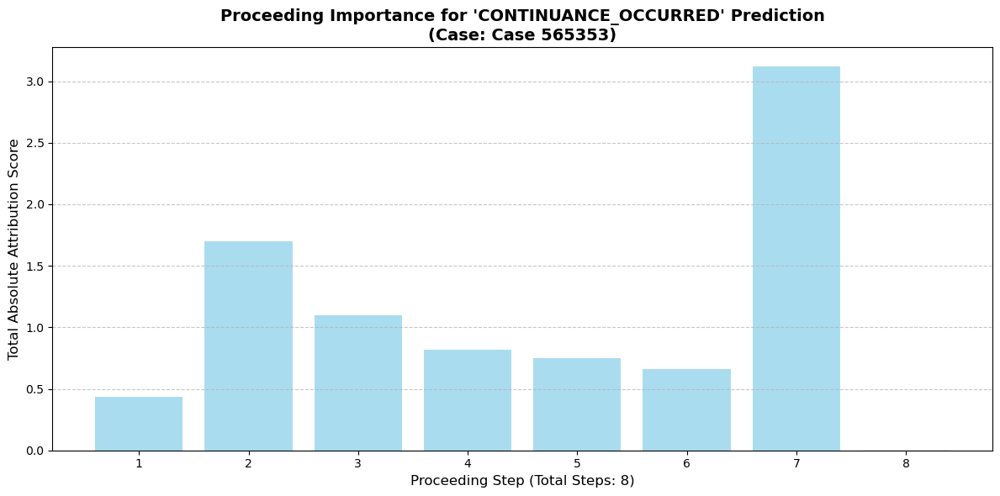

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_24.png


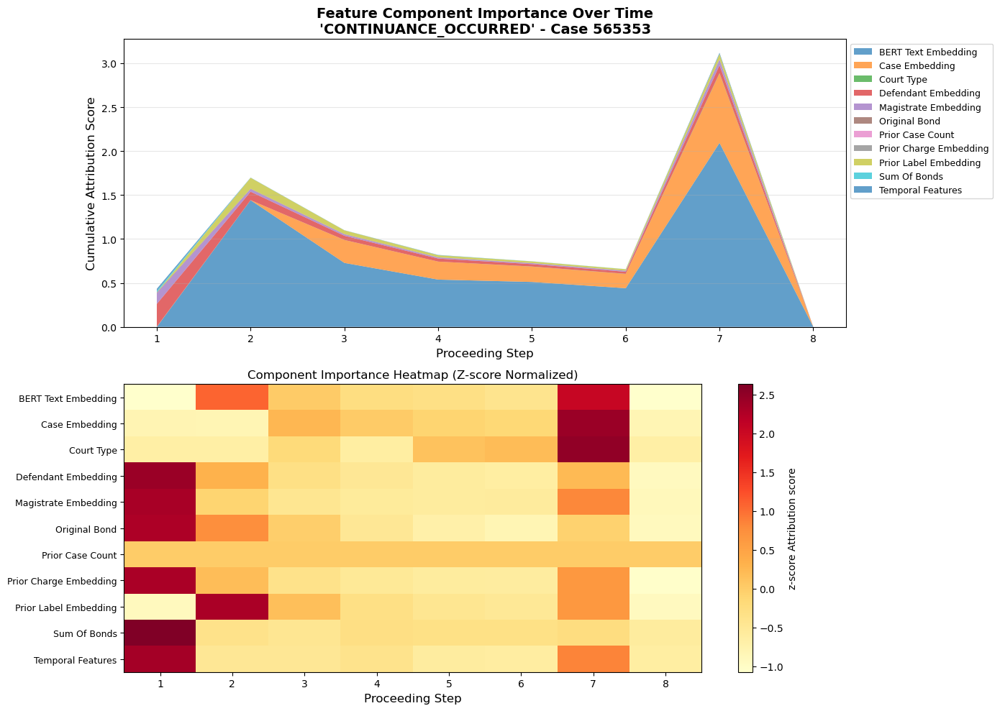


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 8 for class index 14 at proceeding index 6
   Attribution shape: torch.Size([1, 8, 1548])
   Convergence delta: 0.0046607255935668945
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.758464          0.719808         2.097582         0.671960  CONTINUANCE_OCCURRED
1           Case_Embedding           1.595504          0.199438         0.791750         0.243515  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.575827          0.071978         0.258520         0.076867  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.284716          0.035590         0.123622         0.038256  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.267924          0.033491         0.120140         0.037533  CONTINUANCE_OCCURRED
10       Temporal_Features           0.040750          0.005094         0.02408

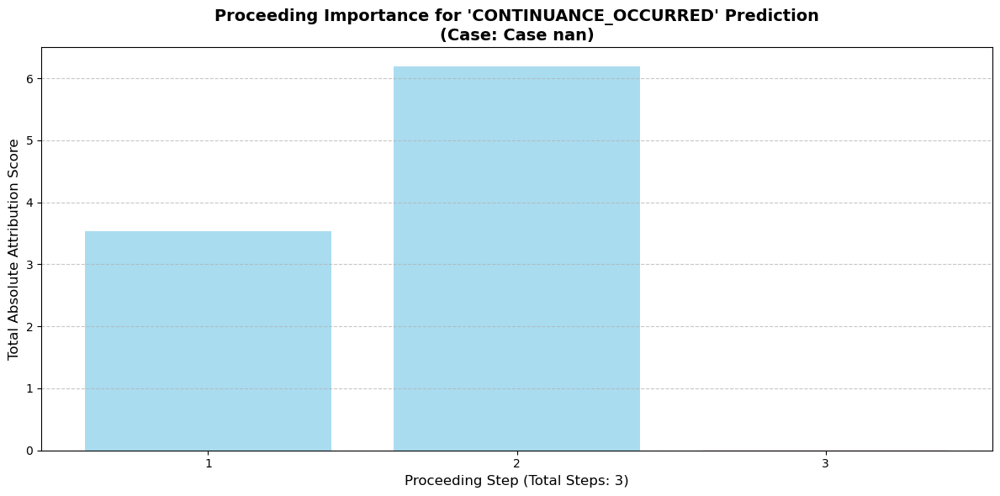

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_25.png


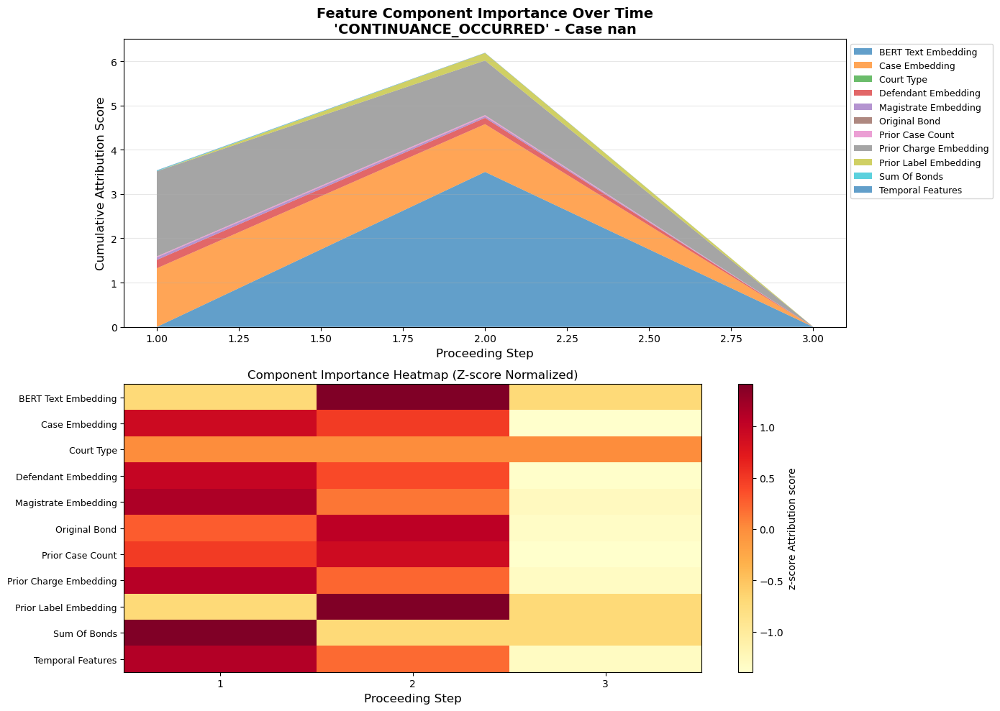


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 3 for class index 14 at proceeding index 1
   Attribution shape: torch.Size([1, 3, 1548])
   Convergence delta: 0.017937004566192627
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           3.505182          1.168394         3.505182         1.652359  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           3.152523          1.050841         1.922575         0.795040  CONTINUANCE_OCCURRED
1           Case_Embedding           2.405014          0.801671         1.325906         0.575752  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.330154          0.110051         0.189152         0.080262  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.171130          0.057043         0.170740         0.080396  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.087719          0.029240         0.055491

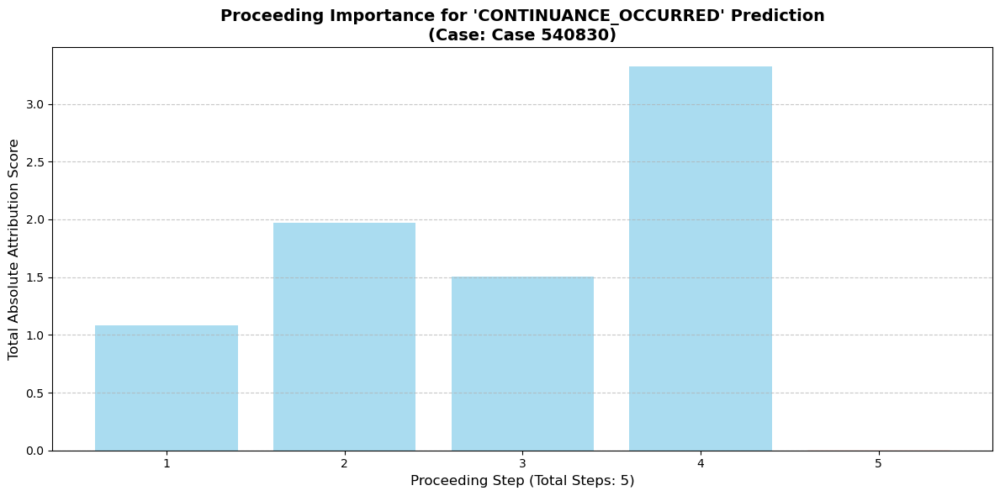

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_26.png


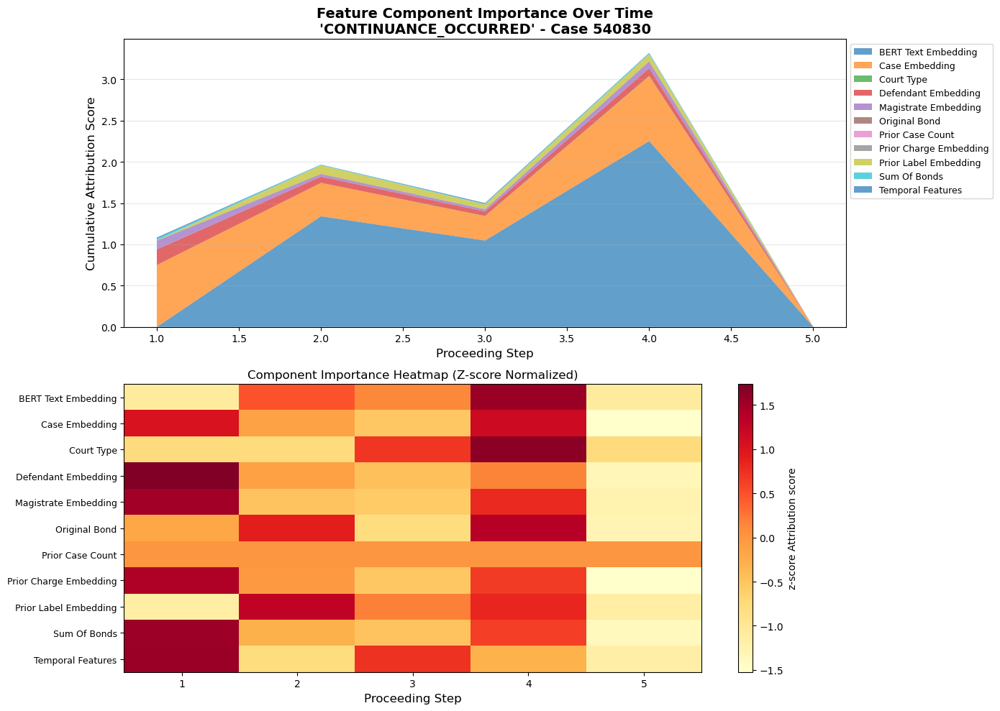


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 5 for class index 14 at proceeding index 3
   Attribution shape: torch.Size([1, 5, 1548])
   Convergence delta: -0.005733191967010498
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           4.637511          0.927502         2.247828         0.854542  CONTINUANCE_OCCURRED
1           Case_Embedding           2.239190          0.447838         0.784698         0.294219  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.409465          0.081893         0.189174         0.061832  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.244789          0.048958         0.103468         0.042497  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.238526          0.047705         0.104195         0.038023  CONTINUANCE_OCCURRED
8             Sum_Of_Bonds           0.044893          0.008979         0.01888

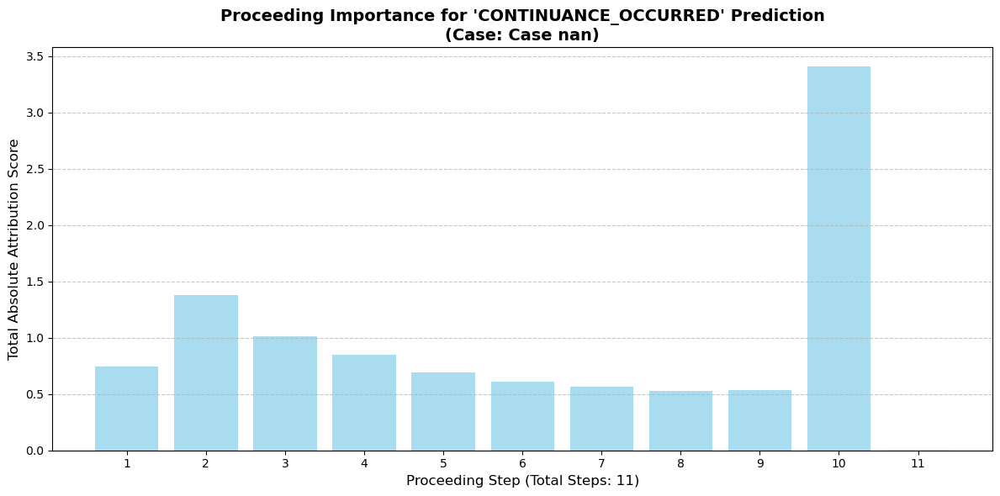

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_27.png


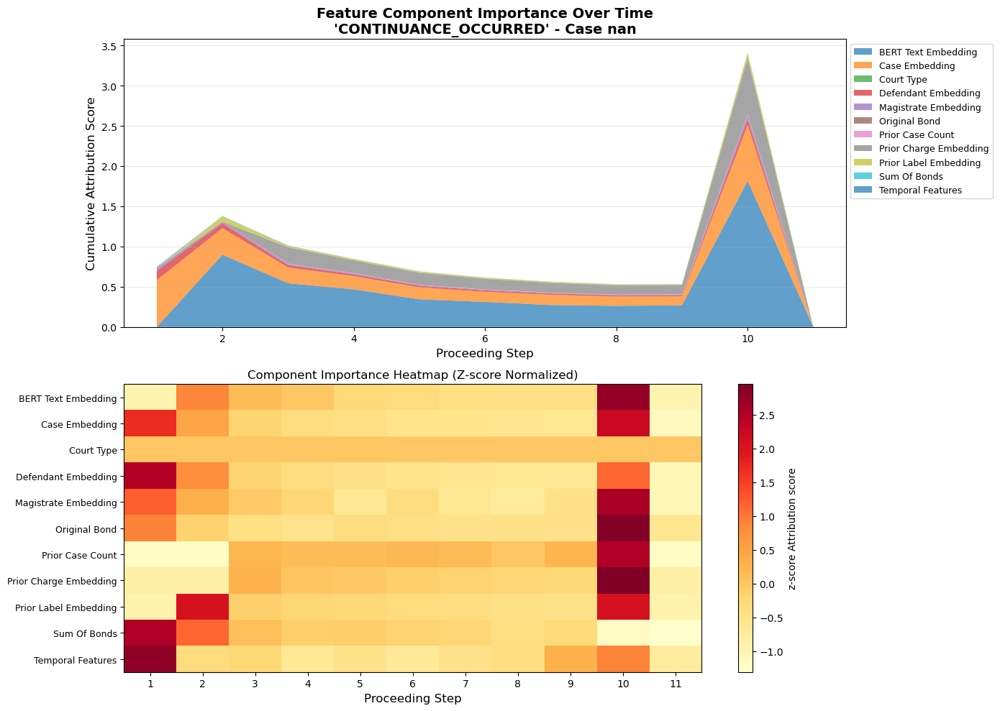


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 11 for class index 14 at proceeding index 9
   Attribution shape: torch.Size([1, 11, 1548])
   Convergence delta: 0.004790067672729492
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.175521          0.470502         1.813700         0.486221  CONTINUANCE_OCCURRED
1           Case_Embedding           2.595554          0.235959         0.691820         0.204482  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           1.687636          0.153421         0.692050         0.182752  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.382396          0.034763         0.115478         0.032459  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.218567          0.019870         0.063633         0.021228  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.160776          0.014616         0.0511

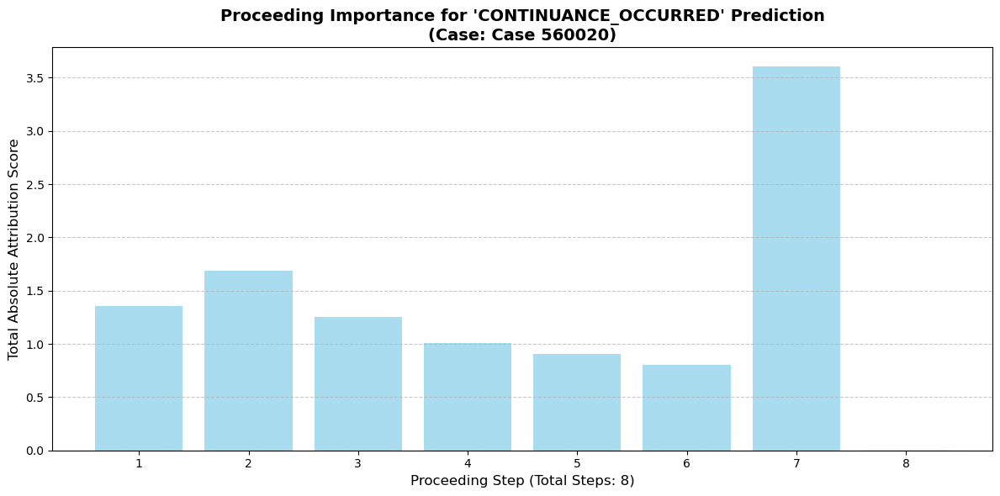

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_28.png


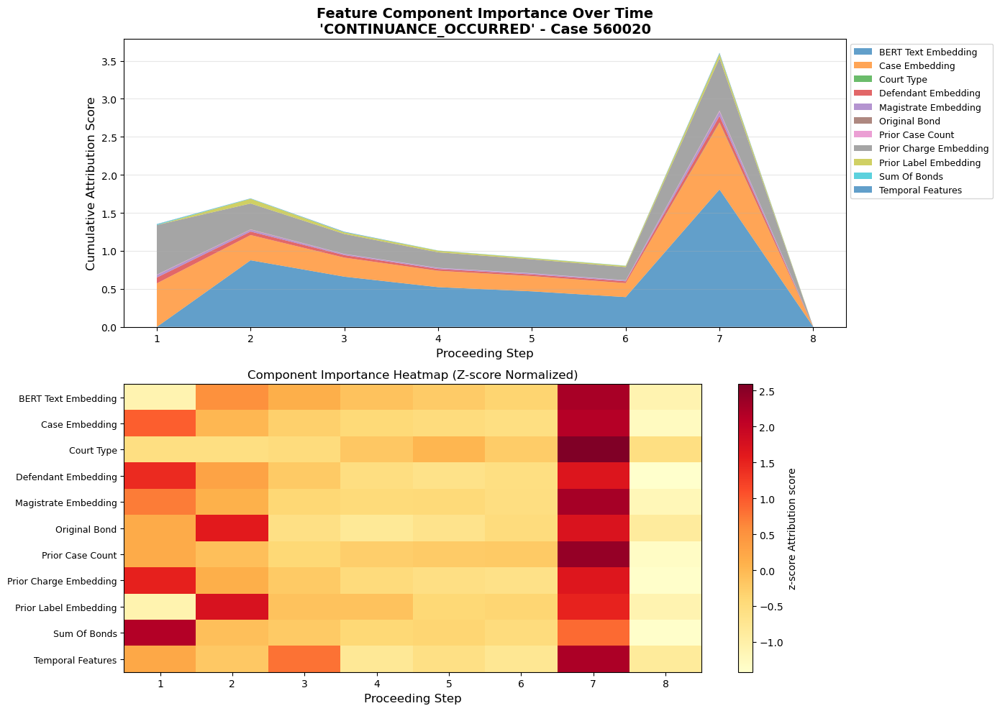


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 8 for class index 14 at proceeding index 6
   Attribution shape: torch.Size([1, 8, 1548])
   Convergence delta: -0.001032114028930664
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           4.721732          0.590217         1.801236         0.537166  CONTINUANCE_OCCURRED
1           Case_Embedding           2.631330          0.328916         0.874224         0.255533  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           2.495595          0.311949         0.682252         0.223804  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.303872          0.037984         0.082830         0.026714  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.191674          0.023959         0.062087         0.021865  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.159614          0.019952         0.05790

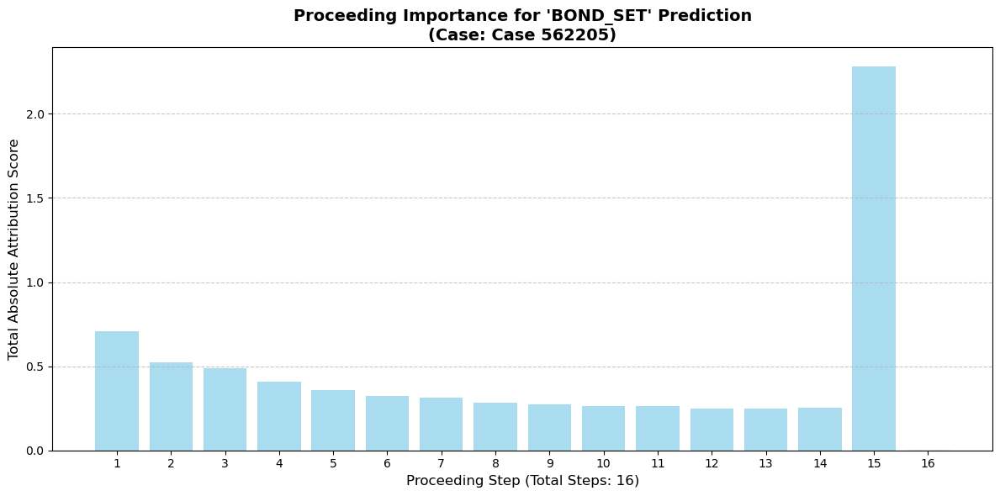

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_29.png


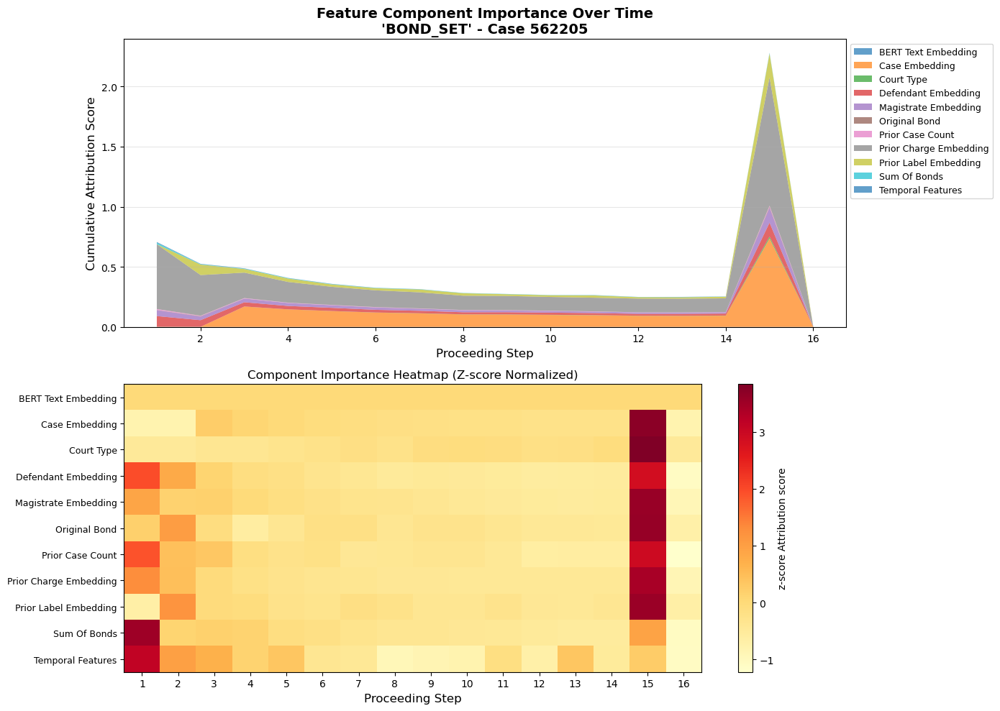


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 16 for class index 1 at proceeding index 14
   Attribution shape: torch.Size([1, 16, 1548])
   Convergence delta: 0.009400784969329834
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution Target_Label
5   Prior_Charge_Embedding           3.565968          0.222873         1.066916         0.247583     BOND_SET
1           Case_Embedding           2.093225          0.130827         0.734547         0.163122     BOND_SET
4    Prior_Label_Embedding           0.510107          0.031882         0.198158         0.046937     BOND_SET
0      Defendant_Embedding           0.509725          0.031858         0.114785         0.029111     BOND_SET
3     Magistrate_Embedding           0.403848          0.025241         0.124174         0.027717     BOND_SET
9         Prior_Case_Count           0.047580          0.002974         0.009686         0.002358     BOND_SET
8             Sum_Of_

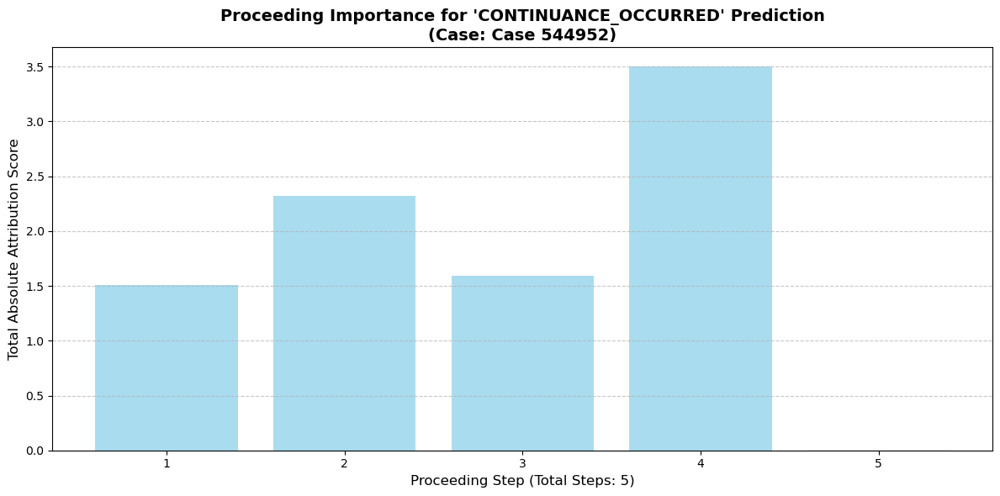

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_30.png


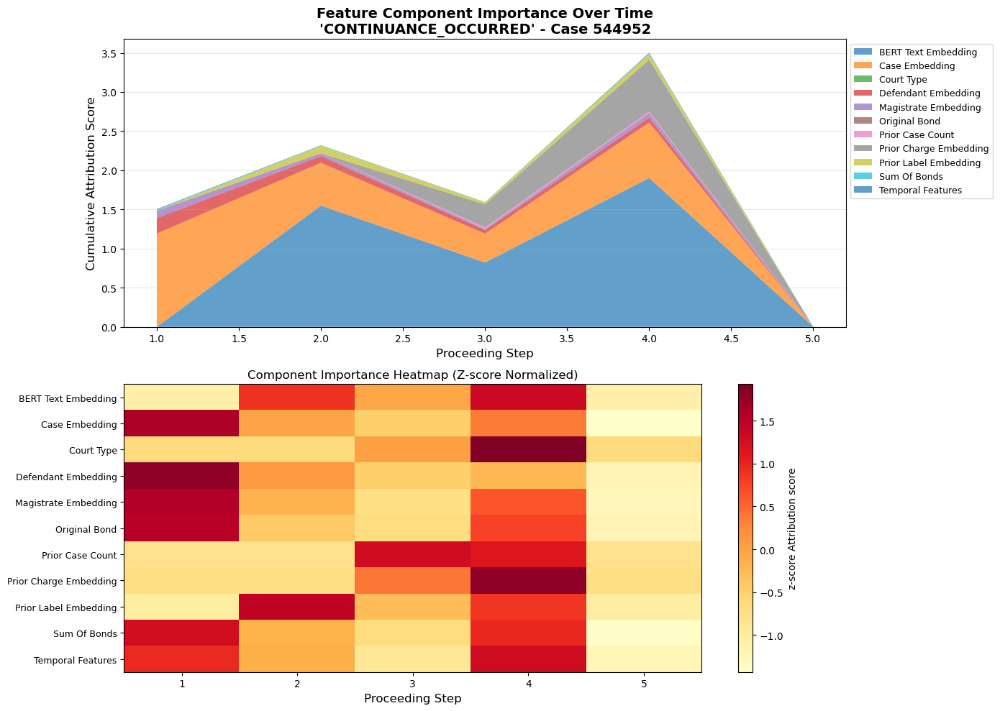


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 5 for class index 14 at proceeding index 3
   Attribution shape: torch.Size([1, 5, 1548])
   Convergence delta: 0.003271043300628662
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           4.269379          0.853876         1.897268         0.779200  CONTINUANCE_OCCURRED
1           Case_Embedding           2.808455          0.561691         1.188996         0.391818  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           0.964732          0.192946         0.664974         0.262379  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.392208          0.078442         0.197629         0.065949  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.197117          0.039423         0.088650         0.031422  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.192608          0.038522         0.094125

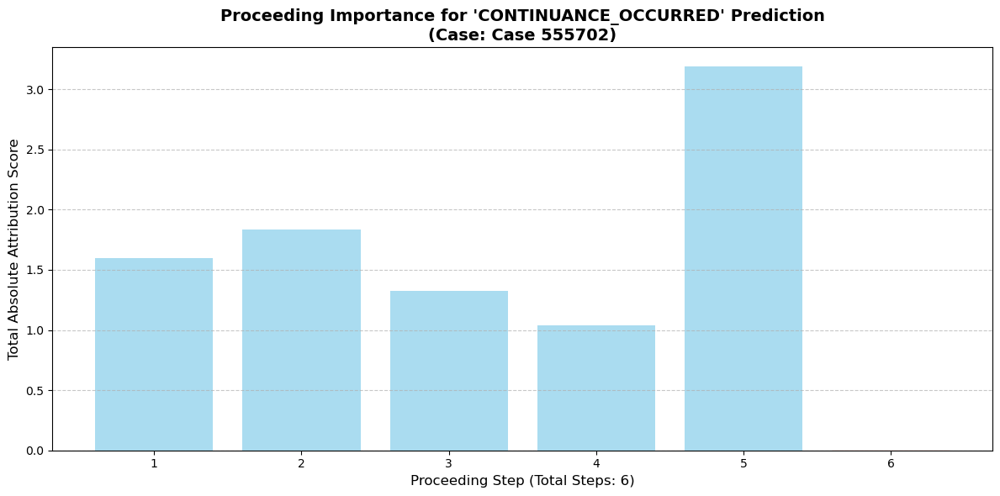

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_31.png


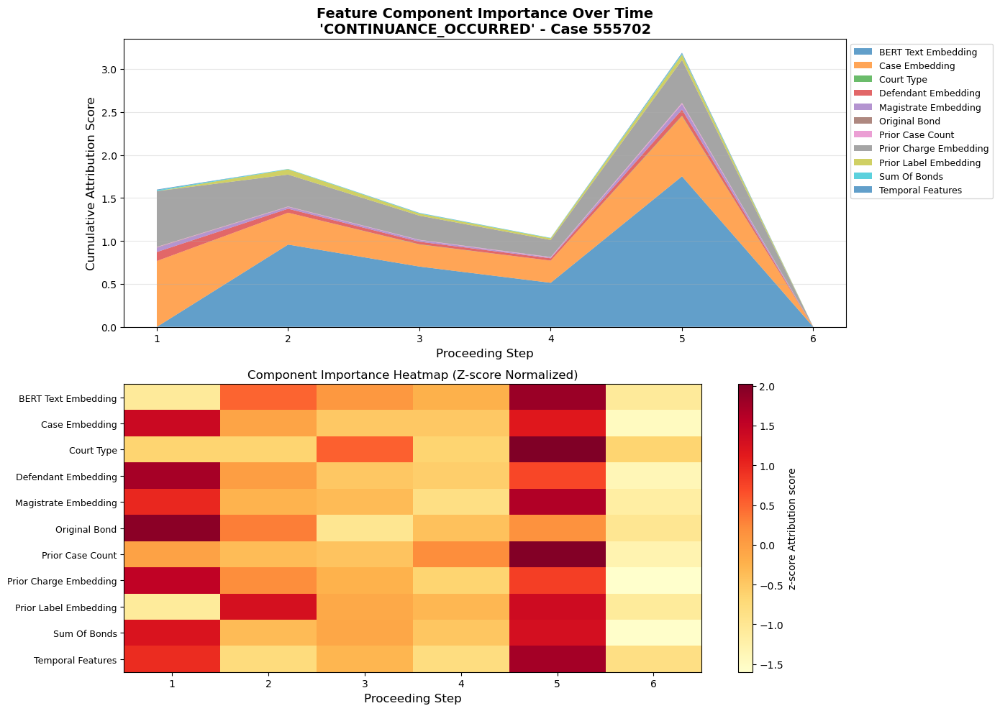


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 6 for class index 14 at proceeding index 4
   Attribution shape: torch.Size([1, 6, 1548])
   Convergence delta: 0.003910541534423828
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           3.926288          0.654381         1.753688         0.602647  CONTINUANCE_OCCURRED
1           Case_Embedding           2.348061          0.391343         0.763697         0.265219  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           2.001243          0.333541         0.651020         0.208853  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.278706          0.046451         0.104989         0.033696  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.169003          0.028167         0.063002         0.025566  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.157948          0.026325         0.062965

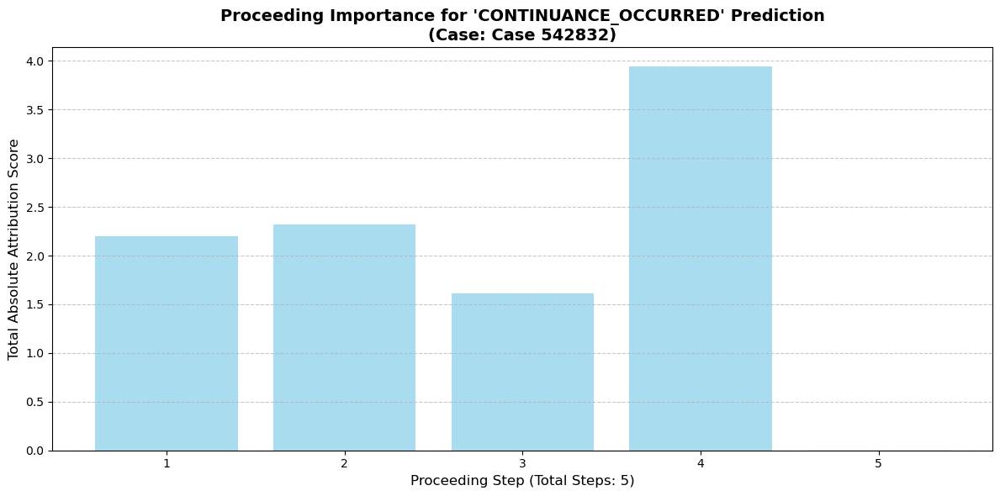

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_32.png


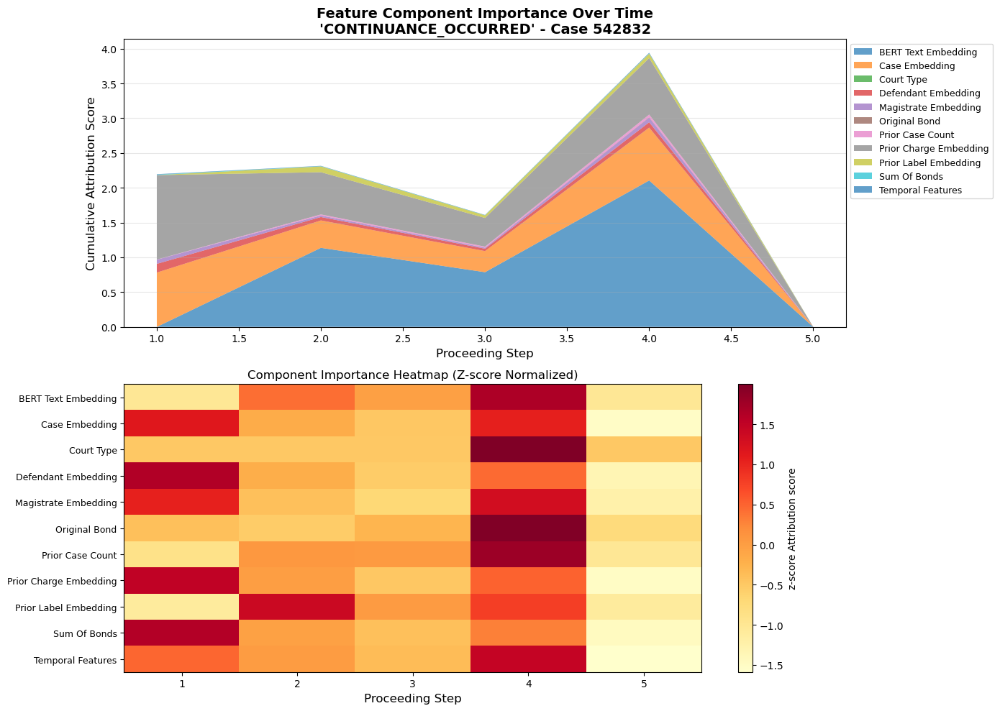


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 5 for class index 14 at proceeding index 3
   Attribution shape: torch.Size([1, 5, 1548])
   Convergence delta: 0.002275824546813965
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           4.027601          0.805520         2.107080         0.787383  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           3.045472          0.609095         1.213030         0.404191  CONTINUANCE_OCCURRED
1           Case_Embedding           2.237596          0.447519         0.779416         0.293890  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.283161          0.056632         0.124653         0.041884  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.184365          0.036873         0.083280         0.033324  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.163851          0.032770         0.067194

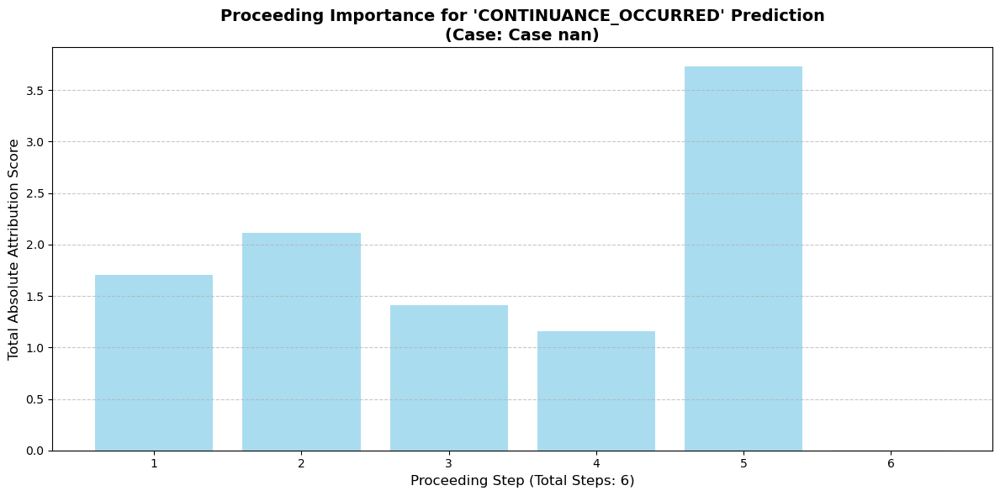

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_33.png


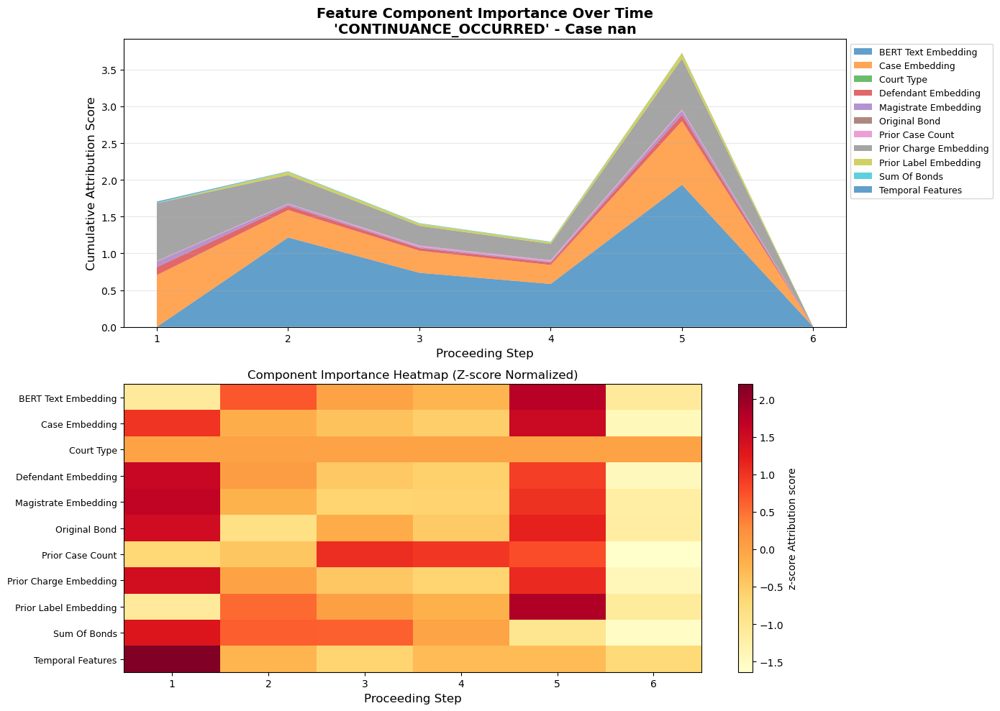


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 6 for class index 14 at proceeding index 4
   Attribution shape: torch.Size([1, 6, 1548])
   Convergence delta: 0.008930504322052002
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           4.471728          0.745288         1.931920         0.679201  CONTINUANCE_OCCURRED
1           Case_Embedding           2.496226          0.416038         0.862088         0.287482  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           2.354875          0.392479         0.785059         0.271220  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.315522          0.052587         0.108951         0.035848  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.180638          0.030106         0.071896         0.024994  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.177493          0.029582         0.078337

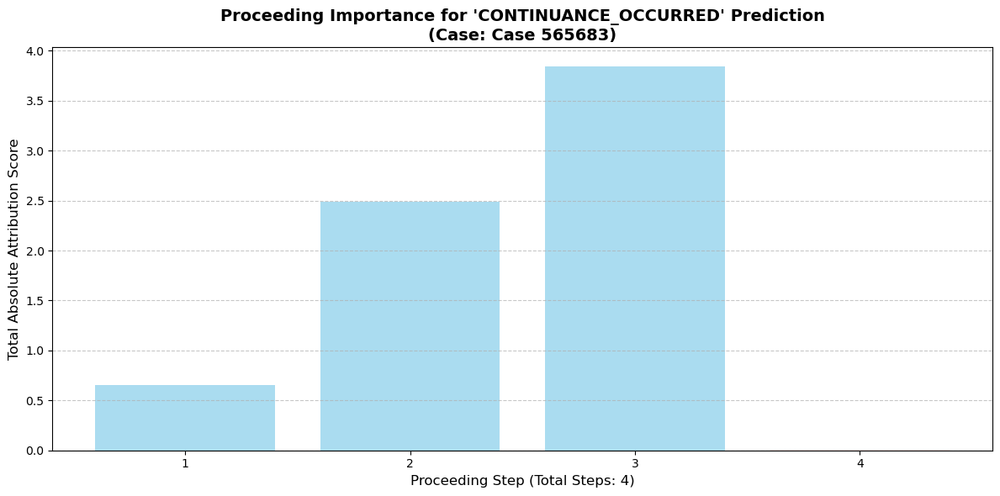

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_34.png


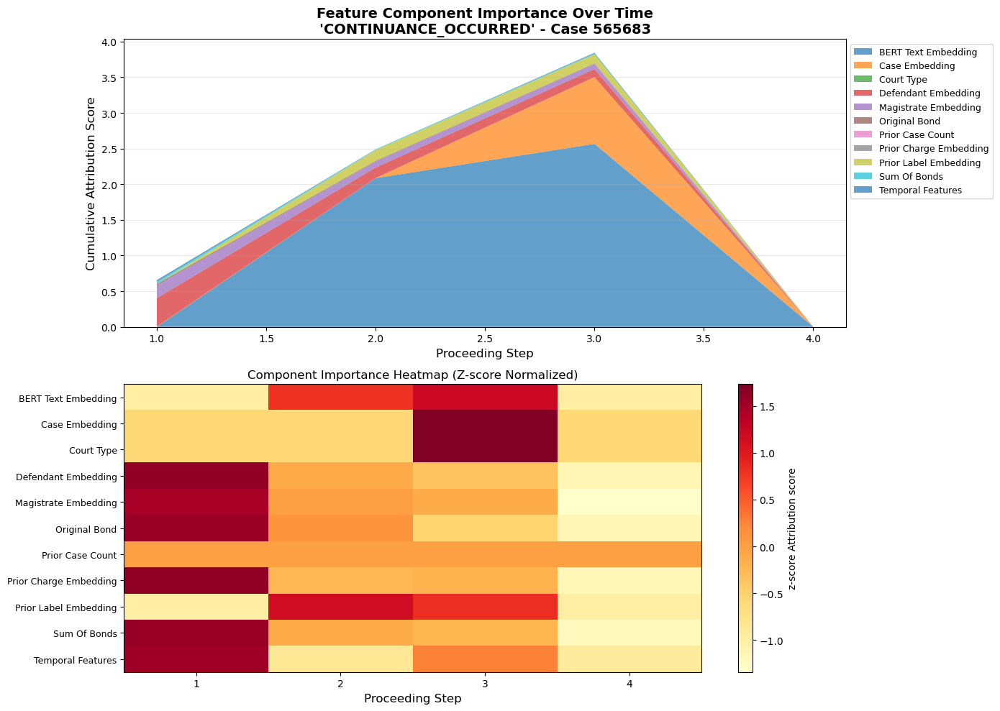


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 4 for class index 14 at proceeding index 2
   Attribution shape: torch.Size([1, 4, 1548])
   Convergence delta: 0.005376875400543213
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           4.654786          1.163697         2.564239         1.175686  CONTINUANCE_OCCURRED
1           Case_Embedding           0.942003          0.235501         0.936368         0.404649  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.659349          0.164837         0.401297         0.146874  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.335406          0.083852         0.176403         0.062588  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.275575          0.068894         0.149716         0.069101  CONTINUANCE_OCCURRED
8             Sum_Of_Bonds           0.044868          0.011217         0.025827

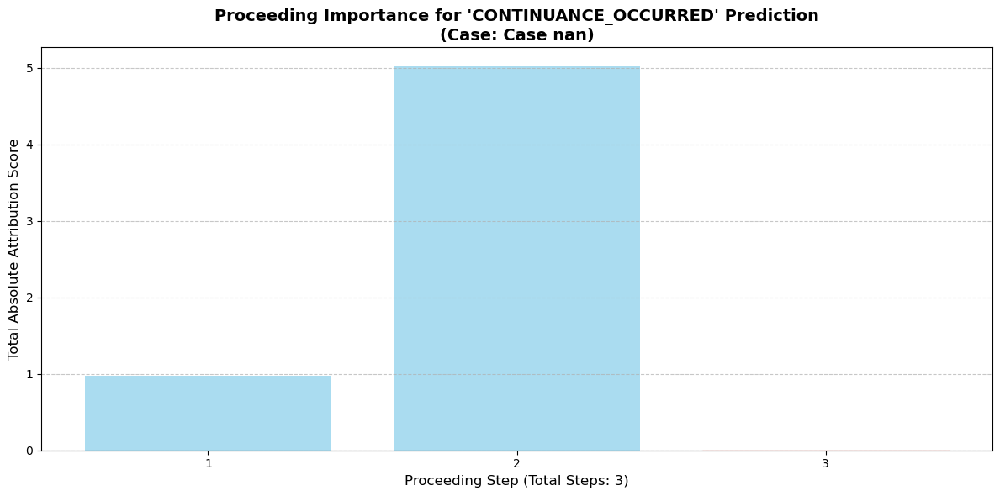

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_35.png


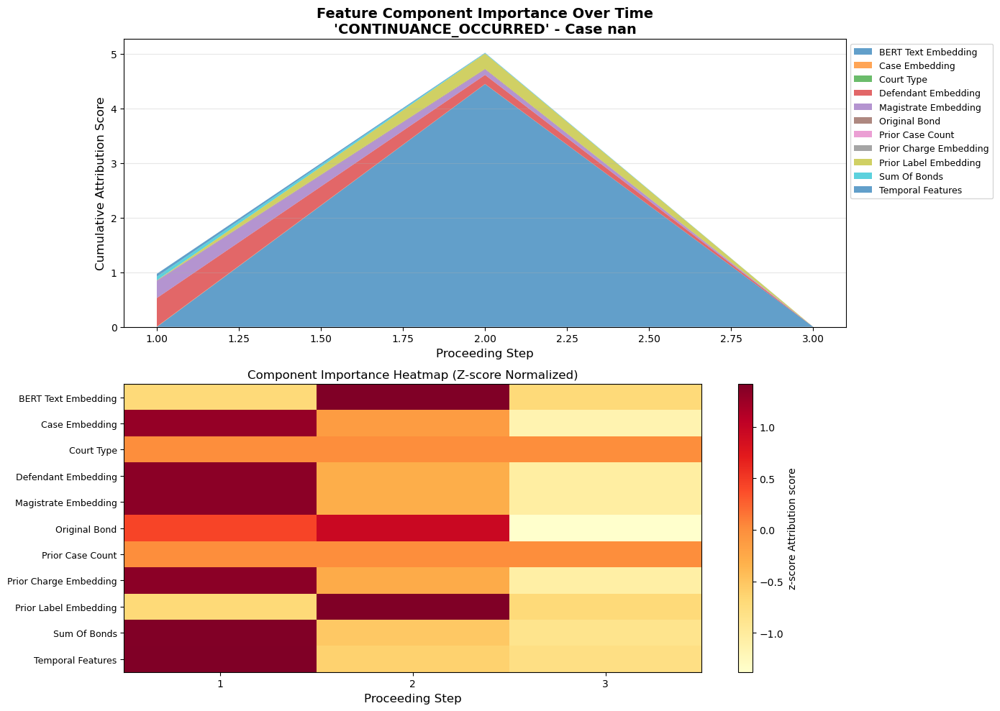


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 3 for class index 14 at proceeding index 1
   Attribution shape: torch.Size([1, 3, 1548])
   Convergence delta: -0.007311969995498657
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           4.438183          1.479394         4.438183         2.092179  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.687159          0.229053         0.522820         0.218290  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.409296          0.136432         0.311593         0.130122  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.281036          0.093679         0.280062         0.131794  CONTINUANCE_OCCURRED
8             Sum_Of_Bonds           0.076322          0.025441         0.066666         0.029416  CONTINUANCE_OCCURRED
10       Temporal_Features           0.057506          0.019169         0.05298

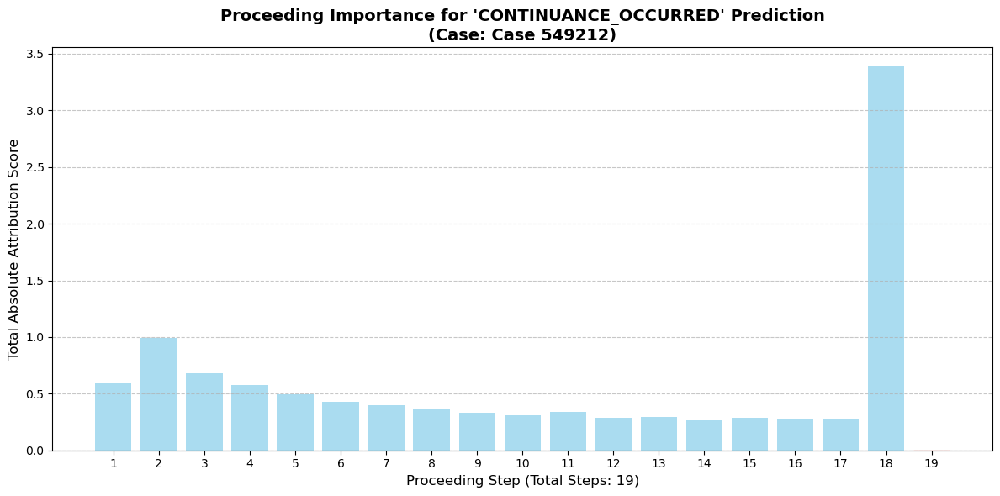

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_36.png


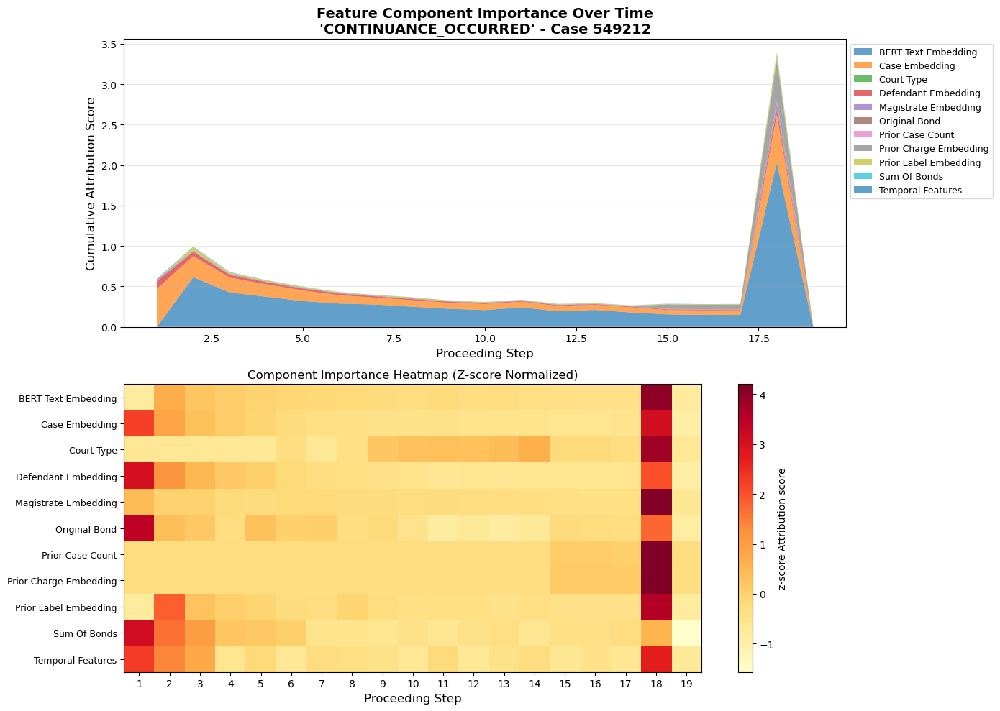


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 19 for class index 14 at proceeding index 17
   Attribution shape: torch.Size([1, 19, 1548])
   Convergence delta: 0.0036560893058776855
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           6.284443          0.330760         2.028550         0.422541  CONTINUANCE_OCCURRED
1           Case_Embedding           2.634320          0.138648         0.592135         0.146816  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           0.689013          0.036264         0.520402         0.115834  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.432026          0.022738         0.095158         0.023834  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.265418          0.013969         0.074821         0.017069  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.197737          0.010407         0.07

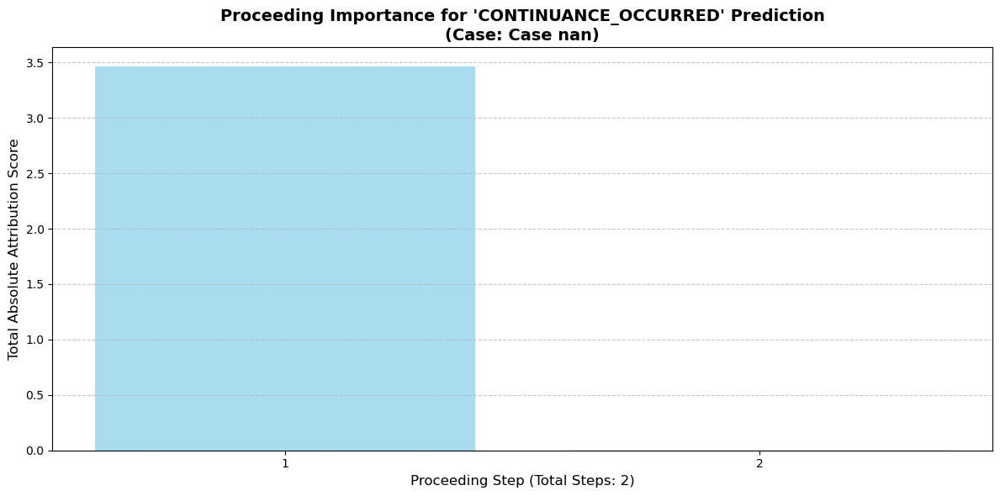

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_37.png


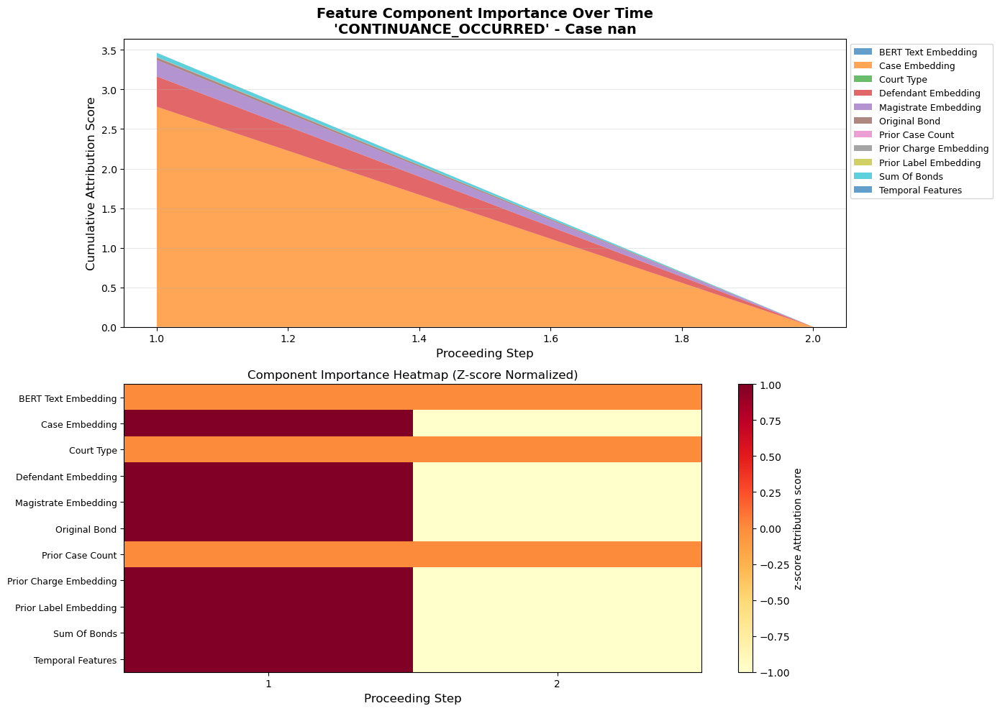


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 2 for class index 14 at proceeding index 0
   Attribution shape: torch.Size([1, 2, 1548])
   Convergence delta: 0.009027838706970215
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
1           Case_Embedding           2.779193          1.389597         2.779193         1.389597  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.380642          0.190321         0.380642         0.190321  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.206840          0.103420         0.206840         0.103420  CONTINUANCE_OCCURRED
8             Sum_Of_Bonds           0.052062          0.026031         0.052062         0.026031  CONTINUANCE_OCCURRED
7            Original_Bond           0.033094          0.016547         0.033094         0.016547  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           0.005995          0.002998         0.005995

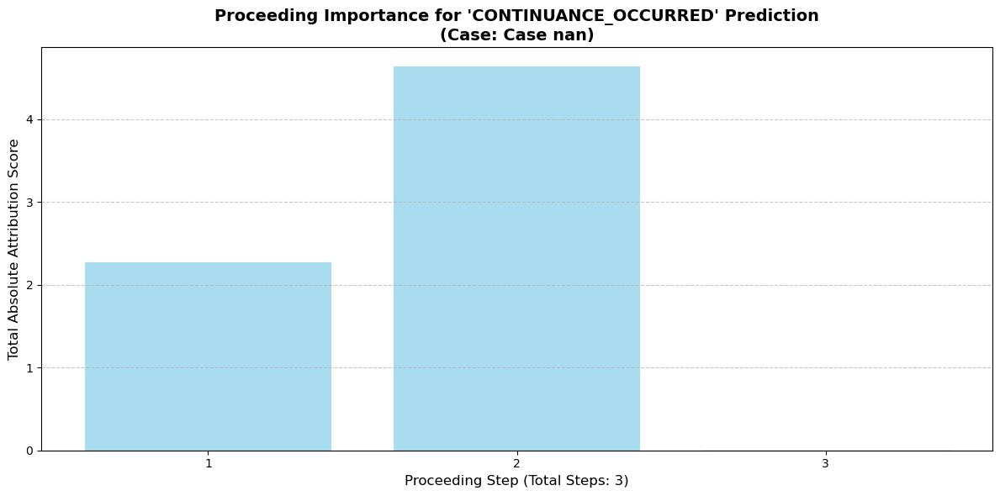

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_38.png


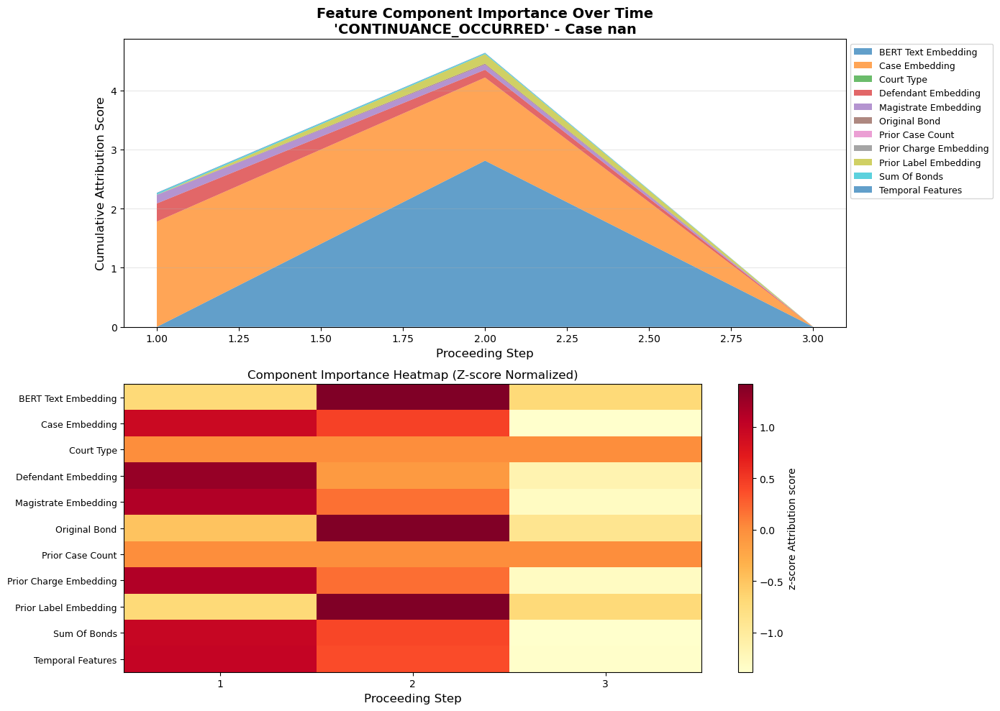


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 3 for class index 14 at proceeding index 1
   Attribution shape: torch.Size([1, 3, 1548])
   Convergence delta: 0.014759182929992676
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
1           Case_Embedding           3.184662          1.061554         1.780361         0.766171  CONTINUANCE_OCCURRED
2      BERT_Text_Embedding           2.809202          0.936401         2.809202         1.324271  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.437599          0.145866         0.306894         0.125747  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.229118          0.076373         0.142308         0.058564  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.160207          0.053402         0.159654         0.075132  CONTINUANCE_OCCURRED
8             Sum_Of_Bonds           0.038951          0.012984         0.021801

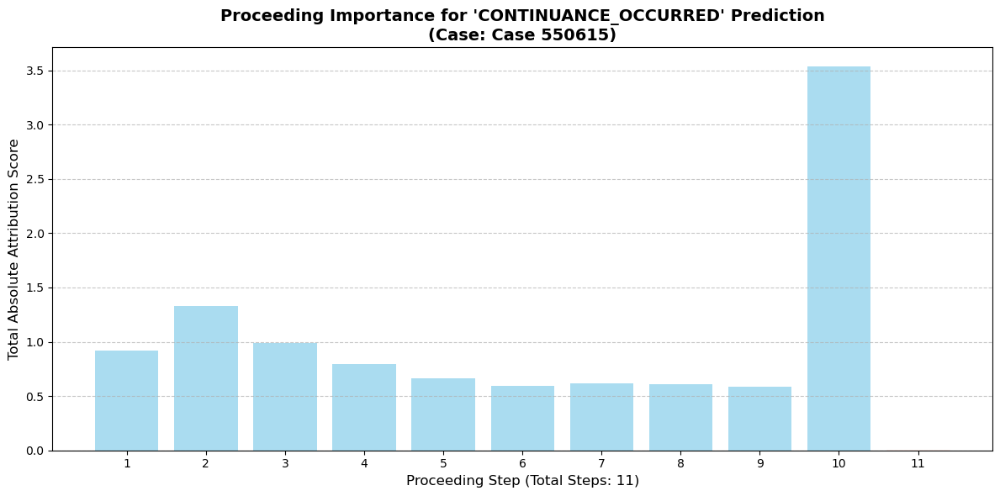

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_39.png


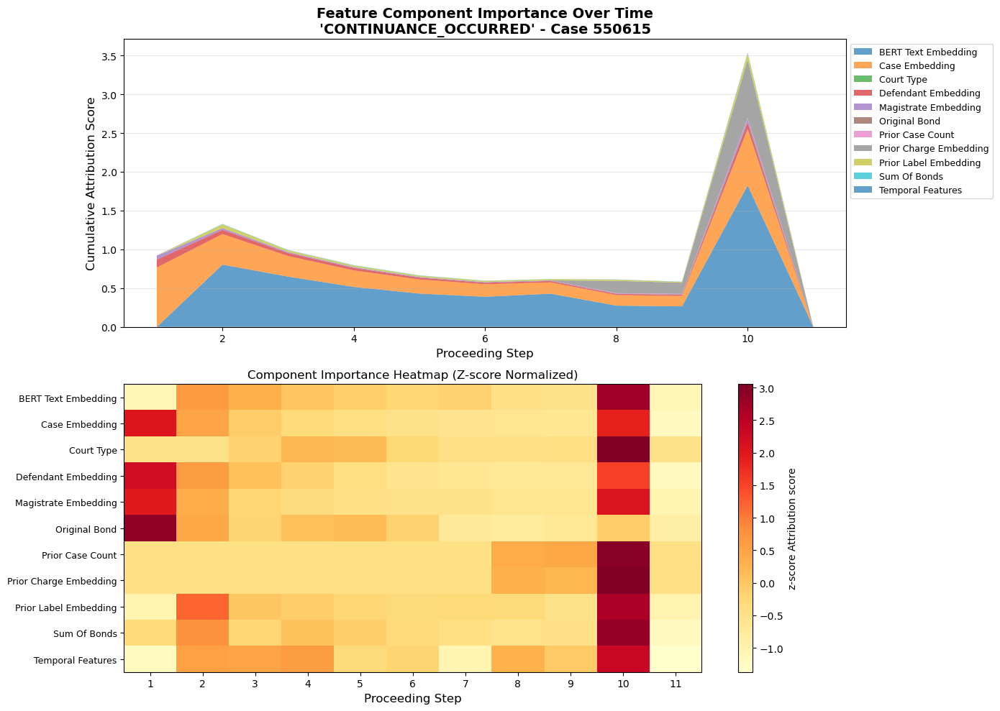


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 11 for class index 14 at proceeding index 9
   Attribution shape: torch.Size([1, 11, 1548])
   Convergence delta: -0.0025852322578430176
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.579474          0.507225         1.823082         0.475976  CONTINUANCE_OCCURRED
1           Case_Embedding           3.123346          0.283941         0.768495         0.236361  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           1.057239          0.096113         0.749457         0.214584  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.398740          0.036249         0.103192         0.029937  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.235722          0.021429         0.077602         0.021351  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.178293          0.016208         0.04

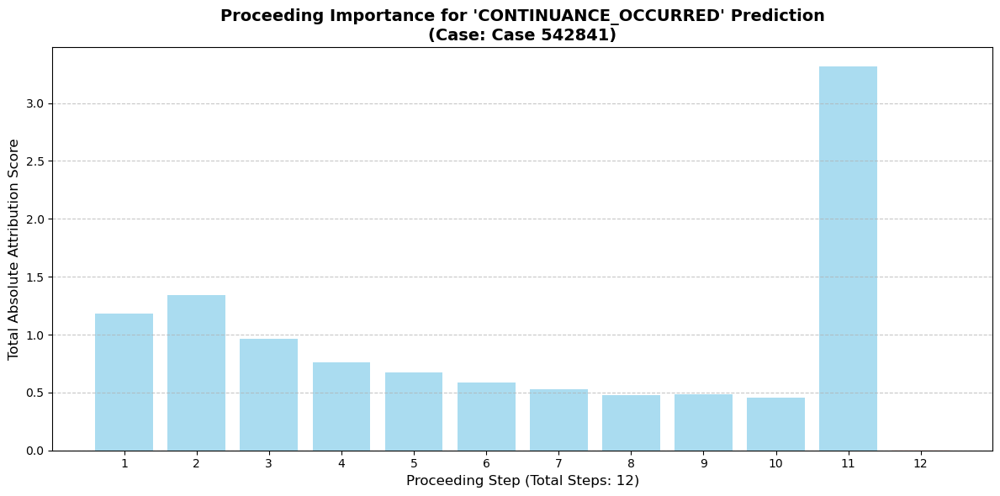

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_40.png


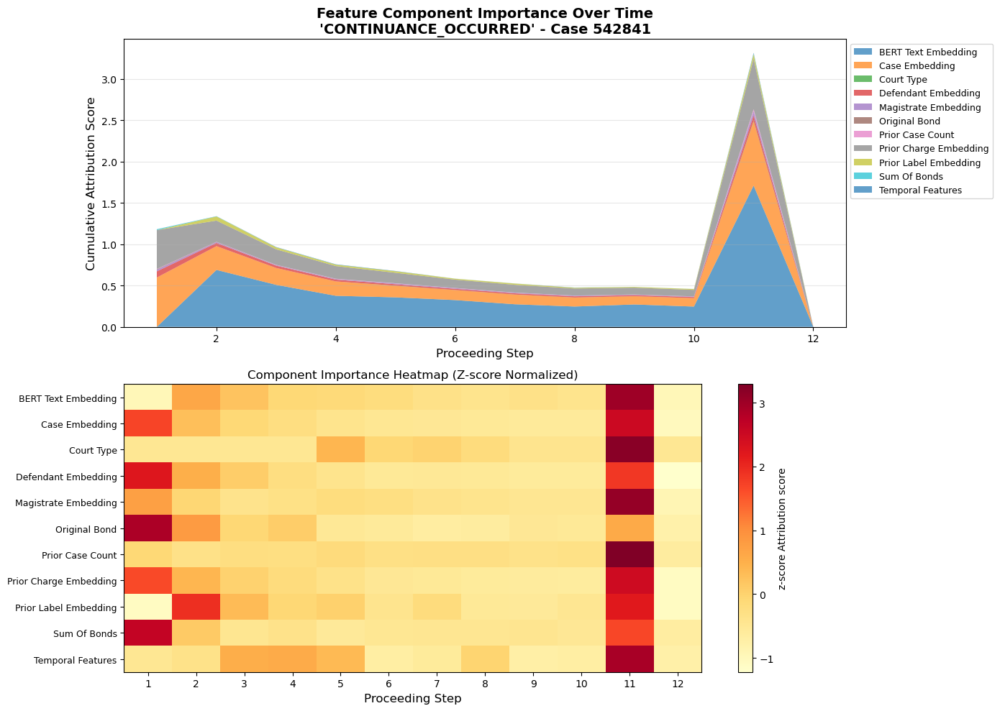


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 12 for class index 14 at proceeding index 10
   Attribution shape: torch.Size([1, 12, 1548])
   Convergence delta: 0.0069002509117126465
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.001200          0.416767         1.708848         0.429509  CONTINUANCE_OCCURRED
1           Case_Embedding           2.726263          0.227189         0.775559         0.218957  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           2.244348          0.187029         0.608853         0.171328  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.316008          0.026334         0.075209         0.021558  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.217979          0.018165         0.054230         0.016610  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.138398          0.011533         0.05

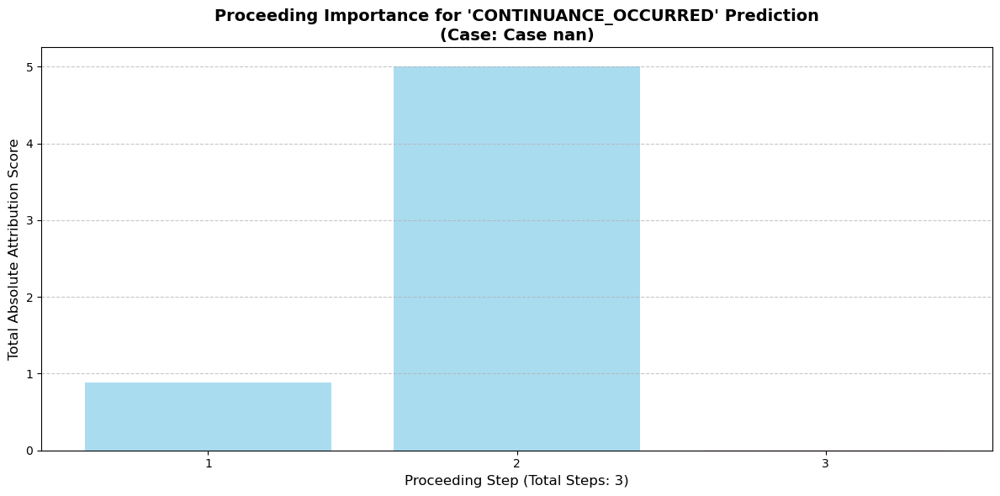

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_41.png


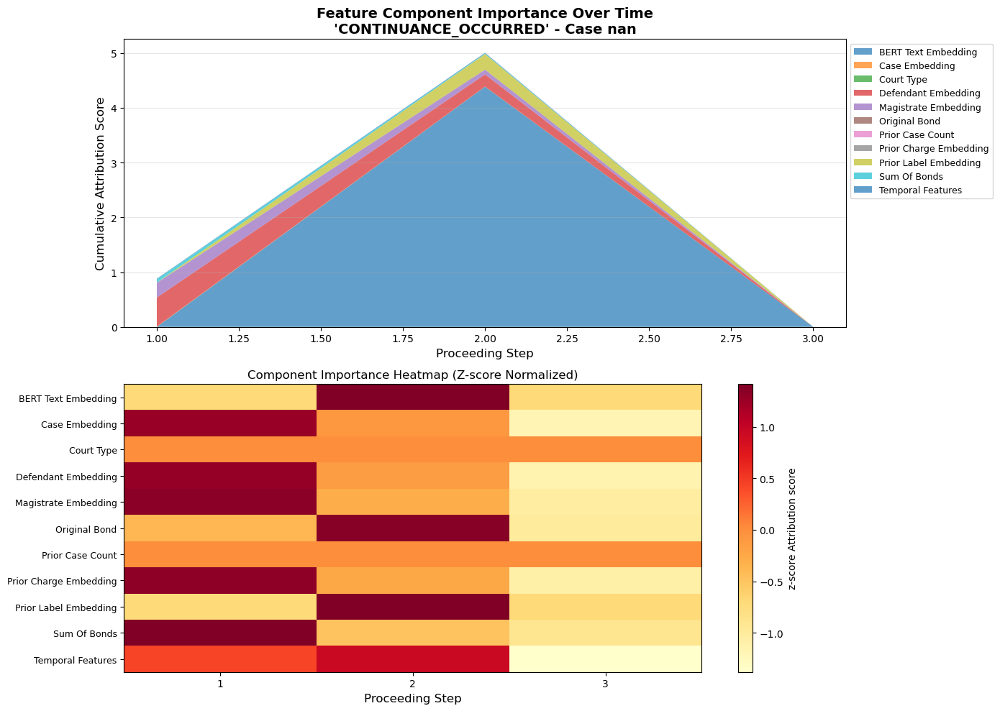


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 3 for class index 14 at proceeding index 1
   Attribution shape: torch.Size([1, 3, 1548])
   Convergence delta: -0.000955432653427124
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           4.390486          1.463495         4.390486         2.069695  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.749779          0.249926         0.529487         0.217176  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.346588          0.115529         0.262266         0.109320  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.283166          0.094389         0.282180         0.132789  CONTINUANCE_OCCURRED
8             Sum_Of_Bonds           0.072501          0.024167         0.061339         0.026676  CONTINUANCE_OCCURRED
10       Temporal_Features           0.021300          0.007100         0.01213

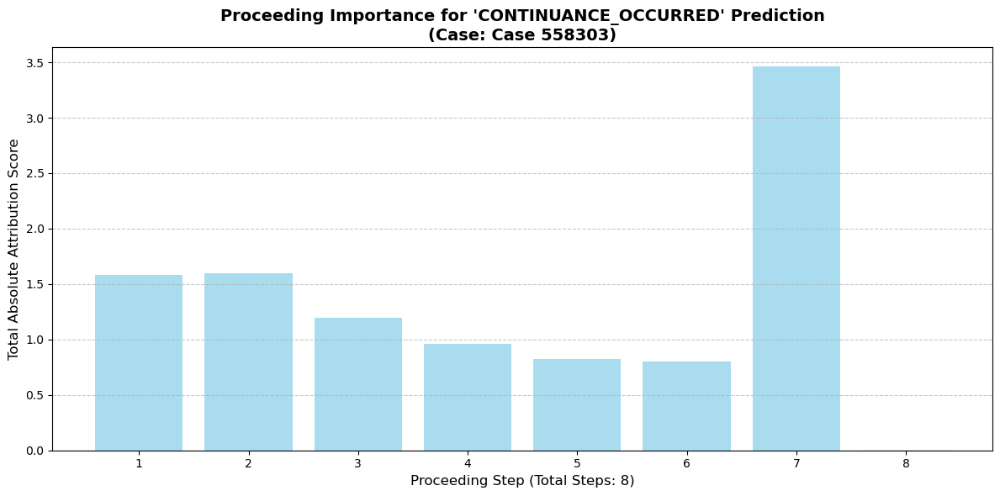

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_42.png


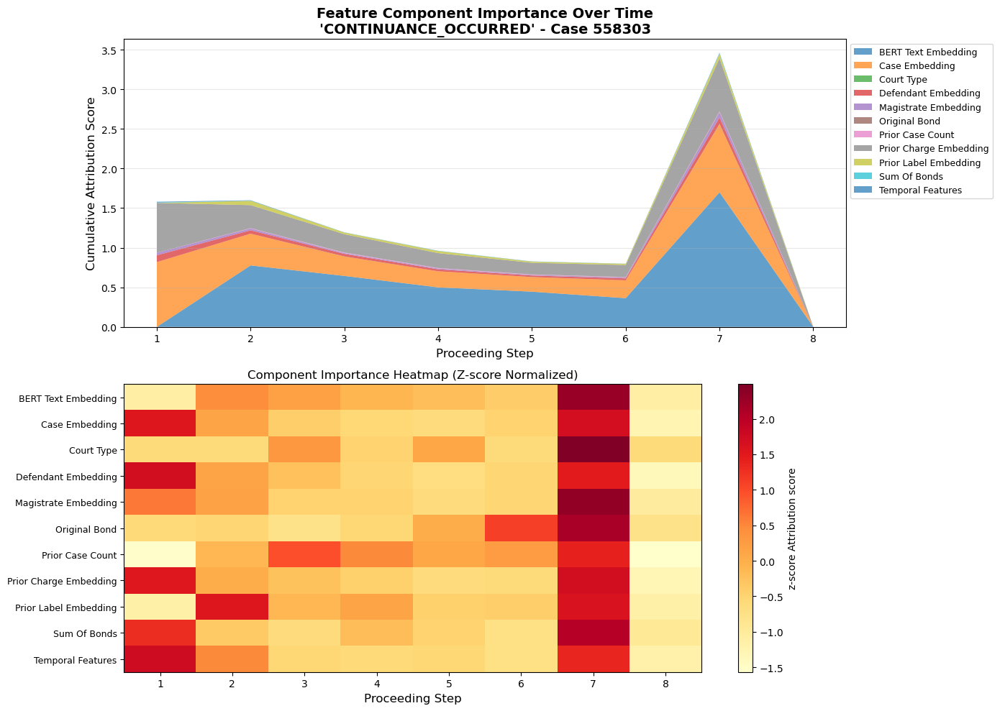


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 8 for class index 14 at proceeding index 6
   Attribution shape: torch.Size([1, 8, 1548])
   Convergence delta: -0.0062316060066223145
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           4.432894          0.554112         1.704136         0.505647  CONTINUANCE_OCCURRED
1           Case_Embedding           2.941871          0.367734         0.862962         0.291501  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           2.304179          0.288022         0.669900         0.222244  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.307791          0.038474         0.086991         0.028295  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.187004          0.023375         0.056112         0.020321  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.158461          0.019808         0.0646

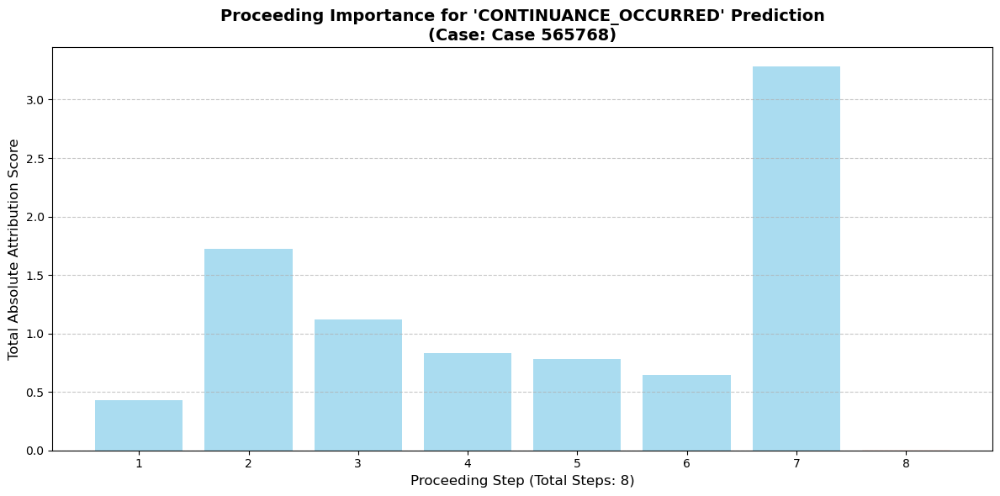

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_43.png


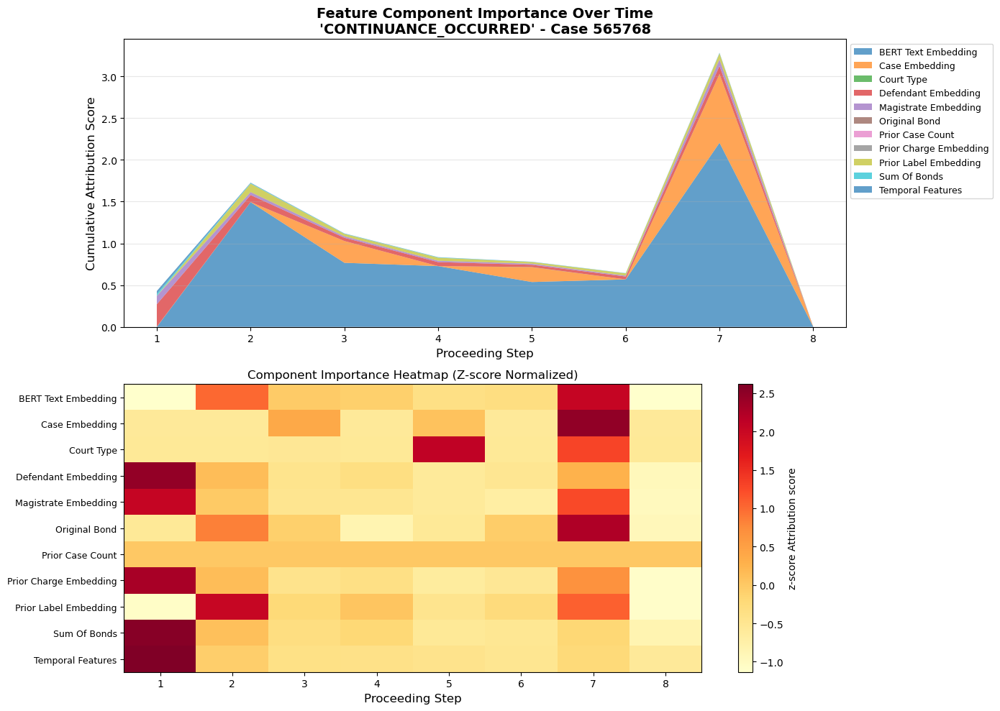


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 8 for class index 14 at proceeding index 6
   Attribution shape: torch.Size([1, 8, 1548])
   Convergence delta: 0.001944899559020996
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           6.299075          0.787384         2.206291         0.695014  CONTINUANCE_OCCURRED
1           Case_Embedding           1.265433          0.158179         0.824224         0.268815  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.597425          0.074678         0.268920         0.078825  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.279959          0.034995         0.099454         0.031711  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.254364          0.031796         0.098497         0.032668  CONTINUANCE_OCCURRED
10       Temporal_Features           0.051548          0.006444         0.035008

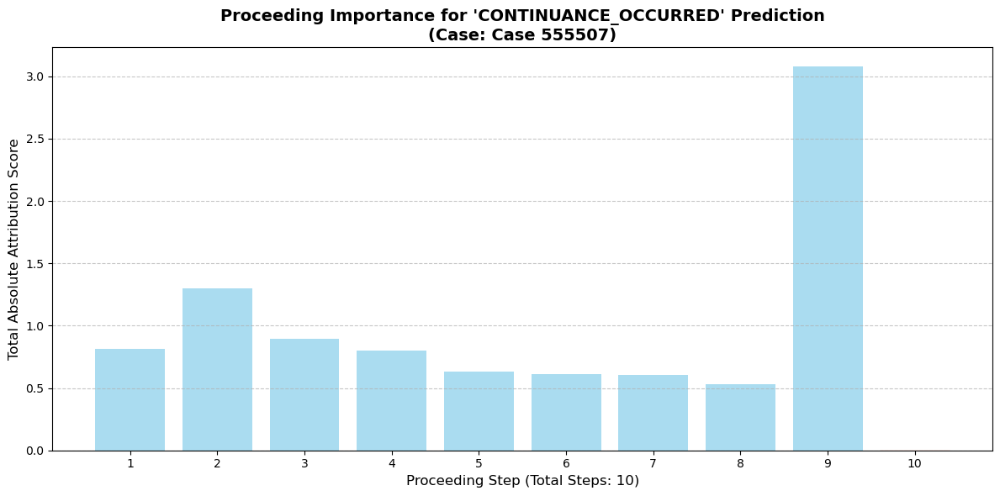

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_44.png


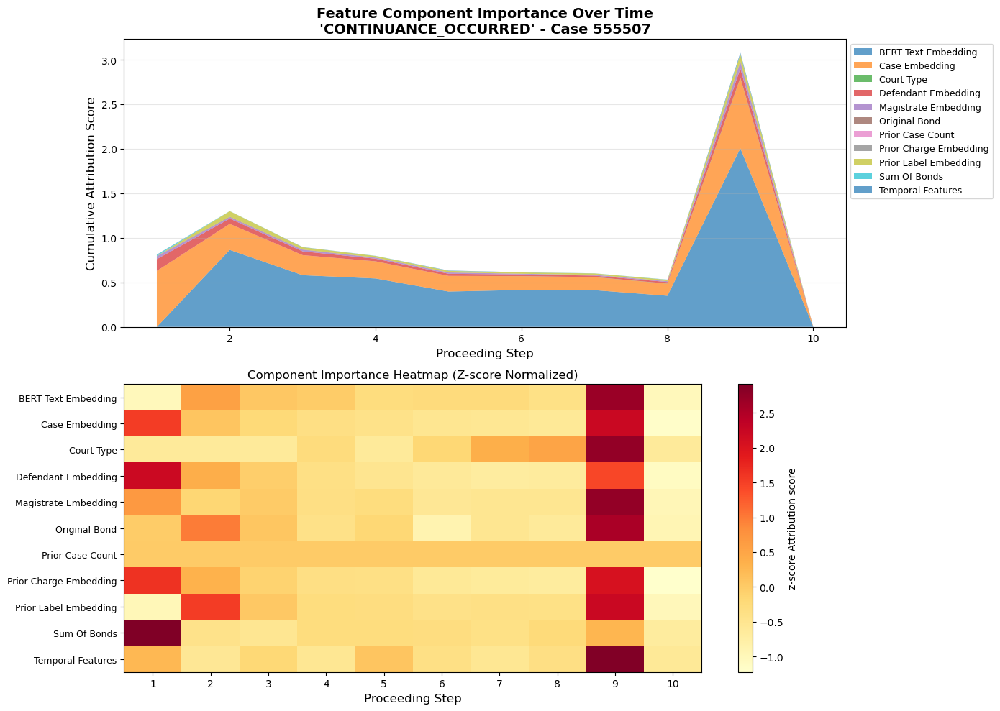


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 10 for class index 14 at proceeding index 8
   Attribution shape: torch.Size([1, 10, 1548])
   Convergence delta: -0.0010710954666137695
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.570359          0.557036         2.003508         0.540124  CONTINUANCE_OCCURRED
1           Case_Embedding           2.735356          0.273536         0.783809         0.230295  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.441087          0.044109         0.132031         0.040037  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.246529          0.024653         0.079174         0.024458  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.181679          0.018168         0.069408         0.018689  CONTINUANCE_OCCURRED
7            Original_Bond           0.026407          0.002641         0.00

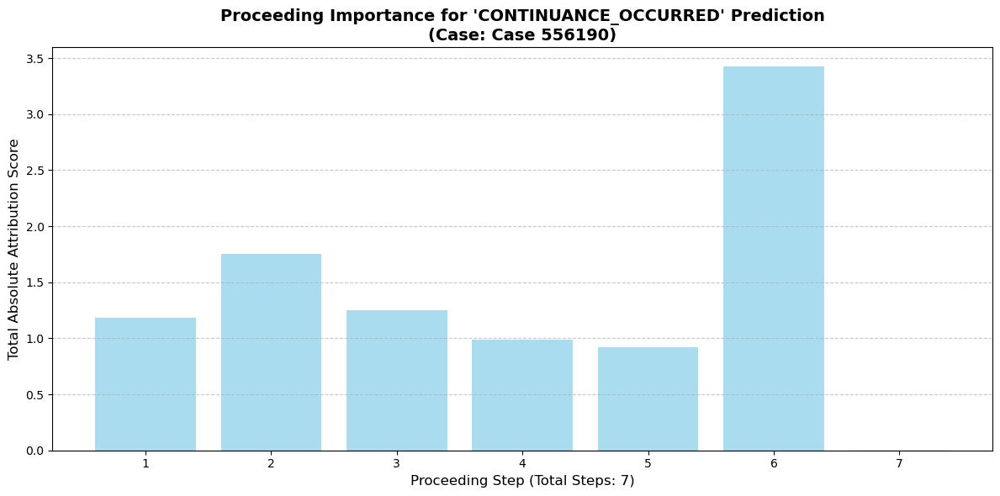

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_45.png


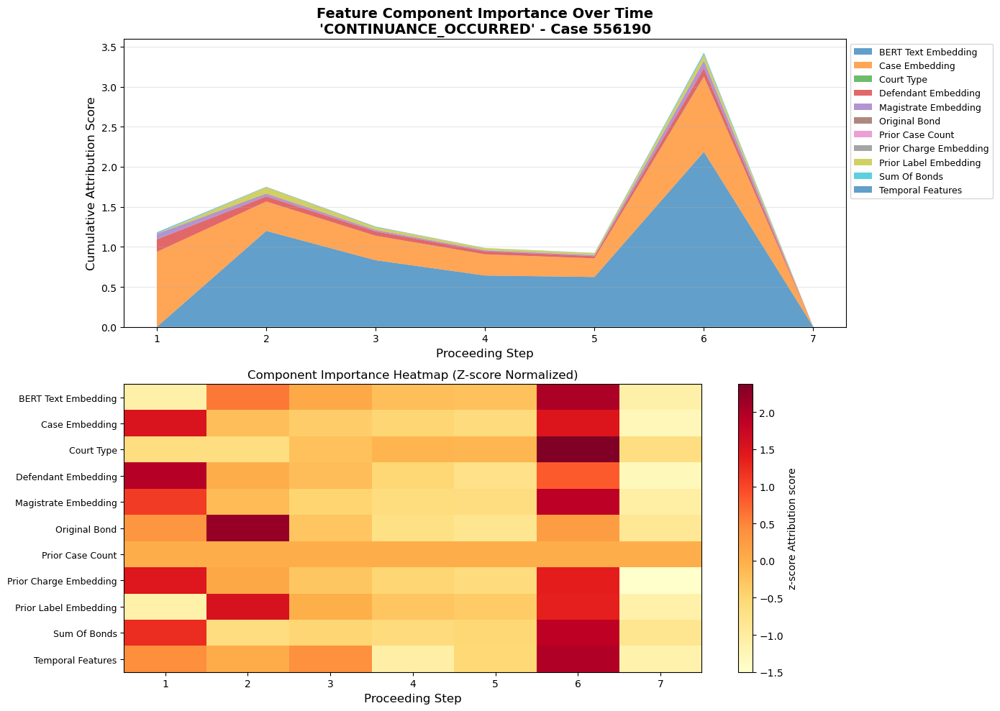


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 7 for class index 14 at proceeding index 5
   Attribution shape: torch.Size([1, 7, 1548])
   Convergence delta: -0.00203627347946167
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.486325          0.783761         2.188485         0.699104  CONTINUANCE_OCCURRED
1           Case_Embedding           3.035589          0.433656         0.935629         0.333127  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.441032          0.063005         0.156320         0.048098  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.233314          0.033331         0.079133         0.029411  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.232124          0.033161         0.091626         0.031070  CONTINUANCE_OCCURRED
8             Sum_Of_Bonds           0.031893          0.004556         0.014518

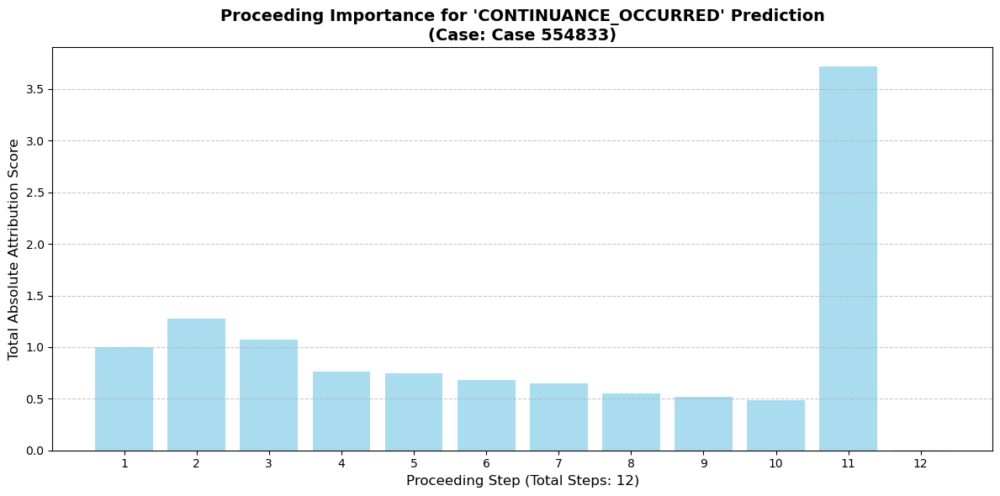

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_46.png


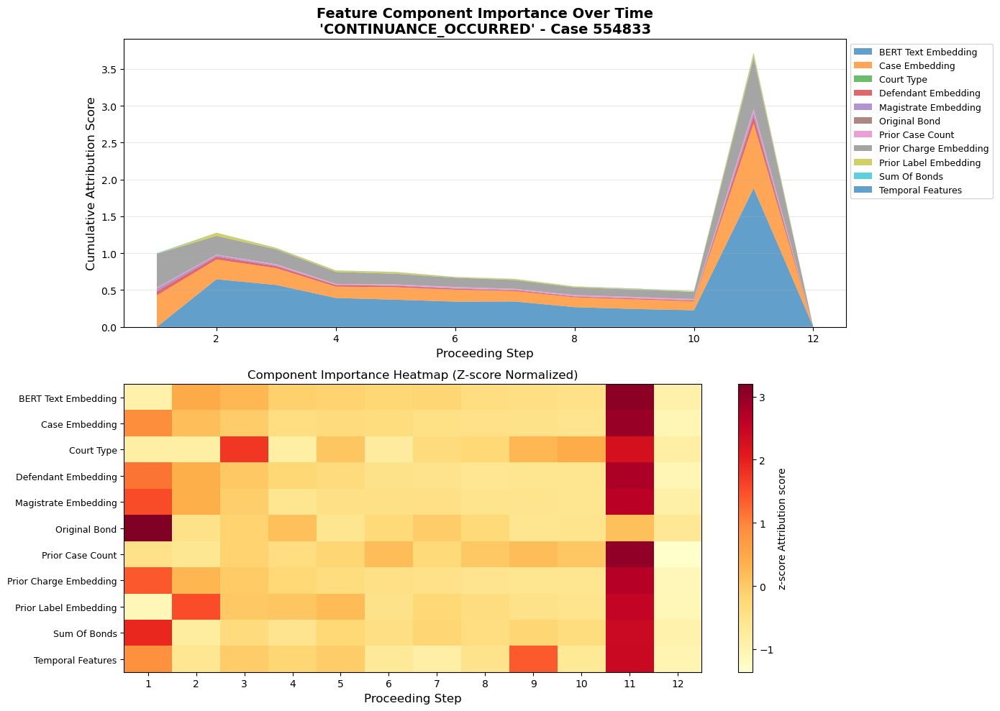


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 12 for class index 14 at proceeding index 10
   Attribution shape: torch.Size([1, 12, 1548])
   Convergence delta: -0.0046988725662231445
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           5.280821          0.440068         1.882246         0.471335  CONTINUANCE_OCCURRED
1           Case_Embedding           2.808311          0.234026         0.876884         0.217217  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           2.459405          0.204950         0.692413         0.182044  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.322970          0.026914         0.098931         0.025742  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.211959          0.017663         0.057747         0.015974  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.169786          0.014149         0.0

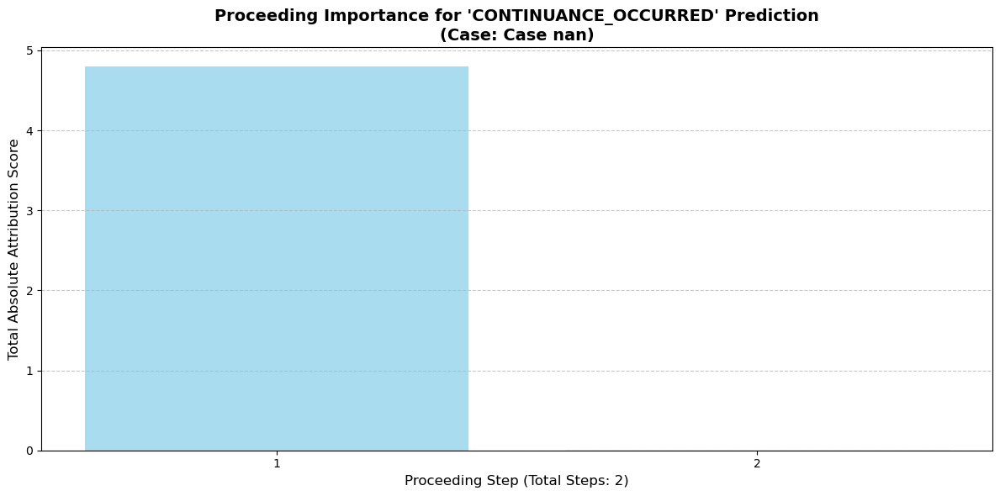

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_47.png


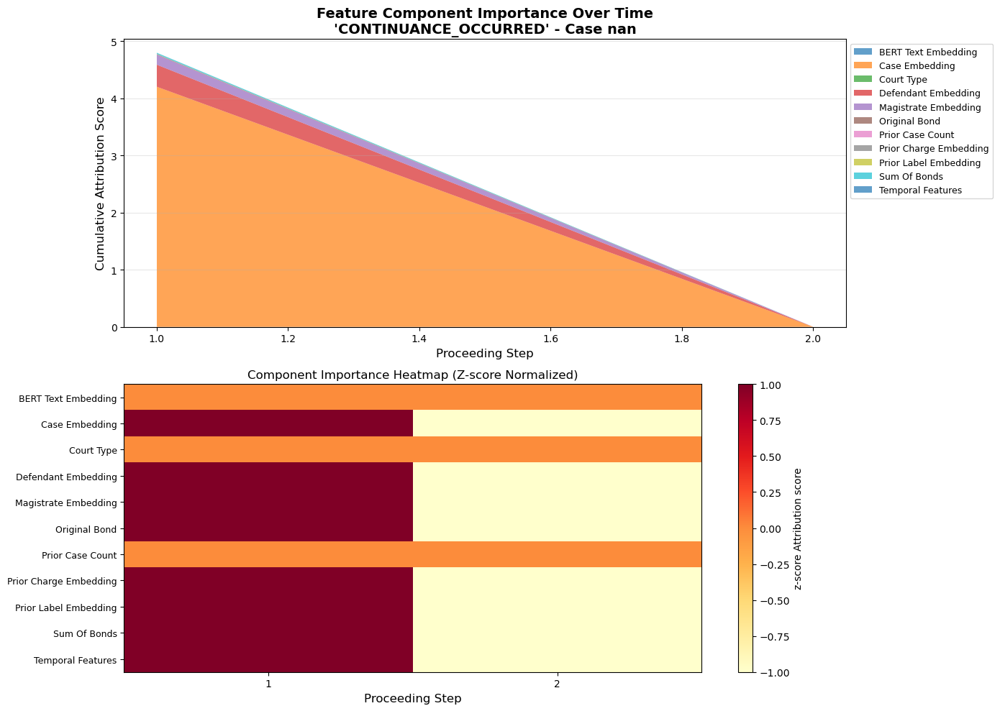


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 2 for class index 14 at proceeding index 0
   Attribution shape: torch.Size([1, 2, 1548])
   Convergence delta: -0.0031383633613586426
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
1           Case_Embedding           4.183496          2.091748         4.183496         2.091748  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.382566          0.191283         0.382566         0.191283  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.171586          0.085793         0.171586         0.085793  CONTINUANCE_OCCURRED
8             Sum_Of_Bonds           0.019677          0.009838         0.019677         0.009838  CONTINUANCE_OCCURRED
7            Original_Bond           0.009243          0.004622         0.009243         0.004622  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           0.005200          0.002600         0.0052

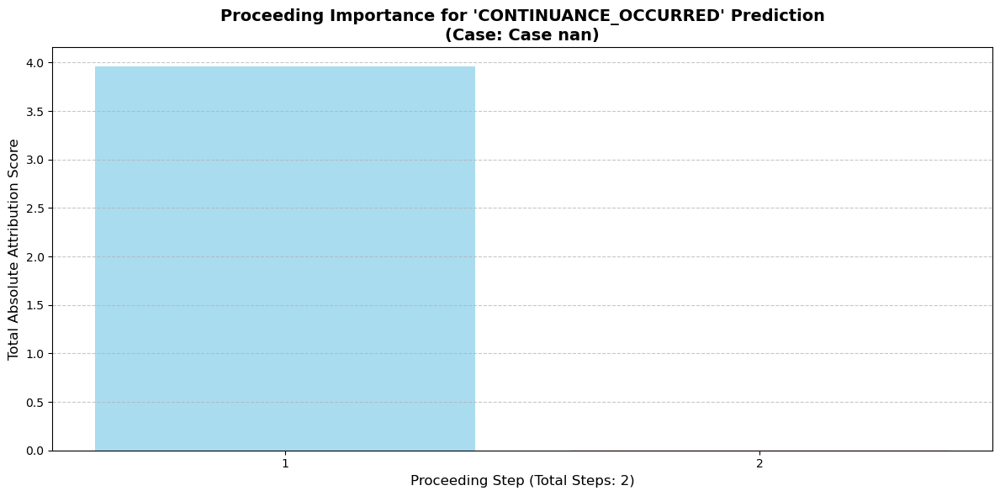

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_48.png


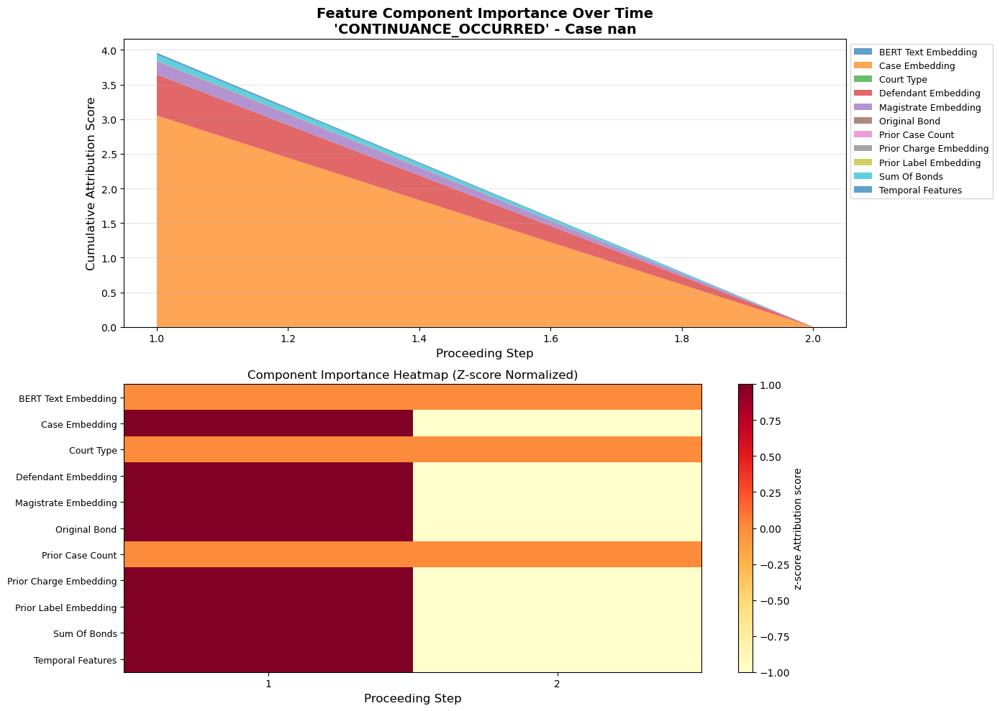


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 2 for class index 14 at proceeding index 0
   Attribution shape: torch.Size([1, 2, 1548])
   Convergence delta: 0.008250266313552856
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
1           Case_Embedding           3.039717          1.519858         3.039717         1.519858  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.588440          0.294220         0.588440         0.294220  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.192857          0.096429         0.192857         0.096429  CONTINUANCE_OCCURRED
8             Sum_Of_Bonds           0.081826          0.040913         0.081826         0.040913  CONTINUANCE_OCCURRED
10       Temporal_Features           0.028323          0.014161         0.028323         0.014161  CONTINUANCE_OCCURRED
7            Original_Bond           0.006049          0.003025         0.006049

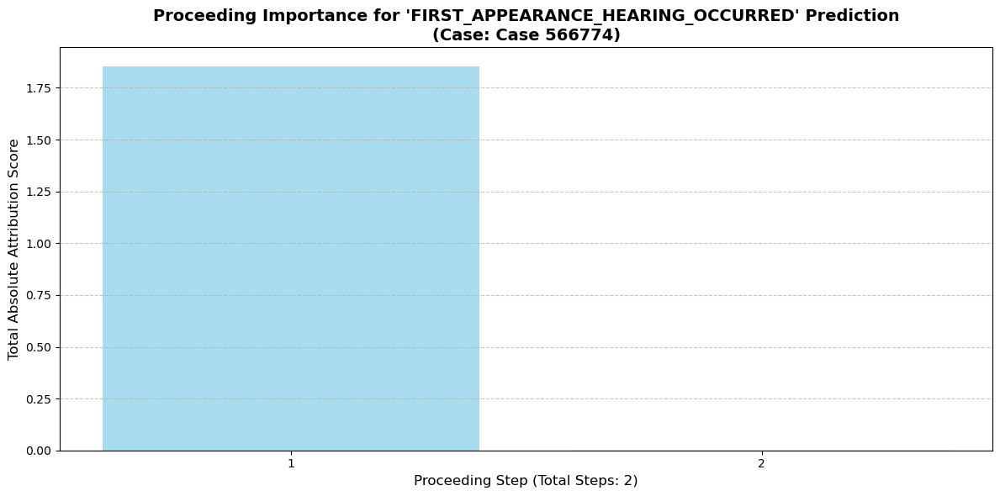

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_49.png


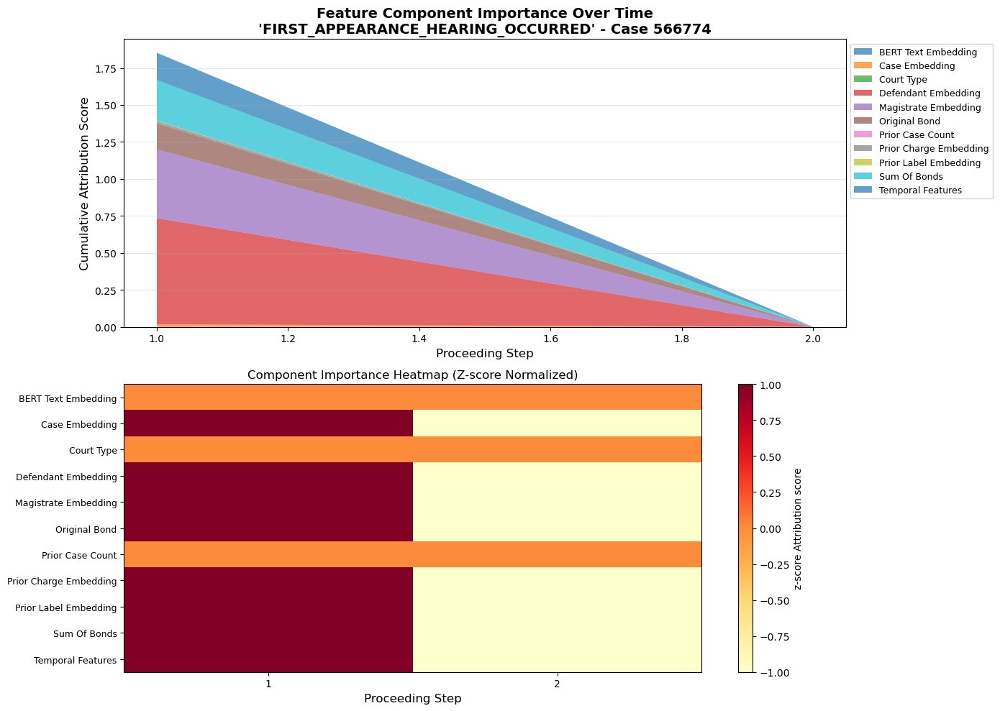


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 2 for class index 0 at proceeding index 0
   Attribution shape: torch.Size([1, 2, 1548])
   Convergence delta: -0.00035941600799560547
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution                       Target_Label
0      Defendant_Embedding           0.718159          0.359080         0.718159         0.359080  FIRST_APPEARANCE_HEARING_OCCURRED
3     Magistrate_Embedding           0.466552          0.233276         0.466552         0.233276  FIRST_APPEARANCE_HEARING_OCCURRED
8             Sum_Of_Bonds           0.274000          0.137000         0.274000         0.137000  FIRST_APPEARANCE_HEARING_OCCURRED
10       Temporal_Features           0.186024          0.093012         0.186024         0.093012  FIRST_APPEARANCE_HEARING_OCCURRED
7            Original_Bond           0.178947          0.089473         0.178947         0.089473  FIRST_APPEARANCE_HEARING_OCCURRED


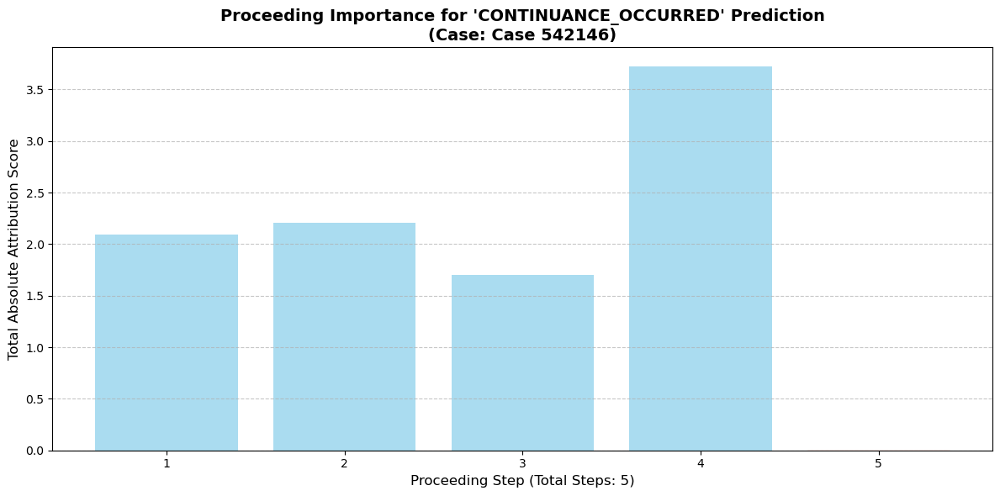

ðŸ“ˆ Visualizing component importance over time...
✅ Saved to /data/krosen5/cache/transformers/balanced_10/interpretability_results/interpretability_component_importance_sample_50.png


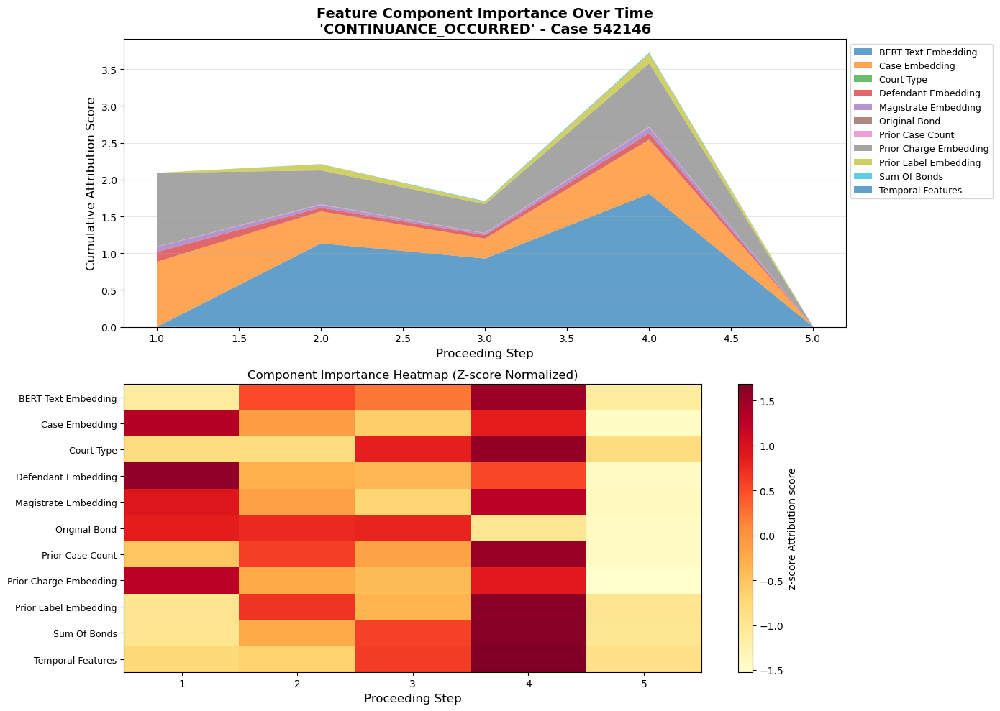


ðŸ“‹ Feature Importance Summary:
🔍 Attributing sequence of length 5 for class index 14 at proceeding index 3
   Attribution shape: torch.Size([1, 5, 1548])
   Convergence delta: 0.002248048782348633
         Feature_Component  Total_Attribution  Mean_Attribution  Max_Attribution  Std_Attribution          Target_Label
2      BERT_Text_Embedding           3.864833          0.772967         1.802556         0.694145  CONTINUANCE_OCCURRED
5   Prior_Charge_Embedding           2.712730          0.542546         1.002877         0.356782  CONTINUANCE_OCCURRED
1           Case_Embedding           2.323586          0.464717         0.883370         0.317503  CONTINUANCE_OCCURRED
0      Defendant_Embedding           0.314358          0.062872         0.132522         0.044283  CONTINUANCE_OCCURRED
4    Prior_Label_Embedding           0.244488          0.048898         0.129987         0.050587  CONTINUANCE_OCCURRED
3     Magistrate_Embedding           0.200210          0.040042         0.077118

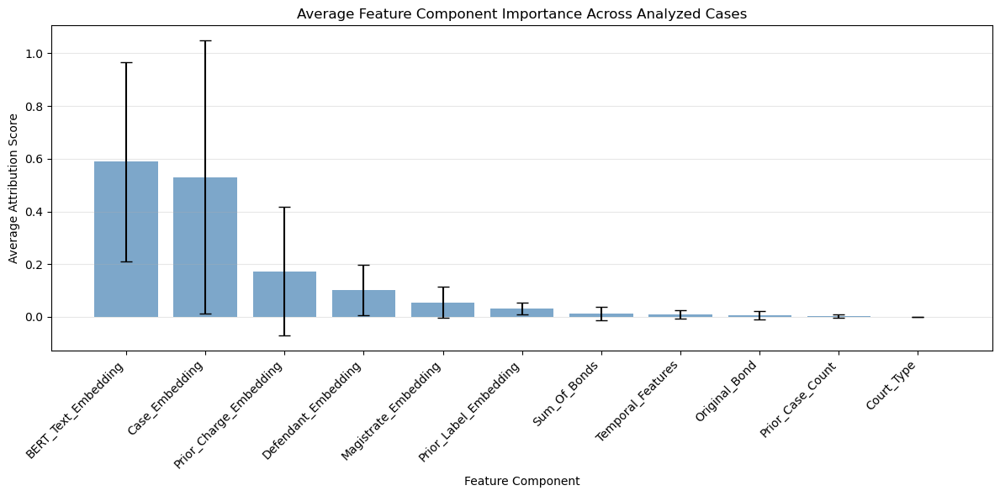


âœ… Aggregate analysis complete!

ANALYZING ALL 20 LABELS (not just first 5)

LABEL-SPECIFIC FEATURE ANALYSIS

ðŸ·ï¸ Analyzing feature importance for labels: ['FIRST_APPEARANCE_HEARING_OCCURRED', 'BOND_SET', 'BOND_NOT_SET', 'DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE', 'THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER', 'ANKLE_MONITORING_IMPOSED', 'DOMESTIC_STAY_AWAY_ORDER_IMPOSED', 'CHARGES_ACCEPTED', 'CHARGES_REFUSED', 'PROBABLE_CAUSE_FOUND', 'PROBABLE_CAUSE_NOT_FOUND', 'DEFENDANT_IN_CUSTODY_AND_NOT_IN_COURT', 'THE_STATE_WAS_NOT_PRESENT', 'PRE_TRIAL_CONFERENCE_HELD', 'CONTINUANCE_OCCURRED', 'PLED_GUILTY_TO_CHARGES', 'PLED_NOT_GUILTY_TO_CHARGES', 'TRIAL_VERDICT_REACHED', 'SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED', 'SENTENCE_THAT_DOES_NOT_INCLUDE_JAIL_TIME_WAS_IMPOSED']
[1/20] Analyzing label: FIRST_APPEARANCE_HEARING_OCCURRED (index: 0)
   Found in sequence 0, proceeding 0
🔍 Attributing sequence of length 13 for class index 0 at proceeding index 0
   Attribution shape: torch.Size([1

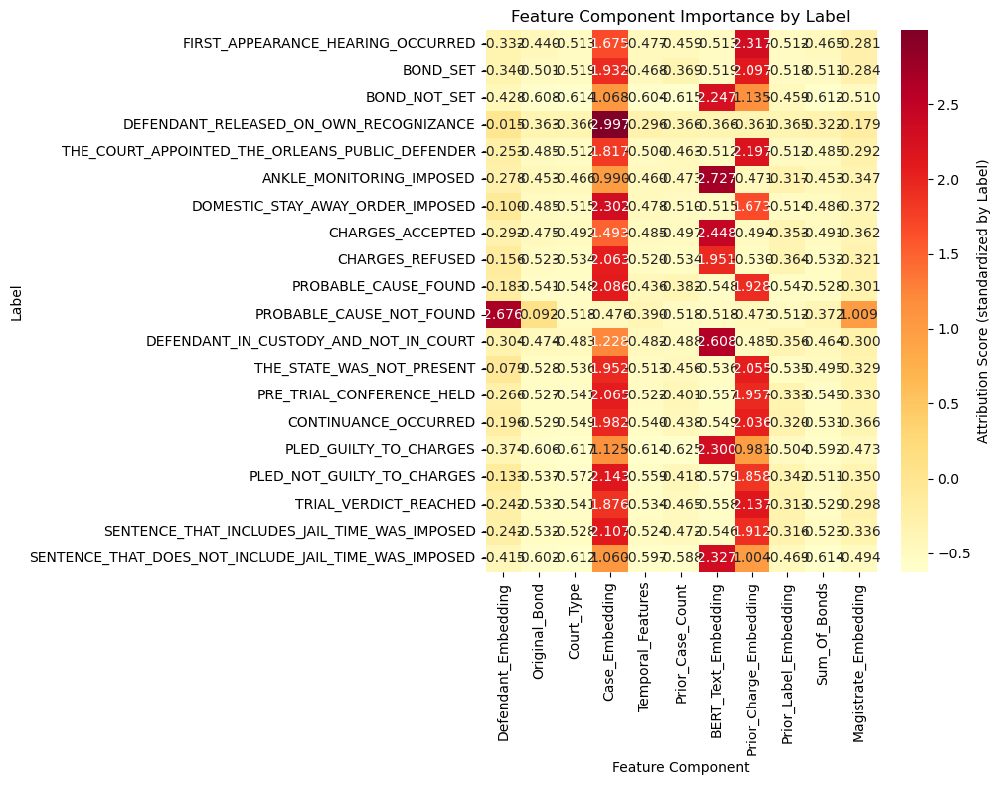


âœ… Label-specific analysis complete!


In [58]:
if sequences and label_sequences_raw:
    if parameters_dict['model_validation_strategy'] == 'train_val_split':
        # Create case IDs for validation sequences
        val_case_ids = []
        for seq in val_sequences:
            case_id = extract_case_info_from_sequence(seq, court_data)
            val_case_ids.append(case_id)
        
        interpretability_results = run_interpretability_analysis(
            trained_case_model,
            label_processor,
            device,
            val_sequences,
            val_labels_raw,
            val_case_ids,
            court_data,
            model_configuration,
            cache_manager=model_cache_manager,
            num_samples=parameters_dict['numbers_of_cases_to_analyze_for_interpretability']
        )
    elif parameters_dict['model_validation_strategy'] == 'k_fold_cross_validation':
        print(f"Running interpretability analysis on each fold")
        intepretability_results_per_fold = {}
        for fold_idx in range(cv_training_results['n_splits']):
            print(f"  Fold {fold_idx + 1}...")
            fold = cv_training_results['fold_results'][fold_idx]
            fold_val_data = fold['val_data']
            
            fold_val_sequences, fold_val_labels_raw = prepare_sequences_and_labels(
                fold_val_data
            )
            
            # Create case IDs
            val_case_ids = []
            for seq in fold_val_sequences:
                case_id = extract_case_info_from_sequence(seq, court_data)
                val_case_ids.append(case_id)
            
            interpretability_results = run_interpretability_analysis(
                cv_runner.load_fold_model(fold_idx),
                label_processor,
                device,
                fold_val_sequences,
                fold_val_labels_raw,
                val_case_ids,
                court_data,
                model_configuration,
                cache_manager=model_cache_manager,
                num_samples=parameters_dict['numbers_of_cases_to_analyze_for_interpretability']
            )
            intepretability_results_per_fold[fold_idx] = interpretability_results

Computing global attributions table for fold 1...
Computing attributions for up to 200 samples...


Attribution Batches:   0%|          | 0/50 [00:00<?, ?it/s]

🔍 Attributing sequence of length 11 for class index 13 at proceeding index 10
   Attribution shape: torch.Size([1, 11, 1548])
   Convergence delta: -0.0010016262531280518
🔍 Attributing sequence of length 11 for class index 15 at proceeding index 10
   Attribution shape: torch.Size([1, 11, 1548])
   Convergence delta: -0.0002449452877044678
🔍 Attributing sequence of length 11 for class index 18 at proceeding index 10


Attribution Batches:   2%|▏         | 1/50 [00:00<00:09,  5.39it/s]

   Attribution shape: torch.Size([1, 11, 1548])
   Convergence delta: 0.0010456517338752747
🔍 Attributing sequence of length 11 for class index 13 at proceeding index 10


...

Attribution Batches:  94%|█████████▍| 47/50 [00:05<00:00, 12.27it/s]

   Attribution shape: torch.Size([1, 7, 1548])
   Convergence delta: 0.0010277852416038513
🔍 Attributing sequence of length 7 for class index 18 at proceeding index 6
   Attribution shape: torch.Size([1, 7, 1548])
   Convergence delta: 0.0028016865253448486
🔍 Attributing sequence of length 2 for class index 8 at proceeding index 1
   Attribution shape: torch.Size([1, 2, 1548])
   Convergence delta: -0.00021156668663024902
🔍 Attributing sequence of length 20 for class index 8 at proceeding index 19
   Attribution shape: torch.Size([1, 20, 1548])
   Convergence delta: -0.00023789703845977783
🔍 Attributing sequence of length 6 for class index 8 at proceeding index 5
   Attribution shape: torch.Size([1, 6, 1548])
   Convergence delta: 0.00211237370967865
🔍 Attributing sequence of length 6 for class index 13 at proceeding index 5
   Attribution shape: torch.Size([1, 6, 1548])
   Convergence delta: -3.30507755279541e-05
🔍 Attributing sequence of length 6 for class index 15 at proceeding inde

Attribution Batches: 100%|██████████| 50/50 [00:05<00:00,  8.80it/s]

   Attribution shape: torch.Size([1, 15, 1548])
   Convergence delta: 0.00021255016326904297
🔍 Attributing sequence of length 15 for class index 17 at proceeding index 14
   Attribution shape: torch.Size([1, 15, 1548])
   Convergence delta: 0.002268269658088684
🔍 Attributing sequence of length 2 for class index 14 at proceeding index 1
   Attribution shape: torch.Size([1, 2, 1548])
   Convergence delta: -0.0020516812801361084
Attributions computed for 50 samples.

Table 1: Raw Attribution Magnitudes
                        PRE_TRIAL_CONFERENCE_HELD  PLED_GUILTY_TO_CHARGES  SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED  SENTENCE_THAT_DOES_NOT_INCLUDE_JAIL_TIME_WAS_IMPOSED  CHARGES_REFUSED  TRIAL_VERDICT_REACHED  CONTINUANCE_OCCURRED  Mean_Raw_Attribution
BERT_Text_Embedding                      4.896564                5.403271                                      4.889660                                              4.781468         4.369436               3.070532              4.442738  

✅ Saved raw heatmap to attribution_heatmap_raw_fold_1.png


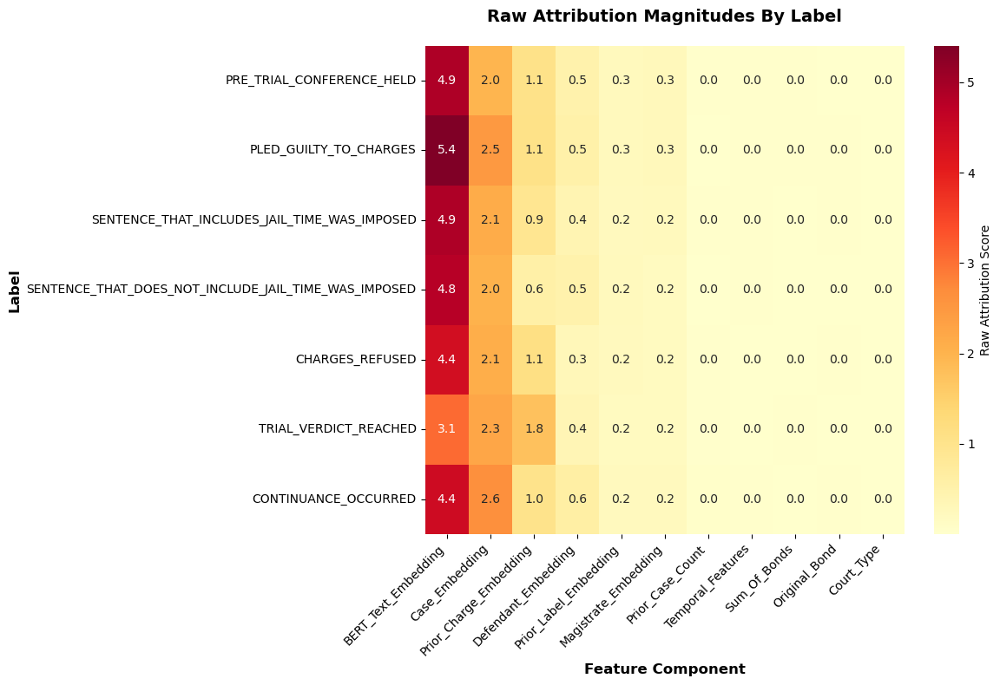


INSIGHTS: Raw Attribution Magnitudes

Top 3 Features Overall (Raw Attributions):
  1. BERT_Text_Embedding : 4.5505 (Average Across Labels)
  2. Case_Embedding : 2.2295 (Average Across Labels)
  3. Prior_Charge_Embedding : 1.0789 (Average Across Labels)

Per Label Leaders (Raw Attributions):
  Label 'PRE_TRIAL_CONFERENCE_HELD': Top Feature: BERT_Text_Embedding with Raw Attribution: 4.8966
  Label 'PLED_GUILTY_TO_CHARGES': Top Feature: BERT_Text_Embedding with Raw Attribution: 5.4033
  Label 'SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED': Top Feature: BERT_Text_Embedding with Raw Attribution: 4.8897
  Label 'SENTENCE_THAT_DOES_NOT_INCLUDE_JAIL_TIME_WAS_IMPOSED': Top Feature: BERT_Text_Embedding with Raw Attribution: 4.7815
  Label 'CHARGES_REFUSED': Top Feature: BERT_Text_Embedding with Raw Attribution: 4.3694
  Label 'TRIAL_VERDICT_REACHED': Top Feature: BERT_Text_Embedding with Raw Attribution: 3.0705
  Label 'CONTINUANCE_OCCURRED': Top Feature: BERT_Text_Embedding with Raw Attributio

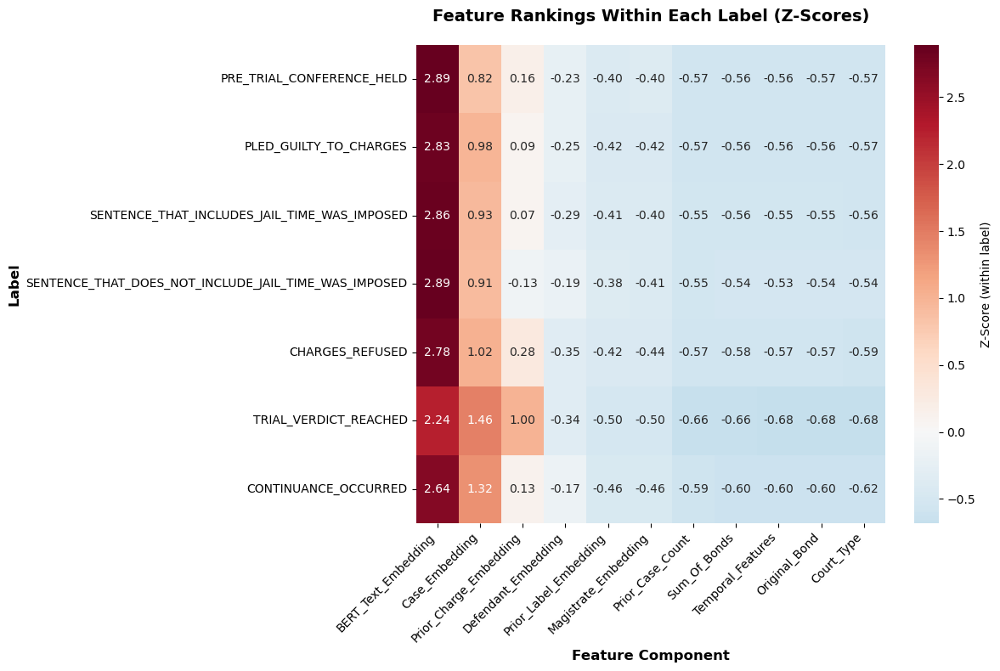


INSIGHTS: Within-Label Feature Rankings

Positive Z-Score would indicate above-average importance for that label
Negative Z-Score would indicate below-average importance for that label

  Label 'PRE_TRIAL_CONFERENCE_HELD':
    Top 3 Features (relative to other features for this label):
      1. BERT_Text_Embedding : Z-Score: 2.8858
      2. Case_Embedding : Z-Score: 0.8160
      3. Prior_Charge_Embedding : Z-Score: 0.1636
  Label 'PLED_GUILTY_TO_CHARGES':
    Top 3 Features (relative to other features for this label):
      1. BERT_Text_Embedding : Z-Score: 2.8327
      2. Case_Embedding : Z-Score: 0.9822
      3. Prior_Charge_Embedding : Z-Score: 0.0900
  Label 'SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED':
    Top 3 Features (relative to other features for this label):
      1. BERT_Text_Embedding : Z-Score: 2.8614
      2. Case_Embedding : Z-Score: 0.9294
      3. Prior_Charge_Embedding : Z-Score: 0.0742
  Label 'SENTENCE_THAT_DOES_NOT_INCLUDE_JAIL_TIME_WAS_IMPOSED':
    Top 3 Fea

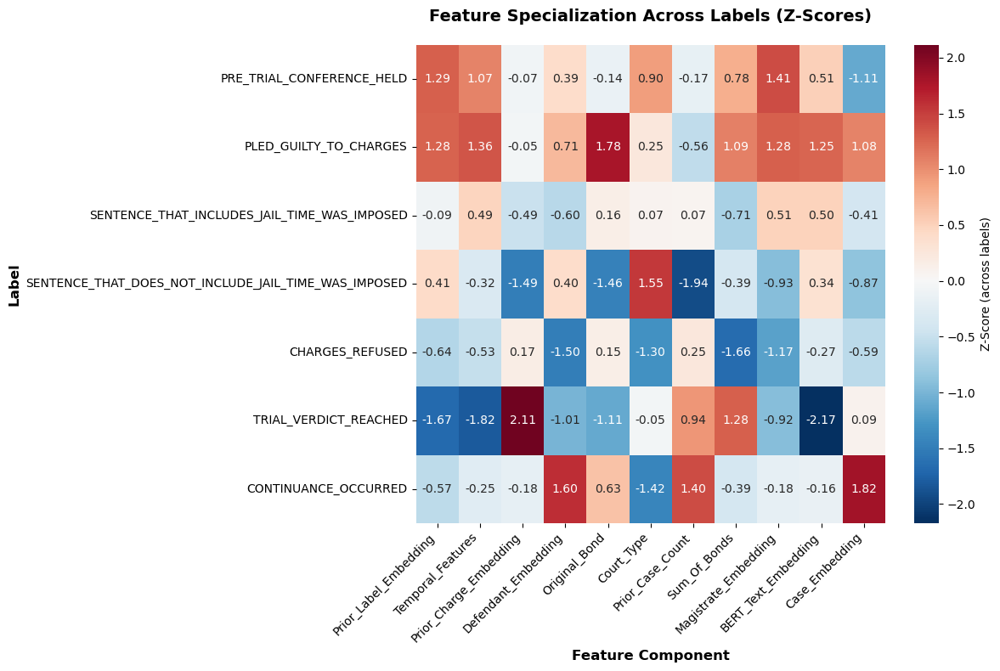


INSIGHTS: Across-Label Feature Specialization

A positive Z-score indicates the label relies more heavily
on this feature than the average reliance across all labels.
A negative Z-score indicates the label relies less
on this feature than the average reliance across all labels.

  Feature 'Prior_Label_Embedding':
    Most Specialized For Label 'PRE_TRIAL_CONFERENCE_HELD' with Z-Score: 1.2868
    Least Specialized For Label 'TRIAL_VERDICT_REACHED' with Z-Score: -1.6734
  Feature 'Temporal_Features':
    Most Specialized For Label 'PLED_GUILTY_TO_CHARGES' with Z-Score: 1.3595
    Least Specialized For Label 'TRIAL_VERDICT_REACHED' with Z-Score: -1.8203
  Feature 'Prior_Charge_Embedding':
    Most Specialized For Label 'TRIAL_VERDICT_REACHED' with Z-Score: 2.1150
    Least Specialized For Label 'SENTENCE_THAT_DOES_NOT_INCLUDE_JAIL_TIME_WAS_IMPOSED' with Z-Score: -1.4894
  Feature 'Defendant_Embedding':
    Most Specialized For Label 'CONTINUANCE_OCCURRED' with Z-Score: 1.6020
    Least S

Attribution Batches:   0%|          | 0/50 [00:00<?, ?it/s]

🔍 Attributing sequence of length 13 for class index 18 at proceeding index 12


Attribution Batches:   4%|▍         | 2/50 [00:00<00:03, 12.67it/s]

   Attribution shape: torch.Size([1, 13, 1548])
   Convergence delta: 0.0003077387809753418
🔍 Attributing sequence of length 5 for class index 15 at proceeding index 4
   Attribution shape: torch.Size([1, 5, 1548])
   Convergence delta: 0.00157967209815979
🔍 Attributing sequence of length 5 for class index 19 at proceeding index 4
   Attribution shape: torch.Size([1, 5, 1548])
   Convergence delta: 0.0010454356670379639
🔍 Attributing sequence of length 2 for class index 8 at proceeding index 1
   Attribution shape: torch.Size([1, 2, 1548])
   Convergence delta: 0.0022445619106292725
🔍 Attributing sequence of length 15 for class index 5 at proceeding index 14
   Attribution shape: torch.Size([1, 15, 1548])
   Convergence delta: 0.000558316707611084
🔍 Attributing sequence of length 15 for class index 13 at proceeding index 14
   Attribution shape: torch.Size([1, 15, 1548])
   Convergence delta: 0.0004603266716003418
🔍 Attributing sequence of length 15 for class index 15 at proceeding ind

...

   Attribution shape: torch.Size([1, 7, 1548])
   Convergence delta: 0.00019288063049316406
🔍 Attributing sequence of length 12 for class index 14 at proceeding index 11
   Attribution shape: torch.Size([1, 12, 1548])
   Convergence delta: 0.0013892650604248047
🔍 Attributing sequence of length 12 for class index 17 at proceeding index 11
   Attribution shape: torch.Size([1, 12, 1548])
   Convergence delta: -0.00040847063064575195
🔍 Attributing sequence of length 12 for class index 18 at proceeding index 11


Attribution Batches:  98%|█████████▊| 49/50 [00:04<00:00, 10.59it/s]

   Attribution shape: torch.Size([1, 12, 1548])
   Convergence delta: 0.0016141831874847412
🔍 Attributing sequence of length 2 for class index 14 at proceeding index 1
   Attribution shape: torch.Size([1, 2, 1548])
   Convergence delta: -0.0023283958435058594
🔍 Attributing sequence of length 2 for class index 3 at proceeding index 1
   Attribution shape: torch.Size([1, 2, 1548])
   Convergence delta: 0.0007383078336715698
🔍 Attributing sequence of length 2 for class index 8 at proceeding index 1
   Attribution shape: torch.Size([1, 2, 1548])
   Convergence delta: 0.00012837350368499756
🔍 Attributing sequence of length 2 for class index 15 at proceeding index 1
   Attribution shape: torch.Size([1, 2, 1548])
   Convergence delta: -0.0013407766819000244
🔍 Attributing sequence of length 2 for class index 18 at proceeding index 1
   Attribution shape: torch.Size([1, 2, 1548])
   Convergence delta: -0.0006436705589294434
🔍 Attributing sequence of length 5 for class index 15 at proceeding ind

Attribution Batches: 100%|██████████| 50/50 [00:04<00:00, 10.29it/s]


   Attribution shape: torch.Size([1, 5, 1548])
   Convergence delta: -0.00035646557807922363
🔍 Attributing sequence of length 5 for class index 19 at proceeding index 4
   Attribution shape: torch.Size([1, 5, 1548])
   Convergence delta: -0.00019490718841552734
Attributions computed for 50 samples.

Table 1: Raw Attribution Magnitudes
                        SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED  PLED_GUILTY_TO_CHARGES  SENTENCE_THAT_DOES_NOT_INCLUDE_JAIL_TIME_WAS_IMPOSED  CHARGES_REFUSED  ANKLE_MONITORING_IMPOSED  PRE_TRIAL_CONFERENCE_HELD  TRIAL_VERDICT_REACHED  CONTINUANCE_OCCURRED  THE_COURT_APPOINTED_THE_ORLEANS_PUBLIC_DEFENDER  DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE  Mean_Raw_Attribution
BERT_Text_Embedding                                         3.826239                4.416604                                              4.230302         3.795285                  5.023470                   4.629408               4.459228              4.641438                             

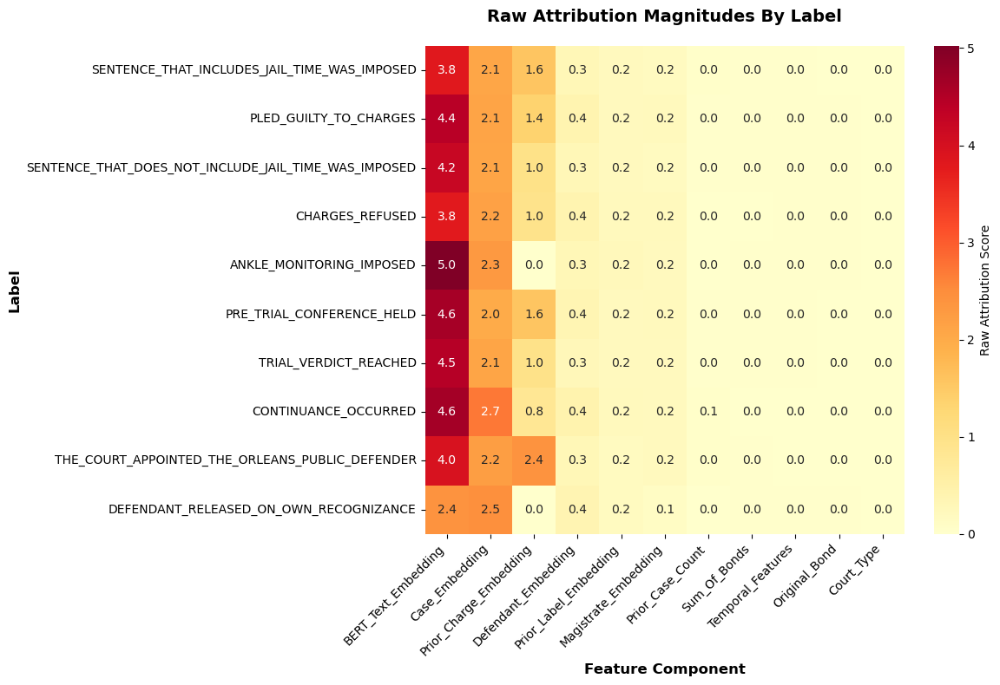


INSIGHTS: Raw Attribution Magnitudes

Top 3 Features Overall (Raw Attributions):
  1. BERT_Text_Embedding : 4.1391 (Average Across Labels)
  2. Case_Embedding : 2.2306 (Average Across Labels)
  3. Prior_Charge_Embedding : 1.0671 (Average Across Labels)

Per Label Leaders (Raw Attributions):
  Label 'SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED': Top Feature: BERT_Text_Embedding with Raw Attribution: 3.8262
  Label 'PLED_GUILTY_TO_CHARGES': Top Feature: BERT_Text_Embedding with Raw Attribution: 4.4166
  Label 'SENTENCE_THAT_DOES_NOT_INCLUDE_JAIL_TIME_WAS_IMPOSED': Top Feature: BERT_Text_Embedding with Raw Attribution: 4.2303
  Label 'CHARGES_REFUSED': Top Feature: BERT_Text_Embedding with Raw Attribution: 3.7953
  Label 'ANKLE_MONITORING_IMPOSED': Top Feature: BERT_Text_Embedding with Raw Attribution: 5.0235
  Label 'PRE_TRIAL_CONFERENCE_HELD': Top Feature: BERT_Text_Embedding with Raw Attribution: 4.6294
  Label 'TRIAL_VERDICT_REACHED': Top Feature: BERT_Text_Embedding with Raw Attrib

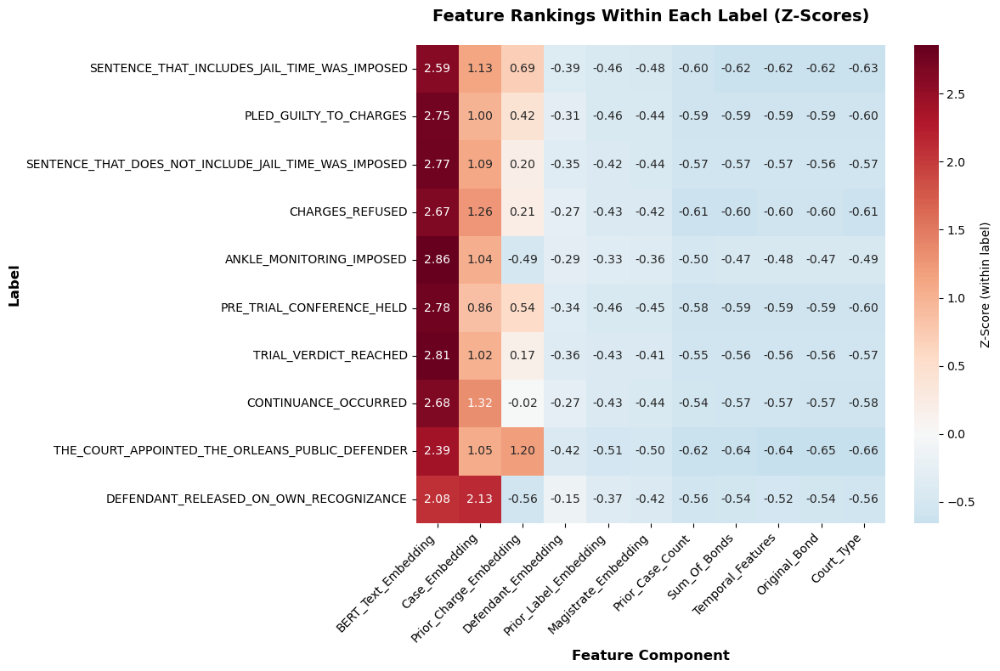


INSIGHTS: Within-Label Feature Rankings

Positive Z-Score would indicate above-average importance for that label
Negative Z-Score would indicate below-average importance for that label

  Label 'SENTENCE_THAT_INCLUDES_JAIL_TIME_WAS_IMPOSED':
    Top 3 Features (relative to other features for this label):
      1. BERT_Text_Embedding : Z-Score: 2.5942
      2. Case_Embedding : Z-Score: 1.1335
      3. Prior_Charge_Embedding : Z-Score: 0.6929
  Label 'PLED_GUILTY_TO_CHARGES':
    Top 3 Features (relative to other features for this label):
      1. BERT_Text_Embedding : Z-Score: 2.7481
      2. Case_Embedding : Z-Score: 1.0035
      3. Prior_Charge_Embedding : Z-Score: 0.4249
  Label 'SENTENCE_THAT_DOES_NOT_INCLUDE_JAIL_TIME_WAS_IMPOSED':
    Top 3 Features (relative to other features for this label):
      1. BERT_Text_Embedding : Z-Score: 2.7678
      2. Case_Embedding : Z-Score: 1.0887
      3. Prior_Charge_Embedding : Z-Score: 0.2010
  Label 'CHARGES_REFUSED':
    Top 3 Features (rel

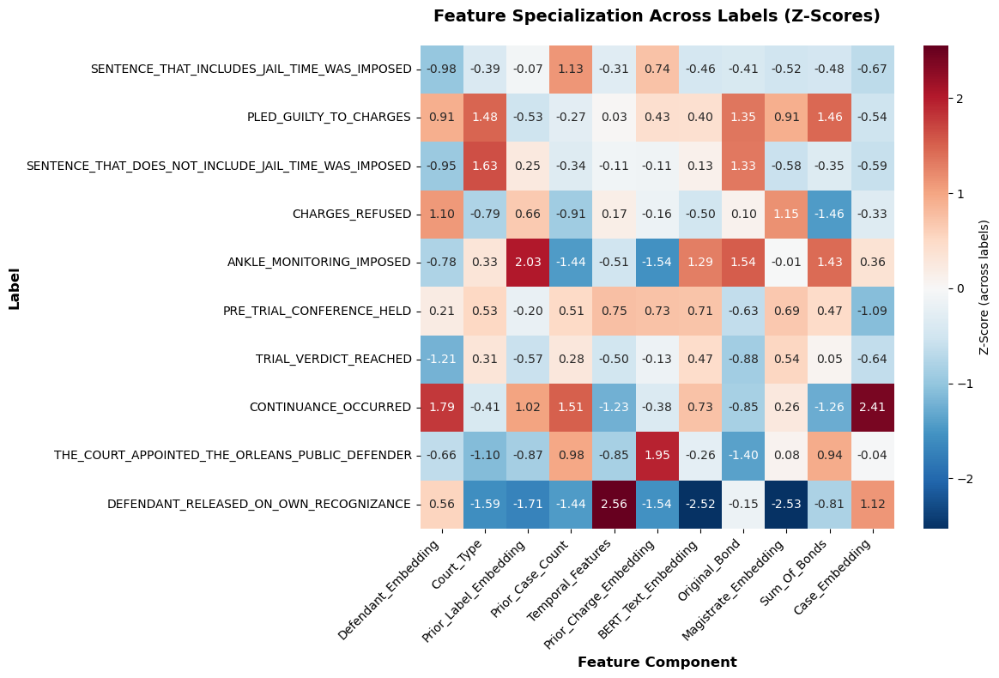


INSIGHTS: Across-Label Feature Specialization

A positive Z-score indicates the label relies more heavily
on this feature than the average reliance across all labels.
A negative Z-score indicates the label relies less
on this feature than the average reliance across all labels.

  Feature 'Defendant_Embedding':
    Most Specialized For Label 'CONTINUANCE_OCCURRED' with Z-Score: 1.7904
    Least Specialized For Label 'TRIAL_VERDICT_REACHED' with Z-Score: -1.2136
  Feature 'Court_Type':
    Most Specialized For Label 'SENTENCE_THAT_DOES_NOT_INCLUDE_JAIL_TIME_WAS_IMPOSED' with Z-Score: 1.6311
    Least Specialized For Label 'DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE' with Z-Score: -1.5881
  Feature 'Prior_Label_Embedding':
    Most Specialized For Label 'ANKLE_MONITORING_IMPOSED' with Z-Score: 2.0294
    Least Specialized For Label 'DEFENDANT_RELEASED_ON_OWN_RECOGNIZANCE' with Z-Score: -1.7126
  Feature 'Prior_Case_Count':
    Most Specialized For Label 'CONTINUANCE_OCCURRED' with Z-Score: 

In [59]:
if sequences and label_sequences_raw:
    if parameters_dict['model_validation_strategy'] == 'train_val_split':
        # get the interpreter from prior results (run_interpretability_analysis)
        interpreter = interpretability_results['interpreter']  # fixed key
        val_pairs_binary = [
            (seq, label_processor.transform_sequence(labels))
            for (seq, labels) in val_sequences_and_labels
            if len(seq) >= 1
        ]

        attributions_tables = compute_global_attributions_table(
            interpreter,
            val_pairs_binary,
            max_samples=200,
            show_top_n_features=20,
            ig_n_steps=200,
            optional_tag = None,
            verbose=True
        )

        attributions_tables['full'].to_excel(
            model_cache_manager.get_cache_dir('interpretability_results') / 'attributions_complete_all_views.xlsx',
            index=True
        )
        attributions_tables['raw'].to_excel(
            model_cache_manager.get_cache_dir('interpretability_results') / 'table1_raw_attributions.xlsx',
            index=True
        )
        
        attributions_tables['within_label'].to_excel(
            model_cache_manager.get_cache_dir('interpretability_results') / 'table2_within_label_zscores.xlsx',
            index=True
        )

        attributions_tables['across_label'].to_excel(
            model_cache_manager.get_cache_dir('interpretability_results') / 'table3_across_label_zscores.xlsx',
            index=True
        )

    elif parameters_dict['model_validation_strategy'] == 'k_fold_cross_validation':
        attributions_tables_per_fold = {}
        for fold_idx in range(cv_training_results['n_splits']):
            print(f"Computing global attributions table for fold {fold_idx + 1}...")

            fold_interpretability_results = intepretability_results_per_fold[fold_idx]
            interpreter = fold_interpretability_results['interpreter']
            # get val data for this fold
            fold = cv_training_results['fold_results'][fold_idx]
            val_pairs_binary = [
                (seq, label_processor.transform_sequence(labels))
                for (seq, labels) in fold['val_data']
                if len(seq) >= 1
            ]

            attributions_tables = compute_global_attributions_table(
                interpreter,
                val_pairs_binary,
                max_samples=200,
                show_top_n_features=20,
                ig_n_steps=200,
                optional_tag = f'fold_{fold_idx + 1}',
                verbose=True
            )

            attributions_tables_per_fold[fold_idx] = attributions_tables

            # save each table per fold
            attributions_tables['full'].to_excel(
                model_cache_manager.get_cache_dir('interpretability_results') / f'attributions_complete_all_views_fold_{fold_idx + 1}.xlsx',
                index=True
            )
            attributions_tables['raw'].to_excel(
                model_cache_manager.get_cache_dir('interpretability_results') / f'table1_raw_attributions_fold_{fold_idx + 1}.xlsx',
                index=True
            )
            attributions_tables['within_label'].to_excel(
                model_cache_manager.get_cache_dir('interpretability_results') / f'table2_within_label_zscores_fold_{fold_idx + 1}.xlsx',
                index=True
            )
            attributions_tables['across_label'].to_excel(
                model_cache_manager.get_cache_dir('interpretability_results') / f'table3_across_label_zscores_fold_{fold_idx + 1}.xlsx',
                index=True
            )

In [60]:
if sequences and label_sequences_raw:
    if parameters_dict['model_validation_strategy'] == 'train_val_split':
        confident_misclass_results = run_confident_misclassification(
            trained_case_model,
            label_processor,
            computation_device,
            val_sequences_and_labels,
            cache_manager=model_cache_manager,
            threshold=parameters_dict['minimum_confidence_for_wrong_prediction_inclusion'],
            top_k=parameters_dict['number_of_highest_probability_predictions_per_step'],
            top_n=parameters_dict['maximum_number_of_confident_mistakes_to_return'],
            max_sequences=parameters_dict['maximum_validation_sequences_to_process_for_analysis_of_incorrect']
        )
        
        mistakes_report = confident_misclass_results['mistakes_report']
        interpreted_mistakes = confident_misclass_results['interpreted_mistakes']
        case_patterns = confident_misclass_results['case_patterns']
    
    elif parameters_dict['model_validation_strategy'] == 'k_fold_cross_validation':
        print(f"Running confident misclassification analysis on each fold")
        confident_misclass_results_per_fold = {}
        for fold_idx in range(cv_training_results['n_splits']):
            print(f"  Fold {fold_idx + 1}...")
            fold = cv_training_results['fold_results'][fold_idx]
            fold_val_data = fold['val_data']
            
            fold_confident_misclass_results = run_confident_misclassification(
                cv_runner.load_fold_model(fold_idx),
                label_processor,
                computation_device,
                fold_val_data,
                cache_manager=model_cache_manager,
                threshold=parameters_dict['minimum_confidence_for_wrong_prediction_inclusion'],
                top_k=parameters_dict['number_of_highest_probability_predictions_per_step'],
                top_n=parameters_dict['maximum_number_of_confident_mistakes_to_return'],
                max_sequences=parameters_dict['maximum_validation_sequences_to_process_for_analysis_of_incorrect']
            )
            confident_misclass_results_per_fold[fold_idx] = fold_confident_misclass_results

Running confident misclassification analysis on each fold
  Fold 1...
Analyzing date range in data...
MAG data - Date range: 2008-11-28 00:00:00 to 2025-12-04 00:00:00, Count: 86075
CDC data - Date range: 2018-03-07 00:00:00 to 2025-12-30 00:00:00, Count: 83304
Overall date range in data: 2008 - 2025
Date range updated: 2008 to 2025
Date range in data: 2008 to 2025
Using MIN_YEAR=2008, NUM_YEARS=18
Updated temporal dimensions: 216 features (12 months × 18 years)
Creating charge vocabulary from charges DataFrame with 2139 unique charges
Found 5 unique magistrate sections in mag data.
Creating magistrate vocabulary of size 5
Checking BERT embeddings cache...
BERT embeddings cache found.
CaseTransformerModel(
  (text_emb): StreamingCachedBertEmbedding(
    (projector): Identity()
  )
  (def_emb): DefendantRoleEmbedding(
    (race_emb): Embedding(6, 8)
    (gender_emb): Embedding(3, 8)
    (age_linear): Linear(in_features=1, out_features=8, bias=True)
    (fuse): Sequential(
      (0): Lin

100%|██████████| 50/50 [00:00<00:00, 92.52it/s]


No confident wrong answers found in per-label analysis.
No confident misclassifications found with the current settings.
âœ… Confident misclassification analysis complete
  Fold 2...
Analyzing date range in data...
MAG data - Date range: 2008-11-28 00:00:00 to 2025-12-04 00:00:00, Count: 86075
CDC data - Date range: 2018-03-07 00:00:00 to 2025-12-30 00:00:00, Count: 83304
Overall date range in data: 2008 - 2025
Date range updated: 2008 to 2025
Date range in data: 2008 to 2025
Using MIN_YEAR=2008, NUM_YEARS=18
Updated temporal dimensions: 216 features (12 months × 18 years)
Creating charge vocabulary from charges DataFrame with 2139 unique charges
Found 5 unique magistrate sections in mag data.
Creating magistrate vocabulary of size 5
Checking BERT embeddings cache...
BERT embeddings cache found.
CaseTransformerModel(
  (text_emb): StreamingCachedBertEmbedding(
    (projector): Identity()
  )
  (def_emb): DefendantRoleEmbedding(
    (race_emb): Embedding(6, 8)
    (gender_emb): Embeddin

100%|██████████| 50/50 [00:00<00:00, 111.08it/s]

No confident wrong answers found in per-label analysis.
No confident misclassifications found with the current settings.
âœ… Confident misclassification analysis complete


In [61]:
if sequences and label_sequences_raw:
    if parameters_dict['model_validation_strategy'] == 'train_val_split':
        label_mistakes = analyze_confident_misclass_for_label(
            confident_misclass_results, 
            target_label="CHARGES_REFUSED"
        )
    
    elif parameters_dict['model_validation_strategy'] == 'k_fold_cross_validation':
        # Analyze for each fold
        label_mistakes_per_fold = {}
        for fold_idx in range(cv_training_results['n_splits']):
            print(f"  Analyzing CHARGES_REFUSED mistakes for Fold {fold_idx + 1}...")
            label_mistakes_per_fold[fold_idx] = analyze_confident_misclass_for_label(
                confident_misclass_results_per_fold[fold_idx], 
                target_label="CHARGES_REFUSED"
            )

  Analyzing CHARGES_REFUSED mistakes for Fold 1...
OUTLIER ANALYSIS (per-label): 'CHARGES_REFUSED'
No mistakes data available for analysis.
  Analyzing CHARGES_REFUSED mistakes for Fold 2...
OUTLIER ANALYSIS (per-label): 'CHARGES_REFUSED'
No mistakes data available for analysis.


In [62]:
if sequences and label_sequences_raw:
    if parameters_dict['model_validation_strategy'] == 'train_val_split':
        analyze_sample_predictions(
            trained_case_model,
            val_sequences_and_labels,
            label_processor,
            validation_metrics,
            court_data
        )
    elif parameters_dict['model_validation_strategy'] == 'k_fold_cross_validation':
        best_fold = cv_training_results['fold_results'][cv_training_results['best_fold_idx']]
        analyze_sample_predictions(
            cv_runner.load_fold_model(cv_training_results['best_fold_idx']),
            best_fold['val_data'],
            label_processor,
            best_fold['metrics'], 
            court_data
        )
    

Analyzing date range in data...
MAG data - Date range: 2008-11-28 00:00:00 to 2025-12-04 00:00:00, Count: 86075
CDC data - Date range: 2018-03-07 00:00:00 to 2025-12-30 00:00:00, Count: 83304
Overall date range in data: 2008 - 2025
Date range updated: 2008 to 2025
Date range in data: 2008 to 2025
Using MIN_YEAR=2008, NUM_YEARS=18
Updated temporal dimensions: 216 features (12 months × 18 years)
Creating charge vocabulary from charges DataFrame with 2139 unique charges
Found 5 unique magistrate sections in mag data.
Creating magistrate vocabulary of size 5
Checking BERT embeddings cache...
BERT embeddings cache found.
CaseTransformerModel(
  (text_emb): StreamingCachedBertEmbedding(
    (projector): Identity()
  )
  (def_emb): DefendantRoleEmbedding(
    (race_emb): Embedding(6, 8)
    (gender_emb): Embedding(3, 8)
    (age_linear): Linear(in_features=1, out_features=8, bias=True)
    (fuse): Sequential(
      (0): Linear(in_features=24, out_features=32, bias=True)
      (1): LayerNorm((

In [63]:
if not sequences or not label_sequences_raw:
    print("❌ No sequences available for training with MultiLabelBinarizer.")

In [64]:
#put the dictionaries into a single dictionary of dictionaries
model_results = {
    "cv_training_results": cv_training_results if 'cv_training_results' in locals() else None,
    'validation_metrics_per_fold': validation_metrics_per_fold if 'validation_metrics_per_fold' in locals() else None,
    'case_level_dict': case_level_dict if 'case_level_dict' in locals() else None,
    'ablation_results_per_fold': df_dict_per_fold if 'df_dict_per_fold' in locals() else None,
    'interpretability_results_per_fold': intepretability_results_per_fold if 'intepretability_results_per_fold' in locals() else None,
    'confident_misclass_results_per_fold': confident_misclass_results_per_fold if 'confident_misclass_results_per_fold' in locals() else None
}


In [65]:
# write it to a file so we can get the results of it

with open(model_cache_manager.get_cache_dir('models') / 'model_results.pkl', 'wb') as file:
    pickle.dump(model_results, file)

In [66]:
# Determine which model to export
if parameters_dict['model_validation_strategy'] == 'train_val_split':
    model_to_export = trained_case_model
    model_name = "final_model_mlb"
    
elif parameters_dict['model_validation_strategy'] == 'k_fold_cross_validation':
    best_fold_idx = cv_training_results['best_fold_idx']
    model_to_export = cv_runner.load_fold_model(best_fold_idx)
    model_name = f"final_model_mlb_best_fold_{best_fold_idx + 1}"

# Export everything
exported_files = export_model_complete(
    model=model_to_export,
    label_processor=label_processor,
    model_name=model_name,
    cache_manager=model_cache_manager
)

Analyzing date range in data...
MAG data - Date range: 2008-11-28 00:00:00 to 2025-12-04 00:00:00, Count: 86075
CDC data - Date range: 2018-03-07 00:00:00 to 2025-12-30 00:00:00, Count: 83304
Overall date range in data: 2008 - 2025
Date range updated: 2008 to 2025
Date range in data: 2008 to 2025
Using MIN_YEAR=2008, NUM_YEARS=18
Updated temporal dimensions: 216 features (12 months × 18 years)
Creating charge vocabulary from charges DataFrame with 2139 unique charges
Found 5 unique magistrate sections in mag data.
Creating magistrate vocabulary of size 5
Checking BERT embeddings cache...
BERT embeddings cache found.
CaseTransformerModel(
  (text_emb): StreamingCachedBertEmbedding(
    (projector): Identity()
  )
  (def_emb): DefendantRoleEmbedding(
    (race_emb): Embedding(6, 8)
    (gender_emb): Embedding(3, 8)
    (age_linear): Linear(in_features=1, out_features=8, bias=True)
    (fuse): Sequential(
      (0): Linear(in_features=24, out_features=32, bias=True)
      (1): LayerNorm((

In [67]:
table1_generalized = table_generator.generate_table_1_generalized(
    baseline_1_type_of_model='Baseline Model',
    baseline_2_type_of_model='Random Baseline'
)

    
# Generate Table 2: Per-Label Detailed
table2_per_label = table_generator.generate_table_2_per_label(
    label_names=label_processor.label_names,
    baseline_1_type_of_model='Baseline Model',
    baseline_2_type_of_model='Random Baseline'
)
output_path = table_generator.save_to_excel(
    table1_df=table1_generalized,
    table2_df=table2_per_label,
    filename="model_comparison_tables.xlsx"
)

✅ Comprehensive comparison tables saved to: /data/krosen5/cache/transformers/balanced_10/saved_models/model_comparison_tables.xlsx
